In [1]:
# Importing Necessary Libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

%matplotlib inline

import time
from sklearn.ensemble import IsolationForest
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from pandas.plotting import autocorrelation_plot
from statsmodels.tsa.seasonal import seasonal_decompose


import warnings
warnings.filterwarnings("ignore")


In [2]:
# Loading the Dataset from Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Creating DataFrame from the Dataset
o_data = pd.read_csv('/content/drive/MyDrive/DSA Project/HomeC14.csv')

In [4]:
# Creating a copy of the dataset
data = o_data.copy()

In [5]:
data.tail()

,time,use [kW],gen [kW],House overall [kW],Dishwasher [kW],Furnace 1 [kW],Furnace 2 [kW],Home office [kW],Fridge [kW],Wine cellar [kW],...,visibility,summary,apparentTemperature,pressure,windSpeed,cloudCover,windBearing,precipIntensity,dewPoint,precipProbability
503906,1452128306,1.599333,0.003233,1.599333,0.000050,0.104017,0.625033,0.041750,0.005233,0.008433,...,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51
503907,1452128307,1.924267,0.003217,1.924267,0.000033,0.422383,0.637733,0.042033,0.004983,0.008467,...,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51
503908,1452128308,1.978200,0.003217,1.978200,0.000050,0.495667,0.620367,0.042100,0.005333,0.008233,...,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51
503909,1452128309,1.990950,0.003233,1.990950,0.000050,0.494700,0.634133,0.042100,0.004917,0.008133,...,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51
503910,\,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Total information about the dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503911 entries, 0 to 503910
Data columns (total 32 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   time                 503911 non-null  object 
 1   use [kW]             494522 non-null  float64
 2   gen [kW]             494563 non-null  float64
 3   House overall [kW]   503910 non-null  float64
 4   Dishwasher [kW]      503910 non-null  float64
 5   Furnace 1 [kW]       503910 non-null  float64
 6   Furnace 2 [kW]       503910 non-null  float64
 7   Home office [kW]     503910 non-null  float64
 8   Fridge [kW]          503910 non-null  float64
 9   Wine cellar [kW]     503910 non-null  float64
 10  Garage door [kW]     503910 non-null  float64
 11  Kitchen 12 [kW]      503910 non-null  float64
 12  Kitchen 14 [kW]      503910 non-null  float64
 13  Kitchen 38 [kW]      503910 non-null  float64
 14  Barn [kW]            503910 non-null  float64
 15  Well [kW]        

In [7]:
# Statistical summmary of the dataset
data.describe().T

,count,mean,std,min,25%,50%,75%,max
use [kW],494522.0,0.859238,1.058680,0.000000,0.367283,0.562375,0.971817,14.714567
gen [kW],494563.0,0.075983,0.128222,0.000000,0.003367,0.004300,0.083283,0.613883
House overall [kW],503910.0,0.858962,1.058207,0.000000,0.367667,0.562333,0.970250,14.714567
Dishwasher [kW],503910.0,0.031368,0.190951,0.000000,0.000000,0.000017,0.000233,1.401767
Furnace 1 [kW],503910.0,0.099210,0.169059,0.000017,0.020233,0.020617,0.068733,1.934083
Furnace 2 [kW],503910.0,0.136779,0.178631,0.000067,0.064400,0.066633,0.080633,0.794933
Home office [kW],503910.0,0.081287,0.104466,0.000083,0.040383,0.042217,0.068283,0.971750
Fridge [kW],503910.0,0.063556,0.076199,0.000067,0.005083,0.005433,0.125417,0.851267
Wine cellar [kW],503910.0,0.042137,0.057967,0.000017,0.007133,0.008083,0.053192,1.273933
Garage door [kW],503910.0,0.014139,0.014292,0.000017,0.012733,0.012933,0.013100,1.088983


**As per recorded temperatures of different regions, the following countries seem to have mean temperatures in the similar range as our data- Japan,France ,Newzealand,Turkey,Hungary,Beligium,Croatia Bulgaria ,Serbia etc**

In [8]:
# Setting pandas display.max_columns option to display all the columns
pd.set_option('display.max_columns', None)

In [9]:
# Features available in the dataset
data.columns

Index(['time', 'use [kW]', 'gen [kW]', 'House overall [kW]', 'Dishwasher [kW]',
       'Furnace 1 [kW]', 'Furnace 2 [kW]', 'Home office [kW]', 'Fridge [kW]',
       'Wine cellar [kW]', 'Garage door [kW]', 'Kitchen 12 [kW]',
       'Kitchen 14 [kW]', 'Kitchen 38 [kW]', 'Barn [kW]', 'Well [kW]',
       'Microwave [kW]', 'Living room [kW]', 'Solar [kW]', 'temperature',
       'icon', 'humidity', 'visibility', 'summary', 'apparentTemperature',
       'pressure', 'windSpeed', 'cloudCover', 'windBearing', 'precipIntensity',
       'dewPoint', 'precipProbability'],
      dtype='object')

In [10]:
# Removing unit(kW) from the column name
data.columns = [col.replace(' [kW]', '') for col in data.columns]

In [11]:
# Shape of the dataset
data.shape

(503911, 32)

There are multiple columns for "Furnance" and "Kitchen" respectively. So aggregating them into a new single column by summing them up.
And also dropping them after aggregation.

In [12]:
# Aggregating the features
data['Furnace'] = data[['Furnace 1', 'Furnace 2']].sum(axis=1)
data['Kitchen'] = data[['Kitchen 12', 'Kitchen 14', 'Kitchen 38']].sum(axis=1)

In [13]:
# Dropping the multiple columns after aggregating 
data.drop(['Furnace 1', 'Furnace 2', 'Kitchen 12', 'Kitchen 14', 'Kitchen 38'], axis=1, inplace=True)

In [14]:
data['icon'].nunique()

9

In [15]:
data['summary'].unique()

array(['Clear', 'Mostly Cloudy', 'Overcast', 'Partly Cloudy', 'Drizzle',
       'Light Rain', 'Rain', 'Light Snow', 'Flurries', 'Breezy', 'Snow',
       'Rain and Breezy', 'Foggy', 'Breezy and Mostly Cloudy',
       'Breezy and Partly Cloudy', 'Flurries and Breezy', 'Dry',
       'Heavy Snow', nan], dtype=object)

In [16]:
# Checking for Null Values
data.isna().sum()

time                       0
use                     9389
gen                     9348
House overall              1
Dishwasher                 1
Home office                1
Fridge                     1
Wine cellar                1
Garage door                1
Barn                       1
Well                       1
Microwave                  1
Living room                1
Solar                      1
temperature                1
icon                    6466
humidity                   1
visibility                 1
summary                    1
apparentTemperature    12895
pressure                   1
windSpeed                  1
cloudCover                 1
windBearing                1
precipIntensity            1
dewPoint                   1
precipProbability          1
Furnace                    0
Kitchen                    0
dtype: int64

In [17]:
# Finding Rows that contain Null values 
data[data.isnull().any(axis=1)]

,time,use,gen,House overall,Dishwasher,Home office,Fridge,Wine cellar,Garage door,Barn,Well,Microwave,Living room,Solar,temperature,icon,humidity,visibility,summary,apparentTemperature,pressure,windSpeed,cloudCover,windBearing,precipIntensity,dewPoint,precipProbability,Furnace,Kitchen
17,1451624417,0.523167,0.003433,0.523167,0.000000,0.260050,0.004950,0.007000,0.013083,0.031850,0.001017,0.004250,0.001717,0.003433,36.14,clear-night,0.62,10.0,Clear,NaN,1016.91,9.18,cloudCover,282.0,0.0,24.40,0.0,0.082750,0.000850
97,1451624497,0.421367,0.003433,0.421367,0.000017,0.043350,0.005433,0.124067,0.013100,0.031917,0.001000,0.004250,0.001567,0.003433,35.87,partly-cloudy-night,0.61,10.0,Mostly Cloudy,NaN,1016.25,8.29,0.75,285.0,0.0,23.90,0.0,0.083900,0.000800
118,1451624518,1.016250,0.003467,1.016250,0.000217,0.043533,0.149550,0.008900,0.012567,0.031733,0.001017,0.004083,0.001683,0.003467,35.40,clear-night,0.61,10.0,Clear,NaN,1015.98,8.20,0.75,281.0,0.0,23.39,0.0,0.529450,0.000633
129,1451624529,0.485883,0.003433,0.485883,0.000067,0.043433,0.005050,0.007017,0.012967,0.032100,0.001017,0.004267,0.001733,0.003433,35.40,clear-night,0.61,10.0,Clear,NaN,1015.98,8.20,0.75,281.0,0.0,23.39,0.0,0.265717,0.000867
158,1451624558,0.827800,0.003467,0.827800,0.000017,0.043167,0.123983,0.007183,0.013383,0.031850,0.001000,0.004283,0.001717,0.003467,35.40,clear-night,0.61,10.0,Clear,NaN,1015.98,8.20,0.75,281.0,0.0,23.39,0.0,0.411217,0.000617
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499285,1452123685,1.306750,NaN,1.306750,0.000233,0.042433,0.087333,0.015250,0.012233,0.031450,0.001017,0.003133,0.329933,0.004217,49.81,clear-day,0.55,10.0,Clear,44.70,1007.28,13.79,0.22,303.0,0.0,34.26,0.0,0.559317,0.000867
499286,1452123686,1.376950,NaN,1.376950,0.000250,0.042400,0.134450,0.015300,0.012167,0.031283,0.001000,0.003100,0.329117,0.004233,49.81,clear-day,0.55,10.0,Clear,44.70,1007.28,13.79,0.22,303.0,0.0,34.26,0.0,0.564667,0.000650
499594,1452123994,NaN,0.003300,2.199983,1.378233,0.042883,0.106283,0.007383,0.011750,0.032800,0.001100,0.003867,0.001000,0.003300,36.38,clear-night,0.64,10.0,Clear,29.71,1012.06,8.86,0.15,315.0,0.0,25.51,0.0,0.090783,0.001717
499595,1452123995,NaN,0.003317,2.197133,1.374867,0.042883,0.106850,0.007417,0.011733,0.032650,0.001100,0.003867,0.001000,0.003317,36.38,clear-night,0.64,10.0,Clear,29.71,1012.06,8.86,0.15,315.0,0.0,25.51,0.0,0.091700,0.001733


**Inference-The last row seems to be an erroneous entry. So dropping it from the dataset.**

> Indented block



In [18]:
# Removing the last row containing erroneous datapoint
data = data.drop(index=503910,axis=0)

In [19]:
data.tail(5)

,time,use,gen,House overall,Dishwasher,Home office,Fridge,Wine cellar,Garage door,Barn,Well,Microwave,Living room,Solar,temperature,icon,humidity,visibility,summary,apparentTemperature,pressure,windSpeed,cloudCover,windBearing,precipIntensity,dewPoint,precipProbability,Furnace,Kitchen
503905,1452128305,1.601233,0.003183,1.601233,0.000050,0.041783,0.005267,0.008667,0.013483,0.032283,0.000983,0.003800,0.000967,0.003183,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,0.727683,0.000633
503906,1452128306,1.599333,0.003233,1.599333,0.000050,0.041750,0.005233,0.008433,0.013433,0.032200,0.000950,0.003800,0.000933,0.003233,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,0.729050,0.000600
503907,1452128307,1.924267,0.003217,1.924267,0.000033,0.042033,0.004983,0.008467,0.012933,0.032283,0.001000,0.003750,0.001000,0.003217,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,1.060117,0.000600
503908,1452128308,1.978200,0.003217,1.978200,0.000050,0.042100,0.005333,0.008233,0.012817,0.032183,0.000950,0.003767,0.000950,0.003217,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,1.116033,0.000650
503909,1452128309,1.990950,0.003233,1.990950,0.000050,0.042100,0.004917,0.008133,0.012833,0.032167,0.000950,0.003767,0.000950,0.003233,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,1.128833,0.000650


**Column 'cloudCover' has a datatype of 'Object' instead of 'float'. This is due to it having string values 'cloudCover' in them. This may be due to some error during data collection.**

In [20]:
data.cloudCover.dtype

dtype('O')

In [21]:
data['cloudCover'].unique()

array(['cloudCover', '0.75', '0', '1', '0.31', '0.44', '0.13', '0.19',
       '0.25', '0.16', '0.21', '0.15', '0.14', '0.27', '0.28', '0.17',
       '0.05', '0.1', '0.26', '0.29', '0.11', '0.09', '0.12', '0.06',
       '0.02', '0.08', '0.04', '0.35', '0.22', '0.23', '0.54', '0.39',
       '0.03', '0.07', '0.76', '0.62', '0.18', '0.79', '0.48', '0.24',
       '0.57', 0.24, 1.0, 0.31, 0.28, 0.15, 0.41, 0.1, 0.12, 0.08, 0.09,
       0.19, 0.04, 0.05, 0.29, 0.27, 0.35, 0.18, 0.06, 0.03, 0.11, 0.14,
       0.25, 0.78, 0.0, 0.16, 0.21, 0.23, 0.17, 0.75, 0.26, 0.2, 0.76,
       0.13, 0.77, 0.46, 0.07, 0.55, 0.02, 0.01, 0.51, 0.47, 0.5, 0.4,
       0.3, 0.22, 0.43, 0.33, 0.6, 0.68, 0.66, 0.45, 0.34, 0.52, 0.67,
       0.48, 0.49, 0.39, 0.37, 0.62, 0.36, 0.79, 0.61, 0.38, 0.42, 0.53,
       0.63, 0.44, 0.54, 0.32, 0.56, 0.58, 0.72, 0.57, 0.73, 0.71, 0.64,
       0.59], dtype=object)

In [22]:
data[data.cloudCover == 'cloudCover'].shape

(58, 29)

There are 58 invalid entries of 'cloudCover'. So replacing this to valid values and changing the datatype of column 'cloudCover' to float. 

In [23]:
# Replacing Invalid values
data['cloudCover'].replace('cloudCover', method='bfill', inplace=True)

In [24]:
# Changing Datatype to float
data['cloudCover'] = data['cloudCover'].astype('float')

In [25]:
data.cloudCover.dtype

dtype('float64')

### **The 'time' feature is in 'unixtimestamp' and of datatype 'Object' and need to be converted to type 'Datetime'**

In [26]:
data['time'].dtypes

dtype('O')

In [27]:
pd.to_datetime(data['time'], unit='s')

0        2016-01-01 05:00:00
1        2016-01-01 05:00:01
2        2016-01-01 05:00:02
3        2016-01-01 05:00:03
4        2016-01-01 05:00:04
                 ...        
503905   2016-01-07 00:58:25
503906   2016-01-07 00:58:26
503907   2016-01-07 00:58:27
503908   2016-01-07 00:58:28
503909   2016-01-07 00:58:29
Name: time, Length: 503910, dtype: datetime64[ns]

## Setting date column to date time format in unit as seconds

In [28]:
data['time'] = pd.to_datetime(data['time'], unit='s')

In [29]:
data.head()

,time,use,gen,House overall,Dishwasher,Home office,Fridge,Wine cellar,Garage door,Barn,Well,Microwave,Living room,Solar,temperature,icon,humidity,visibility,summary,apparentTemperature,pressure,windSpeed,cloudCover,windBearing,precipIntensity,dewPoint,precipProbability,Furnace,Kitchen
0,2016-01-01 05:00:00,0.932833,0.003483,0.932833,0.000033,0.442633,0.124150,0.006983,0.013083,0.031350,0.001017,0.004067,0.001517,0.003483,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.082617,0.000567
1,2016-01-01 05:00:01,0.934333,0.003467,0.934333,0.000000,0.444067,0.124000,0.006983,0.013117,0.031500,0.001017,0.004067,0.001650,0.003467,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.084533,0.000567
2,2016-01-01 05:00:02,0.931817,0.003467,0.931817,0.000017,0.446067,0.123533,0.006983,0.013083,0.031517,0.001000,0.004067,0.001650,0.003467,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.083017,0.000617
3,2016-01-01 05:00:03,1.022050,0.003483,1.022050,0.000017,0.446583,0.123133,0.006983,0.013000,0.031500,0.001017,0.004067,0.001617,0.003483,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.175417,0.000650
4,2016-01-01 05:00:04,1.139400,0.003467,1.139400,0.000133,0.446533,0.122850,0.006850,0.012783,0.031500,0.001017,0.004067,0.001583,0.003467,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.300917,0.000783


In [30]:
data.tail()

,time,use,gen,House overall,Dishwasher,Home office,Fridge,Wine cellar,Garage door,Barn,Well,Microwave,Living room,Solar,temperature,icon,humidity,visibility,summary,apparentTemperature,pressure,windSpeed,cloudCover,windBearing,precipIntensity,dewPoint,precipProbability,Furnace,Kitchen
503905,2016-01-07 00:58:25,1.601233,0.003183,1.601233,0.000050,0.041783,0.005267,0.008667,0.013483,0.032283,0.000983,0.003800,0.000967,0.003183,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,0.727683,0.000633
503906,2016-01-07 00:58:26,1.599333,0.003233,1.599333,0.000050,0.041750,0.005233,0.008433,0.013433,0.032200,0.000950,0.003800,0.000933,0.003233,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,0.729050,0.000600
503907,2016-01-07 00:58:27,1.924267,0.003217,1.924267,0.000033,0.042033,0.004983,0.008467,0.012933,0.032283,0.001000,0.003750,0.001000,0.003217,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,1.060117,0.000600
503908,2016-01-07 00:58:28,1.978200,0.003217,1.978200,0.000050,0.042100,0.005333,0.008233,0.012817,0.032183,0.000950,0.003767,0.000950,0.003217,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,1.116033,0.000650
503909,2016-01-07 00:58:29,1.990950,0.003233,1.990950,0.000050,0.042100,0.004917,0.008133,0.012833,0.032167,0.000950,0.003767,0.000950,0.003233,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,1.128833,0.000650


**After conversion to 'Datetime' it can be seen that feature 'time' is in increments of seconds though the data was collected with time-span of 1 minute.**

### **Changing the feature 'time' into increments of 1 minute.**

In [31]:
# Changing the feature 'time' into increments of 1 minute.
data['time'] = pd.DatetimeIndex(pd.date_range('2016-01-01 05:00', periods=len(data),  freq='min'))

data_out=data.copy()

In [32]:
data['time'].dtypes

dtype('<M8[ns]')

In [33]:
data.head(10)

,time,use,gen,House overall,Dishwasher,Home office,Fridge,Wine cellar,Garage door,Barn,Well,Microwave,Living room,Solar,temperature,icon,humidity,visibility,summary,apparentTemperature,pressure,windSpeed,cloudCover,windBearing,precipIntensity,dewPoint,precipProbability,Furnace,Kitchen
0,2016-01-01 05:00:00,0.932833,0.003483,0.932833,0.000033,0.442633,0.124150,0.006983,0.013083,0.031350,0.001017,0.004067,0.001517,0.003483,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.082617,0.000567
1,2016-01-01 05:01:00,0.934333,0.003467,0.934333,0.000000,0.444067,0.124000,0.006983,0.013117,0.031500,0.001017,0.004067,0.001650,0.003467,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.084533,0.000567
2,2016-01-01 05:02:00,0.931817,0.003467,0.931817,0.000017,0.446067,0.123533,0.006983,0.013083,0.031517,0.001000,0.004067,0.001650,0.003467,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.083017,0.000617
3,2016-01-01 05:03:00,1.022050,0.003483,1.022050,0.000017,0.446583,0.123133,0.006983,0.013000,0.031500,0.001017,0.004067,0.001617,0.003483,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.175417,0.000650
4,2016-01-01 05:04:00,1.139400,0.003467,1.139400,0.000133,0.446533,0.122850,0.006850,0.012783,0.031500,0.001017,0.004067,0.001583,0.003467,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.300917,0.000783
5,2016-01-01 05:05:00,1.391867,0.003433,1.391867,0.000283,0.447033,0.122300,0.006717,0.012433,0.031450,0.001017,0.004067,0.001583,0.003433,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.566917,0.001050
6,2016-01-01 05:06:00,1.366217,0.003450,1.366217,0.000283,0.443267,0.122050,0.006733,0.012417,0.031550,0.001033,0.004117,0.001533,0.003450,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.563117,0.001067
7,2016-01-01 05:07:00,1.431900,0.003417,1.431900,0.000250,0.444283,0.121800,0.006783,0.012550,0.031733,0.001033,0.004200,0.001550,0.003417,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.656500,0.000933
8,2016-01-01 05:08:00,1.627300,0.003417,1.627300,0.000183,0.441467,0.121617,0.006950,0.012717,0.031767,0.001017,0.004200,0.001567,0.003417,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.813350,0.000783
9,2016-01-01 05:09:00,1.735383,0.003417,1.735383,0.000017,0.438733,0.121633,0.007233,0.013350,0.031667,0.001017,0.004200,0.001617,0.003417,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.854050,0.000417


In [34]:
data.tail(5)

,time,use,gen,House overall,Dishwasher,Home office,Fridge,Wine cellar,Garage door,Barn,Well,Microwave,Living room,Solar,temperature,icon,humidity,visibility,summary,apparentTemperature,pressure,windSpeed,cloudCover,windBearing,precipIntensity,dewPoint,precipProbability,Furnace,Kitchen
503905,2016-12-16 03:25:00,1.601233,0.003183,1.601233,0.000050,0.041783,0.005267,0.008667,0.013483,0.032283,0.000983,0.003800,0.000967,0.003183,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,0.727683,0.000633
503906,2016-12-16 03:26:00,1.599333,0.003233,1.599333,0.000050,0.041750,0.005233,0.008433,0.013433,0.032200,0.000950,0.003800,0.000933,0.003233,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,0.729050,0.000600
503907,2016-12-16 03:27:00,1.924267,0.003217,1.924267,0.000033,0.042033,0.004983,0.008467,0.012933,0.032283,0.001000,0.003750,0.001000,0.003217,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,1.060117,0.000600
503908,2016-12-16 03:28:00,1.978200,0.003217,1.978200,0.000050,0.042100,0.005333,0.008233,0.012817,0.032183,0.000950,0.003767,0.000950,0.003217,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,1.116033,0.000650
503909,2016-12-16 03:29:00,1.990950,0.003233,1.990950,0.000050,0.042100,0.004917,0.008133,0.012833,0.032167,0.000950,0.003767,0.000950,0.003233,35.12,rain,0.86,8.74,Light Rain,29.45,1011.49,6.72,0.31,186.0,0.0101,31.27,0.51,1.128833,0.000650


From the feature 'time', we can extract some more feature that will help us understand the data better.

In [35]:
# Extracting additional features from 'time' 

data['year'] = data['time'].apply(lambda x:x.year)
data['month'] = data['time'].apply(lambda x:x.month)
data['day'] = data['time'].apply(lambda x:x.day)
data['hour'] = data['time'].apply(lambda x:x.hour)
data['minute'] = data['time'].apply(lambda x:x.minute)

In [36]:
data.head()

,time,use,gen,House overall,Dishwasher,Home office,Fridge,Wine cellar,Garage door,Barn,Well,Microwave,Living room,Solar,temperature,icon,humidity,visibility,summary,apparentTemperature,pressure,windSpeed,cloudCover,windBearing,precipIntensity,dewPoint,precipProbability,Furnace,Kitchen,year,month,day,hour,minute
0,2016-01-01 05:00:00,0.932833,0.003483,0.932833,0.000033,0.442633,0.124150,0.006983,0.013083,0.031350,0.001017,0.004067,0.001517,0.003483,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.082617,0.000567,2016,1,1,5,0
1,2016-01-01 05:01:00,0.934333,0.003467,0.934333,0.000000,0.444067,0.124000,0.006983,0.013117,0.031500,0.001017,0.004067,0.001650,0.003467,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.084533,0.000567,2016,1,1,5,1
2,2016-01-01 05:02:00,0.931817,0.003467,0.931817,0.000017,0.446067,0.123533,0.006983,0.013083,0.031517,0.001000,0.004067,0.001650,0.003467,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.083017,0.000617,2016,1,1,5,2
3,2016-01-01 05:03:00,1.022050,0.003483,1.022050,0.000017,0.446583,0.123133,0.006983,0.013000,0.031500,0.001017,0.004067,0.001617,0.003483,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.175417,0.000650,2016,1,1,5,3
4,2016-01-01 05:04:00,1.139400,0.003467,1.139400,0.000133,0.446533,0.122850,0.006850,0.012783,0.031500,0.001017,0.004067,0.001583,0.003467,36.14,clear-night,0.62,10.0,Clear,29.26,1016.91,9.18,0.75,282.0,0.0,24.4,0.0,0.300917,0.000783,2016,1,1,5,4


In [37]:
# 'hour' feature can be used to extract timing of a given day
 
def hours_to_timing(hour):
    if hour in [22, 23, 0, 1, 2, 3]:
        timing = 'Night'
    elif hour in range(4, 12):
        timing = 'Morning'
    elif hour in range(12, 17):
        timing = 'Afternoon'
    elif hour in range(17, 22):
        timing = 'Evening'
    else:
        timing = 'X'
    return timing

In [38]:
data['timing'] = data['hour'].apply(hours_to_timing)

In [39]:
data.sample(5)

,time,use,gen,House overall,Dishwasher,Home office,Fridge,Wine cellar,Garage door,Barn,Well,Microwave,Living room,Solar,temperature,icon,humidity,visibility,summary,apparentTemperature,pressure,windSpeed,cloudCover,windBearing,precipIntensity,dewPoint,precipProbability,Furnace,Kitchen,year,month,day,hour,minute,timing
324760,2016-08-13 17:40:00,11.087933,0.390933,11.087933,0.000000,0.037217,0.117050,0.150533,0.014900,0.025950,0.001400,0.003567,0.312400,0.390933,68.12,rain,0.90,7.63,Rain,68.12,1008.63,6.87,0.50,315.0,0.1201,64.93,0.8,0.938917,0.000250,2016,8,13,17,40,Evening
268512,2016-07-05 16:12:00,0.185400,0.127683,0.185400,0.000017,0.039450,0.005150,0.033500,0.013050,0.029400,0.000967,0.004017,0.005033,0.127683,60.79,clear-night,0.88,8.88,Clear,60.79,1019.00,0.58,0.03,210.0,0.0000,57.35,0.0,0.087167,0.000833,2016,7,5,16,12,Afternoon
495882,2016-12-10 13:42:00,0.995550,0.047150,0.995550,0.000050,0.040050,0.123983,0.014200,0.012850,0.028683,0.001000,0.003033,0.001317,0.047150,37.17,clear-night,0.73,9.70,Clear,30.58,1024.57,9.07,0.06,284.0,0.0000,29.40,0.0,0.604150,0.000617,2016,12,10,13,42,Afternoon
67861,2016-02-17 08:01:00,1.274450,0.003033,1.274450,0.000083,0.042167,0.005633,0.007400,0.013683,0.034700,0.001000,0.004000,0.001550,0.003033,26.64,clear-night,0.35,10.00,Clear,16.90,1031.67,10.34,0.00,342.0,0.0000,2.56,0.0,0.847167,0.001033,2016,2,17,8,1,Morning
487987,2016-12-05 02:07:00,1.019767,0.004250,1.019767,0.000233,0.043767,0.105683,0.007967,0.012567,0.032183,0.001000,0.003467,0.001650,0.004250,15.57,clear-day,0.56,10.00,Clear,4.21,1040.00,8.81,0.00,333.0,0.0000,2.80,0.0,0.560717,0.000817,2016,12,5,2,7,Night


In [40]:
data.columns

Index(['time', 'use', 'gen', 'House overall', 'Dishwasher', 'Home office',
       'Fridge', 'Wine cellar', 'Garage door', 'Barn', 'Well', 'Microwave',
       'Living room', 'Solar', 'temperature', 'icon', 'humidity', 'visibility',
       'summary', 'apparentTemperature', 'pressure', 'windSpeed', 'cloudCover',
       'windBearing', 'precipIntensity', 'dewPoint', 'precipProbability',
       'Furnace', 'Kitchen', 'year', 'month', 'day', 'hour', 'minute',
       'timing'],
      dtype='object')

In [41]:
data[['year', 'month',
       'day', 'hour', 'minute', 'timing']].dtypes

year       int64
month      int64
day        int64
hour       int64
minute     int64
timing    object
dtype: object

In [42]:
def Season(month):
    if month in [1,2,3]:
        season = 'Winter'
    elif month in [4,5,6]:
        season = 'Spring'
    elif month in [7,8,9]:
        season = 'Summer'
    elif month in [10,11,12]:
        season = 'Autumn'            
    else:
        season='X'
            
    return season

In [43]:
data['season'] = data['month'].apply(Season)



In [44]:
data.columns

Index(['time', 'use', 'gen', 'House overall', 'Dishwasher', 'Home office',
       'Fridge', 'Wine cellar', 'Garage door', 'Barn', 'Well', 'Microwave',
       'Living room', 'Solar', 'temperature', 'icon', 'humidity', 'visibility',
       'summary', 'apparentTemperature', 'pressure', 'windSpeed', 'cloudCover',
       'windBearing', 'precipIntensity', 'dewPoint', 'precipProbability',
       'Furnace', 'Kitchen', 'year', 'month', 'day', 'hour', 'minute',
       'timing', 'season'],
      dtype='object')

## **Identifying Duplicates**

Pair of features 'use' and 'House overall' as well as 'gen' and 'Solar' can be seen to have duplicate values, so one feature from each pair may be dropped after checking for the same.

In [45]:
print(data['gen'].equals(data['Solar']))
print(data['use'].equals(data['House overall']))

False
False


**Majority of the values are same in 'gen' and 'solar' and rest are null values in gen. So we are dropping gen**

Same applies of column 'use' also.So dropping it as well

In [46]:
q=np.where(data['use'] == data['House overall'])

In [47]:
r=np.where(data['gen'] == data['Solar'])

In [48]:
print(q)

(array([     0,      1,      2, ..., 503907, 503908, 503909]),)


In [49]:
print(r)

(array([     0,      1,      2, ..., 503907, 503908, 503909]),)


In [50]:
# Dropping one of the duplicates features from the pairs
data = data.drop(['gen','use'],axis=1)

In [51]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 503910 entries, 0 to 503909
Data columns (total 34 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   time                 503910 non-null  datetime64[ns]
 1   House overall        503910 non-null  float64       
 2   Dishwasher           503910 non-null  float64       
 3   Home office          503910 non-null  float64       
 4   Fridge               503910 non-null  float64       
 5   Wine cellar          503910 non-null  float64       
 6   Garage door          503910 non-null  float64       
 7   Barn                 503910 non-null  float64       
 8   Well                 503910 non-null  float64       
 9   Microwave            503910 non-null  float64       
 10  Living room          503910 non-null  float64       
 11  Solar                503910 non-null  float64       
 12  temperature          503910 non-null  float64       
 13  icon          

## **Grouping feature into categorical data and numerical data**

In [52]:
# Grouping feature into categorical data and numerical data
categorical_features=[features for features in data.columns if data[features].dtypes=="O" and features not in ['timing']]
categorical_features

['icon', 'summary', 'season']

In [53]:
numerical=[features for features in data.columns if data[features].dtypes!="O" and features not in ['time','year', 'month','day', 'hour', 'minute']]
numerical

['House overall',
 'Dishwasher',
 'Home office',
 'Fridge',
 'Wine cellar',
 'Garage door',
 'Barn',
 'Well',
 'Microwave',
 'Living room',
 'Solar',
 'temperature',
 'humidity',
 'visibility',
 'apparentTemperature',
 'pressure',
 'windSpeed',
 'cloudCover',
 'windBearing',
 'precipIntensity',
 'dewPoint',
 'precipProbability',
 'Furnace',
 'Kitchen']

In [54]:
len(numerical)

24

In [55]:
object_nan = [feature for feature in data.columns if data[feature].isnull().sum()>1 and data[feature].dtypes=='O']
object_nan

['icon']

In [56]:
numerical_nan = [feature for feature in data.columns if data[feature].isnull().sum()>1 and data[feature].dtypes!='O']
numerical_nan

['apparentTemperature']

## Grouping feature into energy data and weather data

In [57]:
# Grouping feature into energy data and weather data

energy_data = data[['House overall', 'Dishwasher', 'Home office',
       'Fridge', 'Wine cellar', 'Garage door', 'Barn', 'Well', 'Microwave',
       'Living room', 'Furnace', 'Kitchen']]

In [58]:
weather_data = data[['Solar','temperature', 'humidity', 'visibility', 'apparentTemperature',
       'pressure', 'windSpeed', 'cloudCover', 'windBearing', 'precipIntensity',
       'dewPoint', 'precipProbability']]

In [59]:

energy_data.index

RangeIndex(start=0, stop=503910, step=1)

In [60]:
# Converting index from 'int' to 'datetime'

energy_data.index = pd.to_datetime(energy_data.index)
weather_data.index = pd.to_datetime(weather_data.index)

In [61]:
energy_data.index

DatetimeIndex([          '1970-01-01 00:00:00',
               '1970-01-01 00:00:00.000000001',
               '1970-01-01 00:00:00.000000002',
               '1970-01-01 00:00:00.000000003',
               '1970-01-01 00:00:00.000000004',
               '1970-01-01 00:00:00.000000005',
               '1970-01-01 00:00:00.000000006',
               '1970-01-01 00:00:00.000000007',
               '1970-01-01 00:00:00.000000008',
               '1970-01-01 00:00:00.000000009',
               ...
               '1970-01-01 00:00:00.000503900',
               '1970-01-01 00:00:00.000503901',
               '1970-01-01 00:00:00.000503902',
               '1970-01-01 00:00:00.000503903',
               '1970-01-01 00:00:00.000503904',
               '1970-01-01 00:00:00.000503905',
               '1970-01-01 00:00:00.000503906',
               '1970-01-01 00:00:00.000503907',
               '1970-01-01 00:00:00.000503908',
               '1970-01-01 00:00:00.000503909'],
              dtype=

In [62]:
# Setting energy data index to 'datetime'
energy_data = energy_data.set_index(data['time'])

# Setting weather data index to 'datetime'

weather_data = weather_data.set_index(data['time'])

In [63]:
# Resampling energy data from 'per minute' to 'calender day' frequency & week frequency
energy_per_day = energy_data.resample('D').sum()
energy_per_week = energy_data.resample('W').sum()


In [64]:
# Resampling energy data from 'per minute' to 'month end' frequency and Hour frequency

energy_per_month = energy_data.resample('M').sum()
energy_per_hour = energy_data.resample('H').sum()

In [65]:
energy_data.index.dtype
weather_data.index.dtype

dtype('<M8[ns]')

In [66]:
energy_data

,House overall,Dishwasher,Home office,Fridge,Wine cellar,Garage door,Barn,Well,Microwave,Living room,Furnace,Kitchen
time,,,,,,,,,,,,
2016-01-01 05:00:00,0.932833,0.000033,0.442633,0.124150,0.006983,0.013083,0.031350,0.001017,0.004067,0.001517,0.082617,0.000567
2016-01-01 05:01:00,0.934333,0.000000,0.444067,0.124000,0.006983,0.013117,0.031500,0.001017,0.004067,0.001650,0.084533,0.000567
2016-01-01 05:02:00,0.931817,0.000017,0.446067,0.123533,0.006983,0.013083,0.031517,0.001000,0.004067,0.001650,0.083017,0.000617
2016-01-01 05:03:00,1.022050,0.000017,0.446583,0.123133,0.006983,0.013000,0.031500,0.001017,0.004067,0.001617,0.175417,0.000650
2016-01-01 05:04:00,1.139400,0.000133,0.446533,0.122850,0.006850,0.012783,0.031500,0.001017,0.004067,0.001583,0.300917,0.000783
...,...,...,...,...,...,...,...,...,...,...,...,...
2016-12-16 03:25:00,1.601233,0.000050,0.041783,0.005267,0.008667,0.013483,0.032283,0.000983,0.003800,0.000967,0.727683,0.000633
2016-12-16 03:26:00,1.599333,0.000050,0.041750,0.005233,0.008433,0.013433,0.032200,0.000950,0.003800,0.000933,0.729050,0.000600
2016-12-16 03:27:00,1.924267,0.000033,0.042033,0.004983,0.008467,0.012933,0.032283,0.001000,0.003750,0.001000,1.060117,0.000600


In [67]:
# Resampling energy data from 'per minute' to 'calender day', 'month end','week' and 'hour' frequency 

weather_per_day = weather_data.resample('D').mean()
weather_per_month = weather_data.resample('M').mean()
weather_per_week = weather_data.resample('W').mean()

weather_per_hour = weather_data.resample('H').mean()


In [68]:
weather_per_hour 

,Solar,temperature,humidity,visibility,apparentTemperature,pressure,windSpeed,cloudCover,windBearing,precipIntensity,dewPoint,precipProbability
time,,,,,,,,,,,,
2016-01-01 05:00:00,0.003307,36.131000,0.619667,10.000000,29.264746,1016.888000,9.150333,0.750,282.100000,0.000000,24.383333,0.000
2016-01-01 06:00:00,0.003422,35.838667,0.610000,10.000000,29.372586,1016.232000,8.284000,0.750,284.733333,0.000000,23.866000,0.000
2016-01-01 07:00:00,0.003448,35.385000,0.613000,10.000000,29.039655,1015.989000,7.927000,0.750,279.400000,0.000000,23.469000,0.000
2016-01-01 08:00:00,0.003447,35.282000,0.640000,10.000000,30.404386,1016.042000,5.684667,0.750,265.000000,0.000000,24.202667,0.000
2016-01-01 09:00:00,0.003439,35.451667,0.641667,10.000000,29.674561,1015.815000,6.975000,0.625,265.500000,0.000000,24.423333,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...
2016-12-15 23:00:00,0.004137,36.990000,0.712000,9.380000,29.392667,1012.775333,11.183333,0.816,189.666667,0.000373,28.414667,0.008
2016-12-16 00:00:00,0.004109,37.584167,0.721667,8.855333,29.813667,1012.628500,11.969500,0.310,197.633333,0.004313,29.379167,0.182
2016-12-16 01:00:00,0.004141,36.429333,0.801000,8.576333,28.988000,1012.129667,10.720667,0.310,197.900000,0.010600,30.864333,0.510


## Time series analyis

Understanding the time-series would let us know whether the series is having linear or exponential trend, additive or multiplicative seasonality which aides us in using appropriate techniques for considering these effects.¶
import statsmodels.api



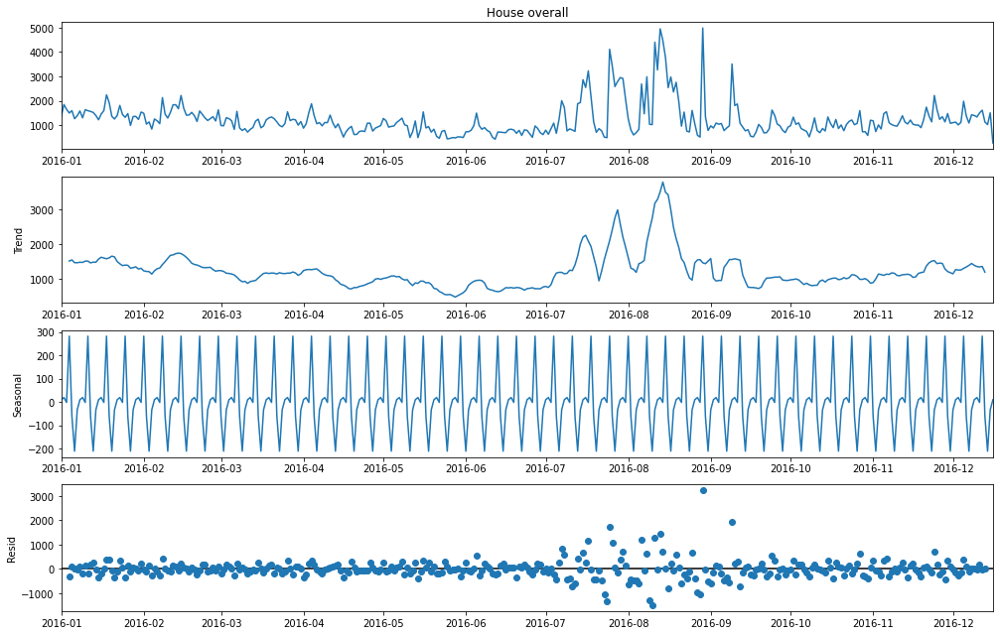

In [69]:
# Time series analysis for energy per day
import statsmodels.api
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

datause=energy_per_day.iloc[:,0].values
#fig,ax=plt.subplots(figsize=(15,10))
plt.rcParams['figure.figsize'] = (14, 9)
result = seasonal_decompose(energy_per_day['House overall'],model='additive')
result.plot()
plt.show()
     

Inference- Trend shows that energy consumption is the maximum during August and September the transition period from summer to fall

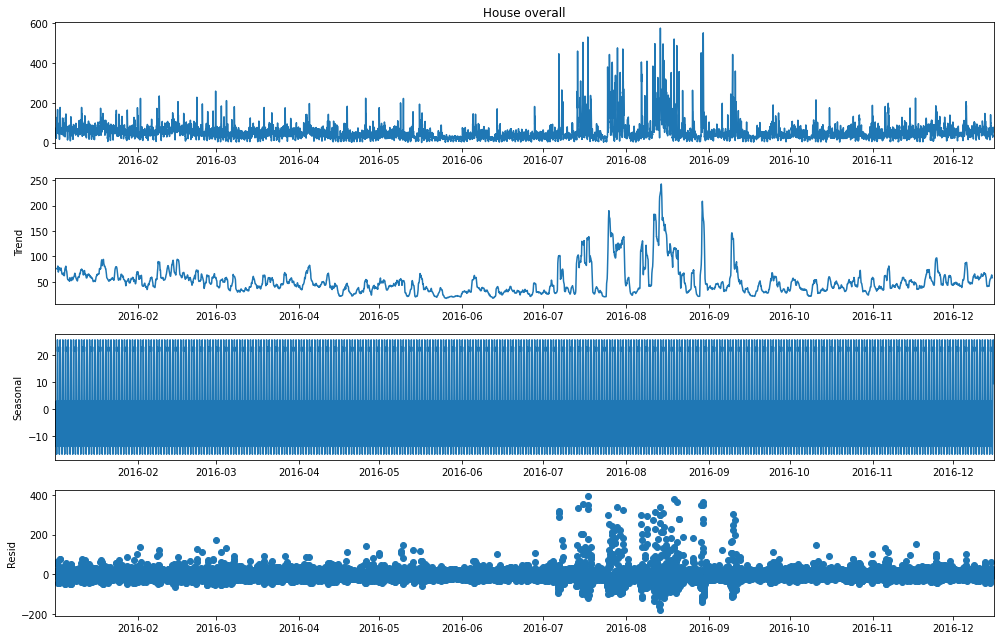

In [70]:
# Time series analysis for energy per Hour
import statsmodels.api
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

datause=energy_per_hour.iloc[:,0].values
#fig,ax=plt.subplots(figsize=(15,10))
plt.rcParams['figure.figsize'] = (14, 9)
result = seasonal_decompose(energy_per_hour['House overall'],model='additive')
result.plot()
plt.show()

Inference- Trend shows that energy consumption is the maximum during August and September

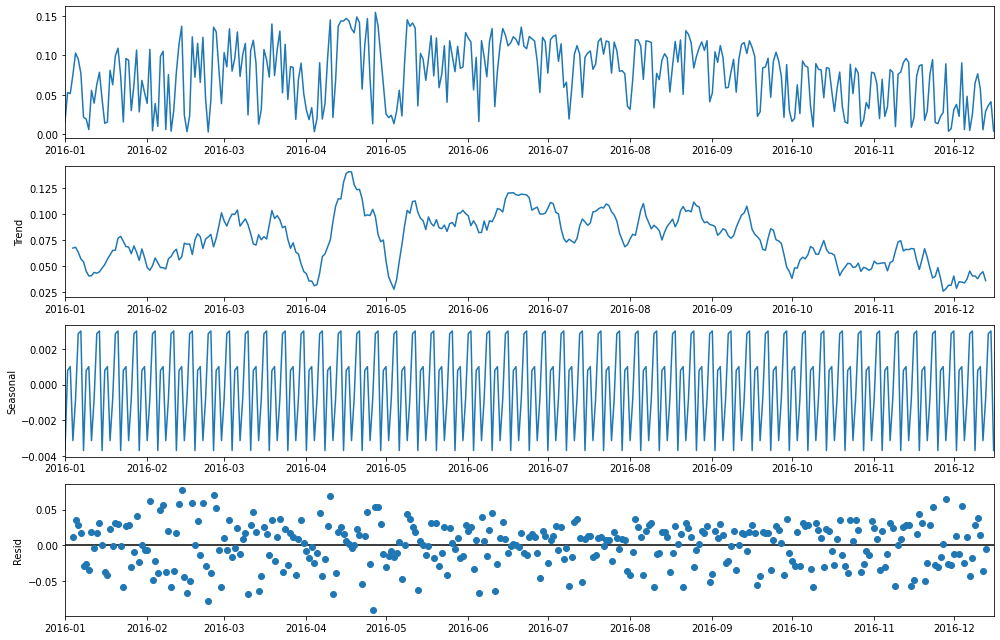

In [71]:
# Time series analysis for energy per day

weather=weather_per_day.iloc[:,0].values
#fig,ax=plt.subplots(figsize=(15,10))
plt.rcParams['figure.figsize'] = (14, 9)
seasonal_decompose(weather_per_day[['Solar']]).plot()
result = adfuller(weather)
plt.show()

**Solar Generation is maximum in the months of April-May**

# **Data Visualization**

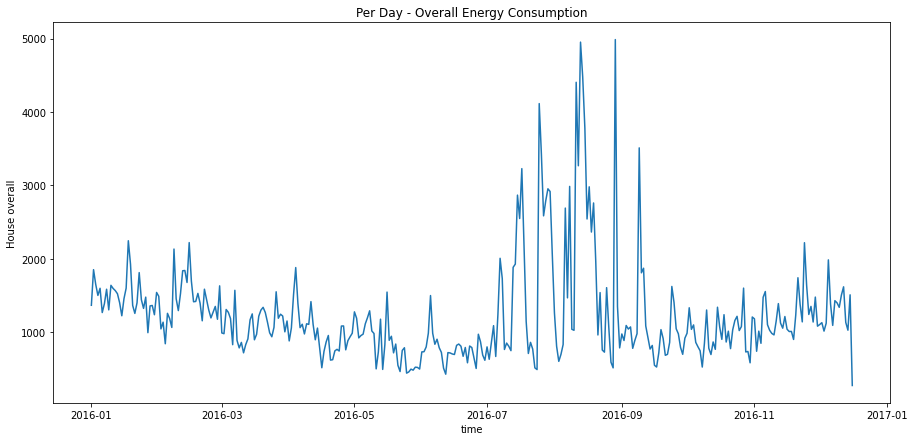

In [72]:
# Plotting total energy consumption per day

plt.figure(figsize=(15,7))
plt.title("Per Day - Overall Energy Consumption")
sns.lineplot(data = energy_per_day['House overall'], dashes=False)
plt.show()

Inference- We can see an increasing trend in energy consumption per day from August and it reaches the peak in September and again starts falling by the end of September 

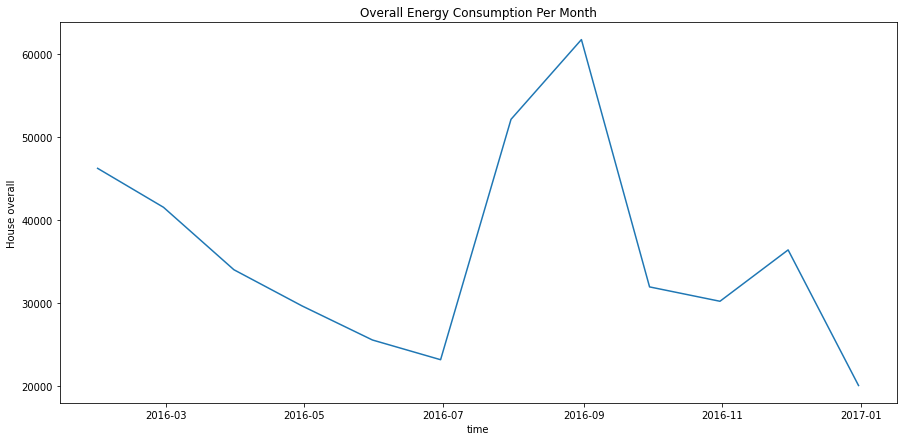

In [73]:
# Plotting total energy consumption per month

plt.figure(figsize=(15,7))
plt.title("Overall Energy Consumption Per Month")
sns.lineplot(data = energy_per_month['House overall'], dashes=False)
plt.show()

**Inference-The highest energy consumption in the year falls in the months of August and September followed by the month of February.**
**Whereas the lowest consumption is in the month of January. **

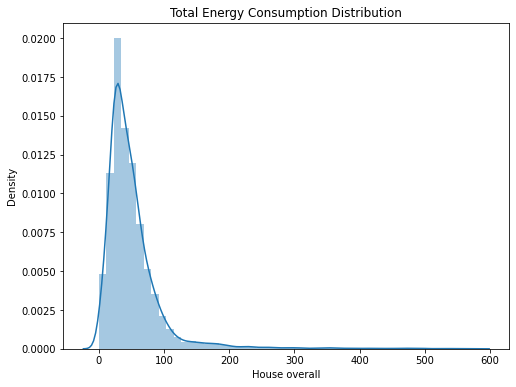

In [74]:
# Plotting the Distribution of energy per hour

plt.figure(figsize=(8,6))
sns.distplot(energy_per_hour['House overall'])
plt.title('Total Energy Consumption Distribution')
plt.show()

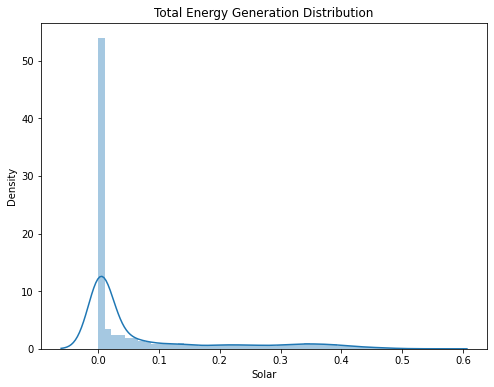

In [75]:
# Plotting the Distribution of Solar generation per hour
plt.figure(figsize=(8,6))
sns.distplot(weather_per_hour['Solar'])
plt.title('Total Energy Generation Distribution')
plt.show()



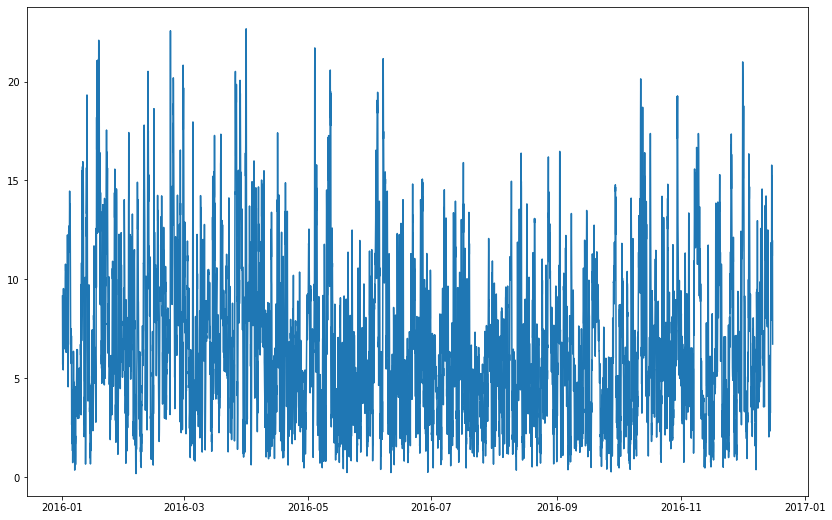

In [76]:
plt.plot(weather_per_hour["windSpeed"])

In [77]:
# Grouping feature with respect to 'appliances' and 'rooms'

app_data = energy_data[['Dishwasher', 'Fridge', 'Garage door', 'Well', 'Microwave', 'Furnace']]

In [78]:
room_data = energy_data[['Home office', 'Wine cellar','Barn', 'Living room', 'Kitchen']]

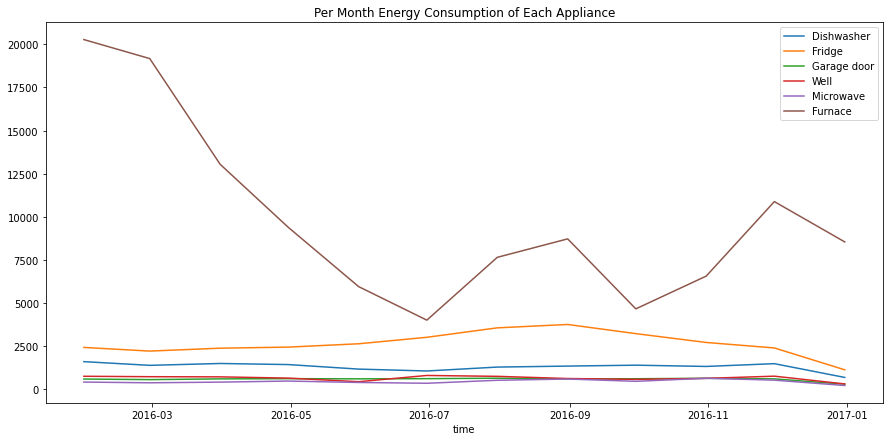

In [79]:
# Plotting per month energy consumption of each device

plt.figure(figsize=(15,7))
plt.title("Per Month Energy Consumption of Each Appliance")
sns.lineplot(data = energy_per_month[app_data.columns], dashes=False)
plt.show()

**Inference-It is very clear that the highest consumption among appliances is taken up by 'Furnace' while 'Microwave' comes in with the lowest consumption.**

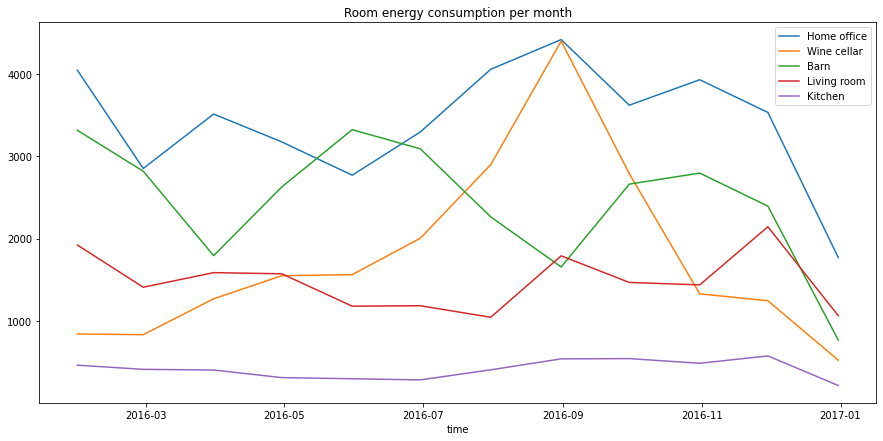

In [80]:
# Plotting  energy consumption of rooms per month

plt.figure(figsize=(15,7))
plt.title("Room energy consumption per month")
sns.lineplot(data = energy_per_month[room_data.columns], dashes=False)
plt.show()

**From above it can be see that 'Home office' has the highest consumption in the among rooms and the 'Kitchen' has the lowest consumption.**

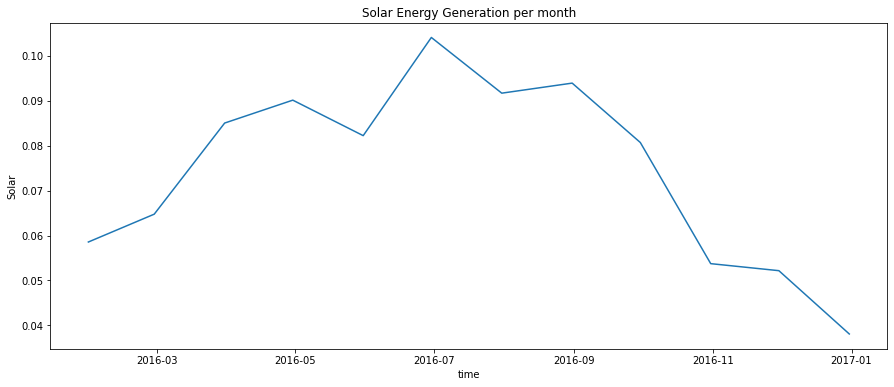

In [81]:
# Plotting total Solar generation per month

plt.figure(figsize=(15,6))
plt.title("Solar Energy Generation per month")
sns.lineplot(data = weather_per_month['Solar'],dashes=False)
plt.show()

**Inference-From the plot the Solar power generation is at its highest rate in the months of July - September.**

In [82]:
data.columns

Index(['time', 'House overall', 'Dishwasher', 'Home office', 'Fridge',
       'Wine cellar', 'Garage door', 'Barn', 'Well', 'Microwave',
       'Living room', 'Solar', 'temperature', 'icon', 'humidity', 'visibility',
       'summary', 'apparentTemperature', 'pressure', 'windSpeed', 'cloudCover',
       'windBearing', 'precipIntensity', 'dewPoint', 'precipProbability',
       'Furnace', 'Kitchen', 'year', 'month', 'day', 'hour', 'minute',
       'timing', 'season'],
      dtype='object')

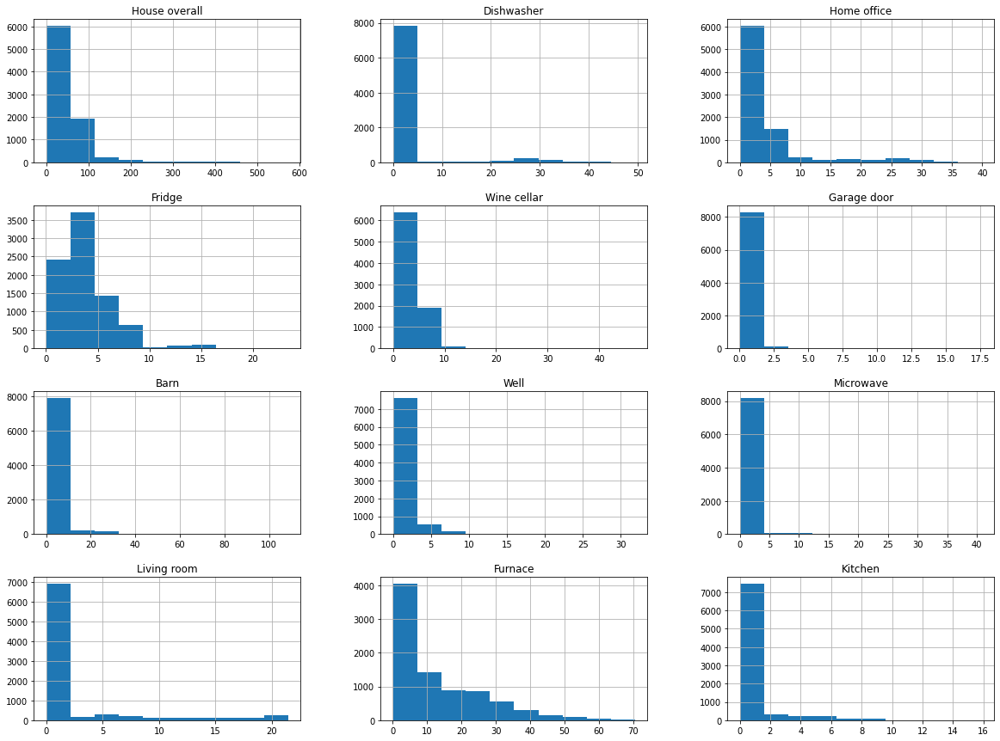

In [83]:
# Plotting Frequency graph showing distribution
freqgraph = energy_per_hour.select_dtypes(include=["float",'int'])
freqgraph.hist(figsize=(20,15))
plt.show()

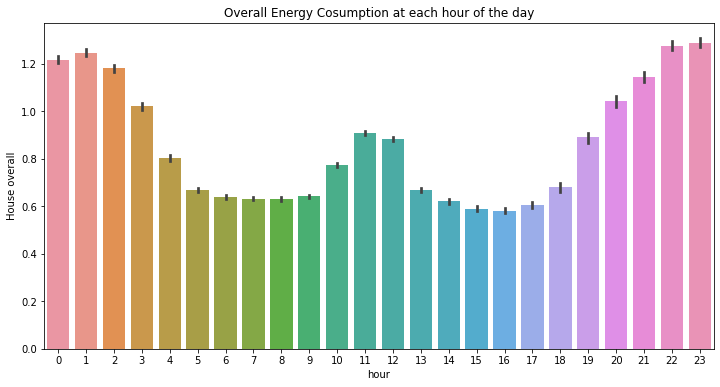

In [84]:
# Plotting total Energy Consumption with respect to time in a day

plt.figure(figsize=(12,6))
sns.barplot(x=data['hour'], y=data['House overall'])
plt.title('Overall Energy Cosumption at each hour of the day')
plt.show()

**The overall power consumption is more during 7pm to 4am followed by 10am to 12noon and. The reason is people return from work around 6pm and use all the appliances.**

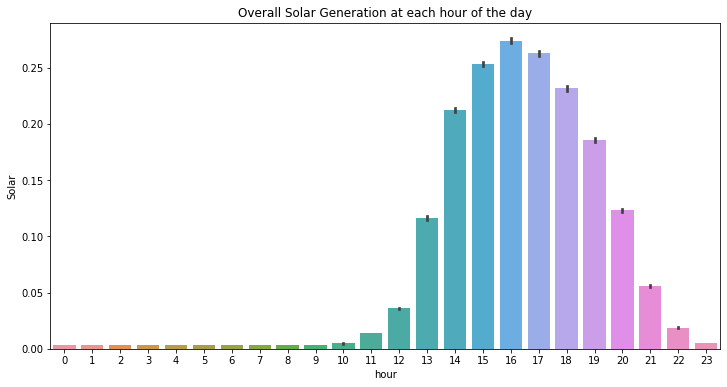

In [85]:
# Plotting total Energy Generation with respect to time in a day

plt.figure(figsize=(12,6))
sns.barplot(x=data['hour'], y=data['Solar'])
plt.title('Overall Solar Generation at each hour of the day')
plt.show()

**The Energy generation is at the highest between 3pm and 6pm**

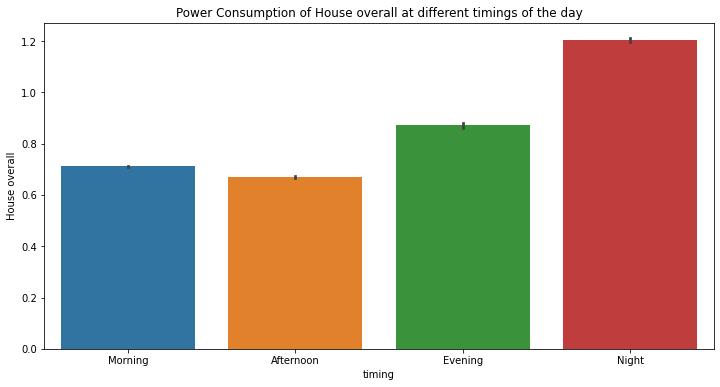

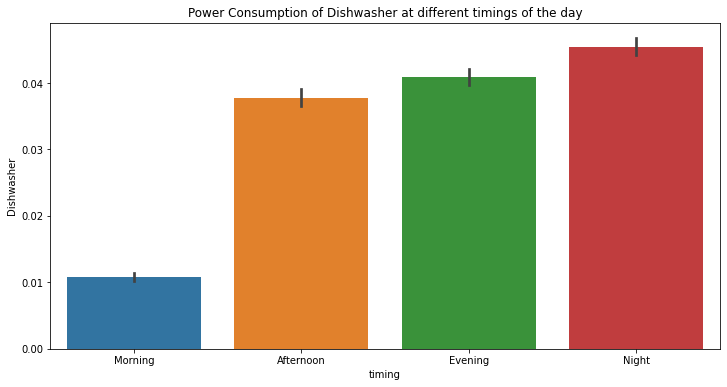

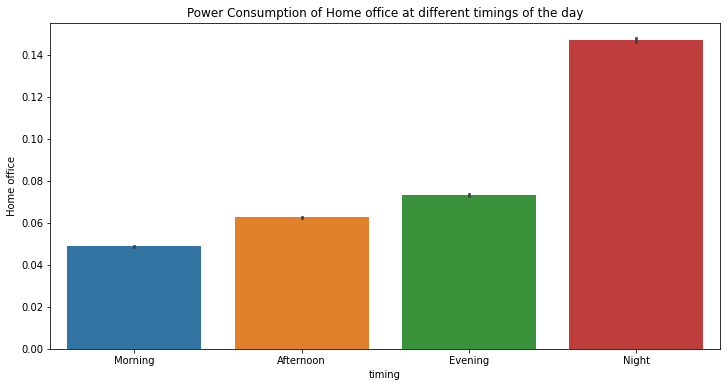

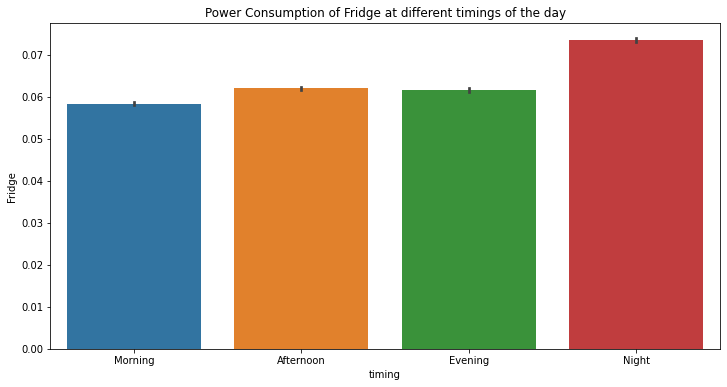

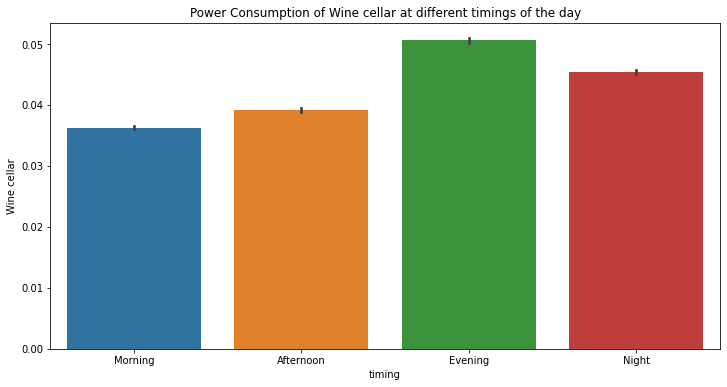

...

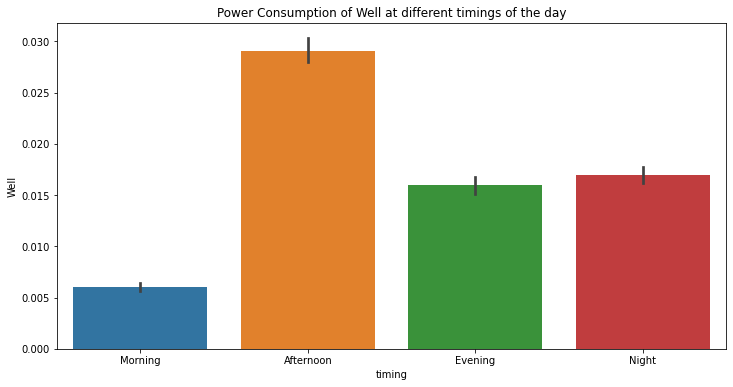

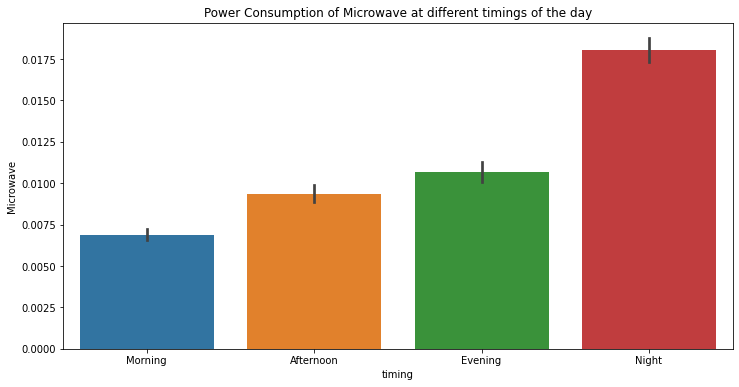

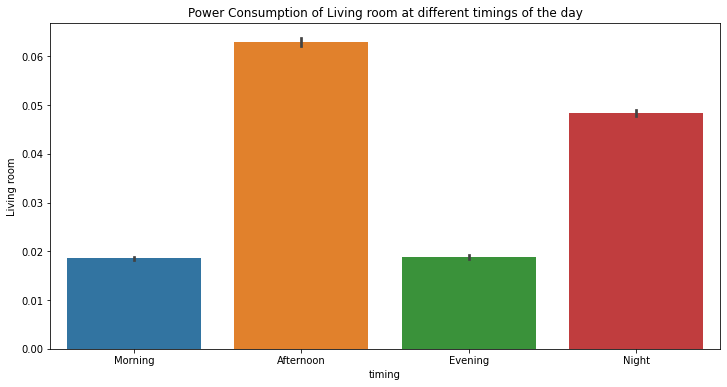

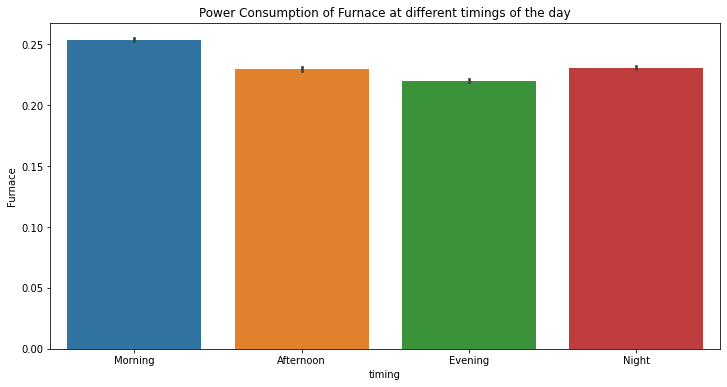

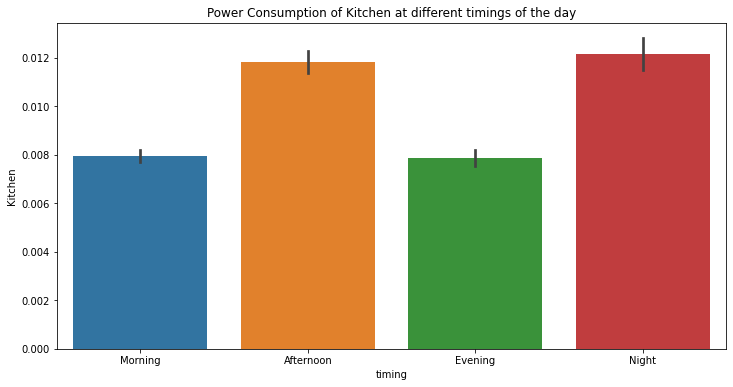

In [86]:
# Plotting total Energy Consumption of different appliances with respect to timings in a day
for i in energy_data:
  plt.figure(figsize=(12,6))
  sns.barplot(x=data['timing'], y=data[i])
  plt.title('Power Consumption of {} at different timings of the day'.format(i))
  plt.show()

Inference

Appliances like Fridge, Home Office,Dishwasher,microwave and Kitchen consume maximum energy during night

Furnace consumes maximum energy during the morning time.

Winecellar and Barn consumes more energy during the evenings.

Garage door uses more energy during the afternoon and evening.

Well and living room uses more energy during the afternoons.


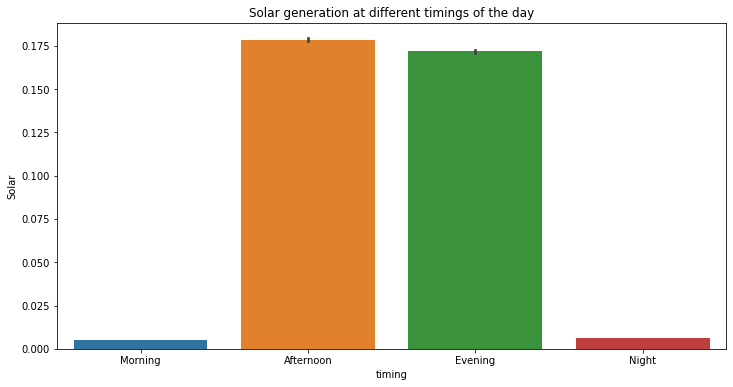

In [87]:
# Plotting total Energy Generation with respect to timings in a day

plt.figure(figsize=(12,6))
sns.barplot(x=data['timing'], y=data['Solar'])
plt.title('Solar generation at different timings of the day')
plt.show()

**Inference- Solar Generation is at maximum during the Afternoons and then the evenings.**

<Axes: title={'center': 'Mean Temperature Per Month'}, xlabel='time', ylabel='°F'>

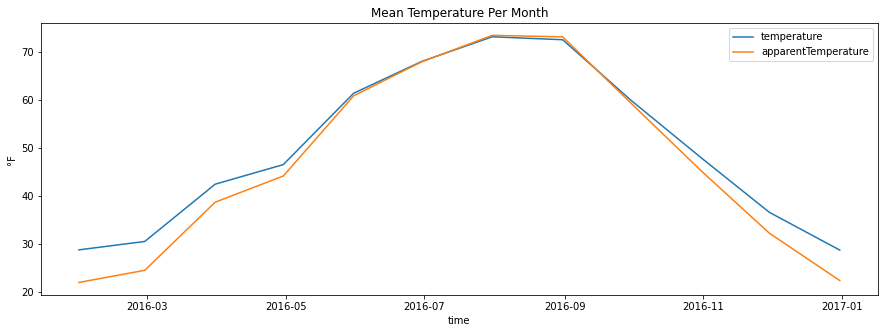

In [88]:
#Plot of Average Temperature per month
plt.figure(figsize=(15,5))
plt.ylabel('°F')
plt.title("Mean Temperature Per Month")
sns.lineplot(data = weather_per_month[['temperature', 'apparentTemperature']],dashes=False)

**Inference- Average Maximum temperature recorded is around 75 degree farenheit and minimum is around 20 degree frenheit.**


<Axes: title={'center': 'Mean Humidity Per Month'}, xlabel='time', ylabel='humidity'>

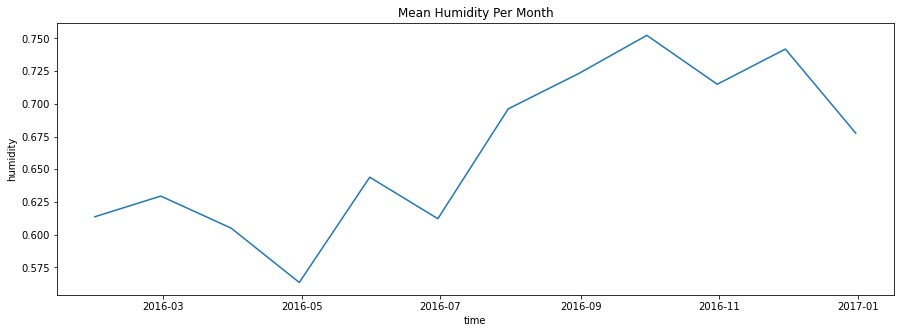

In [89]:
plt.figure(figsize=(15,5))
plt.title("Mean Humidity Per Month")
sns.lineplot(data = weather_per_month['humidity'],dashes=False)

**Inference- Humidity seems to be at maximum (around 70 to 75% ) in summer and Autumn**

## **Calulating Total Energy Consumption per month for rooms and appliances respectively**

In [90]:
rooms_energy_per_month = energy_per_month[['Home office', 'Wine cellar','Barn', 'Living room', 'Kitchen']]

In [91]:
app_energy_per_month = energy_per_month[['Dishwasher', 'Fridge', 'Garage door', 'Well', 'Microwave', 'Furnace']]

In [92]:
rooms_tot_consum_per_month = rooms_energy_per_month.sum()
app_tot_consum_per_month = app_energy_per_month.sum()

In [93]:
print('The total energy consumption of rooms per month is :\n', rooms_tot_consum_per_month, '\n')
print('The total energy consumption of appliances per month is :\n', app_tot_consum_per_month)

The total energy consumption of rooms per month is :
 Home office    40961.277962
Wine cellar    21233.079320
Barn           29493.633696
Living room    17794.476716
Kitchen         4932.186582
dtype: float64 

The total energy consumption of appliances per month is :
 Dishwasher      15806.409510
Fridge          32026.710600
Garage door      7124.847316
Well             7882.163852
Microwave        5534.440218
Furnace        118917.457954
dtype: float64


# Plotting Pie Chart to show % Consumption of rooms per month  

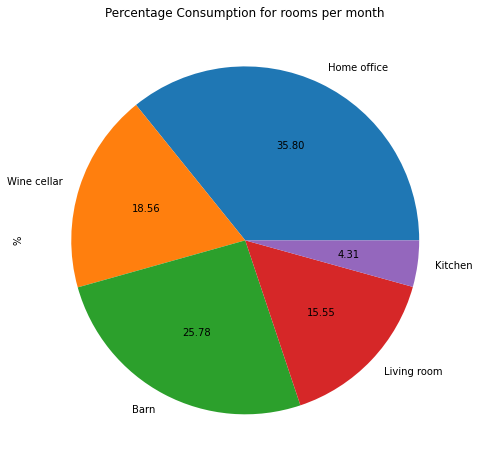

In [94]:
# Plotting Pie Chart to show % Consumption of rooms per month  

rooms_tot_consum_per_month.plot(kind="pie", autopct='%.2f', figsize=(8,8))
plt.title("Percentage Consumption for rooms per month")
plt.ylabel('%')
plt.show()

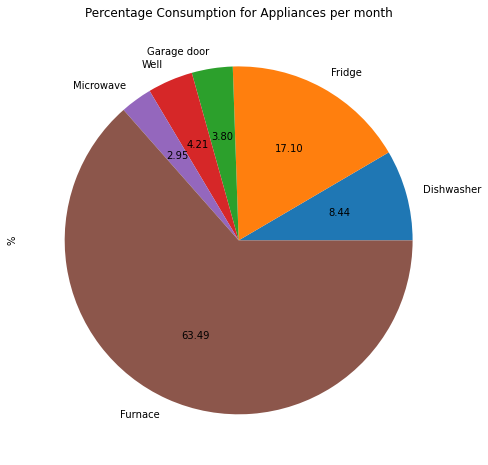

In [95]:
# Plotting Pie Chart to show % Consumption of devices per month 

app_tot_consum_per_month.plot(kind="pie", autopct='%.2f', figsize=(8,8))
plt.title("Percentage Consumption for Appliances per month")
plt.ylabel('%')
plt.show()

## Regplot showing regression line between two parameters and the linear relationship 

how tight the datapoints occuring around them determines the extent of linear relationship

If the datapoints appears close to the regression line. the line seems to be a good fit regression line

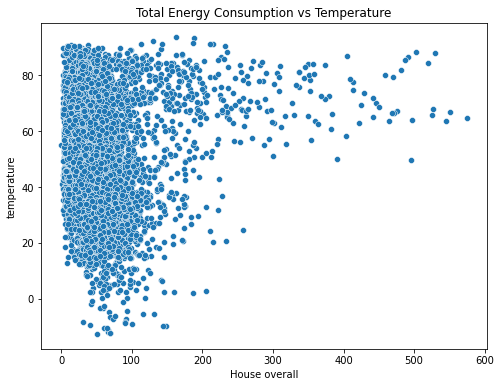

In [96]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=energy_per_hour['House overall'], y= weather_per_hour['temperature'])
plt.title('Total Energy Consumption vs Temperature')
plt.show()

Inference- 

When temperature is in the range of 60 to 80 degree F energy consumption seems to be the most.

When Temperatures occurs between 0 to 10 degree F House Overall it at its minimum range

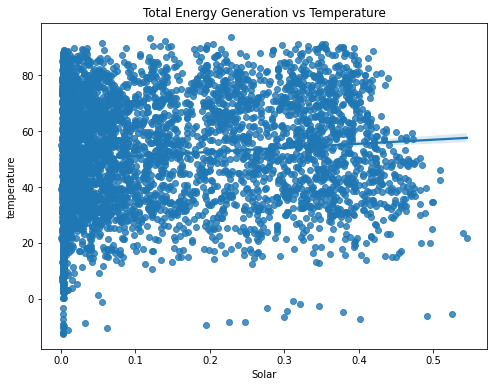

In [97]:
plt.figure(figsize=(8,6))
sns.regplot(x=weather_per_hour['Solar'], y= weather_per_hour['temperature'])
plt.title('Total Energy Generation vs Temperature')
plt.show()

There doesnt seem to be any linear relationship between Solar generation and temperature in our data

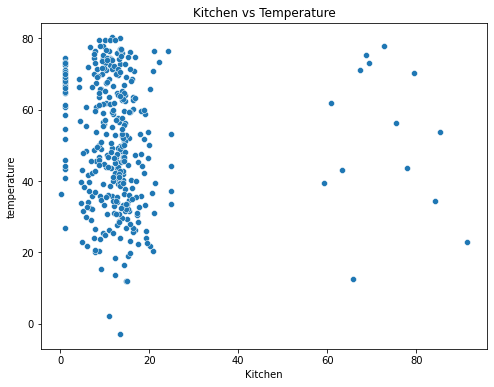

In [98]:
plt.figure(figsize=(8,6))
sns.scatterplot(x = energy_per_day['Kitchen'], y = weather_per_day['temperature'])
plt.title('Kitchen vs Temperature')
plt.show()

Maximum datapoints occur uin the range where temoerature is between 25 degree and 80 degree F and Kitchen usage is between 0 to 20 Kw.

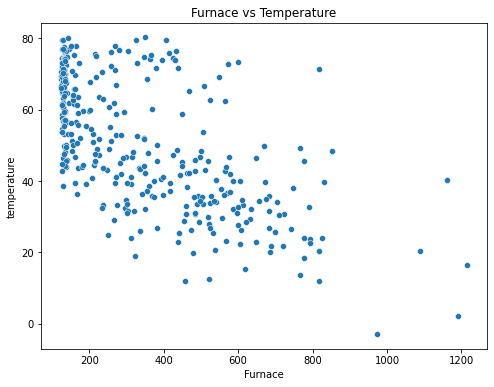

In [99]:
plt.figure(figsize=(8,6))
sns.scatterplot(x = energy_per_day['Furnace'], y = weather_per_day['temperature'])
plt.title('Furnace vs Temperature')
plt.show()

**Inference- When the temperature is high ,Furnace seems to consume less energy and viceversa.**

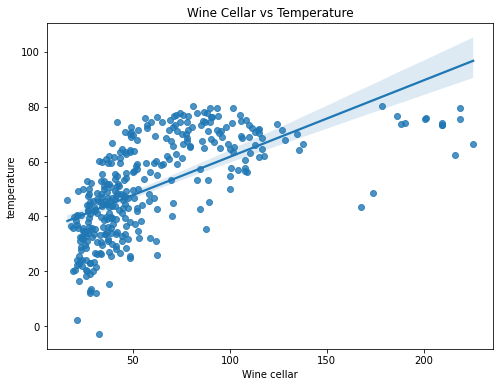

In [100]:
plt.figure(figsize=(8,6))
sns.regplot(x = energy_per_day['Wine cellar'], y = weather_per_day['temperature'])
plt.title('Wine Cellar vs Temperature')
plt.show()

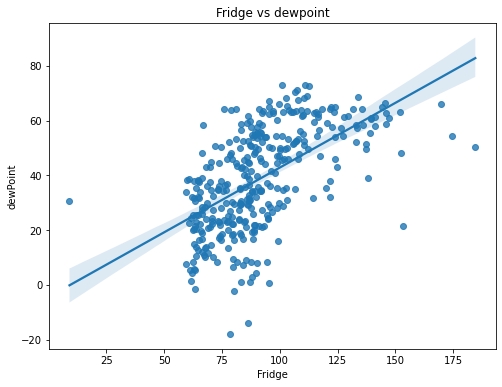

In [101]:
plt.figure(figsize=(8,6))
sns.regplot(x = energy_per_day['Fridge'], y = weather_per_day['dewPoint'])
plt.title('Fridge vs dewpoint')
plt.show()


In the reg plot of dewPoint and temperature datapoints appears close to the regression line.Hence line seems to be a good fit regression line

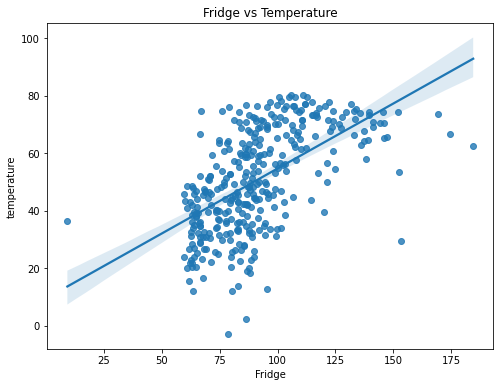

In [102]:
plt.figure(figsize=(8,6))
sns.regplot(x = energy_per_day['Fridge'], y = weather_per_day['temperature'])
plt.title('Fridge vs Temperature')
plt.show()


**In the reg plot of Fridge and temperature datapoints appears close to the regression line.Hence line seems to be a good fit regression line**

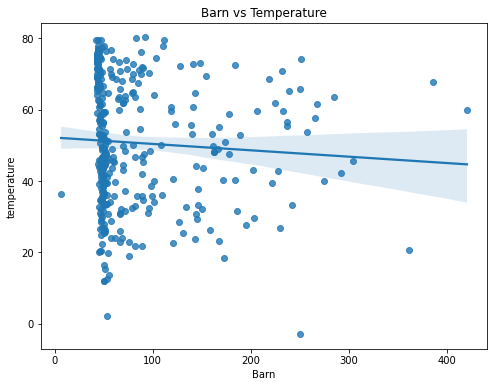

In [103]:
plt.figure(figsize=(8,6))
sns.regplot(x = energy_per_day['Barn'], y = weather_per_day['temperature'])
plt.title('Barn vs Temperature')
plt.show()

**Barn seems to be using energy of  50 Kws mostly**

## Count Plot

In [104]:
data['summary'].unique()

array(['Clear', 'Mostly Cloudy', 'Overcast', 'Partly Cloudy', 'Drizzle',
       'Light Rain', 'Rain', 'Light Snow', 'Flurries', 'Breezy', 'Snow',
       'Rain and Breezy', 'Foggy', 'Breezy and Mostly Cloudy',
       'Breezy and Partly Cloudy', 'Flurries and Breezy', 'Dry',
       'Heavy Snow'], dtype=object)

In [105]:
data['icon'].unique()

array(['clear-night', 'partly-cloudy-night', 'clear-day', 'cloudy',
       'partly-cloudy-day', 'rain', 'snow', 'wind', 'fog', nan],
      dtype=object)

### Countplots

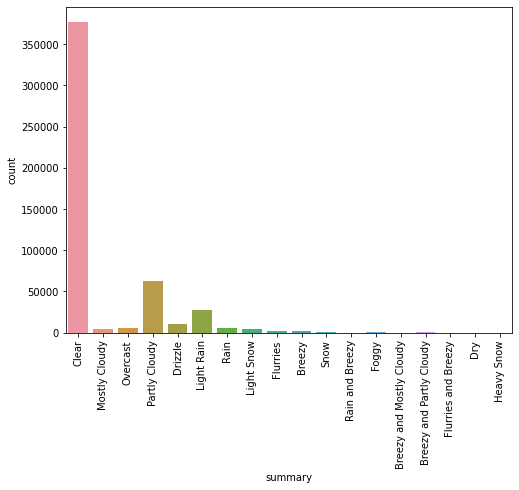

In [106]:
plt.figure(figsize=(8,6))
sns.countplot(x='summary', data=data )
plt.xticks(rotation=90)
plt.show()

**Mostly the climate is clear (around 75% of the year).**
**There is only slight rain in this region (around 3 weeks).** 

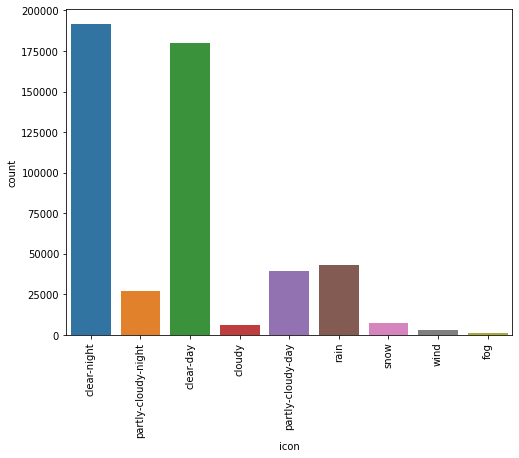

In [107]:
plt.figure(figsize=(8,6))
sns.countplot(x='icon', data=data )
plt.xticks(rotation=90)
plt.show()

**This region mostly has a clear night and a clear day it rains only in less than a month**

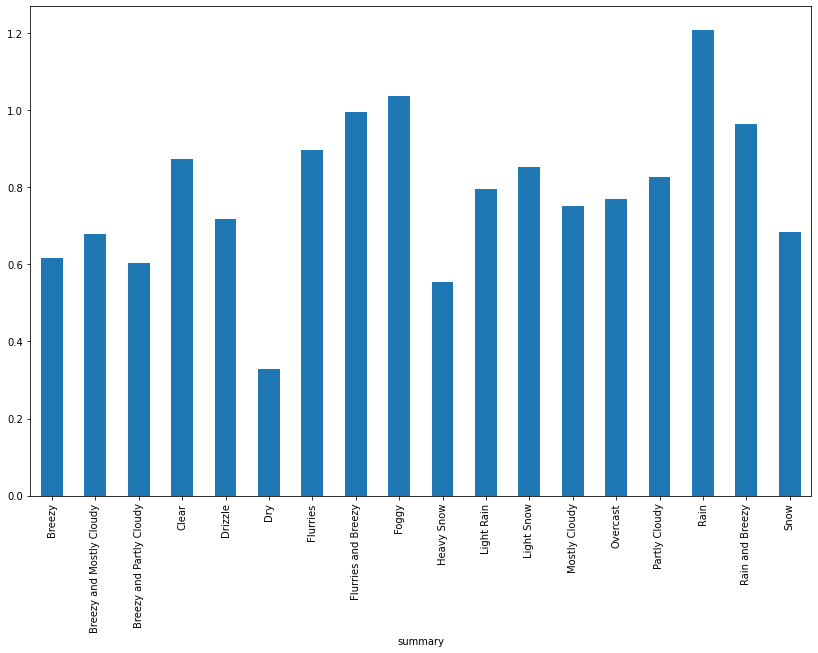

In [108]:
data.groupby('summary')['House overall'].mean().plot.bar()
plt.show()

**Energy consumption is more on rainy days and less on dry days**

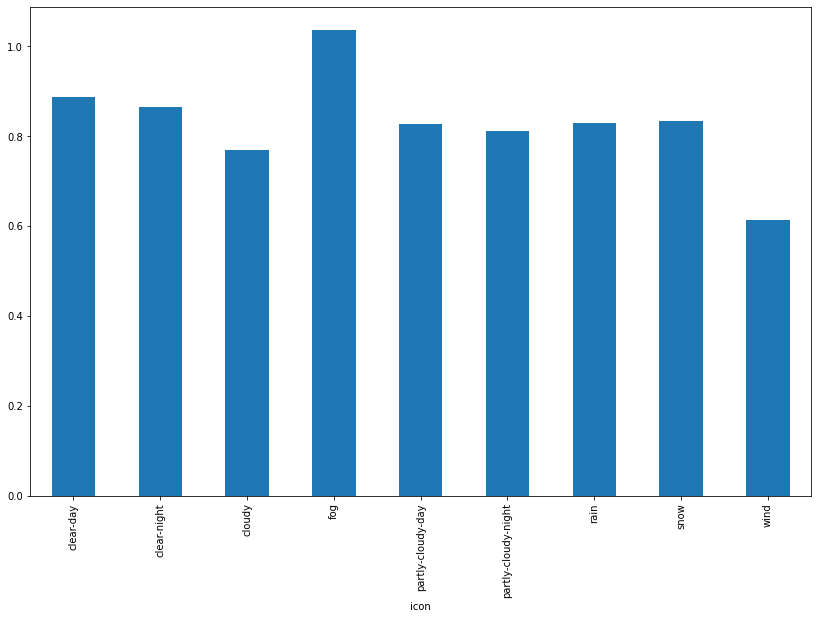

In [109]:
data.groupby('icon')['House overall'].mean().plot.bar()
plt.show()

**Energy consumption according to the icon column is even is higher on foggy days**

## **Univariate analysis of different features**

In [110]:
appl_total=energy_data.iloc[:,:].sum()
appl_total=pd.DataFrame(appl_total).reset_index() 
appl_total.columns

Index(['index', 0], dtype='object')

In [111]:
appl_total.rename(columns={"index": "Appliances", 0: "Usage"},inplace=True)

In [112]:
appl_total.columns

Index(['Appliances', 'Usage'], dtype='object')

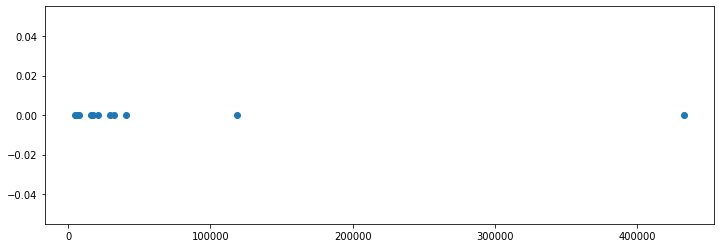

In [113]:
plt.figure(figsize=(12,4))
plt.plot(appl_total['Usage'],np.zeros_like(appl_total['Usage']),'o')

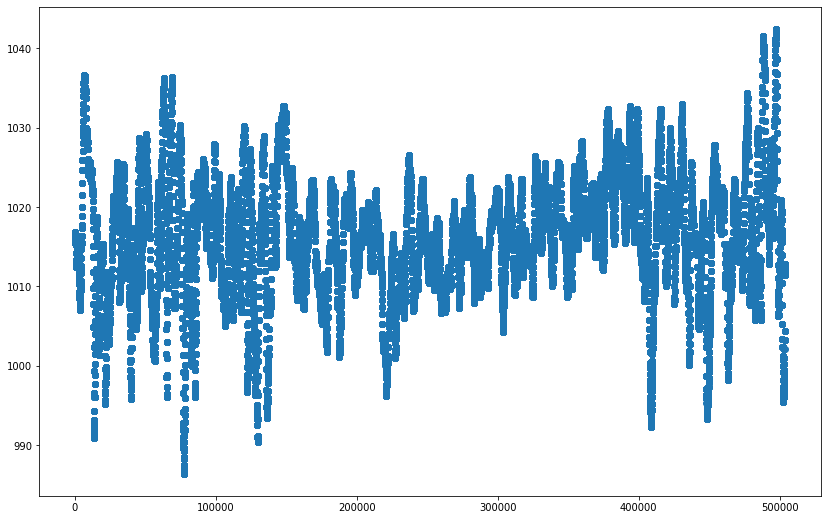

In [114]:
plt.scatter(data.index,data['pressure'])
plt.show()

**Pressure seems to be in a consistent range between 1005 and 1030 and seems to be maximum at 1050**


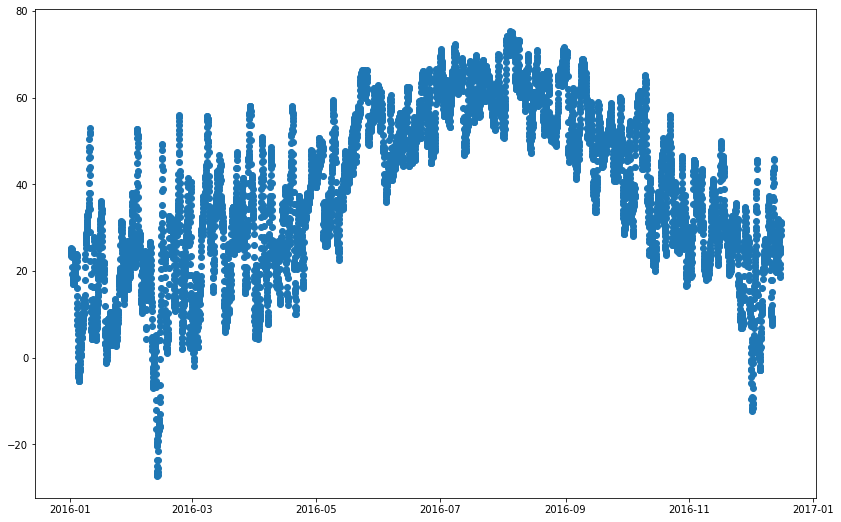

In [115]:
plt.scatter(weather_per_hour.index,weather_per_hour['dewPoint'])
plt.show()

**Dewpoint is recorded in the maximum range of 50 to 70 % in the summer months of July August and September**

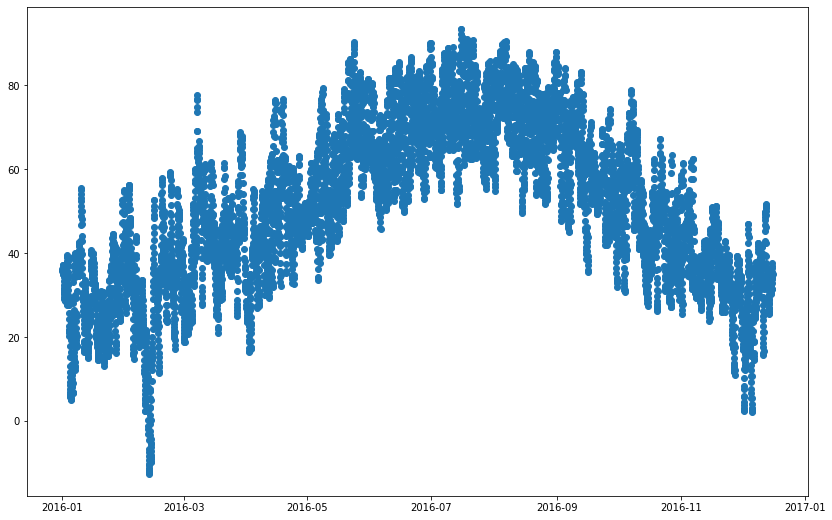

In [116]:
plt.scatter(weather_per_hour.index,weather_per_hour['temperature'])
plt.show()

**Temperature is showing an inverted U with its peak around 94 degree farenheit in the summer months and its lowest recorded at around -12 degrees farenheit**

### **Usage of different appliabnces are ploted using univcarite plots below**

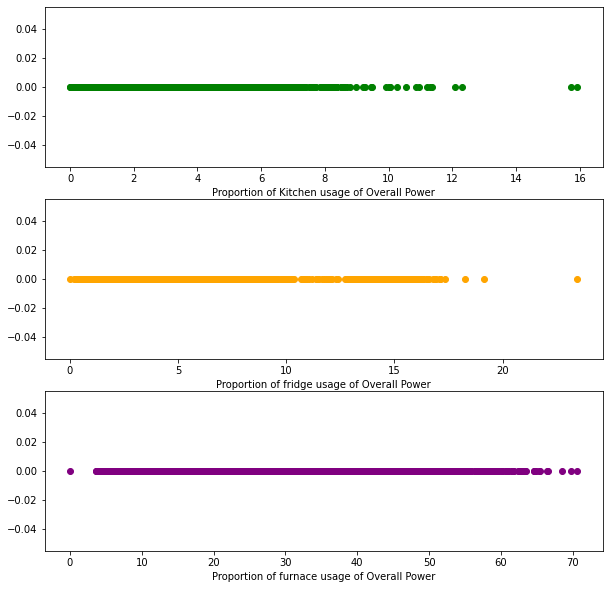

In [117]:
plt.figure(figsize=(10,10))

plt.subplot(3,1,1)
plt.plot(energy_per_hour['Kitchen'],np.zeros_like(energy_per_hour['Kitchen']),'o',color='green')
plt.xlabel('Proportion of Kitchen usage of Overall Power')
plt.subplot(3,1,2)
plt.plot(energy_per_hour['Fridge'],np.zeros_like(energy_per_hour['Fridge']),'o',color='Orange')
plt.xlabel('Proportion of fridge usage of Overall Power')
plt.subplot(3,1,3)
plt.plot(energy_per_hour['Furnace'],np.zeros_like(energy_per_hour['Furnace']),'o',color='Purple')   
plt.xlabel('Proportion of furnace usage of Overall Power')
plt.show()

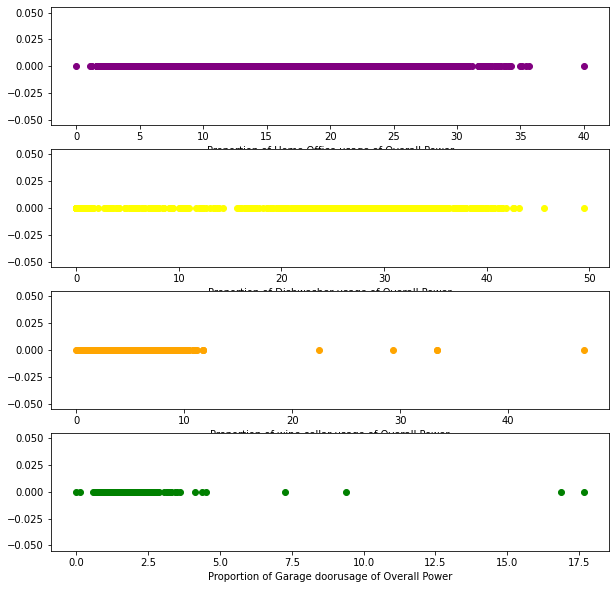

In [118]:
plt.figure(figsize=(10,10))
plt.subplot(4,1,1)
plt.plot(energy_per_hour['Home office'],np.zeros_like(energy_per_hour['Home office']),'o',color='Purple')
plt.xlabel('Proportion of Home Office usage of Overall Power')
plt.subplot(4,1,2)
plt.plot(energy_per_hour['Dishwasher'],np.zeros_like(energy_per_hour['Dishwasher']),'o',color='Yellow')
plt.xlabel('Proportion of Dishwasher usage of Overall Power')
plt.subplot(4,1,3)
plt.plot(energy_per_hour['Wine cellar'],np.zeros_like(energy_per_hour['Wine cellar']),'o',color='Orange')
plt.xlabel('Proportion of wine cellar usage of Overall Power')
plt.subplot(4,1,4)
plt.plot(energy_per_hour['Garage door'],np.zeros_like(energy_per_hour['Garage door']),'o',color='green')
plt.xlabel('Proportion of Garage doorusage of Overall Power')
plt.show()

# Bivariate Analysis

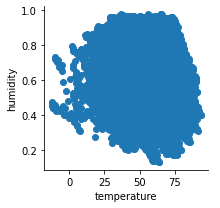

In [119]:
sns.FacetGrid(weather_per_hour).map(plt.scatter,'temperature','humidity').add_legend()
plt.show()

### Facet Grid of temperature and dewpoint= showing positive correlation

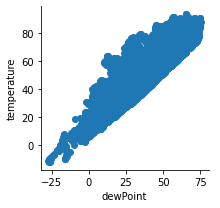

In [120]:
#Facet Grid of temperature and dewpoint= showing positive correlation
sns.FacetGrid(weather_per_hour).map(plt.scatter,'dewPoint','temperature').add_legend()
plt.show()

**Temperature and dewpoint has a positive correlation**

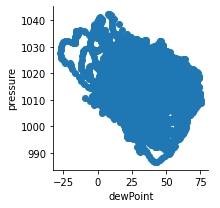

In [121]:
sns.FacetGrid(weather_per_hour).map(plt.scatter,'dewPoint','pressure').add_legend()
plt.show()

**Dewpoint and tempetuare has a mild negative correlation**

### **Pair Plot of weather parameters with solar energy generation and Power Consumption**

In [122]:
weather_energy =pd.concat([weather_data[['temperature', 'humidity', 'pressure', 'windSpeed', 'cloudCover','Solar']], energy_data[['House overall']]], axis=1)

In [123]:
#weather_energy = pd.DataFrame(weather_energy)

In [124]:
weather_energy

,temperature,humidity,pressure,windSpeed,cloudCover,Solar,House overall
time,,,,,,,
2016-01-01 05:00:00,36.14,0.62,1016.91,9.18,0.75,0.003483,0.932833
2016-01-01 05:01:00,36.14,0.62,1016.91,9.18,0.75,0.003467,0.934333
2016-01-01 05:02:00,36.14,0.62,1016.91,9.18,0.75,0.003467,0.931817
2016-01-01 05:03:00,36.14,0.62,1016.91,9.18,0.75,0.003483,1.022050
2016-01-01 05:04:00,36.14,0.62,1016.91,9.18,0.75,0.003467,1.139400
...,...,...,...,...,...,...,...
2016-12-16 03:25:00,35.12,0.86,1011.49,6.72,0.31,0.003183,1.601233
2016-12-16 03:26:00,35.12,0.86,1011.49,6.72,0.31,0.003233,1.599333
2016-12-16 03:27:00,35.12,0.86,1011.49,6.72,0.31,0.003217,1.924267


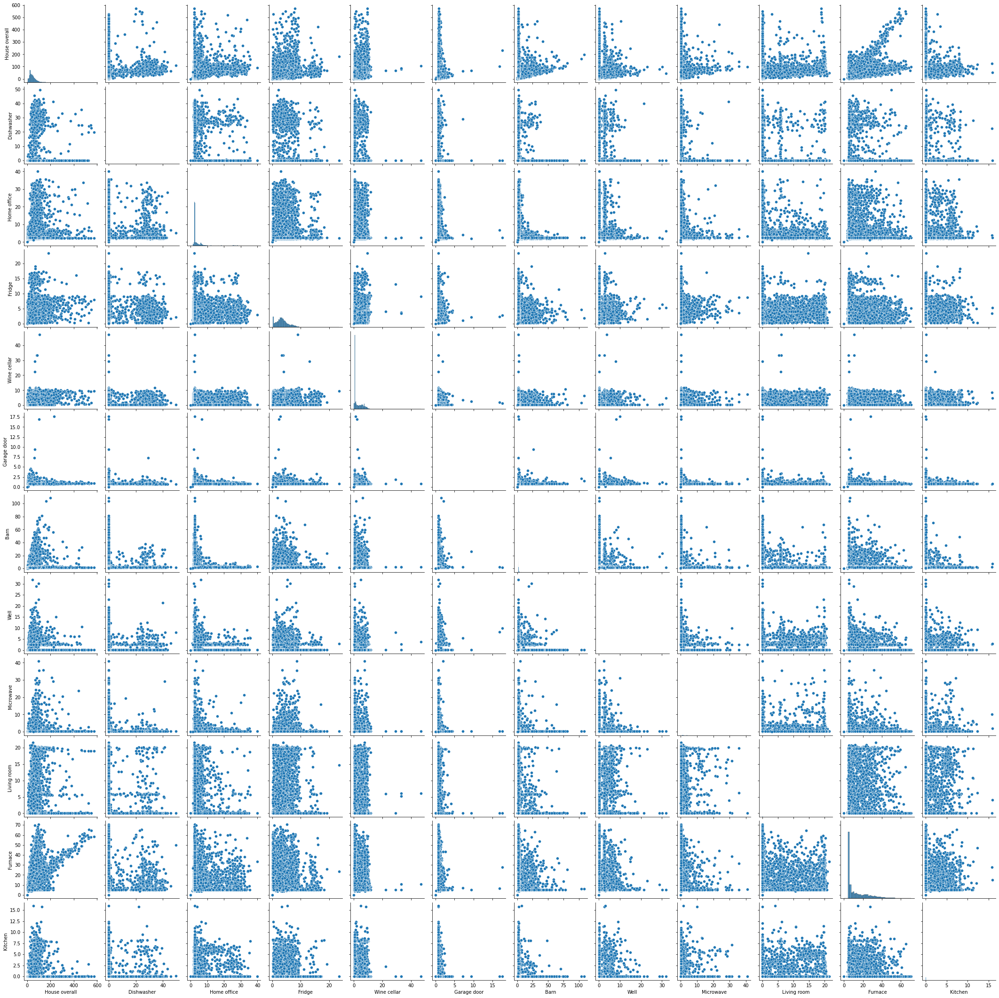

In [125]:
sns.pairplot(energy_per_hour)


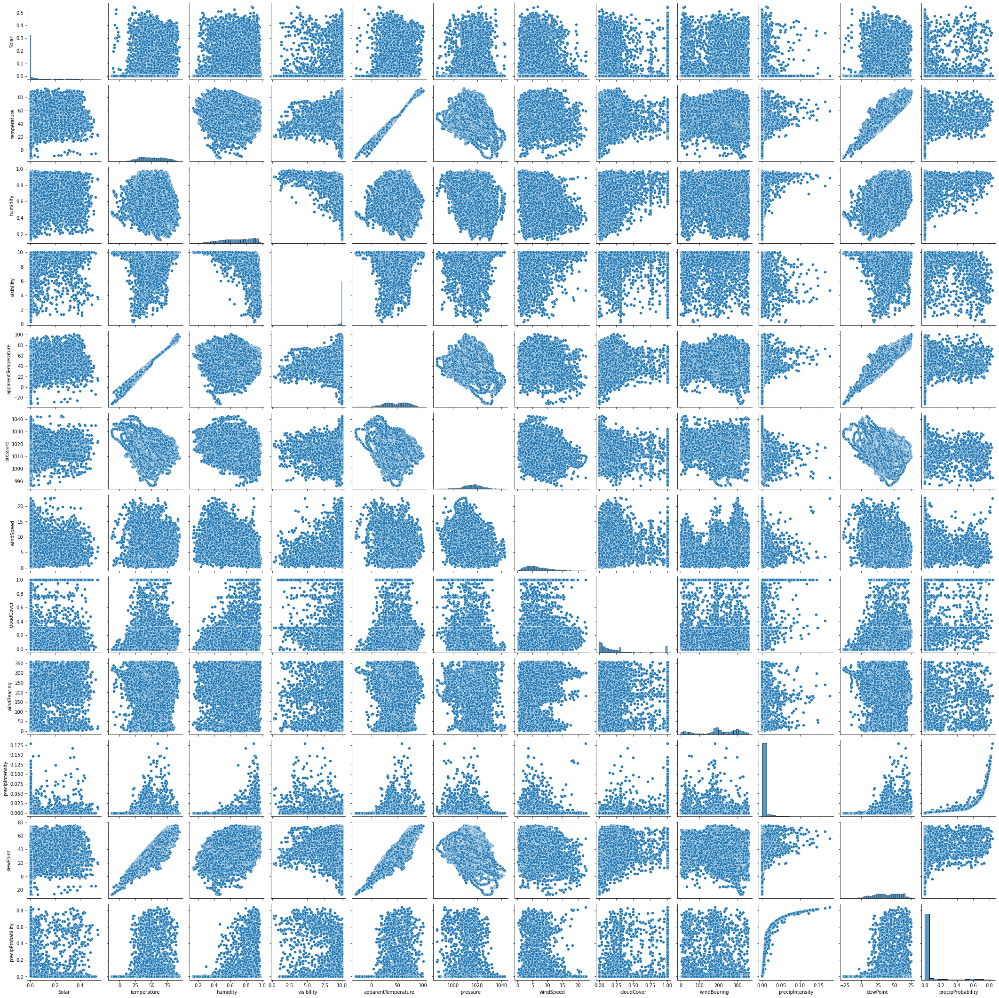

In [126]:
sns.pairplot(weather_per_hour)

## **Distribution of Numerical Data**

---



### **Distplot**

In [127]:
numerical

['House overall',
 'Dishwasher',
 'Home office',
 'Fridge',
 'Wine cellar',
 'Garage door',
 'Barn',
 'Well',
 'Microwave',
 'Living room',
 'Solar',
 'temperature',
 'humidity',
 'visibility',
 'apparentTemperature',
 'pressure',
 'windSpeed',
 'cloudCover',
 'windBearing',
 'precipIntensity',
 'dewPoint',
 'precipProbability',
 'Furnace',
 'Kitchen']

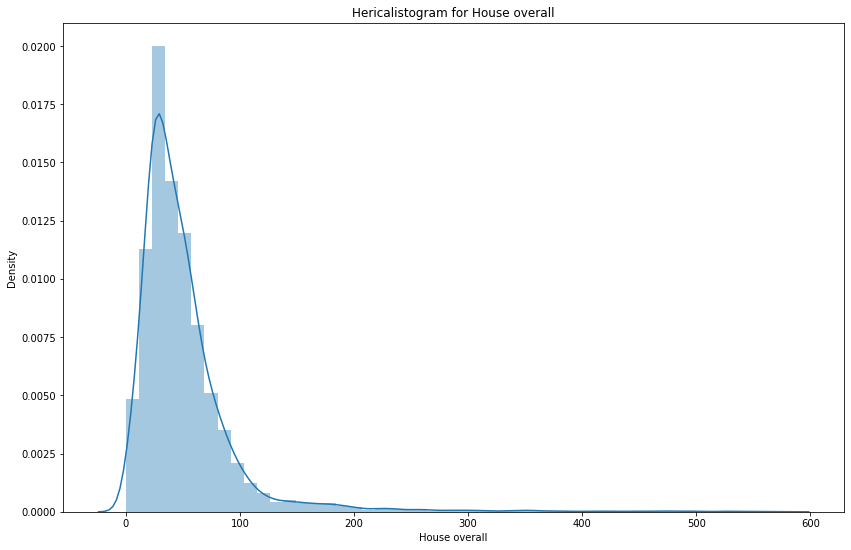

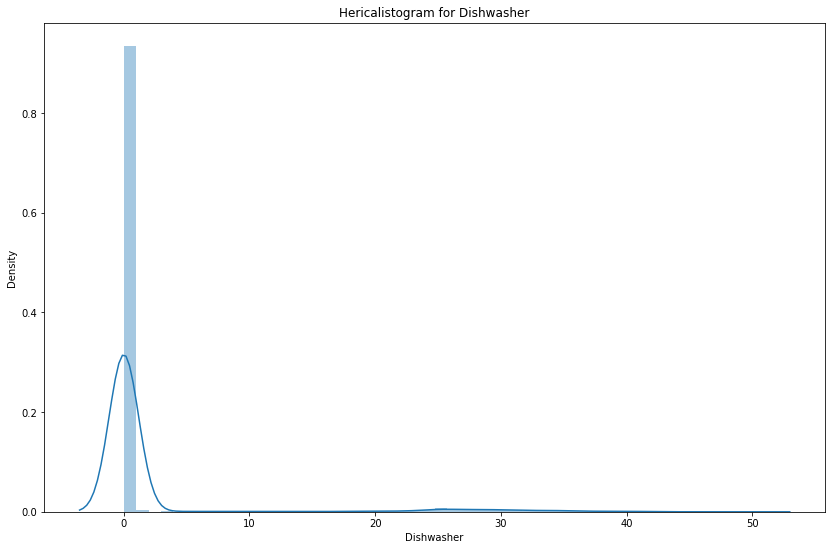

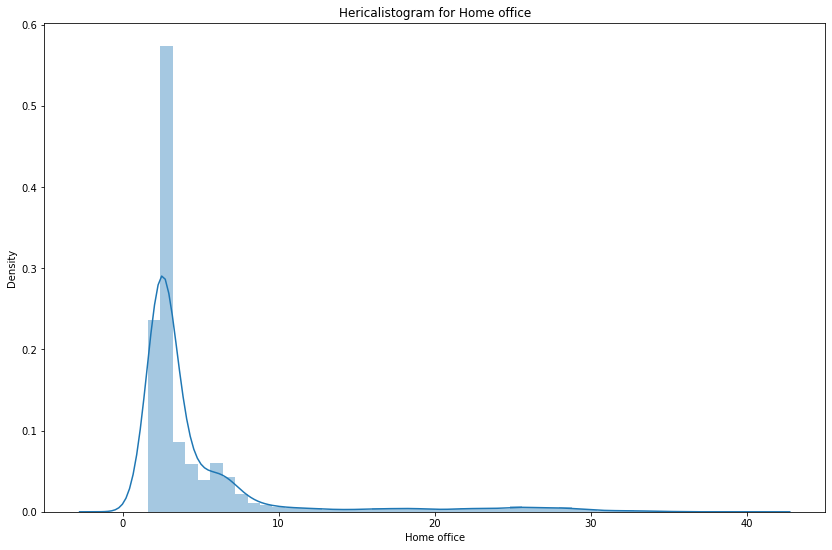

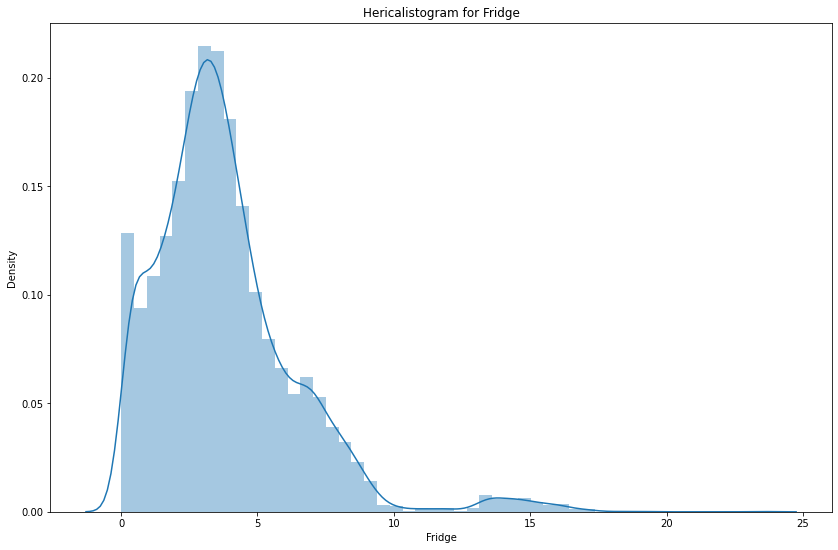

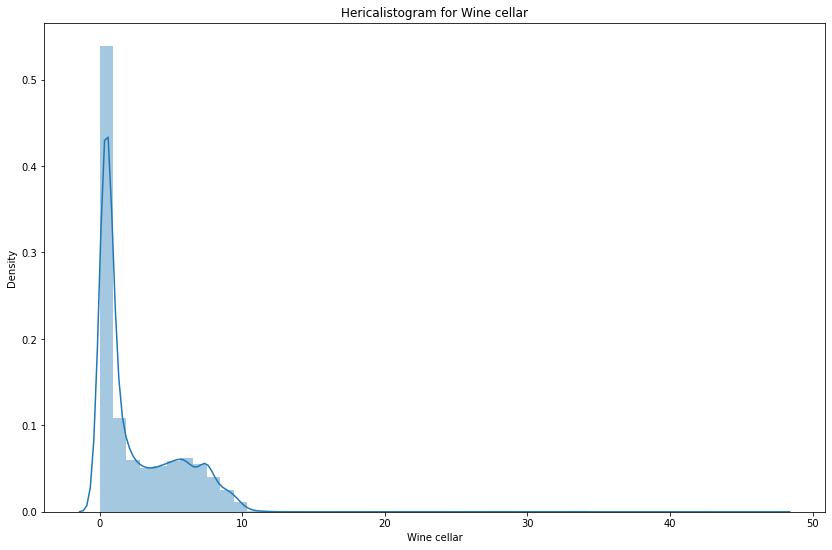

...

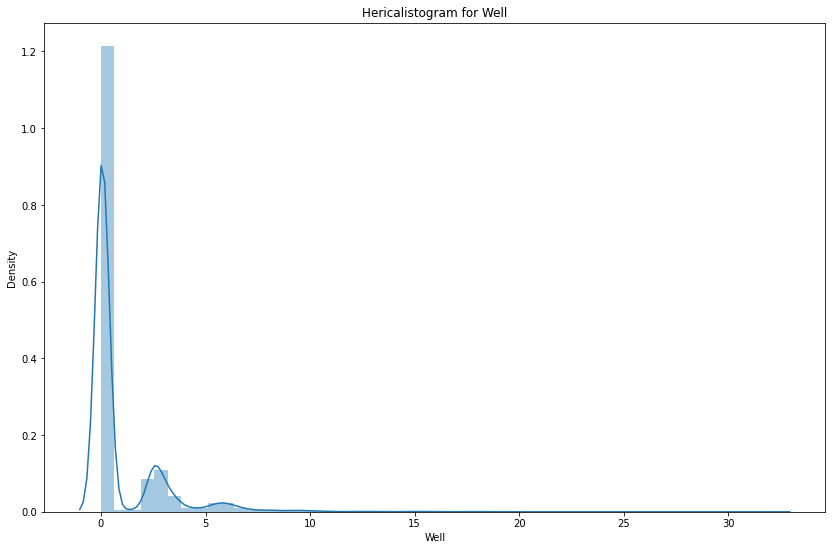

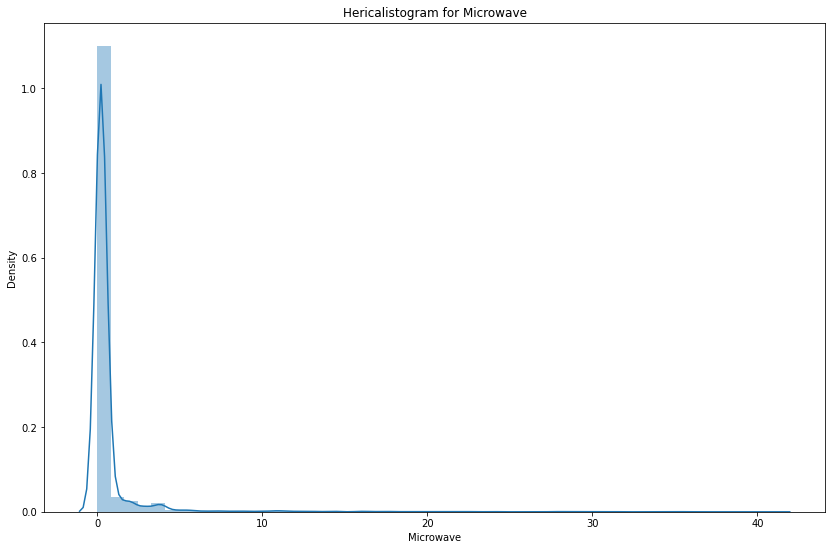

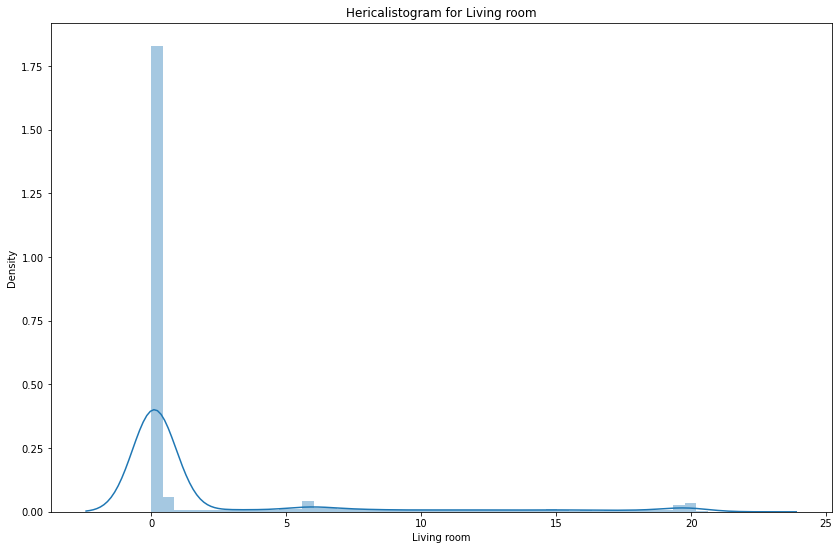

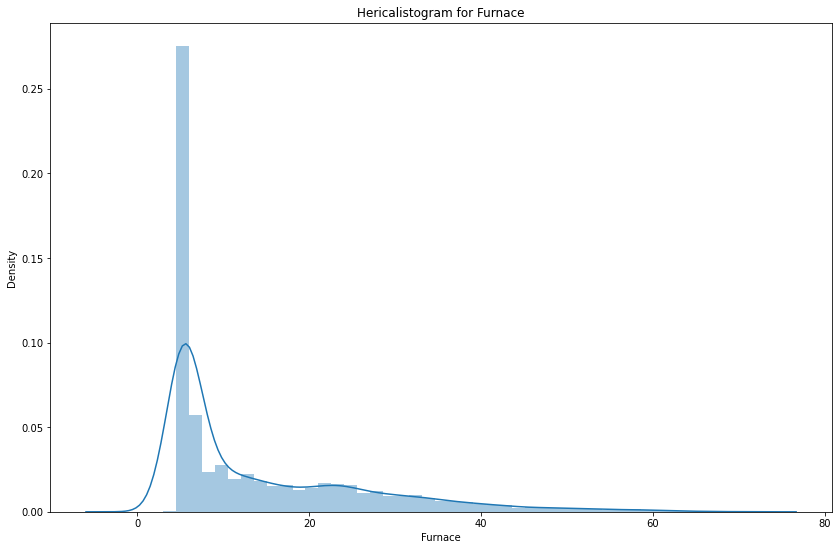

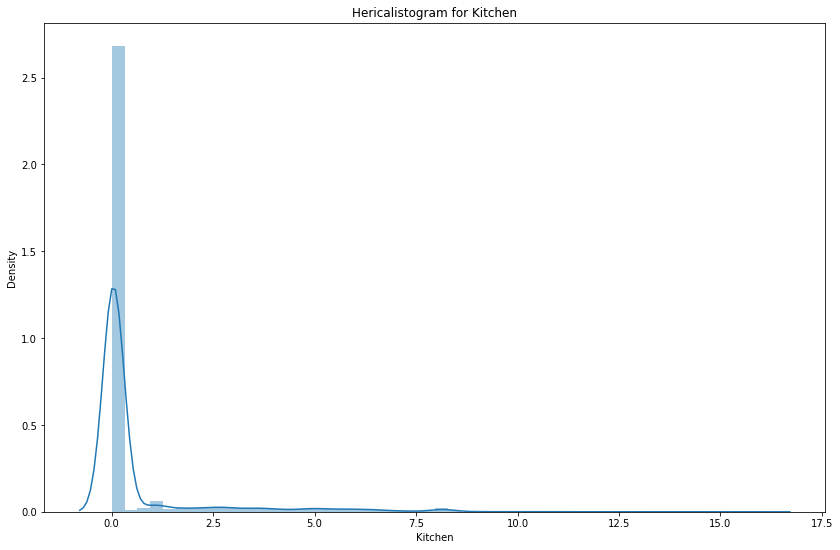

In [128]:
#Distribution of energy per hour showing the kernel density
for feature in energy_per_hour:
  sns.distplot(energy_per_hour[feature], kde=True)
  plt.title('Hericalistogram for {}'.format(feature))
  plt.show()

**Inference- Most of the columns seems to be right skewed **

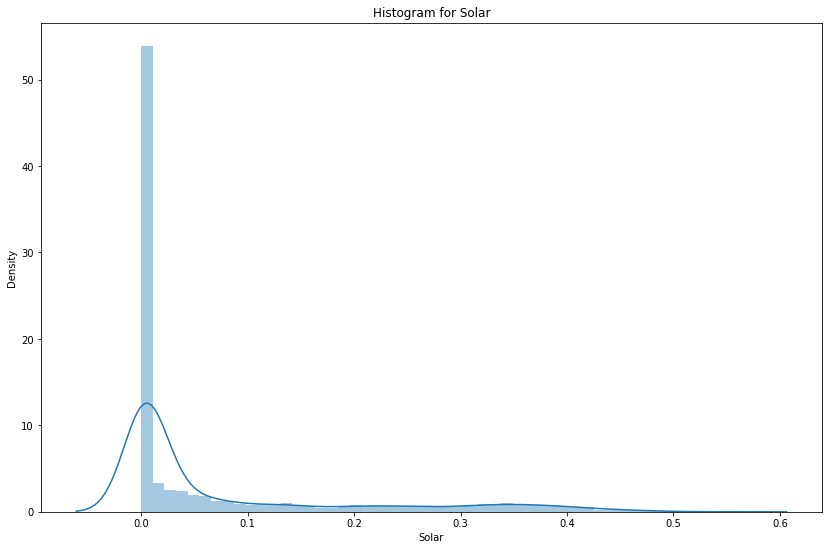

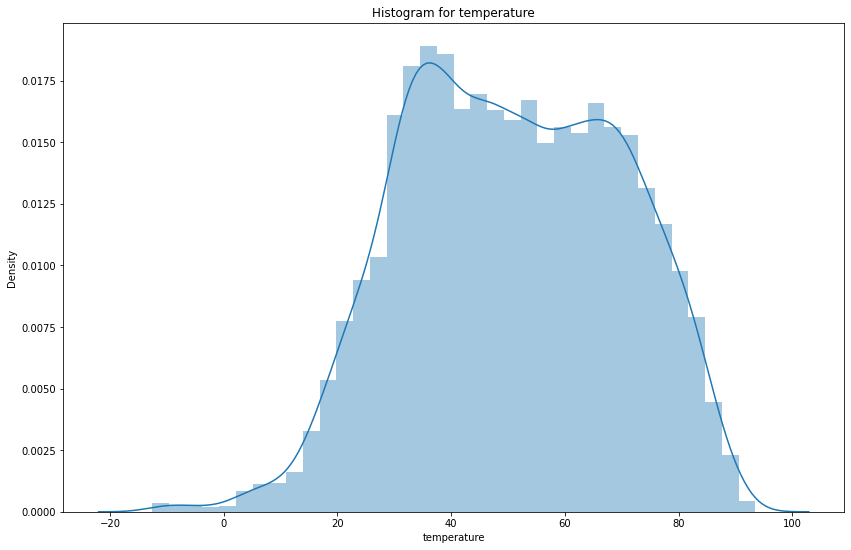

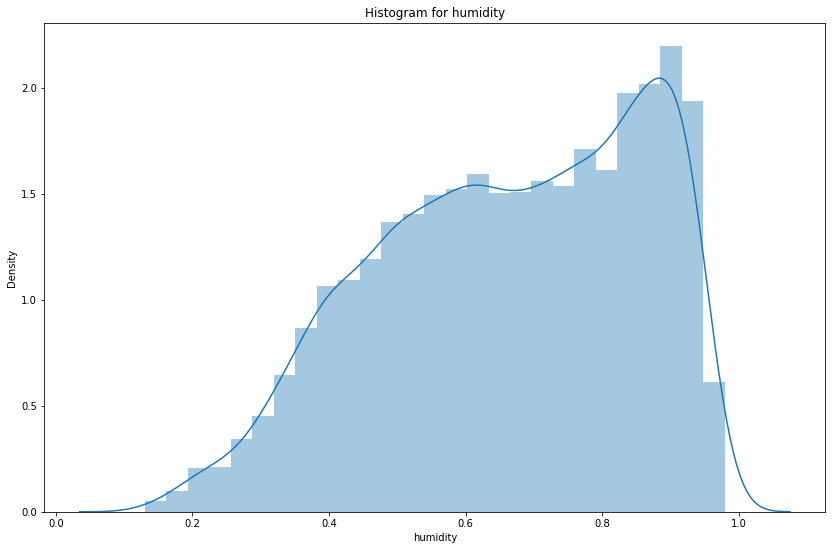

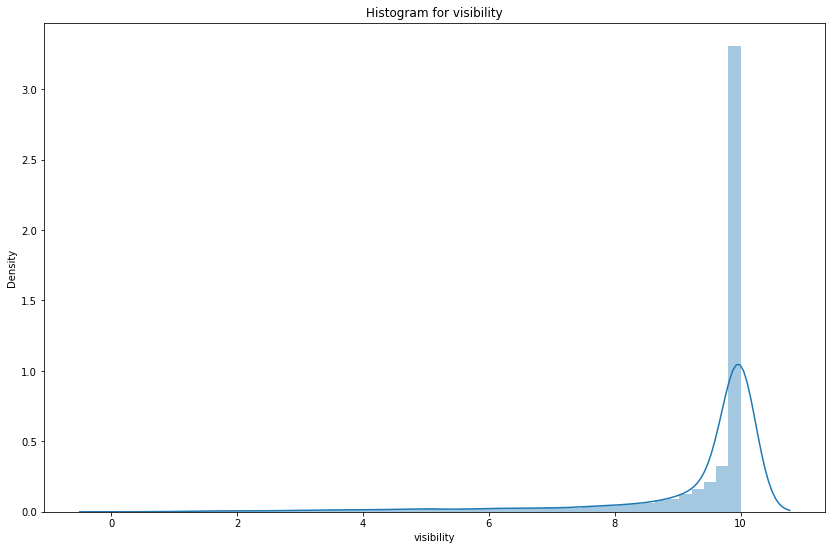

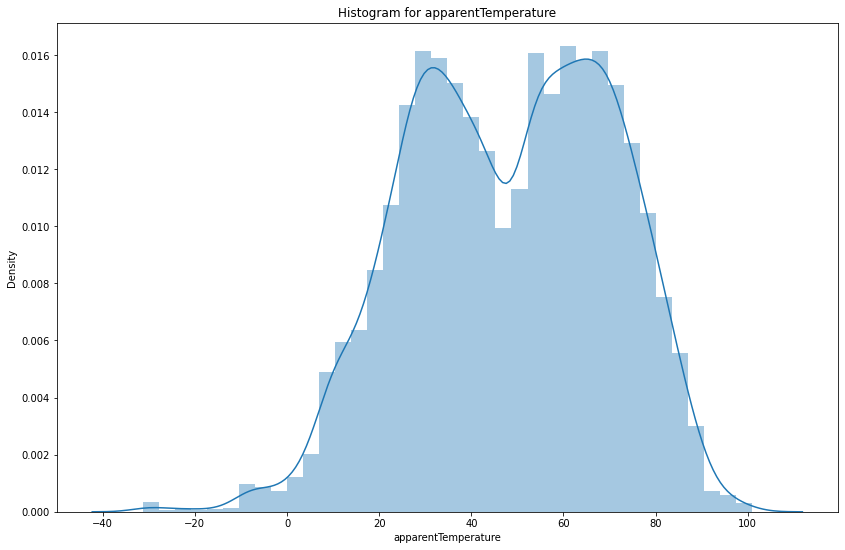

...

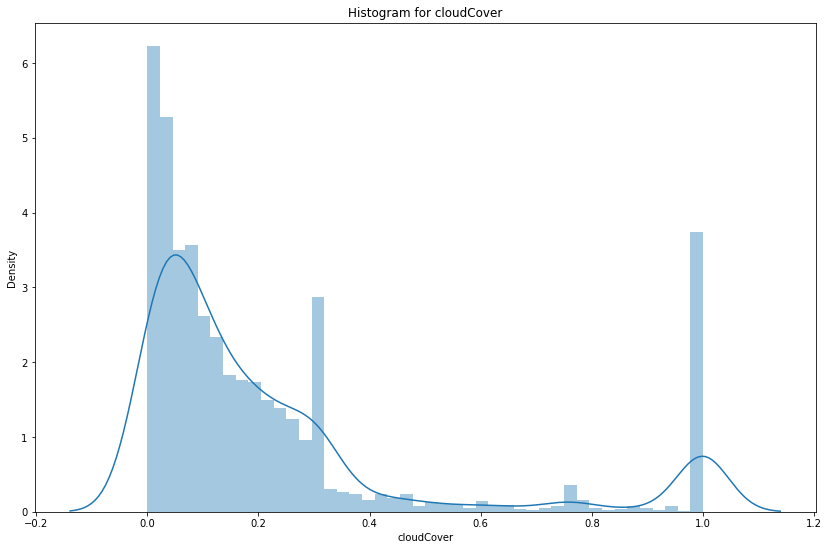

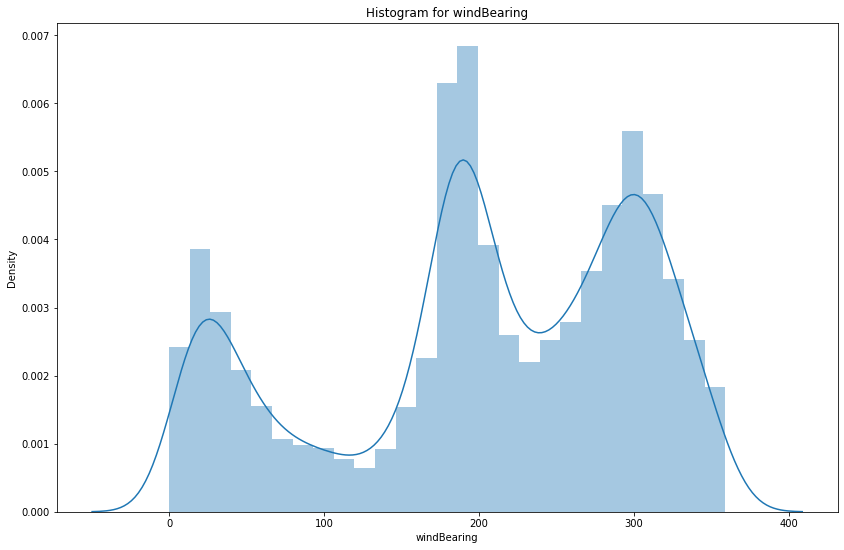

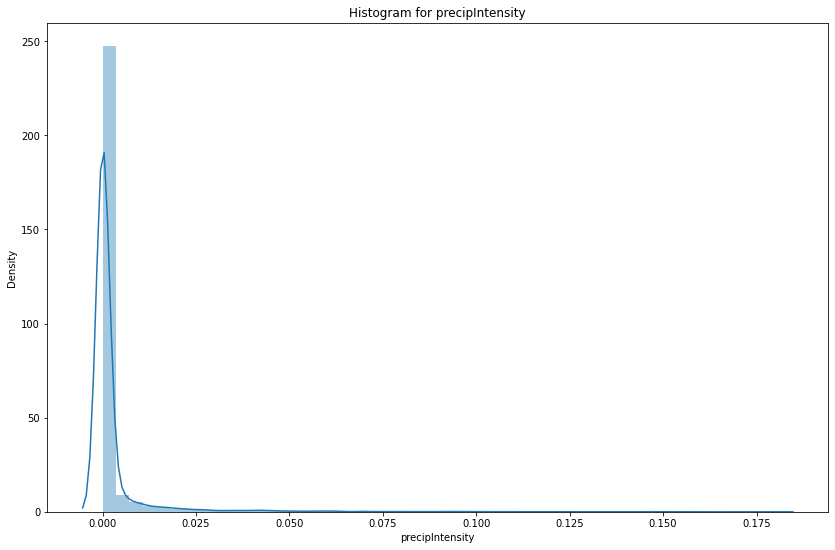

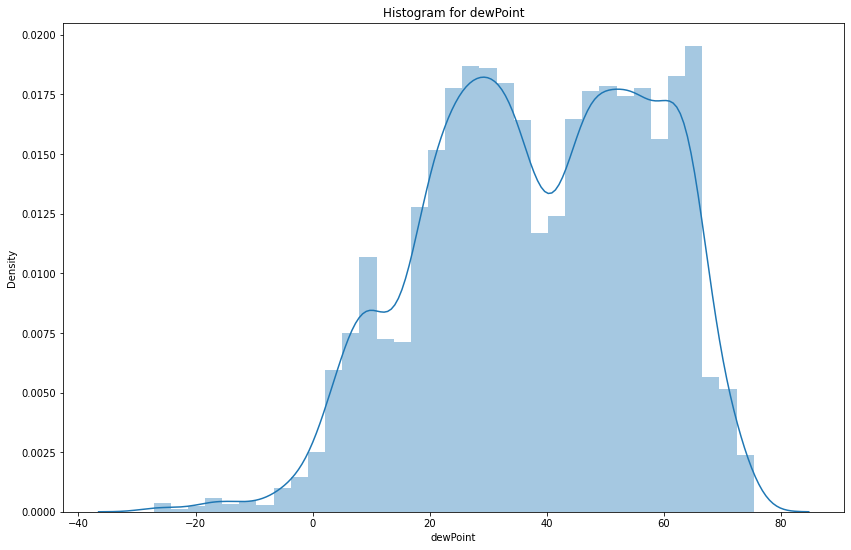

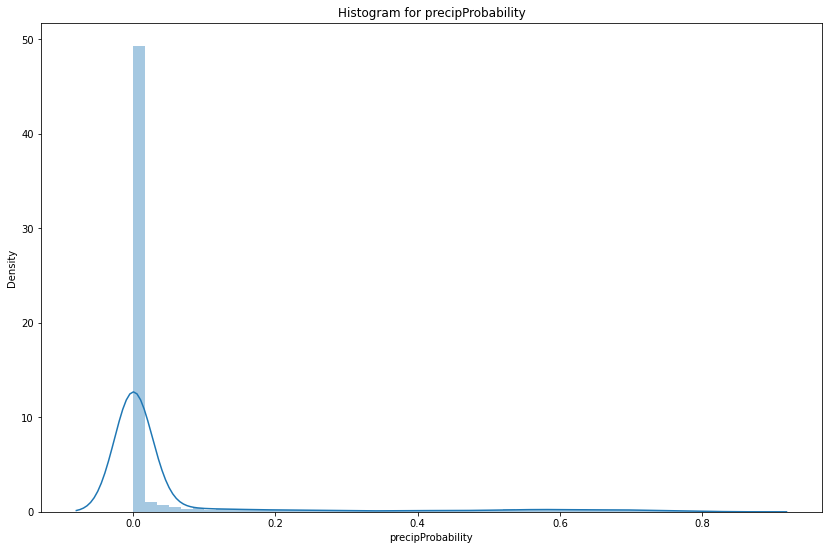

In [129]:
for feature in weather_data:  
  sns.distplot(weather_per_hour[feature], kde=True)
  plt.title('Histogram for {}'.format(feature))
  plt.show()

solar, winspeed, cloudcover,precipintensity and preciprobability seem to be right skewed 

left skewed is humidity, pressure and dewpoint.

More or less normaly distributedare- temperature, apparent temperature and apparent temperature







In [130]:
weather_per_hour.skew()

Solar                  1.656858
temperature           -0.086616
humidity              -0.357622
visibility            -2.796324
apparentTemperature   -0.207651
pressure              -0.179318
windSpeed              0.925340
cloudCover             1.856251
windBearing           -0.511308
precipIntensity        7.287962
dewPoint              -0.278095
precipProbability      3.059458
dtype: float64


**Null Value Handling**



In [131]:
data.isna().sum()

time                       0
House overall              0
Dishwasher                 0
Home office                0
Fridge                     0
Wine cellar                0
Garage door                0
Barn                       0
Well                       0
Microwave                  0
Living room                0
Solar                      0
temperature                0
icon                    6465
humidity                   0
visibility                 0
summary                    0
apparentTemperature    12894
pressure                   0
windSpeed                  0
cloudCover                 0
windBearing                0
precipIntensity            0
dewPoint                   0
precipProbability          0
Furnace                    0
Kitchen                    0
year                       0
month                      0
day                        0
hour                       0
minute                     0
timing                     0
season                     0
dtype: int64

### **Using mode and Median to fill null values for categorical and numerical variable respectively**

In [132]:

data['icon'].fillna(data['icon'].mode()[0],inplace=True)

data['apparentTemperature'].fillna(data['apparentTemperature'].median(),inplace=True)

In [133]:
data.isna().sum()

time                   0
House overall          0
Dishwasher             0
Home office            0
Fridge                 0
Wine cellar            0
Garage door            0
Barn                   0
Well                   0
Microwave              0
Living room            0
Solar                  0
temperature            0
icon                   0
humidity               0
visibility             0
summary                0
apparentTemperature    0
pressure               0
windSpeed              0
cloudCover             0
windBearing            0
precipIntensity        0
dewPoint               0
precipProbability      0
Furnace                0
Kitchen                0
year                   0
month                  0
day                    0
hour                   0
minute                 0
timing                 0
season                 0
dtype: int64

In [134]:
data.columns

Index(['time', 'House overall', 'Dishwasher', 'Home office', 'Fridge',
       'Wine cellar', 'Garage door', 'Barn', 'Well', 'Microwave',
       'Living room', 'Solar', 'temperature', 'icon', 'humidity', 'visibility',
       'summary', 'apparentTemperature', 'pressure', 'windSpeed', 'cloudCover',
       'windBearing', 'precipIntensity', 'dewPoint', 'precipProbability',
       'Furnace', 'Kitchen', 'year', 'month', 'day', 'hour', 'minute',
       'timing', 'season'],
      dtype='object')

**Label encoding categorical column**

In [135]:
from sklearn.preprocessing import LabelEncoder

le=LabelEncoder()#le has operations for label encoding


data['summary']=le.fit_transform(data['summary'])

#### **Again taking energy per hour and weather per hour after filling null values, then resampling and concating into data per hour**

In [136]:
energy_data1 = data[['House overall', 'Dishwasher', 'Home office',
       'Fridge', 'Wine cellar', 'Garage door', 'Barn', 'Well', 'Microwave',
       'Living room','Solar', 'Furnace','Kitchen']]

In [137]:
weather_data1 = data[['temperature', 'humidity', 'visibility', 'apparentTemperature',
       'pressure', 'windSpeed', 'cloudCover', 'windBearing', 'precipIntensity',
       'dewPoint', 'precipProbability']]

In [138]:
energy_data1.index = pd.to_datetime(energy_data.index)
weather_data1.index = pd.to_datetime(weather_data.index)

In [139]:
energy_data1 = energy_data1.set_index(data['time'])

In [140]:
energy_per_hour1 = energy_data1.resample('H').sum()

In [141]:
weather_data1 = weather_data1.set_index(data['time'])

In [142]:
weather_per_hour1 = weather_data1.resample('H').mean()

In [143]:
data_per_hour= pd.concat([energy_per_hour1, weather_per_hour1],axis=1)

In [144]:
data_per_hour

,House overall,Dishwasher,Home office,Fridge,Wine cellar,Garage door,Barn,Well,Microwave,Living room,Solar,Furnace,Kitchen,temperature,humidity,visibility,apparentTemperature,pressure,windSpeed,cloudCover,windBearing,precipIntensity,dewPoint,precipProbability
time,,,,,,,,,,,,,,,,,,,,,,,,
2016-01-01 05:00:00,62.647783,0.003817,14.508850,2.271667,3.801033,0.782767,2.332833,0.062533,1.299100,0.090283,0.198417,23.591283,0.049234,36.131000,0.619667,10.000000,29.615000,1016.888000,9.150333,0.750,282.100000,0.000000,24.383333,0.000
2016-01-01 06:00:00,55.090017,0.005950,2.597617,4.531317,6.776500,0.770167,2.350883,0.061250,0.252967,0.097083,0.205300,27.402450,0.044917,35.838667,0.610000,10.000000,30.069500,1016.232000,8.284000,0.750,284.733333,0.000000,23.866000,0.000
2016-01-01 07:00:00,42.884167,0.002550,2.604967,3.569133,0.431050,0.797917,2.066350,0.060833,0.254733,0.097717,0.206900,22.330200,0.043584,35.385000,0.613000,10.000000,29.747667,1015.989000,7.927000,0.750,279.400000,0.000000,23.469000,0.000
2016-01-01 08:00:00,57.600767,0.008300,3.900833,3.624717,0.422683,0.775517,2.051700,0.060983,0.256450,0.098067,0.206850,36.982217,0.048334,35.282000,0.640000,10.000000,31.398167,1016.042000,5.684667,0.750,265.000000,0.000000,24.202667,0.000
2016-01-01 09:00:00,38.390183,0.003617,2.603500,2.106350,0.428567,0.793200,1.909783,0.060817,0.255467,0.099000,0.206350,20.630550,0.047751,35.451667,0.641667,10.000000,30.704833,1015.815000,6.975000,0.625,265.500000,0.000000,24.423333,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2016-12-15 23:00:00,65.819917,0.004500,2.511183,2.654150,0.487117,0.768850,1.934933,0.059550,0.185067,0.075633,0.248250,46.348000,0.043901,36.990000,0.712000,9.380000,29.392667,1012.775333,11.183333,0.816,189.666667,0.000373,28.414667,0.008
2016-12-16 00:00:00,76.595083,0.003568,2.502683,3.029500,6.332783,0.751583,1.854133,2.431317,0.180050,0.074133,0.246533,47.760350,0.038351,37.584167,0.721667,8.855333,29.813667,1012.628500,11.969500,0.310,197.633333,0.004313,29.379167,0.182
2016-12-16 01:00:00,75.613833,0.006000,2.515267,2.948417,7.388033,0.764567,1.919517,0.059950,0.186267,0.076550,0.248483,49.405067,0.045967,36.429333,0.801000,8.576333,28.988000,1012.129667,10.720667,0.310,197.900000,0.010600,30.864333,0.510


In [145]:
data_per_hour.columns

Index(['House overall', 'Dishwasher', 'Home office', 'Fridge', 'Wine cellar',
       'Garage door', 'Barn', 'Well', 'Microwave', 'Living room', 'Solar',
       'Furnace', 'Kitchen', 'temperature', 'humidity', 'visibility',
       'apparentTemperature', 'pressure', 'windSpeed', 'cloudCover',
       'windBearing', 'precipIntensity', 'dewPoint', 'precipProbability'],
      dtype='object')

## **Correlation Table Weather data and Energy Data**

In [146]:
consumptions = energy_per_hour1.columns.tolist()
weather = weather_per_hour1.columns.tolist()
lists = [consumptions,]
for j in weather_per_hour1:
  correlations = []
  for i in energy_per_hour1:
    cor = data[i].corr(data[j])
    correlations.append(cor)
  lists.append(correlations)

names=['consumptions',]
for i in weather:
  names.append(i+'_corr')
data_corr = pd.DataFrame(np.column_stack(lists), columns=names).set_index('consumptions')

for i in data_corr.columns[:].tolist():
  data_corr[i] = data_corr[i].apply(float)

In [147]:
#Highlight correlations between energy and weather (red for corr > 0.1, orange for corr < -0.1)
data_corr.style.applymap(lambda x: "background-color: red" if x > 0.1 else "background-color: orange" if x < -0.1 else "background-color: white")

,temperature_corr,humidity_corr,visibility_corr,apparentTemperature_corr,pressure_corr,windSpeed_corr,cloudCover_corr,windBearing_corr,precipIntensity_corr,dewPoint_corr,precipProbability_corr
consumptions,,,,,,,,,,,
House overall,0.010379,0.011511,-0.002609,0.003587,0.010730,-0.003853,-0.033460,0.011183,0.024836,0.016040,-0.003317
Dishwasher,-0.015716,-0.001868,-0.008064,-0.014559,0.000211,-0.001672,-0.002395,0.004016,0.006265,-0.016099,0.008189
Home office,0.011908,-0.006008,0.020638,0.009820,0.027091,-0.017898,-0.039897,0.012427,-0.029890,0.007594,-0.032861
Fridge,0.107466,0.030749,0.009019,0.105883,-0.000517,-0.024886,-0.023490,-0.008589,0.014253,0.115169,0.004794
Wine cellar,0.289168,0.055541,0.030095,0.284066,0.018494,-0.052860,-0.040467,-0.025930,0.016588,0.298207,0.006571
Garage door,0.013511,-0.007399,0.002262,0.010961,-0.000276,0.000419,-0.007457,0.012327,-0.006941,0.008350,-0.006639
Barn,-0.017188,-0.002141,0.008376,-0.015586,0.011716,-0.015196,-0.011635,0.006255,-0.007258,-0.016738,-0.006063
Well,-0.004691,-0.006590,-0.001069,-0.004666,0.002994,0.000677,-0.003029,0.004085,-0.004377,-0.007346,-0.002788
Microwave,0.001369,0.012541,-0.018359,0.002374,-0.001248,-0.006129,0.009580,-0.006218,0.026936,0.006286,0.016222


Fridge is correlated with temperature and apparent temperature and dewpoint.

Wine cellar is also correlated with temperature , apparent temperature and dewpoint

Furnace is positively correlated with windspeed and is negatively correlated with temperature, apparent temperature and dew point

## **Correlation matrix of Weather related columns and target**





<Axes: >

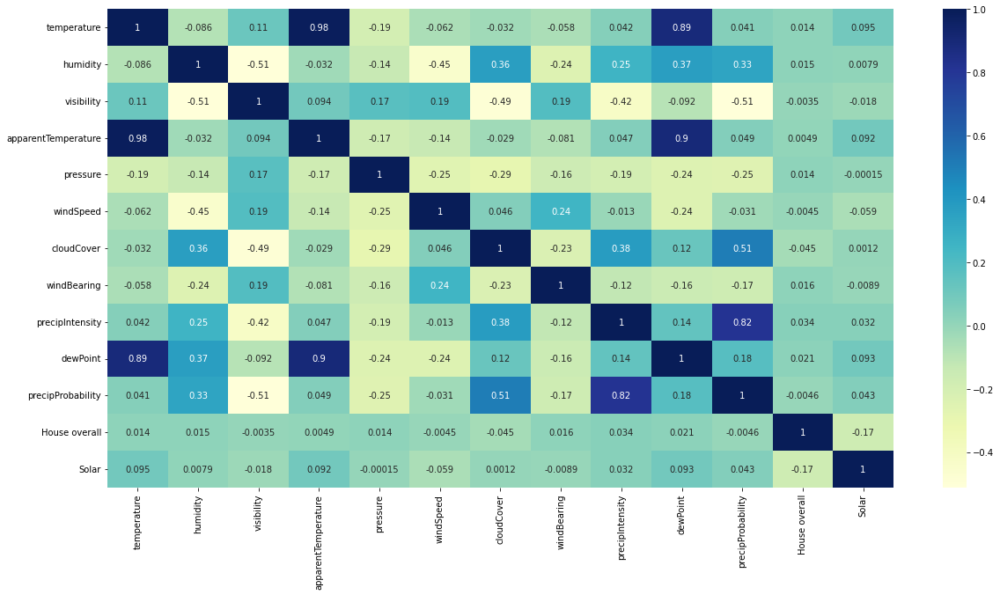

In [148]:
dfw = pd.concat([weather_per_hour1[['temperature', 'humidity', 'visibility', 'apparentTemperature','pressure', 'windSpeed', 'cloudCover', 'windBearing', 'precipIntensity','dewPoint','precipProbability']],energy_per_hour1[['House overall','Solar']]],axis=1)
corrmatrix = dfw.corr()
plt.subplots(figsize=(20,10))
sns.heatmap(corrmatrix,annot=True,cmap = 'YlGnBu')

From the correlation matrix we can see that there is no much corrrelation between the weather parameters and our target.

**Here the target variable has no much relation with Visibility,Apparent Temperature,windspeed,Precipintensity preciprobability . Hence we may drop it.**


**Also apparent temperature is very highly correlated with temperature.So we are keeping temperature and dropping apparent temperature.**

**Also Preciprobability is very highly correlated with precipintensity and it has no correl;ation with House overall so we are dropping it .**

## **Correlation matrix of Energy data and target**

<Axes: >

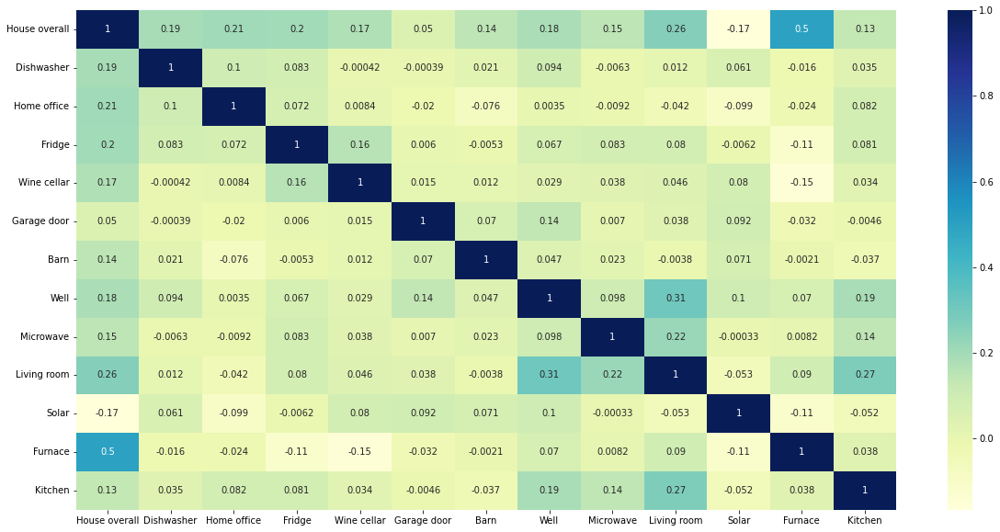

In [149]:
dfe= data_per_hour[['House overall','Dishwasher', 'Home office','Fridge', 'Wine cellar', 'Garage door', 'Barn', 'Well', 'Microwave','Living room','Solar', 'Furnace','Kitchen']]
corrmatrix = dfe.corr()
plt.subplots(figsize=(20,10))
sns.heatmap(corrmatrix,annot=True,cmap = 'YlGnBu')

Furnace seems to be  most correlated with house overall.

Living room and well are correlated with each other.

In [150]:
# based on the correlation matrices above we are dropping the following columns
data_per_hour = data_per_hour.drop(['apparentTemperature','precipProbability','visibility',
       'cloudCover', 'windBearing', 'precipIntensity'],axis=1)

In [151]:
data_per_hour.columns

Index(['House overall', 'Dishwasher', 'Home office', 'Fridge', 'Wine cellar',
       'Garage door', 'Barn', 'Well', 'Microwave', 'Living room', 'Solar',
       'Furnace', 'Kitchen', 'temperature', 'humidity', 'pressure',
       'windSpeed', 'dewPoint'],
      dtype='object')

In [152]:
numerical=[features for features in data_per_hour.columns if data_per_hour[features].dtypes!="O"]

## Outlier detection

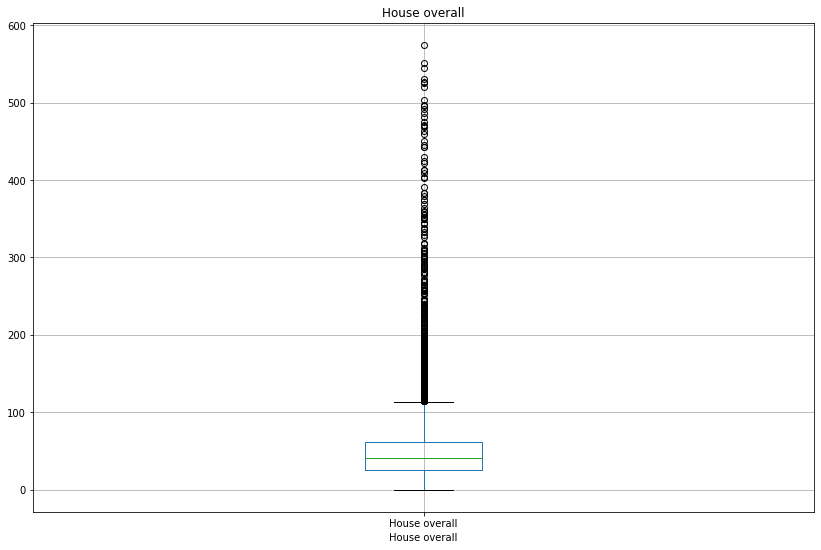

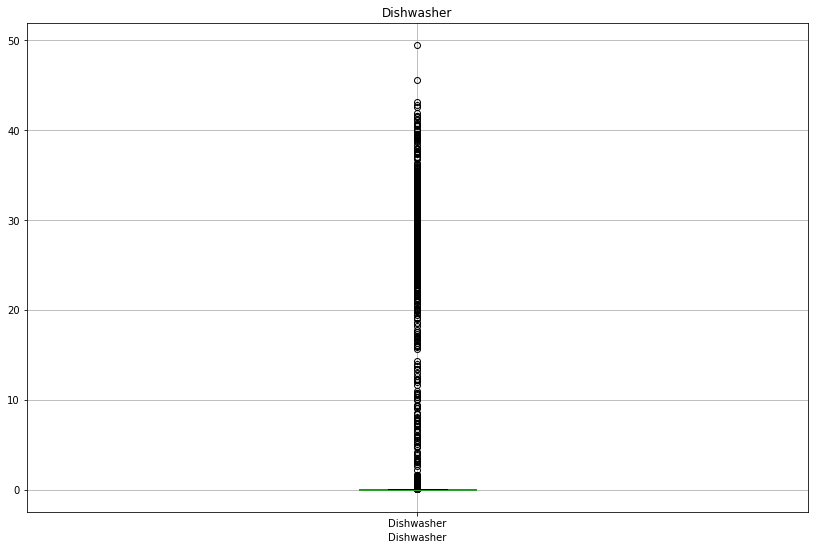

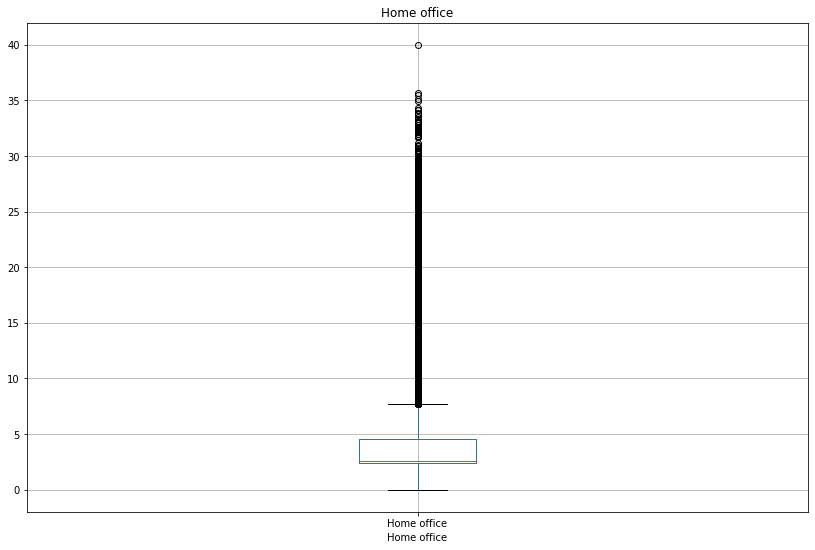

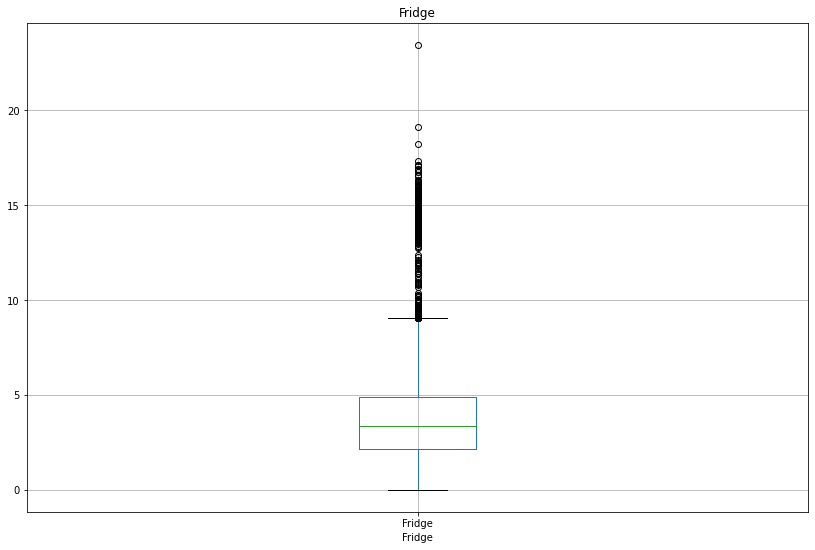

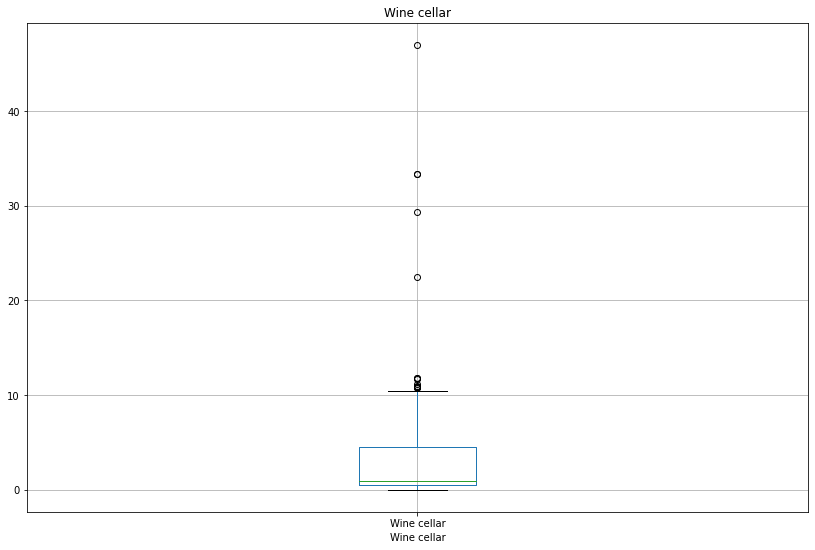

...

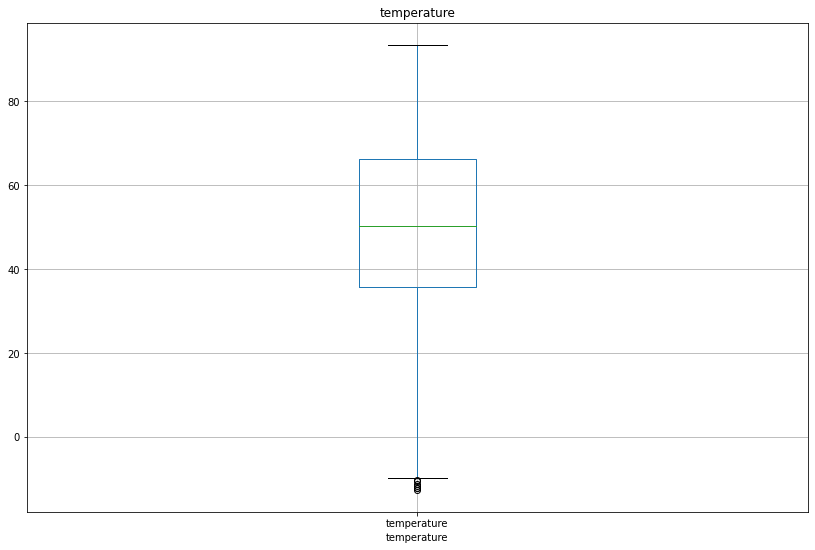

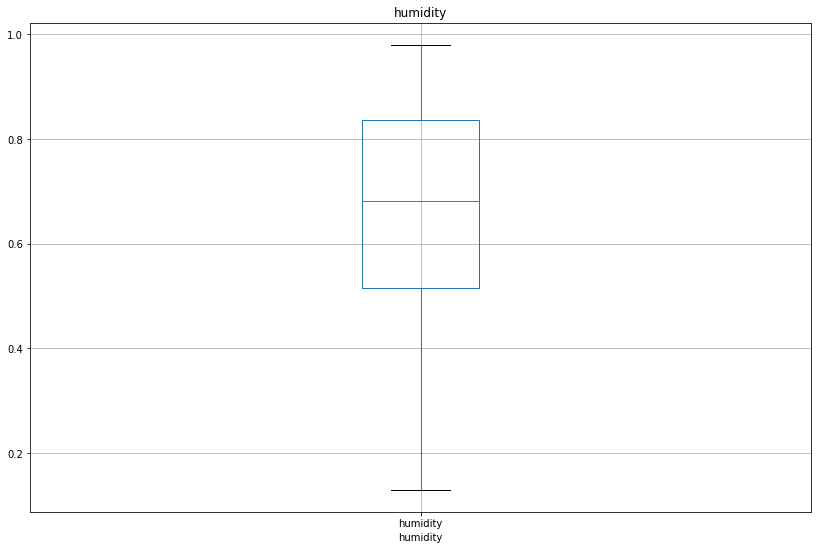

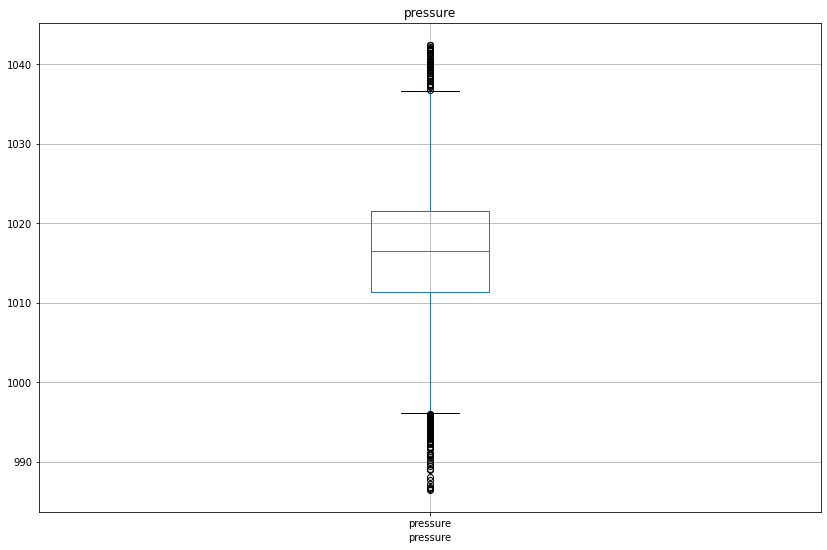

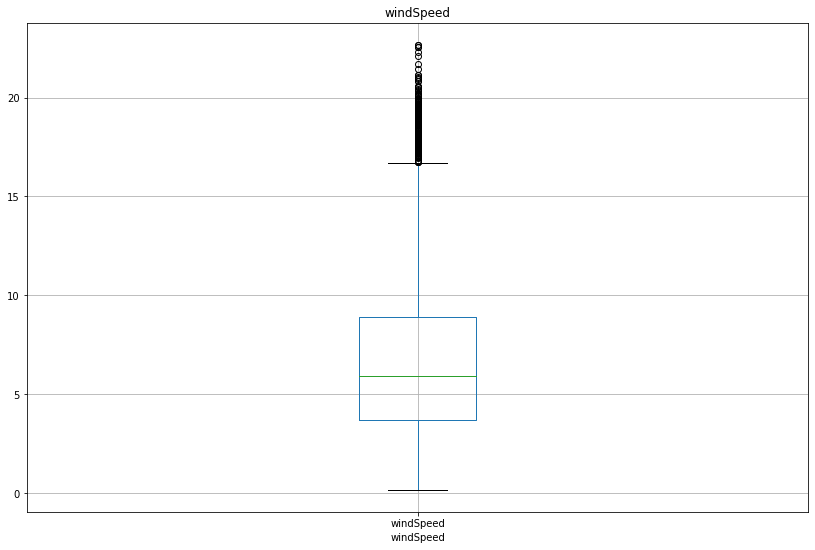

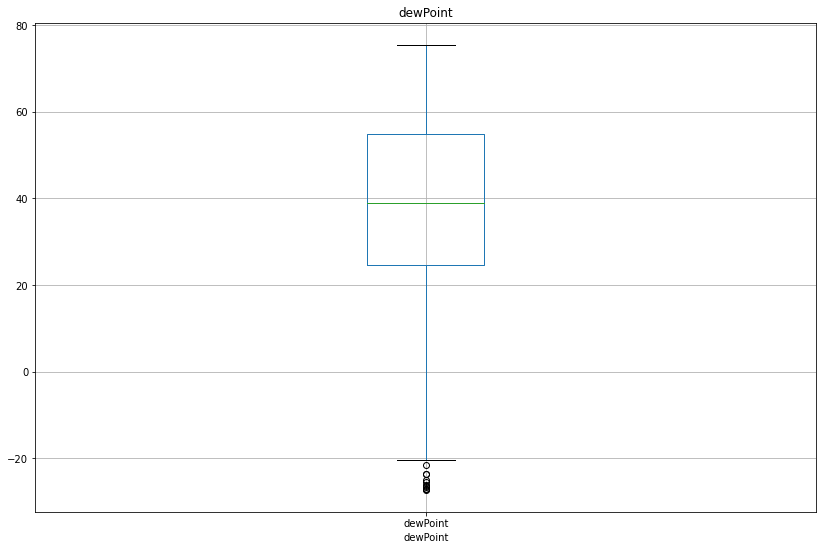

In [153]:
for feature in numerical:
  data_per_hour.boxplot(column= feature )
  plt.xlabel(feature)
  plt.title(feature)
  plt.show()

In [154]:
def find_outliers_IQR(data_per_hour):
    q1=data_per_hour.quantile(0.25)
    q3=data_per_hour.quantile(0.75)
    IQR=q3-q1
    outliers = data_per_hour[((data_per_hour<(q1-1.5*IQR)) | (data_per_hour>(q3+1.5*IQR)))]
    
    return outliers

for feature in numerical:
    outliers = find_outliers_IQR(data_per_hour[feature])

    print(feature)
    print('number of outliers: '+ str(len(outliers)))
    print('max outlier value: '+ str(outliers.max()))
    print('min outlier value: '+ str(outliers.min()))
    print('% of outliers: '+ str(len(outliers)/(len(data_per_hour[feature]))*100))
    print('\n')




House overall
number of outliers: 458
max outlier value: 574.811066651
min outlier value: 114.006366665
% of outliers: 5.453030122633646


Dishwasher
number of outliers: 761
max outlier value: 49.475366667
min outlier value: 0.025650001
% of outliers: 9.060602452672937


Home office
number of outliers: 933
max outlier value: 39.994233333
min outlier value: 7.692966666
% of outliers: 11.10846529348732


Fridge
number of outliers: 250
max outlier value: 23.459183333
min outlier value: 9.037066665
% of outliers: 2.976544826765091


Wine cellar
number of outliers: 15
max outlier value: 46.992566665
min outlier value: 10.770166666
% of outliers: 0.17859268960590546


Garage door
number of outliers: 1450
max outlier value: 17.666049995999998
min outlier value: 0.003
% of outliers: 17.263959995237528


Barn
number of outliers: 1040
max outlier value: 108.78628333099999
min outlier value: 0.004998000000000001
% of outliers: 12.38242647934278


Well
number of outliers: 2035
max outlier value: 3

Outlier Detection by Season

In [155]:
data_outlier=data_per_hour.copy()

In [156]:
data_outlier.columns

Index(['House overall', 'Dishwasher', 'Home office', 'Fridge', 'Wine cellar',
       'Garage door', 'Barn', 'Well', 'Microwave', 'Living room', 'Solar',
       'Furnace', 'Kitchen', 'temperature', 'humidity', 'pressure',
       'windSpeed', 'dewPoint'],
      dtype='object')

In [157]:
data_outlier.reset_index(inplace=True)

In [158]:
def Season(month):
  if month in [1,2,3]:
    season = 'Winter'
  elif month in [4,5,6]:
     season = 'Spring'

  elif month in [7,8,9]:
     season = 'Summer' 
  elif month in [10,11,12]:
    season = 'Autumn'

  else:
    season='X'

  return season  

In [159]:
data_outlier['year'] = data_outlier['time'].apply(lambda x:x.year)
data_outlier['month'] = data_outlier['time'].apply(lambda x:x.month)
data_outlier['day'] = data_outlier['time'].apply(lambda x:x.day)

data_outlier['hour'] = data_outlier['time'].apply(lambda x:x.hour)
data_outlier['minute'] = data_outlier['time'].apply(lambda x:x.minute)

In [160]:
data_outlier['season'] = data_outlier['month'].apply(Season)

In [161]:
data_outlier

,time,House overall,Dishwasher,Home office,Fridge,Wine cellar,Garage door,Barn,Well,Microwave,Living room,Solar,Furnace,Kitchen,temperature,humidity,pressure,windSpeed,dewPoint,year,month,day,hour,minute,season
0,2016-01-01 05:00:00,62.647783,0.003817,14.508850,2.271667,3.801033,0.782767,2.332833,0.062533,1.299100,0.090283,0.198417,23.591283,0.049234,36.131000,0.619667,1016.888000,9.150333,24.383333,2016,1,1,5,0,Winter
1,2016-01-01 06:00:00,55.090017,0.005950,2.597617,4.531317,6.776500,0.770167,2.350883,0.061250,0.252967,0.097083,0.205300,27.402450,0.044917,35.838667,0.610000,1016.232000,8.284000,23.866000,2016,1,1,6,0,Winter
2,2016-01-01 07:00:00,42.884167,0.002550,2.604967,3.569133,0.431050,0.797917,2.066350,0.060833,0.254733,0.097717,0.206900,22.330200,0.043584,35.385000,0.613000,1015.989000,7.927000,23.469000,2016,1,1,7,0,Winter
3,2016-01-01 08:00:00,57.600767,0.008300,3.900833,3.624717,0.422683,0.775517,2.051700,0.060983,0.256450,0.098067,0.206850,36.982217,0.048334,35.282000,0.640000,1016.042000,5.684667,24.202667,2016,1,1,8,0,Winter
4,2016-01-01 09:00:00,38.390183,0.003617,2.603500,2.106350,0.428567,0.793200,1.909783,0.060817,0.255467,0.099000,0.206350,20.630550,0.047751,35.451667,0.641667,1015.815000,6.975000,24.423333,2016,1,1,9,0,Winter
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8394,2016-12-15 23:00:00,65.819917,0.004500,2.511183,2.654150,0.487117,0.768850,1.934933,0.059550,0.185067,0.075633,0.248250,46.348000,0.043901,36.990000,0.712000,1012.775333,11.183333,28.414667,2016,12,15,23,0,Autumn
8395,2016-12-16 00:00:00,76.595083,0.003568,2.502683,3.029500,6.332783,0.751583,1.854133,2.431317,0.180050,0.074133,0.246533,47.760350,0.038351,37.584167,0.721667,1012.628500,11.969500,29.379167,2016,12,16,0,0,Autumn
8396,2016-12-16 01:00:00,75.613833,0.006000,2.515267,2.948417,7.388033,0.764567,1.919517,0.059950,0.186267,0.076550,0.248483,49.405067,0.045967,36.429333,0.801000,1012.129667,10.720667,30.864333,2016,12,16,1,0,Autumn
8397,2016-12-16 02:00:00,66.021450,0.005117,2.513983,3.003783,3.944967,0.777433,1.900783,0.059600,0.186633,0.076183,0.249867,42.402033,0.044034,35.580833,0.836667,1011.711667,7.361667,31.118333,2016,12,16,2,0,Autumn


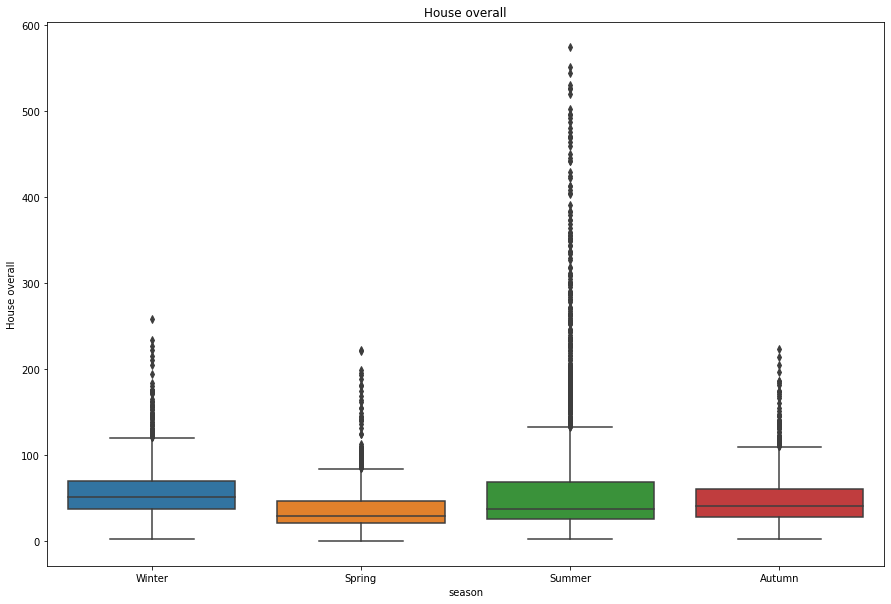

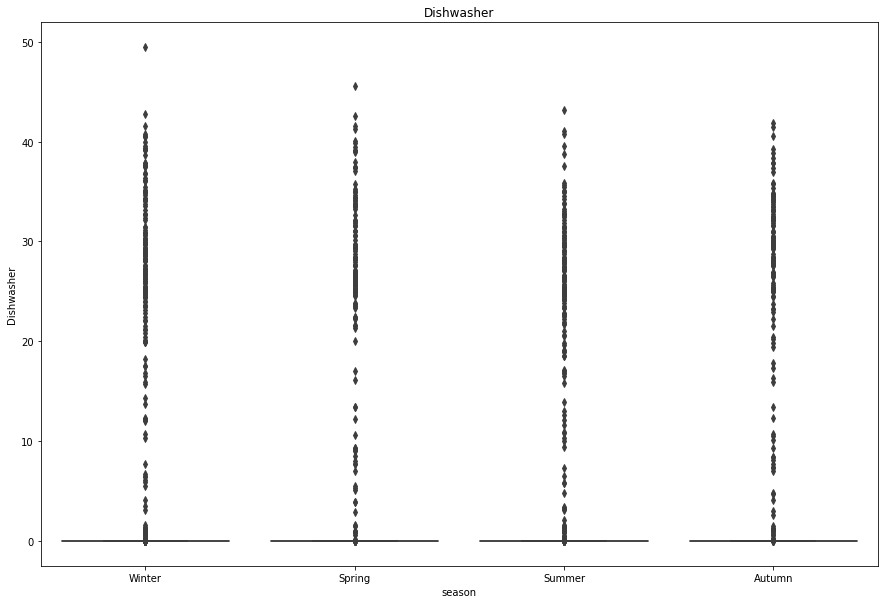

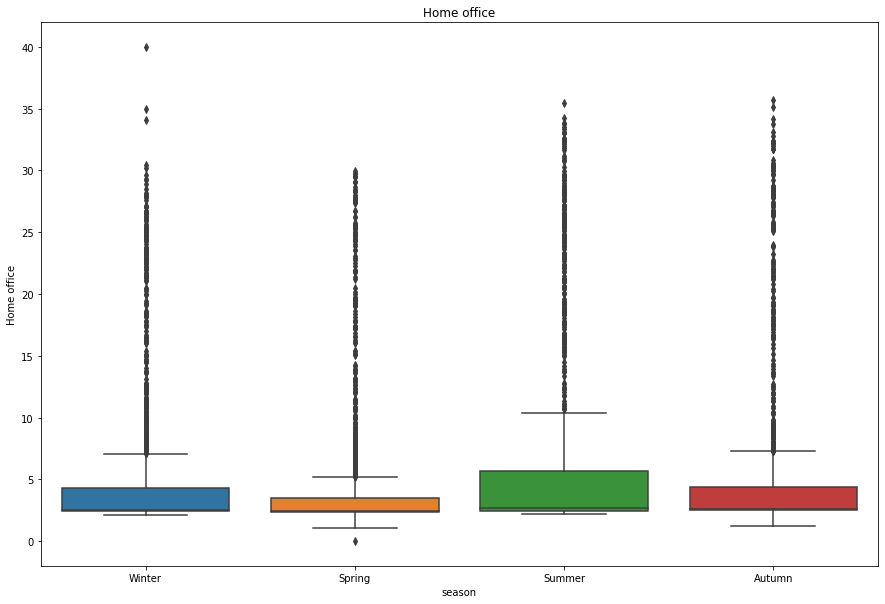

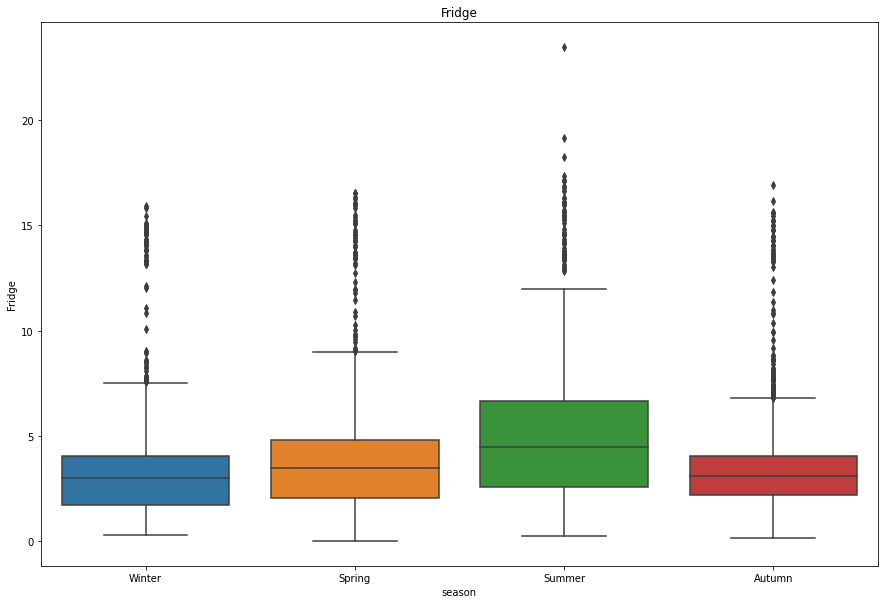

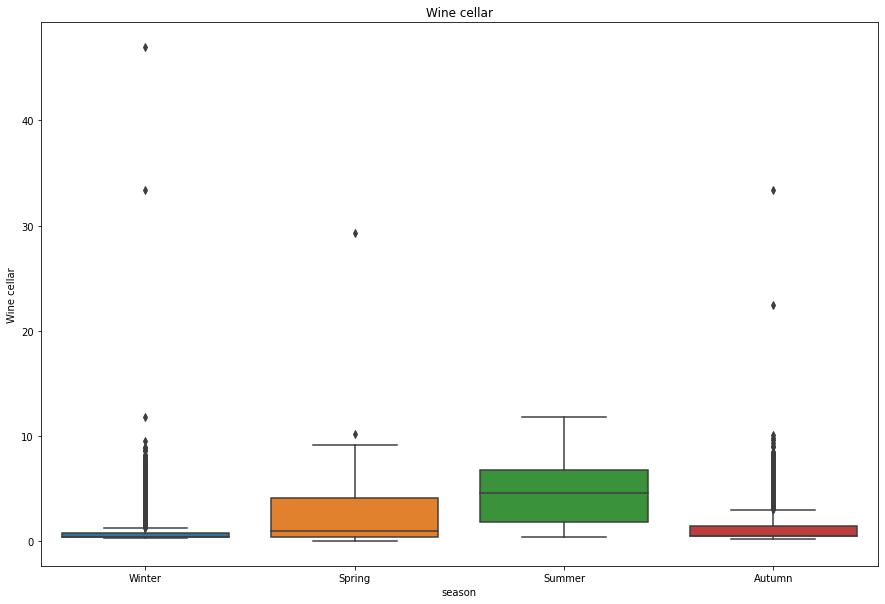

...

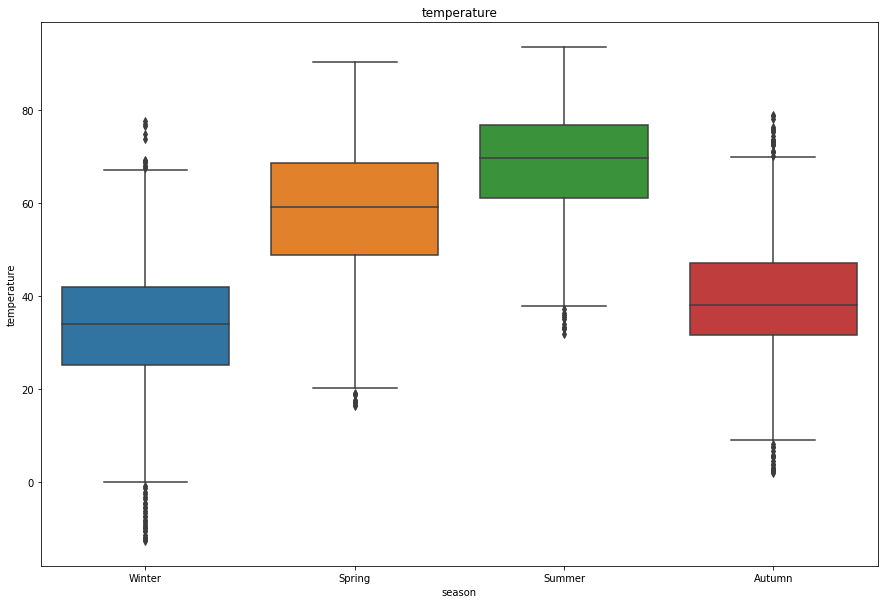

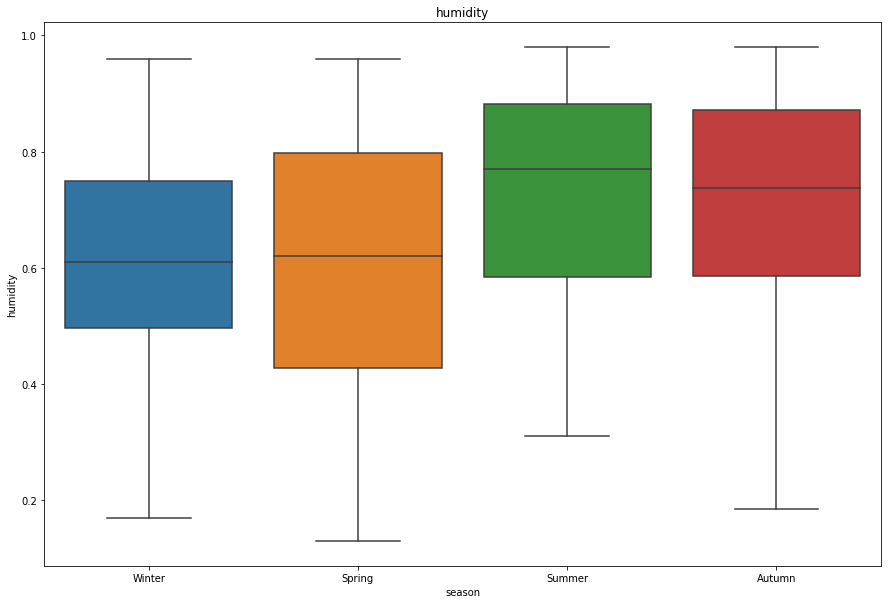

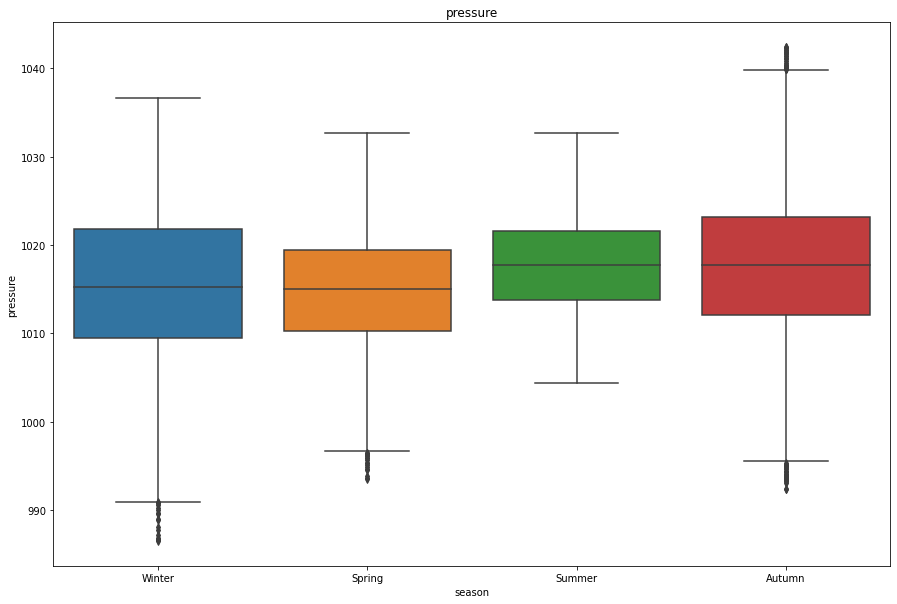

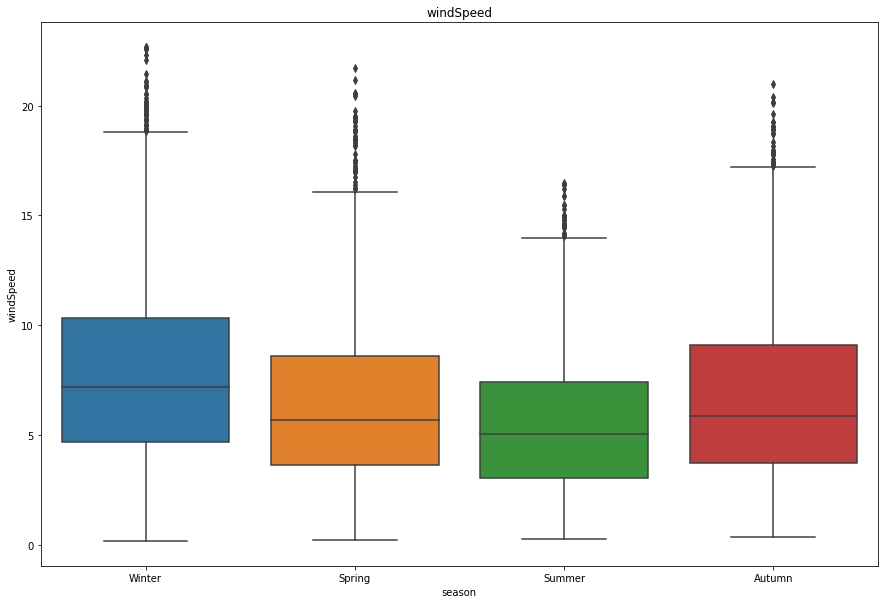

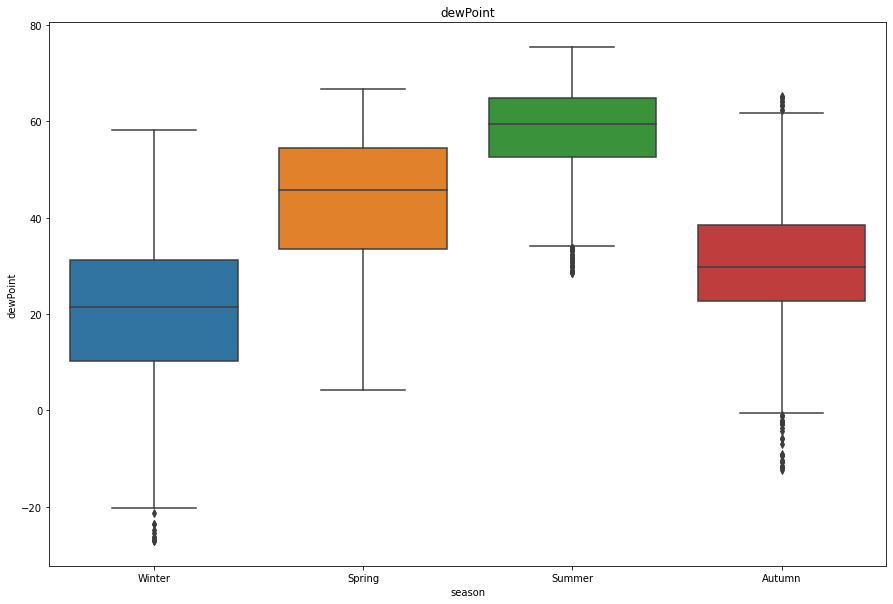

In [162]:
for feature in numerical:
    plt.figure(figsize=(15,10))
    sns.boxplot(x = 'season', y = feature, data = data_outlier)
    plt.title(feature)
    plt.show()
    


**Checking for Skewness**

In [163]:
numerical=[features for features in data_per_hour.columns if data_per_hour[features].dtypes!="O" ]


data_per_hour[numerical].agg(['skew', 'kurtosis']).transpose()

,skew,kurtosis
House overall,4.391533,29.006960
Dishwasher,3.795790,13.207983
Home office,3.126173,9.509382
Fridge,1.652709,4.752145
Wine cellar,1.845355,11.096470
Garage door,26.430662,1097.543926
Barn,6.141071,51.176363
Well,4.072585,29.069358
Microwave,8.752651,97.012878
Living room,2.527888,5.292486


Skewness in our data is within the range of -0.35 to 26

Kurtosis is within the range of -0.84 to 1097.54

## **Using Log and Box cox to transform data and bring down skewness**

In [164]:
numerical

['House overall',
 'Dishwasher',
 'Home office',
 'Fridge',
 'Wine cellar',
 'Garage door',
 'Barn',
 'Well',
 'Microwave',
 'Living room',
 'Solar',
 'Furnace',
 'Kitchen',
 'temperature',
 'humidity',
 'pressure',
 'windSpeed',
 'dewPoint']

In [165]:
df1=data_per_hour.copy()
df1.columns

Index(['House overall', 'Dishwasher', 'Home office', 'Fridge', 'Wine cellar',
       'Garage door', 'Barn', 'Well', 'Microwave', 'Living room', 'Solar',
       'Furnace', 'Kitchen', 'temperature', 'humidity', 'pressure',
       'windSpeed', 'dewPoint'],
      dtype='object')

In [166]:
for i in df1[[ 'Well', 'Microwave', 'Living room','Dishwasher','Kitchen']]:
  df1[i] = df1[i].apply(lambda x:x**(1/3))
  print('original skewness: {}'.format(i),data_per_hour[i].skew(),'\nSkewness after transformation :',df1[i].skew())

original skewness: Well 4.072585006851056 
Skewness after transformation : 1.603356939585632
original skewness: Microwave 8.752651338248734 
Skewness after transformation : 4.179675315198244
original skewness: Living room 2.5278882202891744 
Skewness after transformation : 1.8424430275757255
original skewness: Dishwasher 3.795789769397606 
Skewness after transformation : 3.3493276681313584
original skewness: Kitchen 3.4560368407606945 
Skewness after transformation : 2.377333085141146


In [167]:
df1['windSpeed'] = df1['windSpeed'].apply(lambda x:x**(1/2))
print('original skewness: {}'.format(i),data_per_hour['windSpeed'].skew(),'\nSkewness after transformation :',df1['windSpeed'].skew())

original skewness: Kitchen 0.9253398373318391 
Skewness after transformation : 0.21153357895844974


In [168]:
df1['Home office'] = df1['Home office'].apply(lambda x:x**(1/2))
print('original skewness: {}'.format(i),data_per_hour['Home office'].skew(),'\nSkewness after transformation :',df1['Home office'].skew())

original skewness: Kitchen 3.126172516242845 
Skewness after transformation : 2.441687480101787


In [169]:
df1['House overall'] = df1['House overall'].apply(lambda x:x**(1/3))
print('original skewness:{}'.format(i),data_per_hour['House overall'].skew(),'\nSkewness after transformation :',df1['House overall'].skew())

original skewness:Kitchen 4.391532509988488 
Skewness after transformation : 1.031661399913449


In [170]:
df1['dewPoint'] = df1['dewPoint'].apply(lambda x:x**(1/0.25))
print('original skewness:{}'.format(i),data_per_hour['dewPoint'].skew(),'\nSkewness after transformation :',df1['dewPoint'].skew())

original skewness:Kitchen -0.278095314978115 
Skewness after transformation : 1.3377775779907923


In [171]:
for i in df1[[ 'Fridge', 'Wine cellar','Solar']]:
  df1[i] = df1[i].apply(lambda x:x**(1/-3))
  print('original skewness : {}'.format(i),data_per_hour[i].skew(),'\nSkewness after transformation :',df1[i].skew())

original skewness : Fridge 1.6527092852044682 
Skewness after transformation : 2.574661132070794
original skewness : Wine cellar 1.8453547407466488 
Skewness after transformation : 1.688668741029418
original skewness : Solar 1.6568563616586276 
Skewness after transformation : -0.36996222169212445


In [172]:
df1['Garage door'] = df1['Garage door'].apply(lambda x:x**(1/3))
print('original skewness: {}'.format(i),data_per_hour['Garage door'].skew(),'\nSkewness after transformation :',df1['Garage door'].skew())

original skewness: Solar 26.430661528042787 
Skewness after transformation : 6.295830782631489


In [173]:
df1.skew()

House overall    1.031661
Dishwasher       3.349328
Home office      2.441687
Fridge           2.574661
Wine cellar      1.688669
Garage door      6.295831
Barn             6.141071
Well             1.603357
Microwave        4.179675
Living room      1.842443
Solar           -0.369962
Furnace          1.531377
Kitchen          2.377333
temperature     -0.086616
humidity        -0.357622
pressure        -0.179318
windSpeed        0.211534
dewPoint         1.337778
dtype: float64

In [174]:
df1

,House overall,Dishwasher,Home office,Fridge,Wine cellar,Garage door,Barn,Well,Microwave,Living room,Solar,Furnace,Kitchen,temperature,humidity,pressure,windSpeed,dewPoint
time,,,,,,,,,,,,,,,,,,
2016-01-01 05:00:00,3.971628,0.156284,3.809048,0.760709,0.640766,0.921603,2.332833,0.396921,1.091141,0.448610,1.714512,23.591283,0.366512,36.131000,0.619667,1016.888000,3.024952,353486.069148
2016-01-01 06:00:00,3.805026,0.181209,1.611712,0.604308,0.528443,0.916632,2.350883,0.394187,0.632443,0.459602,1.695133,27.402450,0.355472,35.838667,0.610000,1016.232000,2.878194,324428.161272
2016-01-01 07:00:00,3.500249,0.136627,1.613991,0.654353,1.323805,0.927511,2.066350,0.393291,0.633911,0.460599,1.690752,22.330200,0.351919,35.385000,0.613000,1015.989000,2.815493,303373.987474
2016-01-01 08:00:00,3.861975,0.202471,1.975053,0.650991,1.332483,0.918749,2.051700,0.393614,0.635332,0.461148,1.690888,36.982217,0.364265,35.282000,0.640000,1016.042000,2.384254,343125.407794
2016-01-01 09:00:00,3.373443,0.153504,1.613536,0.780111,1.326357,0.925680,1.909783,0.393255,0.634519,0.462607,1.692253,20.630550,0.362795,35.451667,0.641667,1015.815000,2.641023,355811.308856
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2016-12-15 23:00:00,4.037561,0.165096,1.584671,0.722257,1.270932,0.916109,1.934933,0.390506,0.569870,0.422900,1.591122,46.348000,0.352769,36.990000,0.712000,1012.775333,3.344149,651883.911460
2016-12-16 00:00:00,4.246850,0.152799,1.581987,0.691103,0.540508,0.909199,1.854133,1.344664,0.564674,0.420086,1.594807,47.760350,0.337229,37.584167,0.721667,1012.628500,3.459697,745002.777474
2016-12-16 01:00:00,4.228637,0.181714,1.585959,0.697381,0.513441,0.914405,1.919517,0.391378,0.571099,0.424602,1.590624,49.405067,0.358220,36.429333,0.801000,1012.129667,3.274243,907460.233836


In [175]:
(df1 < 0).sum().sum()


28

Negative values are coming in the temperature reading 

In [176]:
df1.columns

Index(['House overall', 'Dishwasher', 'Home office', 'Fridge', 'Wine cellar',
       'Garage door', 'Barn', 'Well', 'Microwave', 'Living room', 'Solar',
       'Furnace', 'Kitchen', 'temperature', 'humidity', 'pressure',
       'windSpeed', 'dewPoint'],
      dtype='object')

In [177]:
for i in df1.columns:
  print(np.where((df1[i] < 0)))

(array([], dtype=int64),)
(array([], dtype=int64),)
(array([], dtype=int64),)
(array([], dtype=int64),)
(array([], dtype=int64),)
(array([], dtype=int64),)
(array([], dtype=int64),)
(array([], dtype=int64),)
(array([], dtype=int64),)
(array([], dtype=int64),)
(array([], dtype=int64),)
(array([], dtype=int64),)
(array([], dtype=int64),)
(array([1016, 1017, 1018, 1019, 1020, 1021, 1022, 1023, 1024, 1025, 1026,
       1027, 1028, 1029, 1030, 1031, 1041, 1042, 1043, 1044, 1045, 1046,
       1047, 1048, 1049, 1050, 1051, 1052]),)
(array([], dtype=int64),)
(array([], dtype=int64),)
(array([], dtype=int64),)
(array([], dtype=int64),)


**Checking Skewness**

In [178]:
df1.skew()

House overall    1.031661
Dishwasher       3.349328
Home office      2.441687
Fridge           2.574661
Wine cellar      1.688669
Garage door      6.295831
Barn             6.141071
Well             1.603357
Microwave        4.179675
Living room      1.842443
Solar           -0.369962
Furnace          1.531377
Kitchen          2.377333
temperature     -0.086616
humidity        -0.357622
pressure        -0.179318
windSpeed        0.211534
dewPoint         1.337778
dtype: float64

In [307]:
df1[numerical].agg(['skew', 'kurtosis']).transpose()

,skew,kurtosis
House overall,1.031661,3.247684
Dishwasher,3.349328,9.610571
Home office,2.441687,5.562330
Fridge,2.574661,19.998869
Wine cellar,1.688669,45.436906
Garage door,6.295831,91.871779
Barn,6.141071,51.176363
Well,1.603357,1.215965
Microwave,4.179675,20.021652
Living room,1.842443,1.807835


**plotting Distplot and Boxplot after Data Transformations**

House overall
Skew : 1.03


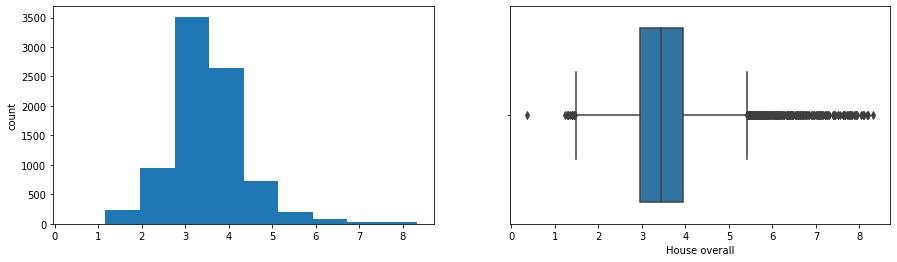

Dishwasher
Skew : 3.35


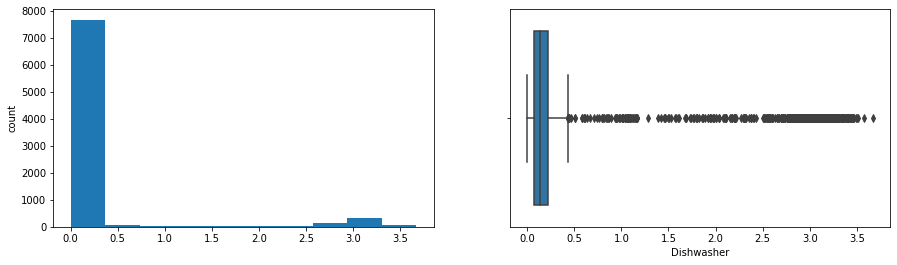

Home office
Skew : 2.44


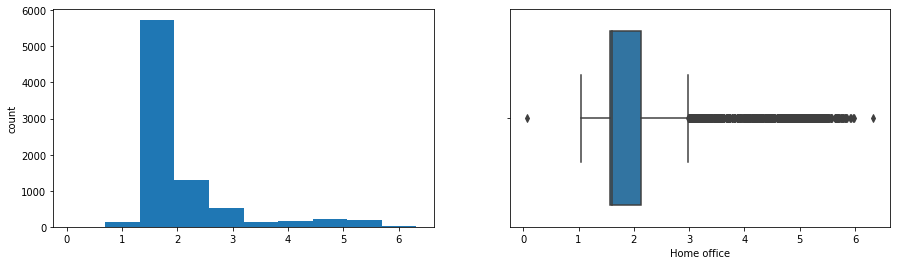

Fridge
Skew : 2.57


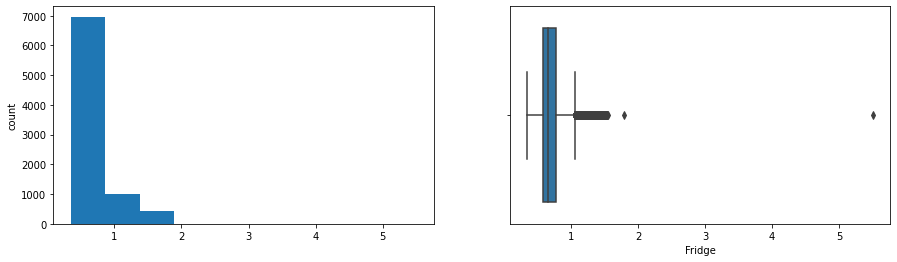

Wine cellar
Skew : 1.69


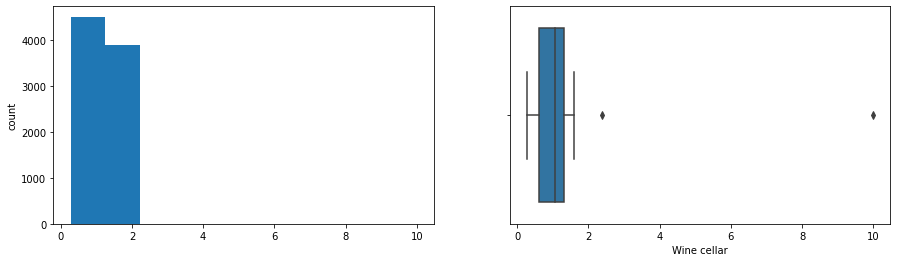

Garage door
Skew : 6.3


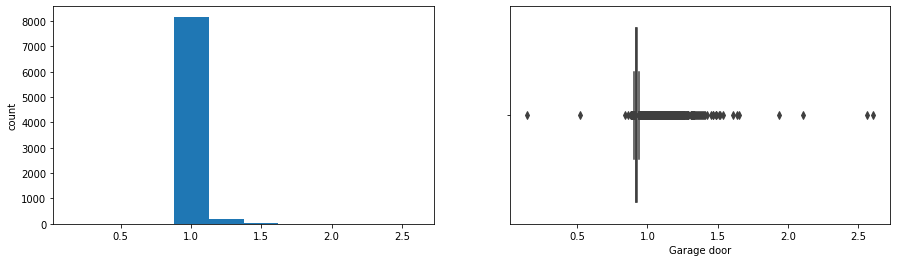

Barn
Skew : 6.14


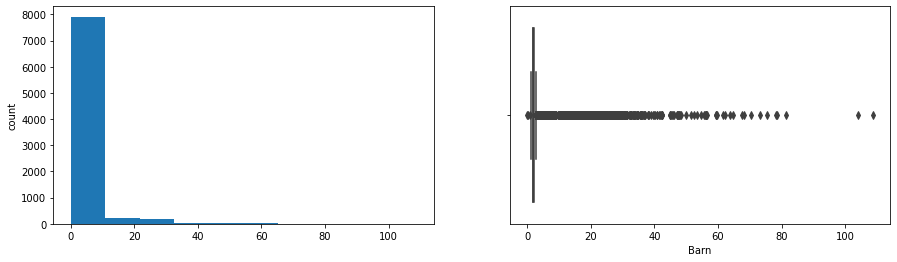

Well
Skew : 1.6


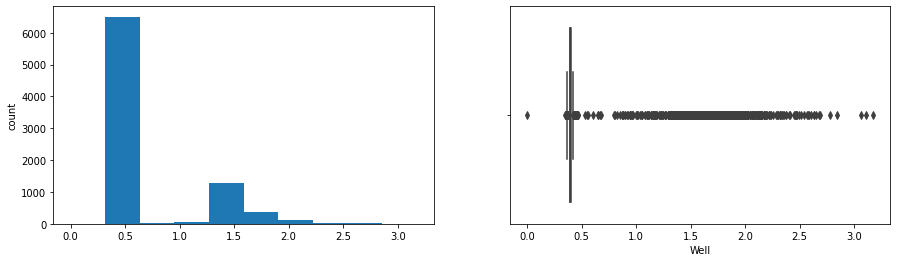

Microwave
Skew : 4.18


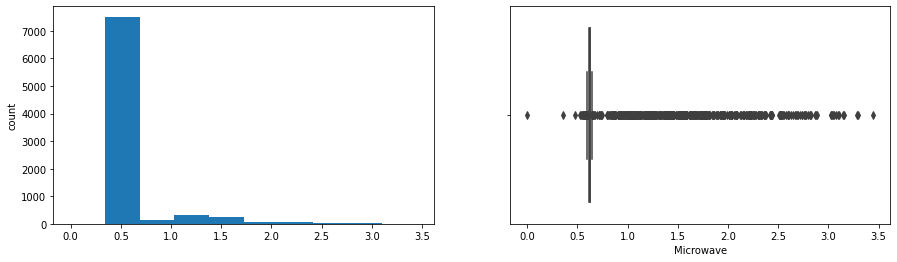

Living room
Skew : 1.84


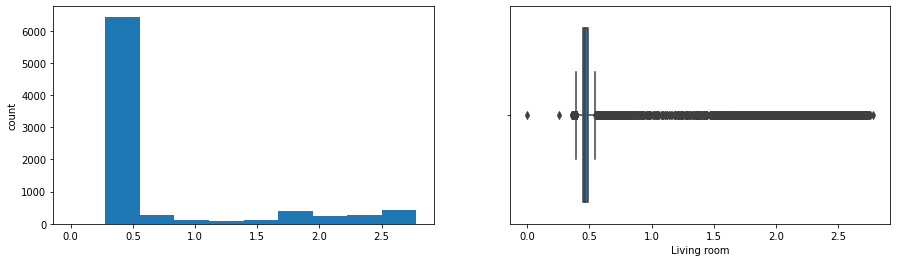

Solar
Skew : -0.37


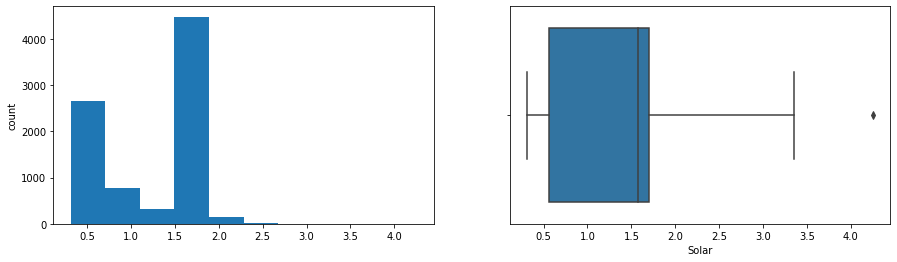

Furnace
Skew : 1.53


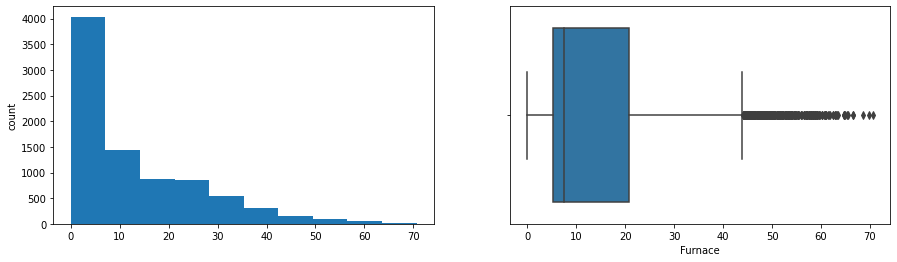

Kitchen
Skew : 2.38


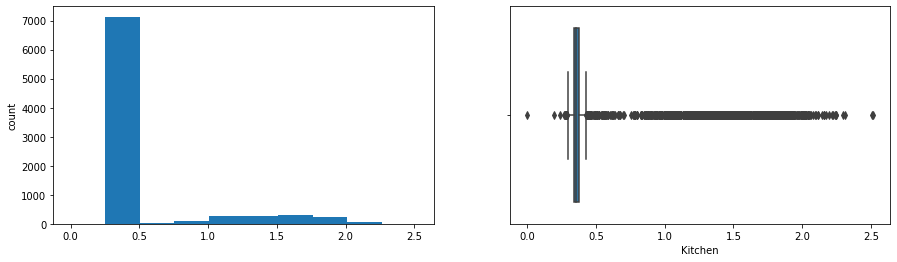

temperature
Skew : -0.09


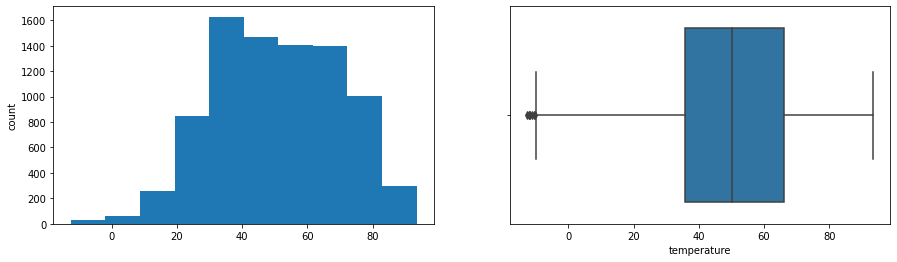

humidity
Skew : -0.36


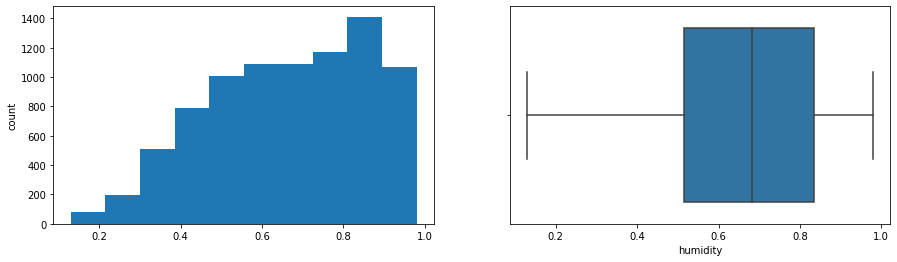

pressure
Skew : -0.18


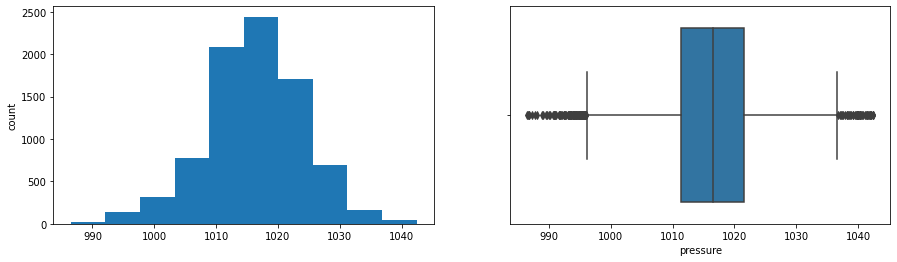

windSpeed
Skew : 0.21


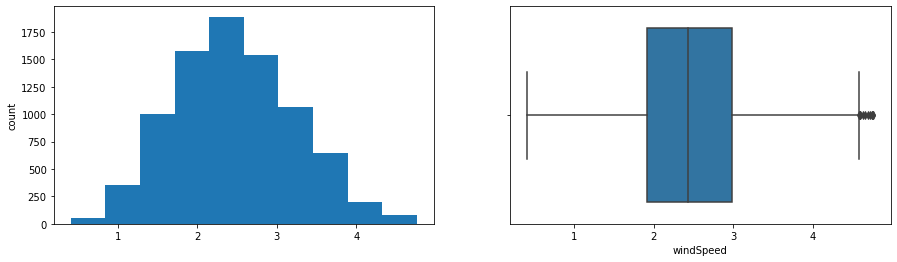

dewPoint
Skew : 1.34


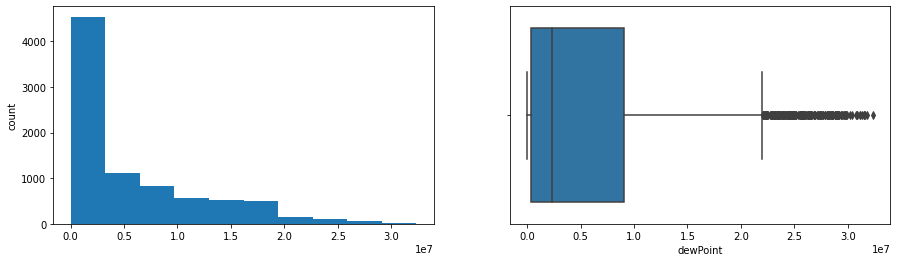

In [179]:
for col in numerical:
  print(col)
  print('Skew :', round(df1[col].skew(), 2))
  plt.figure(figsize = (15, 4))
  plt.subplot(1, 2, 1)
  df1[col].hist(grid=False)
  plt.ylabel('count')
  plt.subplot(1, 2, 2)
  sns.boxplot(x=df1[col])
  plt.show()

**Taking count of outliers and its Percentage after Data Transformations**

In [180]:
def find_outliers_IQR(df1):
    q1=df1.quantile(0.25)
    q3=df1.quantile(0.75)
    IQR=q3-q1
    outliers = df1[((df1<(q1-1.5*IQR)) | (df1>(q3+1.5*IQR)))]
    
    return outliers

for feature in numerical:
    outliers = find_outliers_IQR(df1[feature])

    print(feature)
    print('number of outliers: '+ str(len(outliers)))
    print('max outlier value: '+ str(outliers.max()))
    print('min outlier value: '+ str(outliers.min()))
    print('% of outliers: '+ str(len(outliers)/(len(df1[feature]))*100))
    print('\n')

House overall
number of outliers: 273
max outlier value: 8.314606624247233
min outlier value: 0.363424118566428
% of outliers: 3.2503869508274796


Dishwasher
number of outliers: 668
max outlier value: 3.671101062888269
min outlier value: 0.431961659263047
% of outliers: 7.953327777116323


Home office
number of outliers: 802
max outlier value: 6.324099408848662
min outlier value: 0.07069653456853454
% of outliers: 9.548755804262413


Fridge
number of outliers: 802
max outlier value: 5.503212081491044
min outlier value: 1.0588253966534649
% of outliers: 9.548755804262413


Wine cellar
number of outliers: 2
max outlier value: 9.993342208418067
min outlier value: 2.3905238054718776
% of outliers: 0.02381235861412073


Garage door
number of outliers: 1461
max outlier value: 2.60443277332148
min outlier value: 0.14422495703074084
% of outliers: 17.394927967615192


Barn
number of outliers: 1040
max outlier value: 108.78628333099999
min outlier value: 0.004998000000000001
% of outliers: 12.

In [181]:
def detect_outliers(df1):
    outliers = {}
    for column in df1:
        # Calculate the IQR for the column
        Q1 = df1[column].quantile(0.25)
        Q3 = df1[column].quantile(0.75)
        IQR = Q3 - Q1

        # Identify the outliers using the IQR method
        outliers[column] = df1[(df1[column] < (Q1 - 1.5 * IQR)) | (df1[column] > (Q3 + 1.5 * IQR))].index

        # Print the number of outliers in the column
        print(f"{column}: {len(outliers[column])} outliers")

    # Check for duplicate outliers
    duplicate_outliers = []
    for column in outliers:
        for i in range(len(outliers[column])):
            index = outliers[column][i]
            for j in range(i+1, len(outliers[column])):
                if index == outliers[column][j]:
                    duplicate_outliers.append(index)
    if len(duplicate_outliers) > 0:
        print(f"Duplicate outliers found: {set(duplicate_outliers)}")
    else:
        print("No duplicate outliers found")

    return outliers

**Inference-Since there are no duplicates and all columns have different outlier rows. dropping outliers would lead to too much data loss. Hence we are not dropping outliers**

In [182]:
df1.columns

Index(['House overall', 'Dishwasher', 'Home office', 'Fridge', 'Wine cellar',
       'Garage door', 'Barn', 'Well', 'Microwave', 'Living room', 'Solar',
       'Furnace', 'Kitchen', 'temperature', 'humidity', 'pressure',
       'windSpeed', 'dewPoint'],
      dtype='object')

In [183]:
df1_out=df1.copy()

In [184]:
df1_out.reset_index(inplace=True)

In [185]:
df1_out.index

RangeIndex(start=0, stop=8399, step=1)

In [186]:
df1_out.columns

Index(['time', 'House overall', 'Dishwasher', 'Home office', 'Fridge',
       'Wine cellar', 'Garage door', 'Barn', 'Well', 'Microwave',
       'Living room', 'Solar', 'Furnace', 'Kitchen', 'temperature', 'humidity',
       'pressure', 'windSpeed', 'dewPoint'],
      dtype='object')

In [187]:
# Extracting additional features from 'time' 

df1_out['year'] = df1_out['time'].apply(lambda x:x.year)
df1_out['month'] = df1_out['time'].apply(lambda x:x.month)
df1_out['day'] = df1_out['time'].apply(lambda x:x.day)
##df1_out['weekday'] = df1_out['time'].apply(lambda x:x.weekday)
##df1_out['weekofyear'] = df1_out['time'].apply(lambda x:x.weekofyear)
df1_out['hour'] = df1_out['time'].apply(lambda x:x.hour)
df1_out['minute'] = df1_out['time'].apply(lambda x:x.minute)

In [188]:
df1_out.columns

Index(['time', 'House overall', 'Dishwasher', 'Home office', 'Fridge',
       'Wine cellar', 'Garage door', 'Barn', 'Well', 'Microwave',
       'Living room', 'Solar', 'Furnace', 'Kitchen', 'temperature', 'humidity',
       'pressure', 'windSpeed', 'dewPoint', 'year', 'month', 'day', 'hour',
       'minute'],
      dtype='object')

**Splitting the dataframe based on seasons**

In [189]:
def Season(month):
    if month in [12,1,2]:
        season = 'Winter'
    elif month in [3,4,5]:
        season = 'Spring'
    elif month in [6,7,8]:
        season = 'Summer'
    elif month in [9,10,11]:
        season = 'Autumn'            
    else:
        season='X'
            
    return season


In [190]:
df1_out['season']= df1_out['month'].apply(Season)

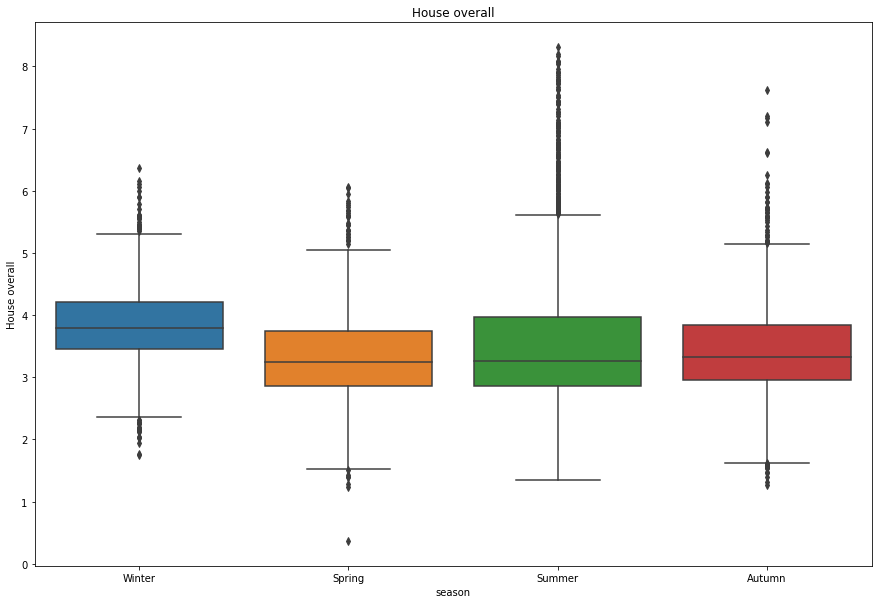

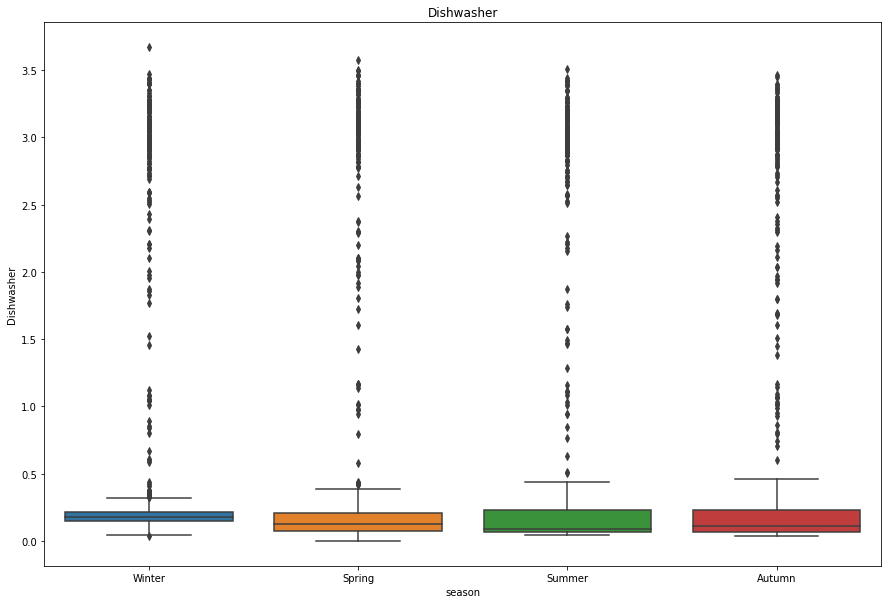

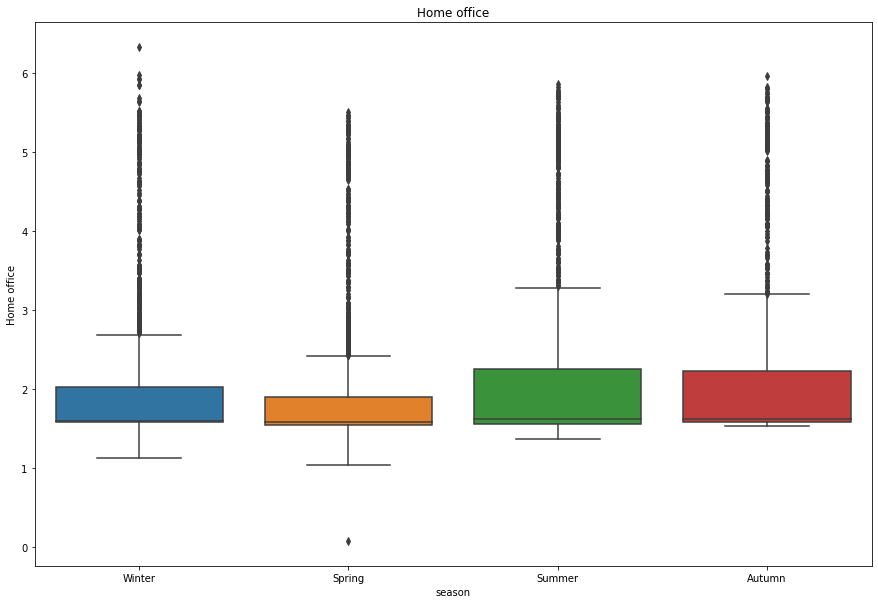

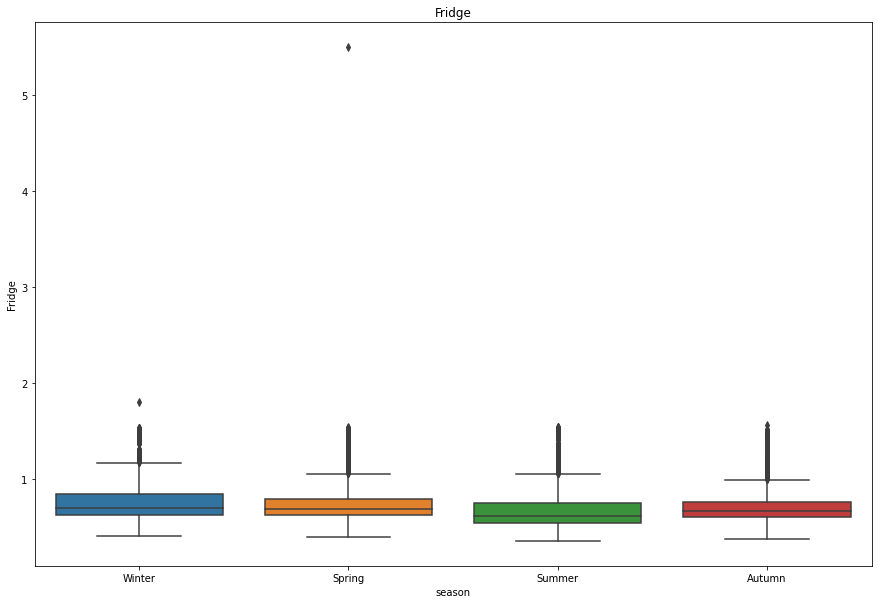

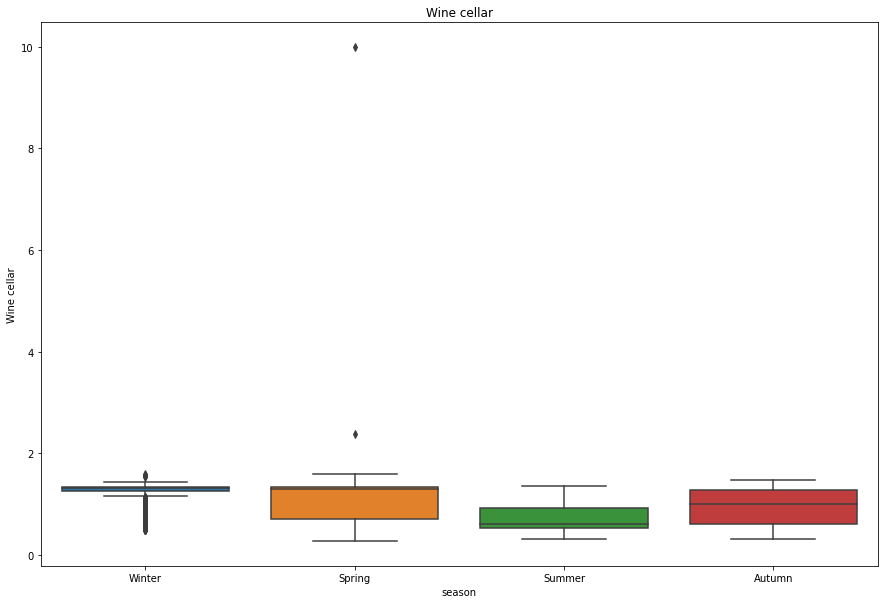

...

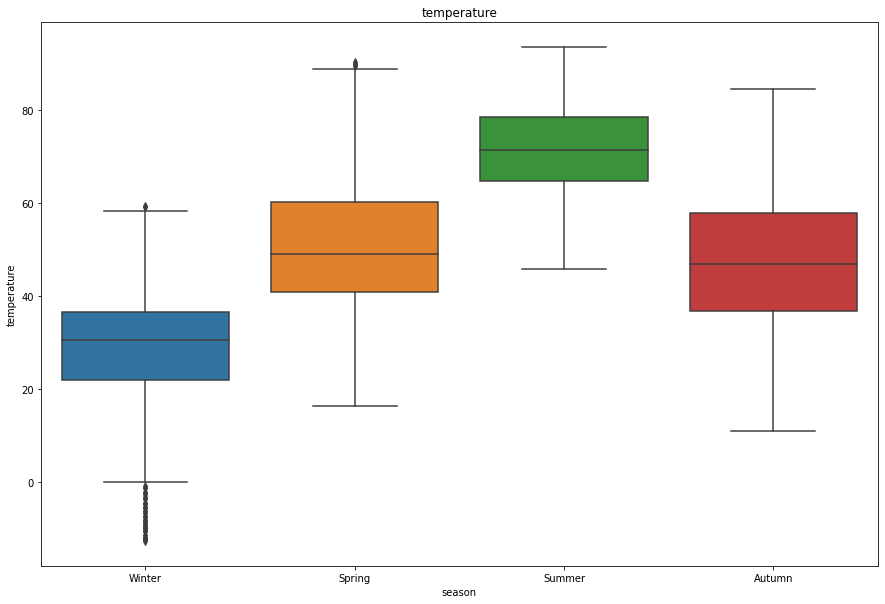

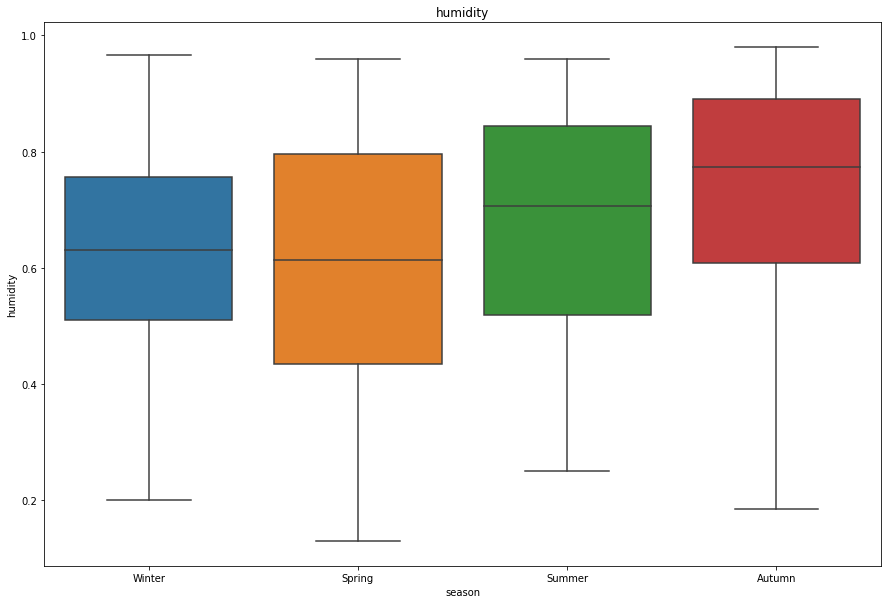

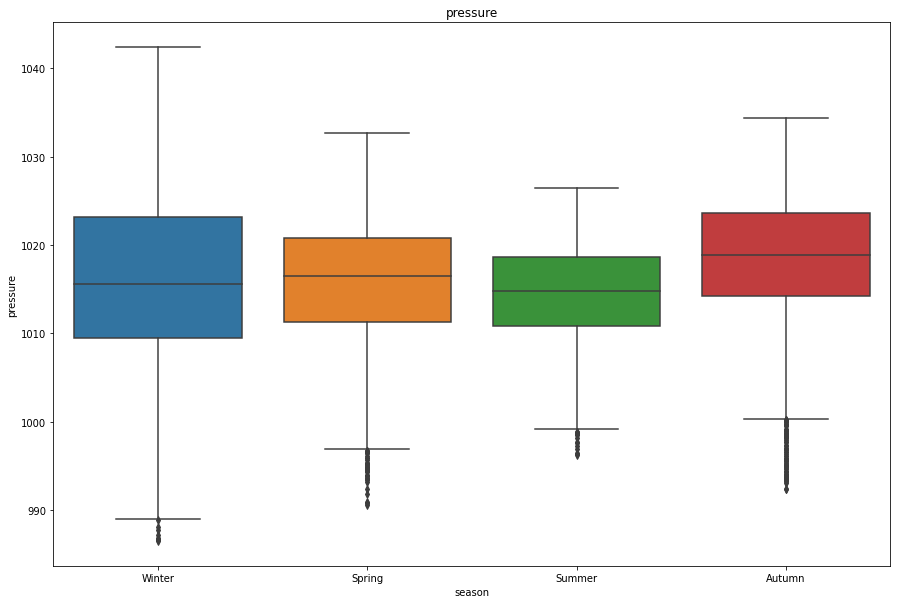

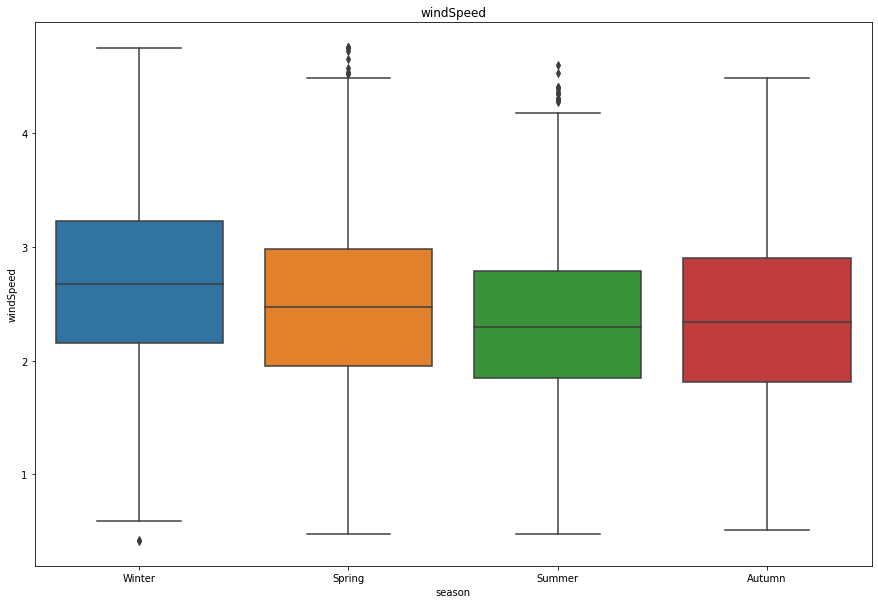

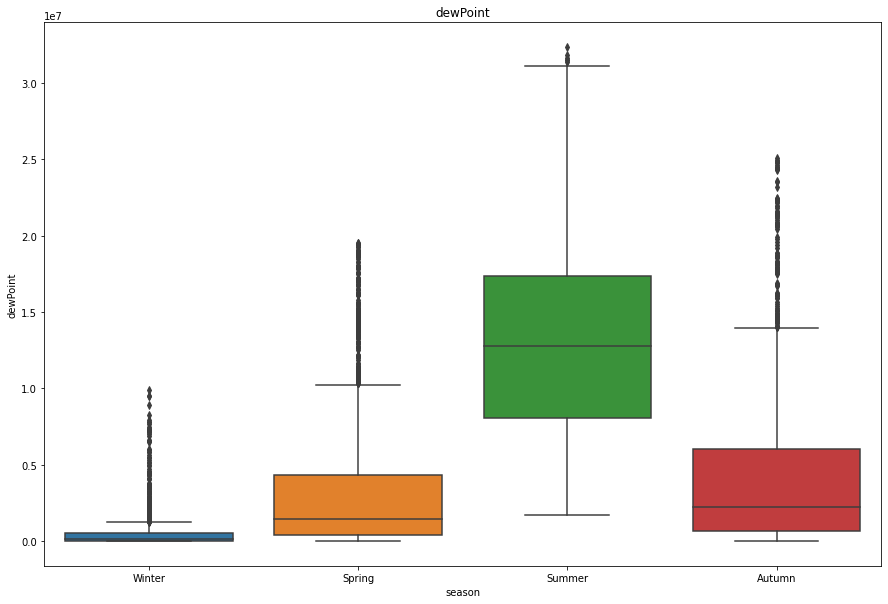

In [191]:
for feature in numerical:
    plt.figure(figsize=(15,10))
    sns.boxplot(x='season', y=feature, data=df1_out)
    plt.title(feature)
    plt.show()
    

Boxenplot

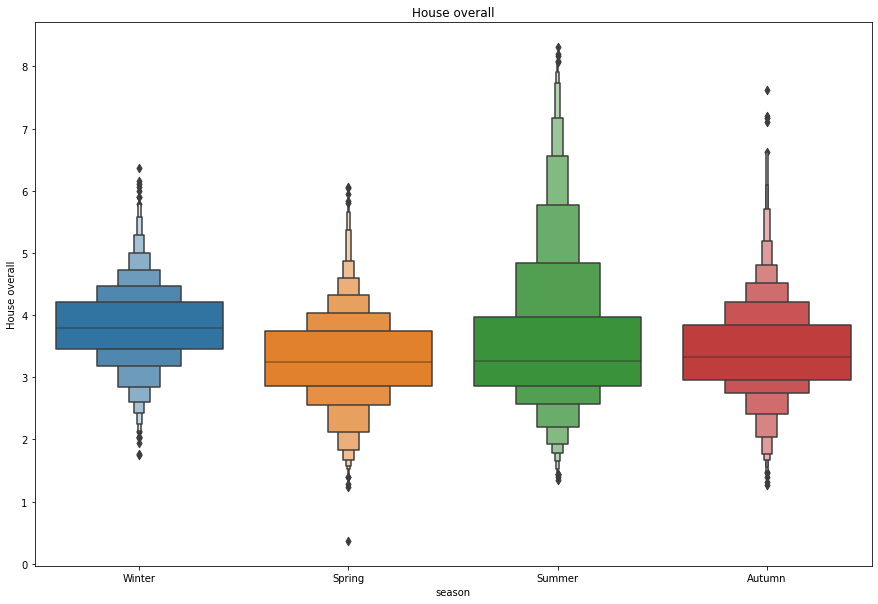

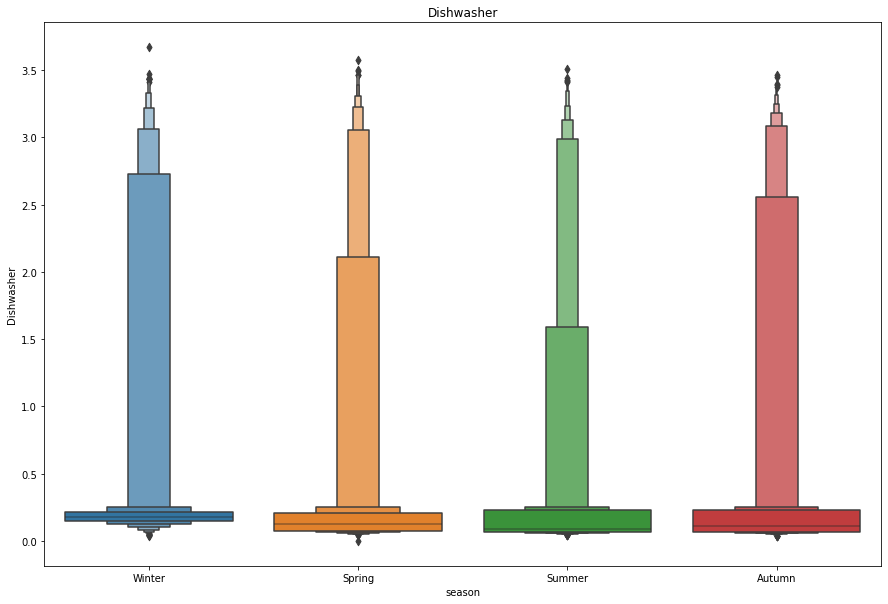

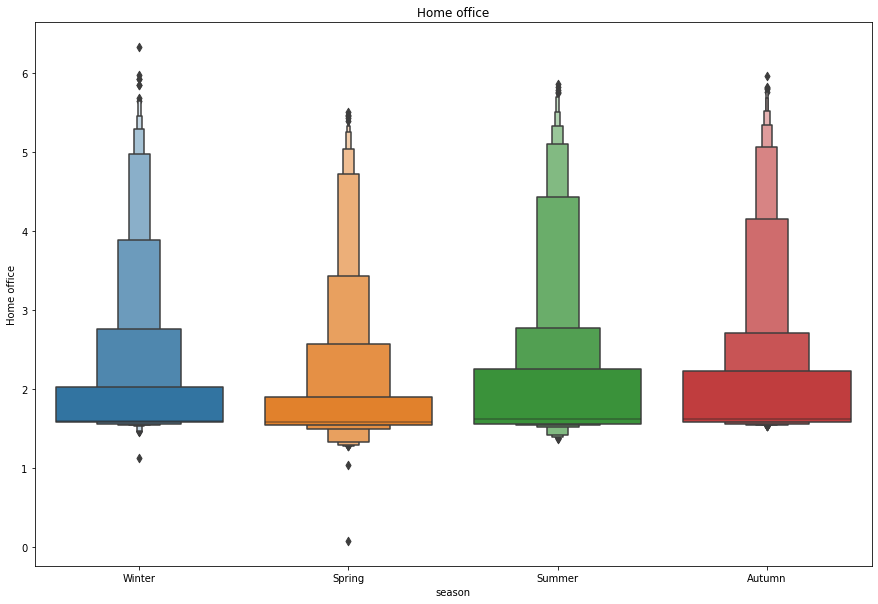

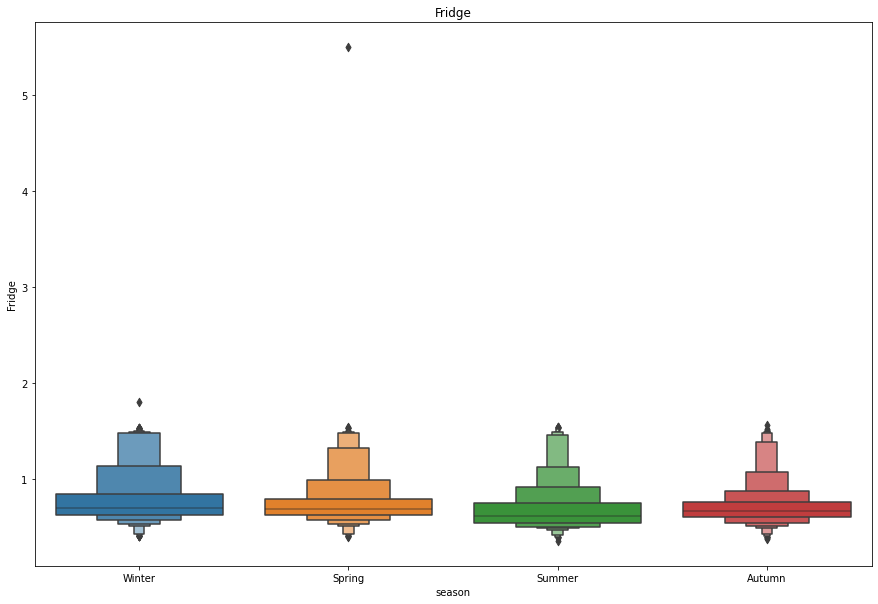

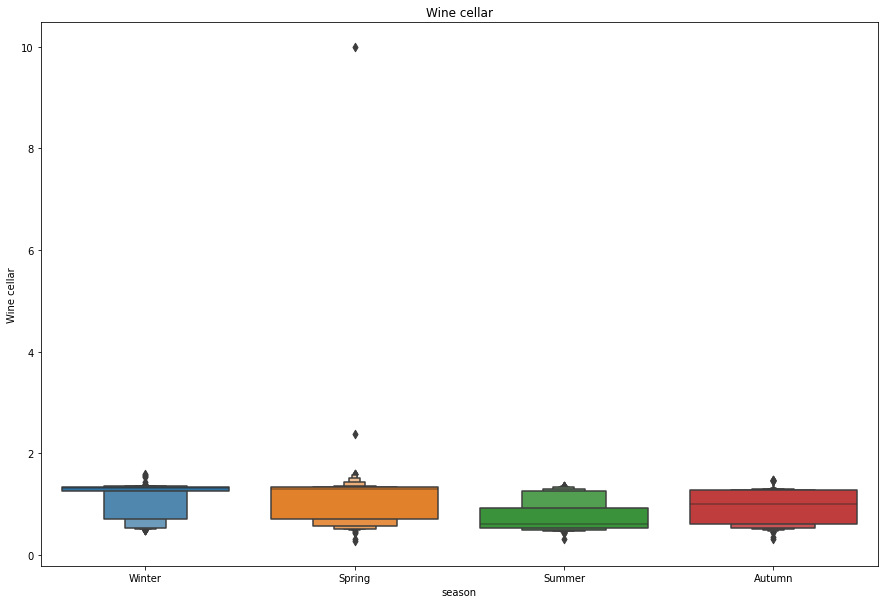

...

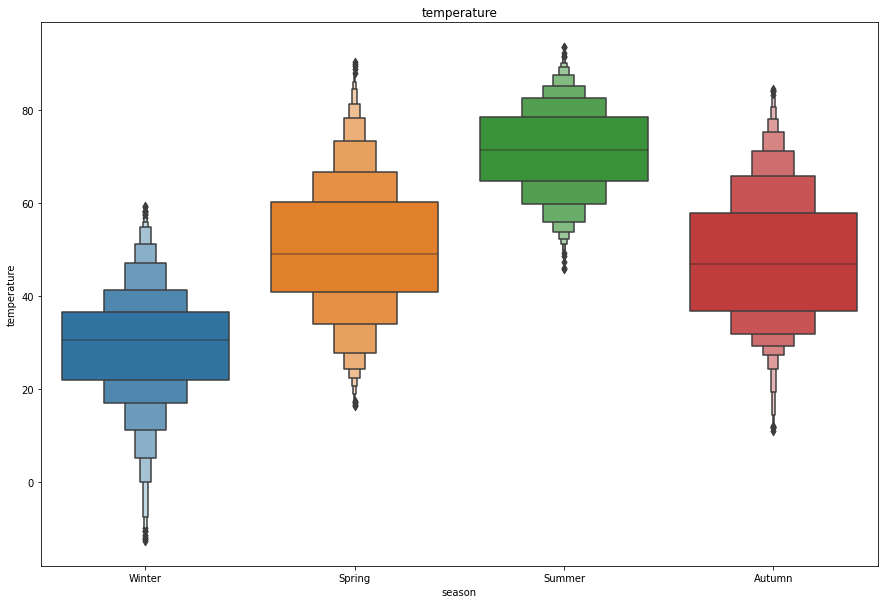

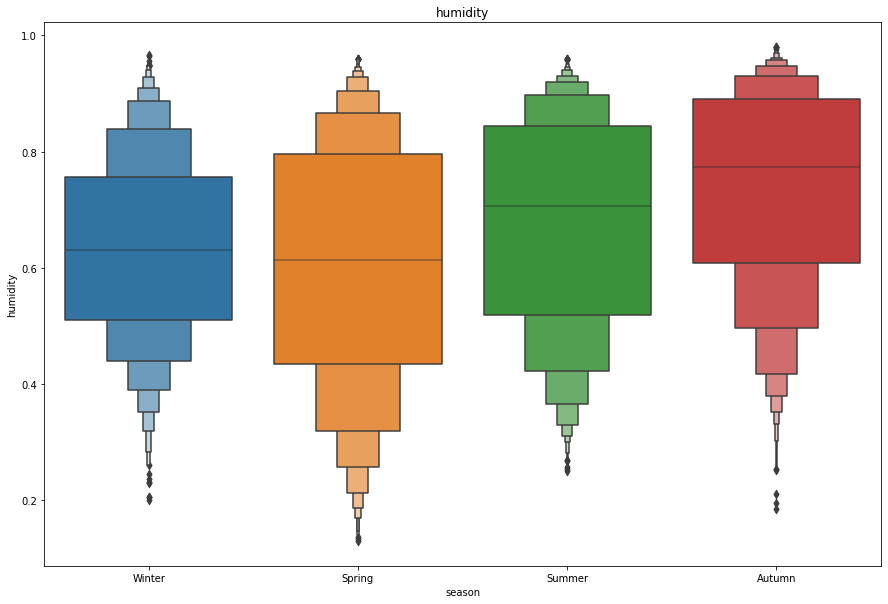

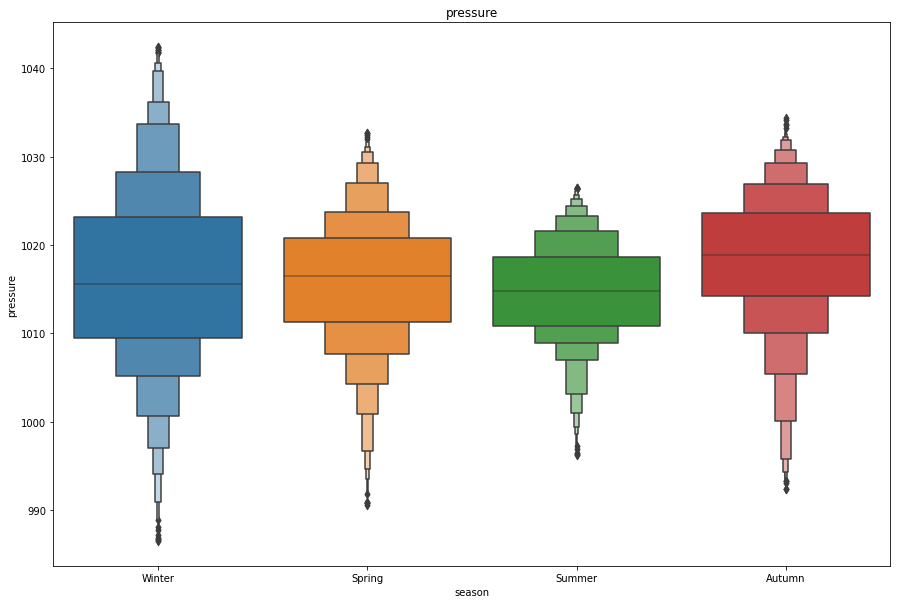

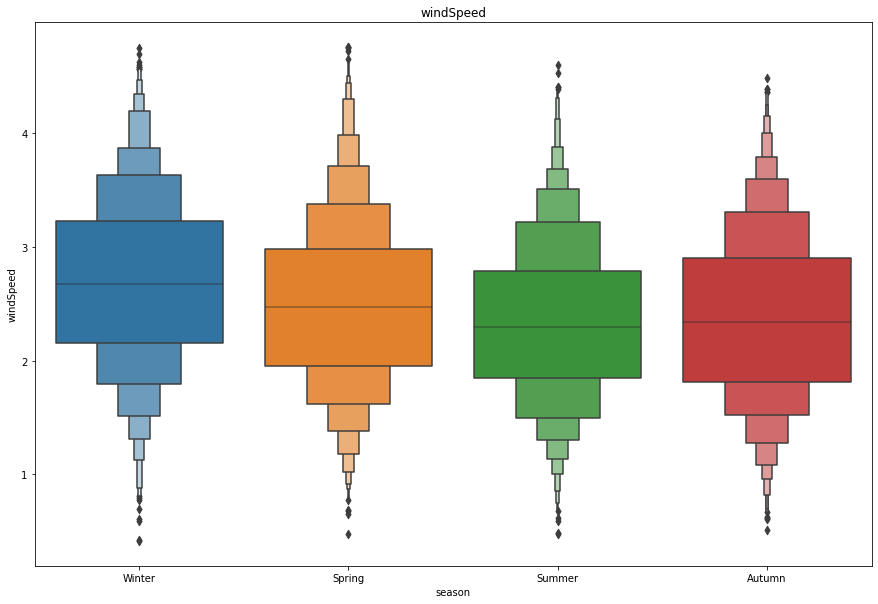

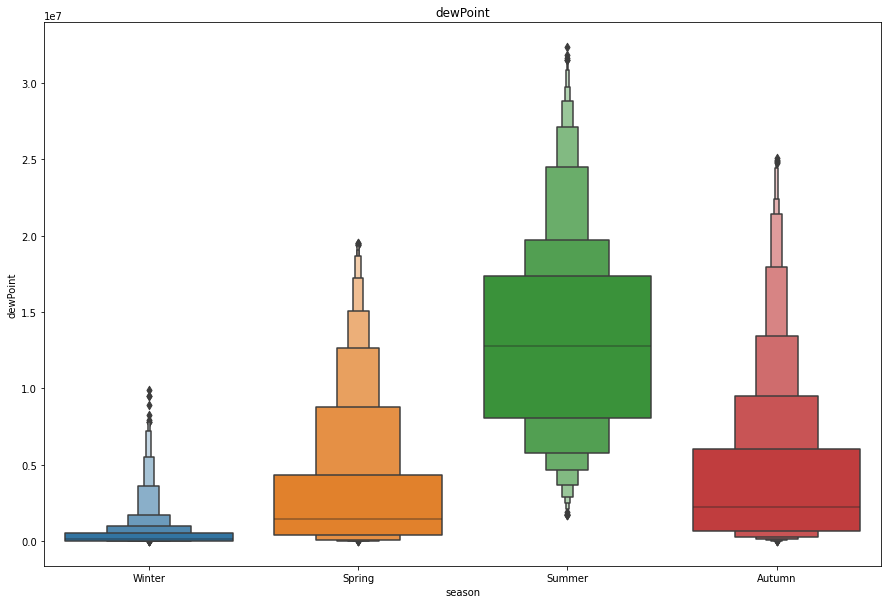

In [192]:
for feature in numerical:
    plt.figure(figsize=(15,10))
    sns.boxenplot(x='season', y=feature, data=df1_out)
    plt.title(feature)
    plt.show()

## Time series analyis

### Time series plot after removing skewness

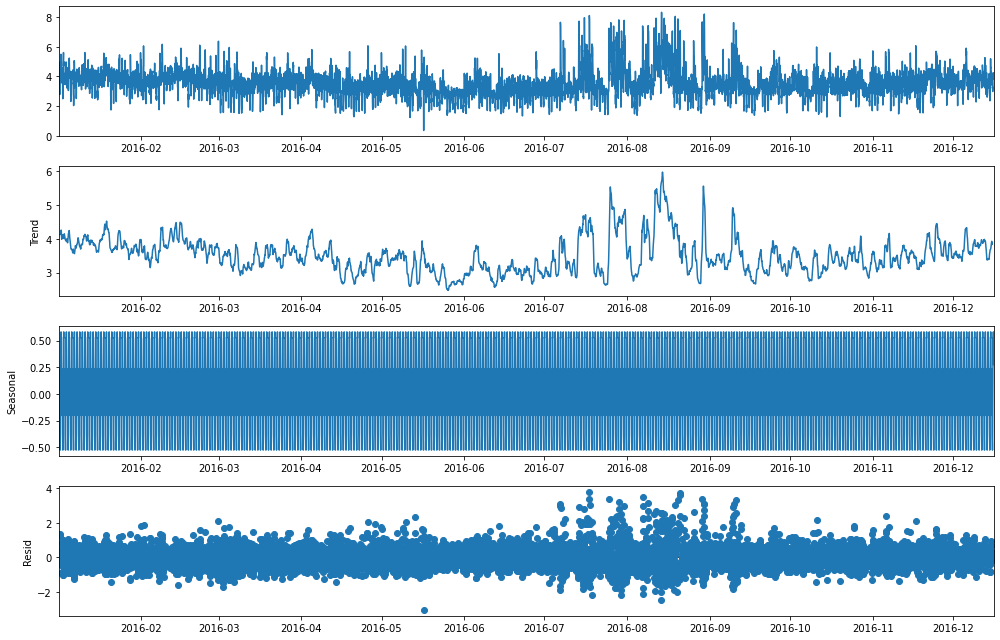

In [193]:

datause1=df1.iloc[:,0].values
#fig,ax=plt.subplots(figsize=(15,10))
plt.rcParams['figure.figsize'] = (14, 9)
seasonal_decompose(df1[['House overall']]).plot()
result = adfuller(datause1)
plt.show()

Understanding the time-series would let us know whether the series is having linear or exponential trend, additive or multiplicative seasonality which aides us in using appropriate techniques for considering these effects.




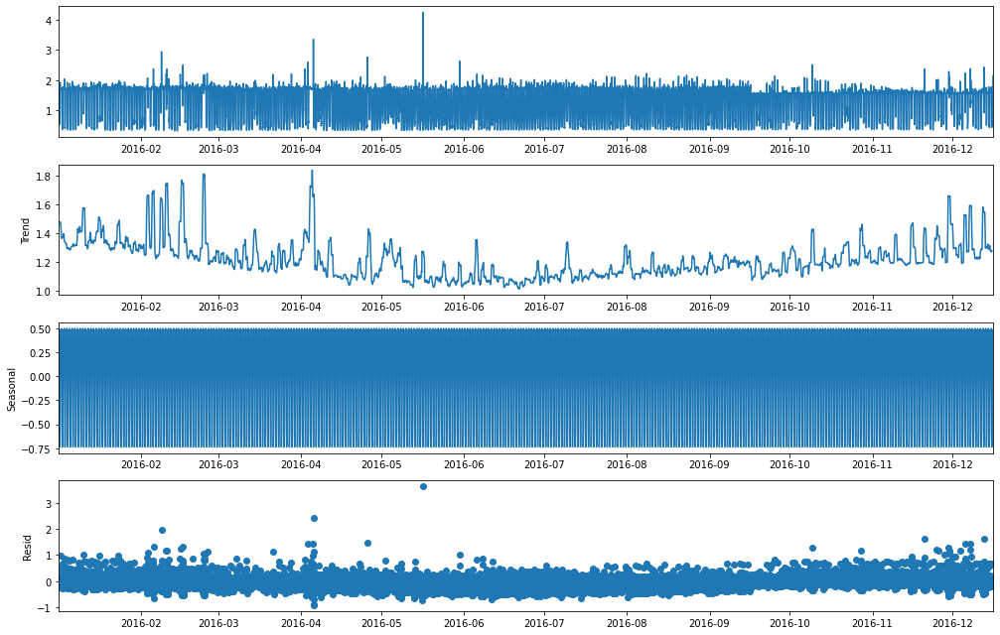

In [194]:


datause=df1.iloc[:,0].values
#fig,ax=plt.subplots(figsize=(15,10))
plt.rcParams['figure.figsize'] = (14, 9)
seasonal_decompose(df1[['Solar']]).plot()
result = adfuller(datause)
plt.show()

**Extracting Netusage column**

**MinMax Scaling**-- Not done here as scaling will take data points to negative values 

**Standard Scaling**

In [195]:
df1_prescale=df1.drop(['House overall','Solar'],axis=1)

In [196]:
df1_prescale.columns

Index(['Dishwasher', 'Home office', 'Fridge', 'Wine cellar', 'Garage door',
       'Barn', 'Well', 'Microwave', 'Living room', 'Furnace', 'Kitchen',
       'temperature', 'humidity', 'pressure', 'windSpeed', 'dewPoint'],
      dtype='object')

In [197]:
df1_prescale.index

DatetimeIndex(['2016-01-01 05:00:00', '2016-01-01 06:00:00',
               '2016-01-01 07:00:00', '2016-01-01 08:00:00',
               '2016-01-01 09:00:00', '2016-01-01 10:00:00',
               '2016-01-01 11:00:00', '2016-01-01 12:00:00',
               '2016-01-01 13:00:00', '2016-01-01 14:00:00',
               ...
               '2016-12-15 18:00:00', '2016-12-15 19:00:00',
               '2016-12-15 20:00:00', '2016-12-15 21:00:00',
               '2016-12-15 22:00:00', '2016-12-15 23:00:00',
               '2016-12-16 00:00:00', '2016-12-16 01:00:00',
               '2016-12-16 02:00:00', '2016-12-16 03:00:00'],
              dtype='datetime64[ns]', name='time', length=8399, freq='H')

In [198]:
from sklearn.preprocessing import StandardScaler

In [199]:
stdsclr=StandardScaler()

In [200]:
X2=stdsclr.fit_transform(df1_prescale)

In [201]:
(X2)

array([[-0.25592859,  2.00946285,  0.1195124 , ...,  0.07434536,
         0.73946686, -0.77647003],
       [-0.22172268, -0.46028183, -0.52185349, ..., -0.00878706,
         0.54562297, -0.78083398],
       [-0.28290519, -0.45772078, -0.31662861, ..., -0.03958154,
         0.46280488, -0.78399592],
       ...,
       [-0.22102943, -0.48922761, -0.14017998, ..., -0.52866039,
         1.06874084, -0.6932735 ],
       [-0.23392138, -0.48968242, -0.15786006, ..., -0.58163196,
         0.32774398, -0.6887316 ],
       [-0.29328276, -1.00931188,  4.36904792, ..., -0.60972295,
         0.16799766, -0.685966  ]])

In [202]:
X2=pd.DataFrame(X2,columns=[df1_prescale.columns])

In [203]:
X2.columns

MultiIndex([( 'Dishwasher',),
            ('Home office',),
            (     'Fridge',),
            ('Wine cellar',),
            ('Garage door',),
            (       'Barn',),
            (       'Well',),
            (  'Microwave',),
            ('Living room',),
            (    'Furnace',),
            (    'Kitchen',),
            ('temperature',),
            (   'humidity',),
            (   'pressure',),
            (  'windSpeed',),
            (   'dewPoint',)],
           )

In [204]:
X2.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Dishwasher,8399.0,4.081877e-17,1.00006,-0.470405,-0.367836,-0.280086,-0.171895,4.567617
Home office,8399.0,2.470276e-16,1.00006,-2.192341,-0.517292,-0.476851,0.122101,4.836310
Fridge,8399.0,3.259157e-16,1.00006,-1.567488,-0.584663,-0.267564,0.185785,19.567520
Wine cellar,8399.0,1.184379e-17,1.00006,-1.973329,-1.058987,0.177710,0.920137,25.099237
Garage door,8399.0,6.609257e-17,1.00006,-11.069797,-0.346090,-0.285350,-0.221247,23.140741
Barn,8399.0,-5.075910e-18,1.00006,-0.550460,-0.267015,-0.248316,-0.206916,16.526008
Well,8399.0,-1.021527e-16,1.00006,-1.311275,-0.520986,-0.516945,-0.493140,5.112318
Microwave,8399.0,1.302817e-16,1.00006,-2.287634,-0.275827,-0.256337,-0.238276,8.973915
Living room,8399.0,-7.190872e-17,1.00006,-1.152149,-0.488284,-0.471178,-0.430560,2.954075
Furnace,8399.0,-2.030364e-17,1.00006,-1.158993,-0.732913,-0.545632,0.539960,4.630489


In [205]:
df1.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
House overall,8399.0,3.503241e+00,8.655019e-01,3.634241e-01,2.953943,3.435802e+00,3.936664e+00,8.314607e+00
Dishwasher,8399.0,3.427740e-01,7.287225e-01,0.000000e+00,0.074740,1.386809e-01,2.175178e-01,3.671101e+00
Home office,8399.0,2.021226e+00,8.897547e-01,7.069653e-02,1.560991,1.596971e+00,2.129859e+00,6.324099e+00
Fridge,8399.0,7.315651e-01,2.438700e-01,3.493245e-01,0.588992,6.663181e-01,7.768698e-01,5.503212e+00
Wine cellar,8399.0,9.853325e-01,3.589171e-01,2.771130e-01,0.605267,1.049112e+00,1.315566e+00,9.993342e+00
Garage door,8399.0,9.402955e-01,7.191802e-02,1.442250e-01,0.915407,9.197749e-01,9.243848e-01,2.604433e+00
Barn,8399.0,3.511565e+00,6.370624e+00,4.998000e-03,1.810617,1.929733e+00,2.193458e+00,1.087863e+02
Well,8399.0,6.475774e-01,4.938826e-01,0.000000e+00,0.390287,3.922826e-01,4.040388e-01,3.172312e+00
Microwave,8399.0,6.998530e-01,3.059470e-01,0.000000e+00,0.615470,6.214321e-01,6.269574e-01,3.445232e+00
Living room,8399.0,7.800047e-01,6.770400e-01,0.000000e+00,0.449437,4.610175e-01,4.885160e-01,2.779912e+00


In [206]:
df1

,House overall,Dishwasher,Home office,Fridge,Wine cellar,Garage door,Barn,Well,Microwave,Living room,Solar,Furnace,Kitchen,temperature,humidity,pressure,windSpeed,dewPoint
time,,,,,,,,,,,,,,,,,,
2016-01-01 05:00:00,3.971628,0.156284,3.809048,0.760709,0.640766,0.921603,2.332833,0.396921,1.091141,0.448610,1.714512,23.591283,0.366512,36.131000,0.619667,1016.888000,3.024952,353486.069148
2016-01-01 06:00:00,3.805026,0.181209,1.611712,0.604308,0.528443,0.916632,2.350883,0.394187,0.632443,0.459602,1.695133,27.402450,0.355472,35.838667,0.610000,1016.232000,2.878194,324428.161272
2016-01-01 07:00:00,3.500249,0.136627,1.613991,0.654353,1.323805,0.927511,2.066350,0.393291,0.633911,0.460599,1.690752,22.330200,0.351919,35.385000,0.613000,1015.989000,2.815493,303373.987474
2016-01-01 08:00:00,3.861975,0.202471,1.975053,0.650991,1.332483,0.918749,2.051700,0.393614,0.635332,0.461148,1.690888,36.982217,0.364265,35.282000,0.640000,1016.042000,2.384254,343125.407794
2016-01-01 09:00:00,3.373443,0.153504,1.613536,0.780111,1.326357,0.925680,1.909783,0.393255,0.634519,0.462607,1.692253,20.630550,0.362795,35.451667,0.641667,1015.815000,2.641023,355811.308856
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2016-12-15 23:00:00,4.037561,0.165096,1.584671,0.722257,1.270932,0.916109,1.934933,0.390506,0.569870,0.422900,1.591122,46.348000,0.352769,36.990000,0.712000,1012.775333,3.344149,651883.911460
2016-12-16 00:00:00,4.246850,0.152799,1.581987,0.691103,0.540508,0.909199,1.854133,1.344664,0.564674,0.420086,1.594807,47.760350,0.337229,37.584167,0.721667,1012.628500,3.459697,745002.777474
2016-12-16 01:00:00,4.228637,0.181714,1.585959,0.697381,0.513441,0.914405,1.919517,0.391378,0.571099,0.424602,1.590624,49.405067,0.358220,36.429333,0.801000,1012.129667,3.274243,907460.233836


In [207]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8399 entries, 2016-01-01 05:00:00 to 2016-12-16 03:00:00
Freq: H
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   House overall  8399 non-null   float64
 1   Dishwasher     8399 non-null   float64
 2   Home office    8399 non-null   float64
 3   Fridge         8399 non-null   float64
 4   Wine cellar    8399 non-null   float64
 5   Garage door    8399 non-null   float64
 6   Barn           8399 non-null   float64
 7   Well           8399 non-null   float64
 8   Microwave      8399 non-null   float64
 9   Living room    8399 non-null   float64
 10  Solar          8399 non-null   float64
 11  Furnace        8399 non-null   float64
 12  Kitchen        8399 non-null   float64
 13  temperature    8399 non-null   float64
 14  humidity       8399 non-null   float64
 15  pressure       8399 non-null   float64
 16  windSpeed      8399 non-null   float64
 17  dewPoint

In [208]:
X2.columns=['Dishwasher', 'Home office', 'Fridge', 'Wine cellar', 'Garage door',
       'Barn', 'Well', 'Microwave', 'Living room', 'Furnace',
       'Kitchen', 'temperature', 'humidity', 'pressure', 'windSpeed',
       'dewPoint']

In [209]:
x = X2
y = df1['House overall']

In [210]:
x.set_index(df1.index,inplace=True)

In [211]:
x.index

DatetimeIndex(['2016-01-01 05:00:00', '2016-01-01 06:00:00',
               '2016-01-01 07:00:00', '2016-01-01 08:00:00',
               '2016-01-01 09:00:00', '2016-01-01 10:00:00',
               '2016-01-01 11:00:00', '2016-01-01 12:00:00',
               '2016-01-01 13:00:00', '2016-01-01 14:00:00',
               ...
               '2016-12-15 18:00:00', '2016-12-15 19:00:00',
               '2016-12-15 20:00:00', '2016-12-15 21:00:00',
               '2016-12-15 22:00:00', '2016-12-15 23:00:00',
               '2016-12-16 00:00:00', '2016-12-16 01:00:00',
               '2016-12-16 02:00:00', '2016-12-16 03:00:00'],
              dtype='datetime64[ns]', name='time', length=8399, freq='H')

In [212]:
df1['House overall']



time
2016-01-01 05:00:00    3.971628
2016-01-01 06:00:00    3.805026
2016-01-01 07:00:00    3.500249
2016-01-01 08:00:00    3.861975
2016-01-01 09:00:00    3.373443
                         ...   
2016-12-15 23:00:00    4.037561
2016-12-16 00:00:00    4.246850
2016-12-16 01:00:00    4.228637
2016-12-16 02:00:00    4.041678
2016-12-16 03:00:00    3.807842
Freq: H, Name: House overall, Length: 8399, dtype: float64

In [213]:
X2.columns

Index(['Dishwasher', 'Home office', 'Fridge', 'Wine cellar', 'Garage door',
       'Barn', 'Well', 'Microwave', 'Living room', 'Furnace', 'Kitchen',
       'temperature', 'humidity', 'pressure', 'windSpeed', 'dewPoint'],
      dtype='object')

In [214]:
dataframe = pd.concat([x,y],axis=1)

In [215]:
dataframe

,Dishwasher,Home office,Fridge,Wine cellar,Garage door,Barn,Well,Microwave,Living room,Furnace,Kitchen,temperature,humidity,pressure,windSpeed,dewPoint,House overall
time,,,,,,,,,,,,,,,,,
2016-01-01 05:00:00,-0.255929,2.009463,0.119512,-0.960074,-0.259923,-0.185037,-0.507553,1.279017,-0.489505,0.773133,-0.367144,-0.765123,-0.229723,0.074345,0.739467,-0.776470,3.971628
2016-01-01 06:00:00,-0.221723,-0.460282,-0.521853,-1.273042,-0.329057,-0.182204,-0.513089,-0.220347,-0.473269,1.085506,-0.393546,-0.780433,-0.279704,-0.008787,0.545623,-0.780834,3.805026
2016-01-01 07:00:00,-0.282905,-0.457721,-0.316629,0.943095,-0.177772,-0.226870,-0.514903,-0.215545,-0.471796,0.669771,-0.402042,-0.804191,-0.264193,-0.039582,0.462805,-0.783996,3.500249
2016-01-01 08:00:00,-0.192544,-0.051897,-0.330415,0.967274,-0.299611,-0.229169,-0.514249,-0.210901,-0.470985,1.870688,-0.372519,-0.809585,-0.124591,-0.032865,-0.106793,-0.778026,3.861975
2016-01-01 09:00:00,-0.259744,-0.458232,0.199077,0.950206,-0.203236,-0.251447,-0.514976,-0.213559,-0.468831,0.530464,-0.376033,-0.800700,-0.115973,-0.061632,0.232357,-0.776121,3.373443
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2016-12-15 23:00:00,-0.243836,-0.490675,-0.038172,0.795773,-0.336325,-0.247499,-0.520543,-0.424879,-0.527481,2.638331,-0.400010,-0.720138,0.247682,-0.446837,1.161076,-0.731656,4.037561
2016-12-16 00:00:00,-0.260711,-0.493692,-0.165925,-1.239426,-0.432411,-0.260183,1.411526,-0.441865,-0.531639,2.754091,-0.437172,-0.689021,0.297663,-0.465445,1.313696,-0.717672,4.246850
2016-12-16 01:00:00,-0.221029,-0.489228,-0.140180,-1.314843,-0.360026,-0.249919,-0.518776,-0.420861,-0.524968,2.888896,-0.386973,-0.749500,0.707852,-0.528660,1.068741,-0.693273,4.228637


In [216]:
dataframe.index

DatetimeIndex(['2016-01-01 05:00:00', '2016-01-01 06:00:00',
               '2016-01-01 07:00:00', '2016-01-01 08:00:00',
               '2016-01-01 09:00:00', '2016-01-01 10:00:00',
               '2016-01-01 11:00:00', '2016-01-01 12:00:00',
               '2016-01-01 13:00:00', '2016-01-01 14:00:00',
               ...
               '2016-12-15 18:00:00', '2016-12-15 19:00:00',
               '2016-12-15 20:00:00', '2016-12-15 21:00:00',
               '2016-12-15 22:00:00', '2016-12-15 23:00:00',
               '2016-12-16 00:00:00', '2016-12-16 01:00:00',
               '2016-12-16 02:00:00', '2016-12-16 03:00:00'],
              dtype='datetime64[ns]', name='time', length=8399, freq='H')

In [217]:
from google.colab import files
dataframe.to_csv('SmartHomeModel.csv')
files.download('SmartHomeModel.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Linear Regression

In [221]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)




In [222]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

model_lr = lr.fit (x_train , y_train)

y_pred = model_lr.predict(x_test)


from sklearn.metrics import mean_squared_error,r2_score,f1_score

print('MSE is ', mean_squared_error(y_test,y_pred))
print('R Squared value :',r2_score(y_test,y_pred))



MSE is  0.27732968253574564
R Squared value : 0.6290227306219784


LASSO REGRESSION

In [223]:
from sklearn.linear_model import Lasso
lasso= Lasso (alpha=1.0)

model_lasso=lasso.fit(x_train,y_train)
y_pred = model_lasso.predict(x_test)

## The lasso regression model has a lesser MSE and R2 value closer to 1

In [224]:
print('MSE is ', mean_squared_error(y_test,y_pred))
print('R Squared value :',r2_score(y_test,y_pred))


MSE is  0.747684262655867
R Squared value : -0.00015931789501721916


In [225]:
print("slope is: %.2f" % model_lasso.coef_[0])

slope is: 0.00


In [226]:
print("intercept: %2.f"% model_lasso.intercept_)

intercept:  4


### Decision Tree

In [227]:
### Decision Tree

from sklearn.tree import DecisionTreeRegressor

dt_reg = DecisionTreeRegressor(random_state=42)
dt_model=dt_reg.fit(x_train,y_train)
y_pred_dt=dt_model.predict(x_test)


In [228]:
print('MSE is ', mean_squared_error(y_test,y_pred_dt))
print('R Squared value :',r2_score(y_test,y_pred_dt))




MSE is  0.2560080767033133
R Squared value : 0.6575441317145236


## Random forest 

In [229]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)
from sklearn.metrics import mean_squared_error,r2_score,f1_score

In [230]:
from sklearn.ensemble import RandomForestRegressor
rf_reg = RandomForestRegressor(random_state=42)
rf_model = rf_reg.fit(x_train,y_train)
y_pred_rf = rf_model.predict(x_test)



In [231]:
print('MSE is ', mean_squared_error(y_test,y_pred_rf ))
print('R Squared value :',r2_score(y_test,y_pred_rf ))




MSE is  0.12588998867946508
R Squared value : 0.8315999794348792


**MSE IS LEAST FOR RANDOM FOREST :0.1258 & R SQUARED VALUE is highest : 0.83**

In [232]:
y_pred_rf

array([3.25673117, 3.7571952 , 2.80094379, ..., 3.81449763, 3.31838941,
       3.61292552])

In [233]:
(y_pred_rf< 0).sum().sum()

0

## SVM

In [234]:
## SVM

from sklearn.svm import SVR
svr_clf= SVR(kernel='linear')
svr_model=svr_clf.fit(x_train,y_train)
y_pred_svr=svr_model.predict(x_test)


In [235]:
print('MSE is ', mean_squared_error(y_test,y_pred_svr))
print('R Squared value :',r2_score(y_test,y_pred_svr))


MSE is  0.3047368733895545
R Squared value : 0.5923607883037132


In [236]:

from sklearn.svm import SVR
svr_clf1= SVR(kernel='rbf')
svr_model1=svr_clf1.fit(x_train,y_train)
y_pred_svr1=svr_model1.predict(x_test)




In [237]:
print('MSE is ', mean_squared_error(y_test,y_pred_svr1))
print('R Squared value :',r2_score(y_test,y_pred_svr1))



MSE is  0.1767695228433144
R Squared value : 0.7635396460484674


In [238]:
from sklearn.svm import SVR
svr_clf2= SVR(kernel='poly')
svr_model2=svr_clf2.fit(x_train,y_train)
y_pred_svr2=svr_model2.predict(x_test)



In [239]:
print('MSE is ', mean_squared_error(y_test,y_pred_svr2))
print('R Squared value :',r2_score(y_test,y_pred_svr2))


MSE is  0.31945258485135164
R Squared value : 0.5726759337827814


In [240]:
x1 = X2[[ 'temperature', 'humidity', 'pressure', 'windSpeed', 'dewPoint']]
y1 = df1['Solar']

In [241]:
x1.set_index(df1.index,inplace=True)

In [242]:
x1.index

DatetimeIndex(['2016-01-01 05:00:00', '2016-01-01 06:00:00',
               '2016-01-01 07:00:00', '2016-01-01 08:00:00',
               '2016-01-01 09:00:00', '2016-01-01 10:00:00',
               '2016-01-01 11:00:00', '2016-01-01 12:00:00',
               '2016-01-01 13:00:00', '2016-01-01 14:00:00',
               ...
               '2016-12-15 18:00:00', '2016-12-15 19:00:00',
               '2016-12-15 20:00:00', '2016-12-15 21:00:00',
               '2016-12-15 22:00:00', '2016-12-15 23:00:00',
               '2016-12-16 00:00:00', '2016-12-16 01:00:00',
               '2016-12-16 02:00:00', '2016-12-16 03:00:00'],
              dtype='datetime64[ns]', name='time', length=8399, freq='H')

In [244]:
dataframe1 = pd.concat([x1,y1],axis=1)

In [ ]:
dataframe1

In [246]:
dataframe1.index

DatetimeIndex(['2016-01-01 05:00:00', '2016-01-01 06:00:00',
               '2016-01-01 07:00:00', '2016-01-01 08:00:00',
               '2016-01-01 09:00:00', '2016-01-01 10:00:00',
               '2016-01-01 11:00:00', '2016-01-01 12:00:00',
               '2016-01-01 13:00:00', '2016-01-01 14:00:00',
               ...
               '2016-12-15 18:00:00', '2016-12-15 19:00:00',
               '2016-12-15 20:00:00', '2016-12-15 21:00:00',
               '2016-12-15 22:00:00', '2016-12-15 23:00:00',
               '2016-12-16 00:00:00', '2016-12-16 01:00:00',
               '2016-12-16 02:00:00', '2016-12-16 03:00:00'],
              dtype='datetime64[ns]', name='time', length=8399, freq='H')

In [ ]:
#from google.colab import files
#dataframe1.to_csv('SmartHomeSolar.csv')
#files.download('SmartHomeSolar.csv')

### Linear Regression

In [247]:
from sklearn.model_selection import train_test_split

x1_train,x1_test,y1_train,y1_test = train_test_split(x1,y1,test_size=0.2,random_state=42)




In [248]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

model_lr1 = lr.fit (x1_train , y1_train)

y_pred1 = model_lr1.predict(x1_test)


from sklearn.metrics import mean_squared_error,r2_score

print('MSE is ', mean_squared_error(y1_test,y_pred1))
print('R Squared value :',r2_score(y1_test,y_pred1))


MSE is  0.33127400707659493
R Squared value : 0.01783309756980722


LASSO REGRESSION

In [249]:
from sklearn.linear_model import Lasso
lasso1= Lasso (alpha=1.0)

model_lasso1=lasso1.fit(x1_train,y1_train)
y_pred1 = model_lasso1.predict(x1_test)

## The lasso regression model has a lesser MSE and R2 value closer to 1

In [250]:
print('MSE is ', mean_squared_error(y1_test,y_pred1))
print('R Squared value :',r2_score(y1_test,y_pred1))

MSE is  0.33730362328248165
R Squared value : -4.3612782566926356e-05


In [251]:
print("slope is: %.2f" % model_lasso1.coef_[0])

slope is: -0.00


In [252]:
print("intercept: %2.f"% model_lasso1.intercept_)

intercept:  1


### Decision Tree

In [253]:
### Decision Tree

from sklearn.tree import DecisionTreeRegressor

dt_reg = DecisionTreeRegressor(random_state=42)
dt_model1=dt_reg.fit(x1_train,y1_train)
y_pred_dt1=dt_model1.predict(x1_test)


In [254]:
print('MSE is ', mean_squared_error(y1_test,y_pred_dt1))
print('R Squared value :',r2_score(y1_test,y_pred_dt1))



MSE is  0.4243755772257521
R Squared value : -0.2581960469191613


## Random forest 

In [255]:
from sklearn.model_selection import train_test_split

x1_train,x1_test,y1_train,y1_test = train_test_split(x1,y1,test_size=0.2,random_state=42)
from sklearn.metrics import mean_squared_error,r2_score

In [256]:
from sklearn.ensemble import RandomForestRegressor
rf_reg = RandomForestRegressor(random_state=42)
rf_model1 = rf_reg.fit(x1_train,y1_train)
y_pred_rf1 = rf_model1.predict(x1_test)



In [257]:
print('MSE is ', mean_squared_error(y1_test,y_pred_rf1 ))
print('R Squared value :',r2_score(y1_test,y_pred_rf1 ))



MSE is  0.2302804348535119
R Squared value : 0.3172605862250544


**MSE IS LEAST FOR RANDOM FOREST :0.23 & R SQUARED VALUE is highest : 0.317**

In [ ]:
y_pred_rf1

In [258]:
(y_pred_rf1< 0).sum().sum()

0

## SVM

In [259]:
## SVM

from sklearn.svm import SVR
svr_clf= SVR(kernel='linear')
svr_model_1=svr_clf.fit(x1_train,y1_train)
y_pred_svr=svr_model_1.predict(x1_test)


In [260]:
print('MSE is ', mean_squared_error(y1_test,y_pred_svr))
print('R Squared value :',r2_score(y1_test,y_pred_svr))

MSE is  0.3900175392020289
R Squared value : -0.15633074188924811


In [261]:

from sklearn.svm import SVR
svr_clf1= SVR(kernel='rbf')
svr_model1_1=svr_clf1.fit(x1_train,y1_train)
y_pred_svm1_1=svr_model1_1.predict(x1_test)




In [262]:
print('MSE is ', mean_squared_error(y1_test,y_pred_svm1_1))
print('R Squared value :',r2_score(y1_test,y_pred_svm1_1))



MSE is  0.3517747878074416
R Squared value : -0.04294797150803542


In [263]:
from sklearn.svm import SVR
svr_clf2= SVR(kernel='poly')
svr_model2_1=svr_clf2.fit(x1_train,y1_train)
y_pred_svr2_1=svr_model2_1.predict(x1_test)



In [264]:
print('MSE is ', mean_squared_error(y1_test,y_pred_svr2_1))
print('R Squared value :',r2_score(y1_test,y_pred_svr2_1))

MSE is  0.3817637493797907
R Squared value : -0.1318597631530769


\# **k-Fold cross validation**

In [265]:
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score

kfold_validator = KFold(10) #number of folds is 10


In [266]:
# Printing the validation result

cv_linear = cross_val_score(model_lr, x, y, cv = kfold_validator)
print("Validation result : ", cv_linear) 
print("\nAverage of Cross validation result ", np.mean(cv_linear))

Validation result :  [0.51284753 0.50337118 0.48569657 0.55823234 0.35718412 0.60584399
 0.56799839 0.58752276 0.58817783 0.56841223]

Average of Cross validation result  0.5335286952168777


In [267]:
# Printing the validation result

cv_lasso = cross_val_score(model_lasso, x, y, cv = kfold_validator)
print("Validation result : ", cv_lasso) 
print("\nAverage of Cross validation result ", np.mean(cv_lasso))

Validation result :  [-3.52740643e-01 -9.47743900e-02 -3.04529375e-04 -2.16489328e-01
 -9.57058525e-01 -8.17226016e-05 -1.42713606e-01 -4.45162868e-02
 -8.14741175e-02 -7.18160764e-02]

Average of Cross validation result  -0.19619692246132042


In [268]:
# Printing the validation result

cv_lin_svr = cross_val_score(svr_model, x, y, cv = kfold_validator)
print("Validation result : ", cv_lin_svr) 
print("\nAverage of Cross validation result ", np.mean(cv_lin_svr))

Validation result :  [0.67393385 0.66959062 0.59882523 0.5953403  0.38307154 0.50494959
 0.43930279 0.53615103 0.64039095 0.66535751]

Average of Cross validation result  0.5706913404776264


In [269]:
# Printing the validation result

cv_rbf = cross_val_score(svr_model1, x, y, cv = kfold_validator)
print("Validation result : ", cv_rbf) 
print("\nAverage of Cross validation result ", np.mean(cv_rbf))

Validation result :  [0.72017907 0.71408624 0.60156275 0.55158802 0.43297794 0.79121102
 0.77391094 0.71453044 0.66703538 0.68183492]

Average of Cross validation result  0.664891672134373


In [270]:
# Printing the validation result

cv_poly = cross_val_score(svr_model2, x, y, cv = kfold_validator)
print("Validation result : ", cv_poly) 
print("\nAverage of Cross validation result ", np.mean(cv_poly))

Validation result :  [ 4.34875638e-01  5.17364132e-01  4.74587495e-01 -4.94144864e+03
  1.65930361e-01  6.42311509e-01  4.93939373e-01  5.31287950e-01
  5.43963985e-01  5.27320277e-01]

Average of Cross validation result  -493.71170583964124


In [271]:
cv_dt = cross_val_score(dt_model, x, y, cv = kfold_validator)
print("Validation result : ", cv_dt) 
print("\nAverage of Cross validation result ", np.mean(cv_dt))

Validation result :  [0.33246415 0.48141923 0.4171051  0.31645106 0.21027002 0.69493041
 0.68748262 0.48696579 0.41000681 0.32348745]

Average of Cross validation result  0.43605826525312247


In [272]:
cv_rf = cross_val_score(rf_model, x, y, cv = kfold_validator)
print("Validation result : ", cv_rf) 
print("\nAverage of Cross validation result ", np.mean(cv_rf))

Validation result :  [0.75826986 0.75720643 0.69699343 0.64556799 0.54148763 0.87303919
 0.84525949 0.78051801 0.7086973  0.74336061]

Average of Cross validation result  0.7350399937595


ARIMA

from statsmodels.tsa.arima_model import ARIMA
def forcast_ts(df1, tt_ratio):
    X = df1.values
    size = int(len(X) * tt_ratio)
    train, test = X[0:size], X[size:len(X)]
    history = [x for x in train]
    predictions = list()
    for t in range(len(test)):
        model = ARIMA(history, order=(5,1,0))
        model_fit = model.fit(disp=0)
        output = model_fit.forecast()
        yhat = output[0]
        predictions.append(yhat)
        obs = test[t]
        history.append(obs)
        print('progress:%',round(100*(t/len(test))),'\t predicted=%f, expected=%f' % (yhat, obs), end="\r")
    error = mean_squared_error(test, predictions)
    print('\n Test MSE: %.3f' % error)

    plt.rcParams["figure.figsize"] = (25,10)
    preds = np.append(train, predictions)
    plt.plot(list(preds), color='green', linewidth=3, label="Predicted Data")
    plt.plot(list(data), color='blue', linewidth=2, label="Original Data")
    plt.axvline(x=int(len(data)*tt_ratio)-1, linewidth=5, color='red')
    plt.legend()
    plt.show()

col = 'House overall'
data = dataset[col].resample('w').mean()
data.shape
tt_ratio = 0.70 # Train to Test ratio
forcast_ts(data, tt_ratio)

In [273]:
# splitting df1 as energy and weather data

energy_data2 = df1[['House overall', 'Dishwasher', 'Home office',
       'Fridge', 'Wine cellar', 'Garage door', 'Barn', 'Well', 'Microwave',
       'Living room', 'Furnace', 'Kitchen']]

weather_data2 = df1[['temperature', 'humidity','pressure', 'windSpeed','dewPoint']]

energy_data2.index = pd.to_datetime(energy_data2.index)
weather_data2.index = pd.to_datetime(weather_data2.index)


In [274]:
#resampling 

energy_per_hour2 = energy_data2.resample('H').sum()

energy_per_day2 = energy_data2.resample('D').sum()
energy_per_month2 = energy_data2.resample('M').sum()
energy_per_week2 = energy_data2.resample('W').sum()


weather_per_hour2 = weather_data2.resample('H').mean()
weather_per_day2 = weather_data2.resample('D').mean()
weather_per_month2 = weather_data2.resample('M').mean()
weather_per_week2 = weather_data2.resample('W').mean()

**ACF**

Autocorrelation for 'Solar' =  0.888665749332324


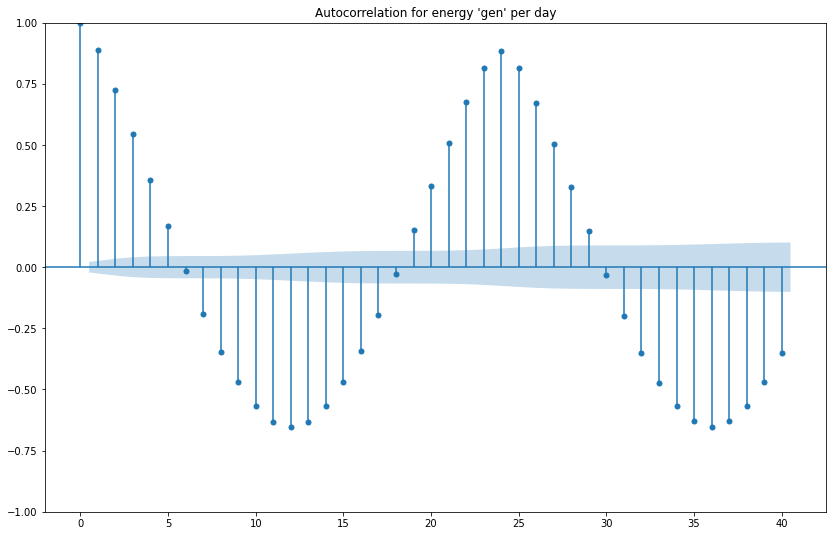

In [275]:
#Plot ACF for energy 'gen'

print("Autocorrelation for 'Solar' = ", df1['Solar'].autocorr())
fig = plot_acf(df1['Solar'], lags=40, title="Autocorrelation for energy 'gen' per day")
plt.show()
     

Data has positive autocorrelation. It provides good predictability with autocorrelation value = 0.888


Autocorrelation for 'House overall' =  0.7934855648573531


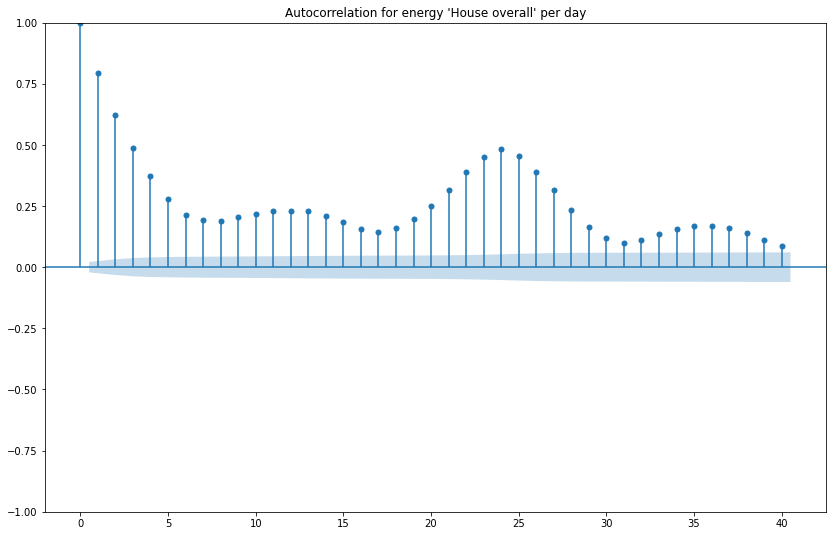

In [276]:
#Plot ACF for 'House overall'

print("Autocorrelation for 'House overall' = ", df1['House overall'].autocorr())
fig = plot_acf(df1['House overall'], lags=40, title="Autocorrelation for energy 'House overall' per day")
plt.show()

Data has positive autocorrelation. It provides good predictability with autocorrelation value = 0.793.

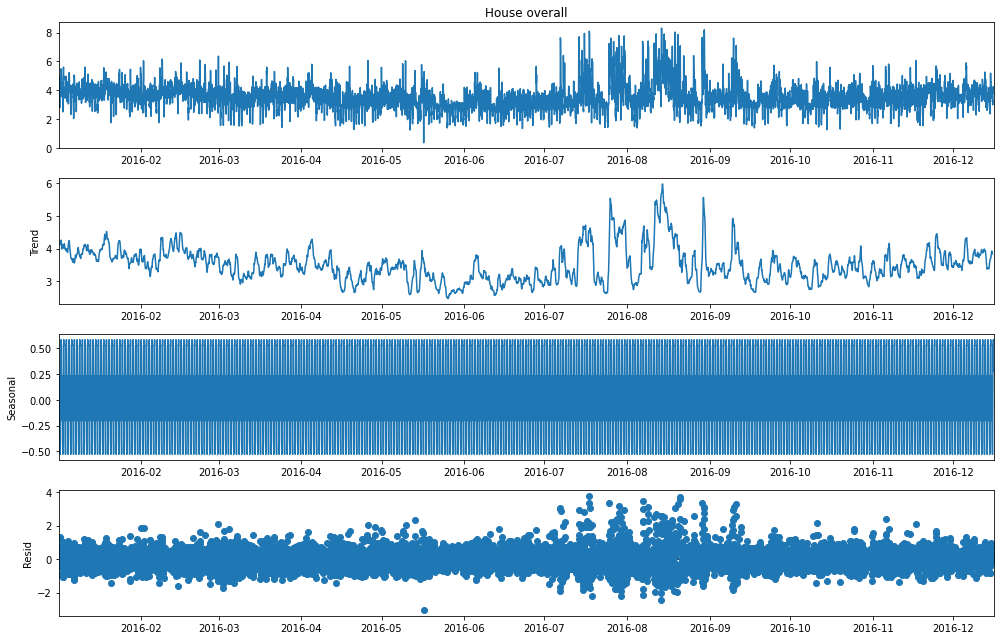

In [277]:
#Seasonal decomposition is performed on the dataset to see if there is seasonality displayed in the per-day dataset at a frequency of 30 days(monthly)

result = seasonal_decompose(df1['House overall'], model='additive')
result.plot()
plt.show()

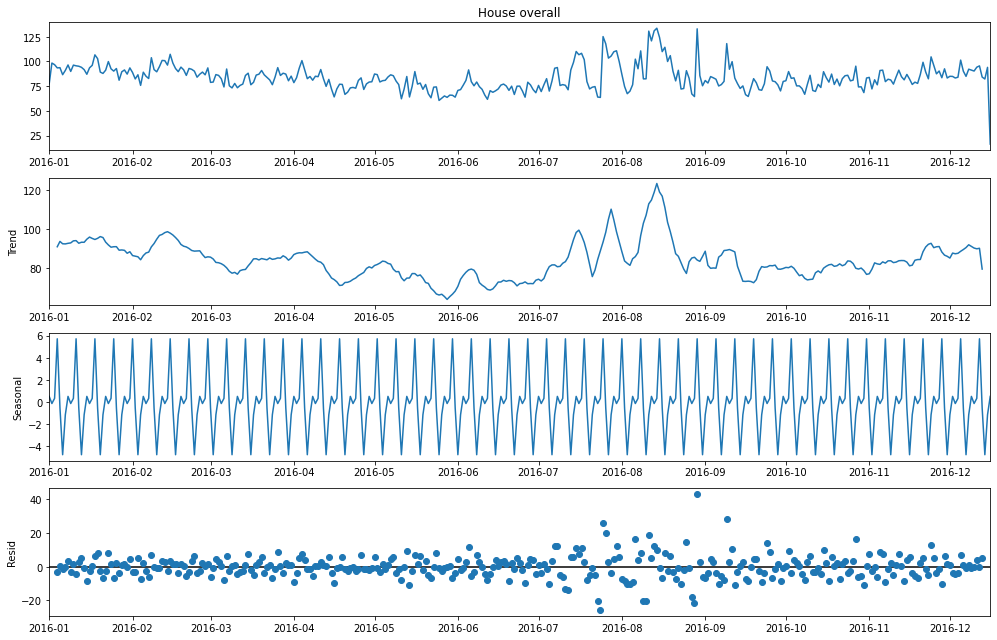

In [278]:

result = seasonal_decompose(energy_per_day2['House overall'], model='additive')
result.plot()
plt.show()

It is observed in the figure above that the per-day dataset displays a seasonal behavior at a frequency of 30

## **`3. Stationarity`**

In [279]:
X = energy_per_hour2.values
split = round(len(X) / 2)
X1, X2 = X[0:split], X[split:]
mean1, mean2 = X1.mean(), X2.mean()
var1, var2 = X1.var(), X2.var()

print('mean1=%f, mean2=%f' % (mean1, mean2))
print('variance1=%f, variance2=%f' % (var1, var2))

mean1=2.663901, mean2=2.143037
variance1=39.044900, variance2=20.283821


The dataset is splitted into two contiguous halves. Mean and variance is calculated for each subset. There is a little difference observed but it can be concluded that the values are essentially in the same ballpark.

## **Anomaly detection**

# HouseOverall

In [280]:
# Energy Per Day anomaly detection
data = energy_per_day2.filter(items=['House overall'])
df = data

isolation_forest = IsolationForest(n_estimators=100)
isolation_forest.fit(data.values.reshape(-1, 1))
xx = np.linspace(data.min(), data.max(), len(data)).reshape(-1,1)

df['scores']=isolation_forest.decision_function(df[['House overall']])
df['anomaly']=isolation_forest.predict(df[['House overall']])
df.head(5)

,House overall,scores,anomaly
time,,,
2016-01-01,77.293424,0.070290,1
2016-01-02,98.352177,-0.003072,-1
2016-01-03,96.721961,0.016880,1
2016-01-04,93.453877,0.067804,1
2016-01-05,93.680153,0.063898,1


In [281]:
anomaly=df.loc[df['anomaly']==-1]
anomaly_index=list(anomaly.index)
print(anomaly)

            House overall    scores  anomaly
time                                        
2016-01-02      98.352177 -0.003072       -1
2016-01-18     106.653876 -0.052092       -1
2016-01-19     102.823129 -0.040155       -1
2016-02-08     103.761491 -0.039369       -1
2016-02-12     101.002100 -0.015679       -1
...                   ...       ...      ...
2016-10-08      66.748246 -0.019807       -1
2016-10-30      68.442249 -0.020701       -1
2016-11-24     104.622622 -0.052366       -1
2016-12-05     101.347978 -0.021960       -1
2016-12-16      16.325007 -0.320728       -1

[65 rows x 3 columns]


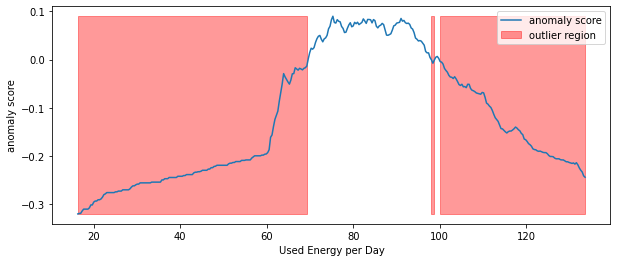

In [282]:
# Distribution of use energy per day
anomaly_score = isolation_forest.decision_function(xx)
outlier = isolation_forest.predict(xx)
plt.figure(figsize=(10,4))
plt.plot(xx, anomaly_score, label='anomaly score')
plt.fill_between(xx.T[0], np.min(anomaly_score), np.max(anomaly_score), 
                 where=outlier==-1, color='r', 
                 alpha=.4, label='outlier region')
plt.legend()
plt.ylabel('anomaly score')
plt.xlabel('Used Energy per Day')
plt.show();
     

In [ ]:
# Energy Per week anomaly detection
data = energy_per_week2.filter(items=['House overall'])
df = data

isolation_forest = IsolationForest(n_estimators=100)
isolation_forest.fit(data.values.reshape(-1, 1))
xx = np.linspace(data.min(), data.max(), len(data)).reshape(-1,1)

df['scores']=isolation_forest.decision_function(df[['House overall']])
df['anomaly']=isolation_forest.predict(df[['House overall']])
df.head(5)

In [284]:

anomaly=df.loc[df['anomaly']==-1]
anomaly_index=list(anomaly.index)
print(anomaly)
     

            House overall    scores  anomaly
time                                        
2016-01-03     272.367561 -0.292857       -1
2016-02-14     677.838712 -0.028624       -1
2016-05-29     466.033186 -0.105073       -1
2016-06-26     496.129819 -0.004164       -1
2016-07-31     772.169424 -0.176242       -1
2016-08-14     791.389815 -0.208050       -1
2016-08-21     724.843205 -0.125234       -1
2016-12-18     372.201920 -0.204790       -1


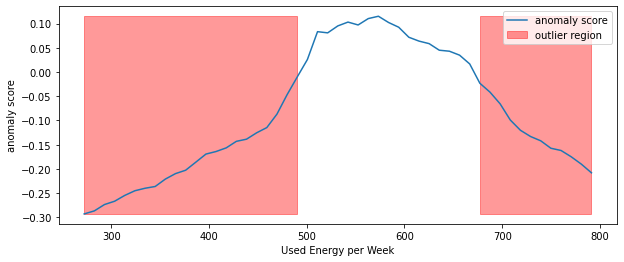

In [285]:

# Distribution of use energy per week
anomaly_score = isolation_forest.decision_function(xx)
outlier = isolation_forest.predict(xx)
plt.figure(figsize=(10,4))
plt.plot(xx, anomaly_score, label='anomaly score')
plt.fill_between(xx.T[0], np.min(anomaly_score), np.max(anomaly_score), 
                 where=outlier==-1, color='r', 
                 alpha=.4, label='outlier region')
plt.legend()
plt.ylabel('anomaly score')
plt.xlabel('Used Energy per Week')
plt.show();

In [286]:
# Energy Per month anomaly detection
data = energy_per_month2.filter(items=['House overall'])
df = data

isolation_forest = IsolationForest(n_estimators=100)
isolation_forest.fit(data.values.reshape(-1, 1))
xx = np.linspace(data.min(), data.max(), len(data)).reshape(-1,1)

df['scores']=isolation_forest.decision_function(df[['House overall']])
df['anomaly']=isolation_forest.predict(df[['House overall']])
df.head(5)

,House overall,scores,anomaly
time,,,
2016-01-31,2868.107040,-0.009703,-1
2016-02-29,2642.830100,0.039018,1
2016-03-31,2557.625929,0.095230,1
2016-04-30,2385.348559,0.091717,1
2016-05-31,2304.792569,0.050007,1


In [287]:

anomaly=df.loc[df['anomaly']==-1]
anomaly_index=list(anomaly.index)
print(anomaly)

            House overall    scores  anomaly
time                                        
2016-01-31    2868.107040 -0.009703       -1
2016-06-30    2199.149466 -0.016859       -1
2016-08-31    2921.161730 -0.056954       -1
2016-12-31    1353.345368 -0.272903       -1


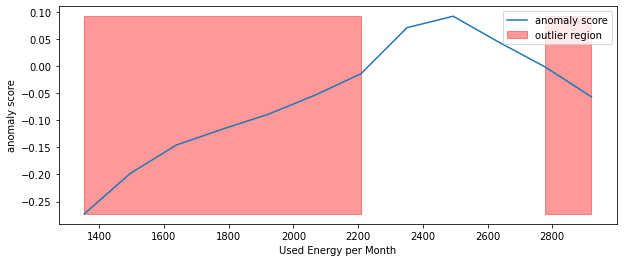

In [288]:

# Distribution of use energy per month
anomaly_score = isolation_forest.decision_function(xx)
outlier = isolation_forest.predict(xx)
plt.figure(figsize=(10,4))
plt.plot(xx, anomaly_score, label='anomaly score')
plt.fill_between(xx.T[0], np.min(anomaly_score), np.max(anomaly_score), 
                 where=outlier==-1, color='r', 
                 alpha=.4, label='outlier region')
plt.legend()
plt.ylabel('anomaly score')
plt.xlabel('Used Energy per Month')
plt.show();

## **Plotting Moving Average**

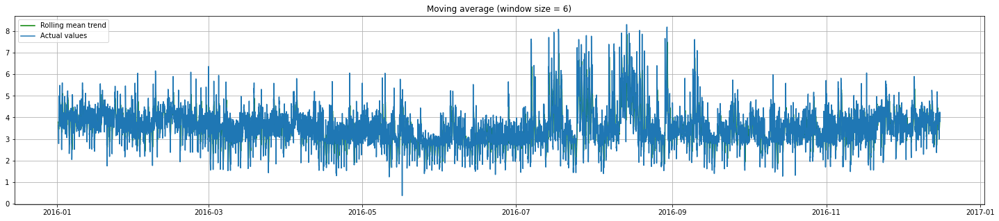

In [289]:
from sklearn.metrics import r2_score, median_absolute_error, mean_absolute_error
from sklearn.metrics import median_absolute_error, mean_squared_error, mean_squared_log_error

l1=[]
def plotMovingAverage(series, window, plot_intervals=False, scale=1.96, plot_anomalies=False):
    rolling_mean = series.rolling(window=window).mean()

    plt.figure(figsize=(25,5))
    plt.title("Moving average (window size = {})".format(window))
    plt.plot(rolling_mean, "g", label="Rolling mean trend")

  # Plot confidence intervals for smoothed values
    if plot_intervals:
        mae = mean_absolute_error(series[window:], rolling_mean[window:])
        deviation = np.std(series[window:] - rolling_mean[window:])
        lower_bond = rolling_mean - (mae + scale * deviation)
        upper_bond = rolling_mean + (mae + scale * deviation)
        plt.plot(upper_bond, "r--", label="Upper Bond / Lower Bond")
        plt.plot(lower_bond, "r--")
               
      
      # Having the intervals, find abnormal values
        if plot_anomalies:
            anomalies = pd.DataFrame(index=series.index, columns=series.columns)
            anomalies[series>upper_bond] = series[series>upper_bond]
            plt.plot(anomalies, marker="o",markerfacecolor='red', markersize=12)
            
            #l1[:n_samples]=[upper_bond]
            #l2[:n_samples]=[lower_bond]
            print(anomalies.values)
            l1.append(anomalies.values)
            
            
    plt.plot(series[window:], label="Actual values")
    plt.legend(loc="upper left")
    plt.grid(True)

n_samples = 8399 # 1 month
data = energy_per_hour2.filter(items=['House overall'])
plotMovingAverage(data[:n_samples], window=6) # A window of 6 hours

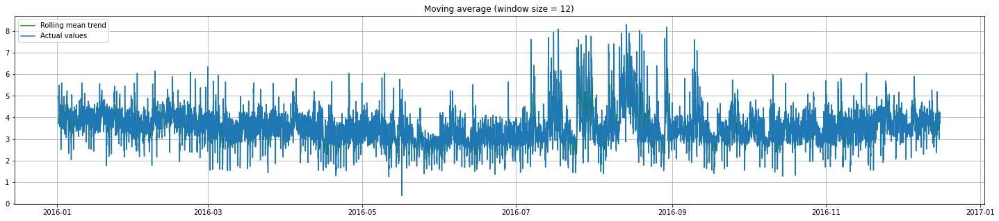

In [290]:
plotMovingAverage(data[:n_samples], window=12) # A window of 12 hours

[[nan]
 [nan]
 [nan]
 ...
 [nan]
 [nan]
 [nan]]


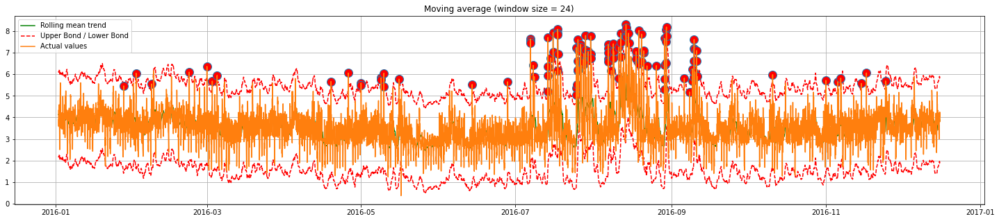

In [291]:
plotMovingAverage(data[:n_samples], window=24, plot_intervals=True ,plot_anomalies=True)

In [ ]:
from sklearn.metrics import r2_score, median_absolute_error, mean_absolute_error
from sklearn.metrics import median_absolute_error, mean_squared_error, mean_squared_log_error

l1=[]
def plotMovingAverage(series, window, plot_intervals=False, scale=1.96, plot_anomalies=False):
    rolling_mean = series.rolling(window=window).mean()

    plt.figure(figsize=(25,5))
    plt.title("Moving average (window size = {})".format(window))
    plt.plot(rolling_mean, "g", label="Rolling mean trend")

  # Plot confidence intervals for smoothed values
    if plot_intervals:
        mae = mean_absolute_error(series[window:], rolling_mean[window:])
        deviation = np.std(series[window:] - rolling_mean[window:])
        lower_bond = rolling_mean - (mae + scale * deviation)
        upper_bond = rolling_mean + (mae + scale * deviation)
        plt.plot(upper_bond, "r--", label="Upper Bond / Lower Bond")
        plt.plot(lower_bond, "r--")
         
        
      
      # Having the intervals, find abnormal values
        if plot_anomalies:
            anomalies = pd.DataFrame(index=series.index, columns=series.columns)
            anomalies[series>upper_bond] = series[series>upper_bond]
            plt.plot(anomalies, marker="o",markerfacecolor='red', markersize=12)
            
            #l1[:n_samples]=[upper_bond]
            #l2[:n_samples]=[lower_bond]
            print(anomalies.values)
            l1.append(anomalies.values)
            
            
    plt.plot(series[window:], label="Actual values")
    plt.legend(loc="upper left")
    plt.grid(True)

n_samples = 24*30 # 1 month
data = energy_per_day2.filter(items=['House overall'])
plotMovingAverage(data[:n_samples], window=6) # A window of 6 hours

In [ ]:
plotMovingAverage(data[:n_samples], window=12) # A window of 12 hours

[[nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]
 [nan]

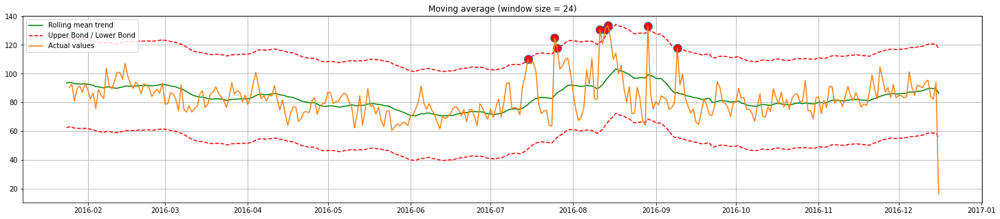

In [293]:
plotMovingAverage(data[:n_samples], window=24, plot_intervals=True ,plot_anomalies=True)

#plotting the moving average of all columns 

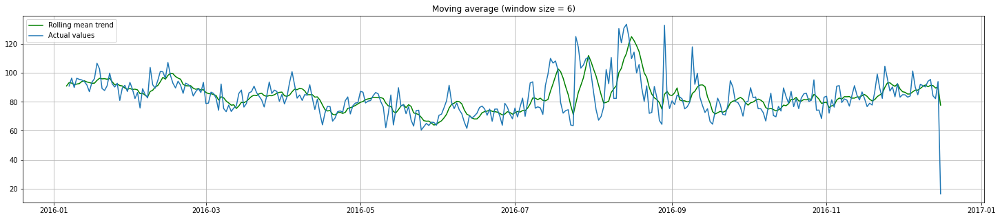

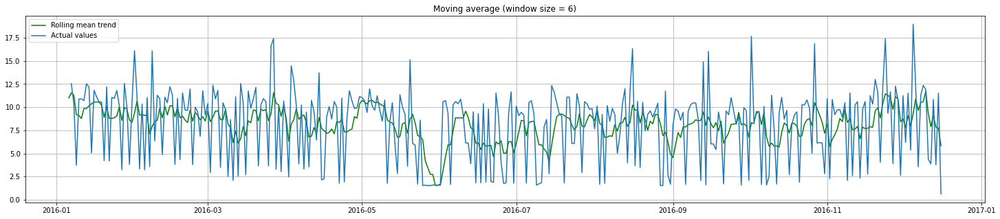

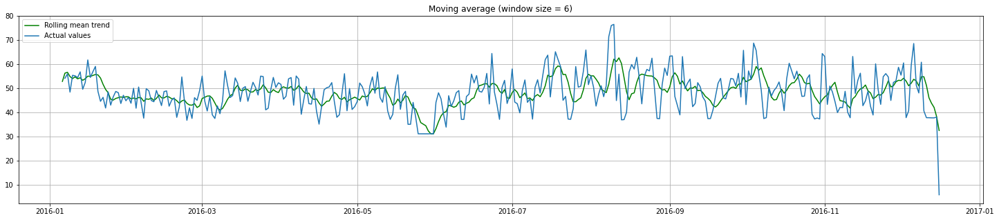

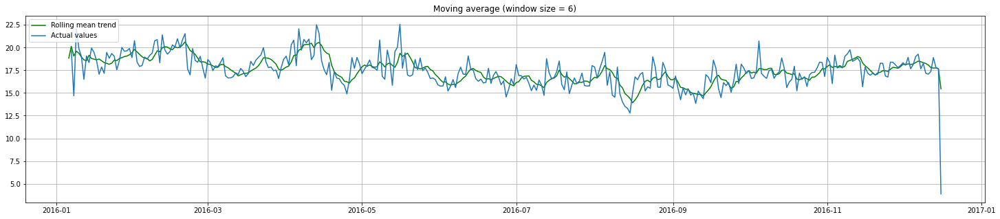

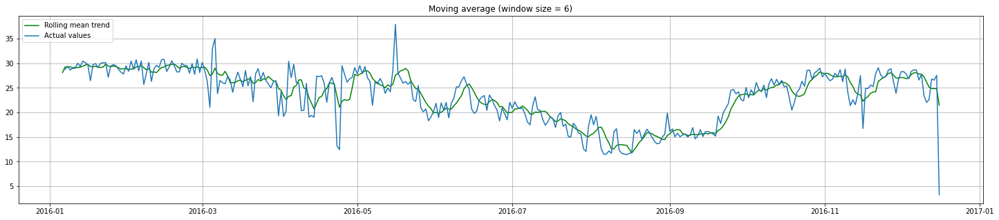

...

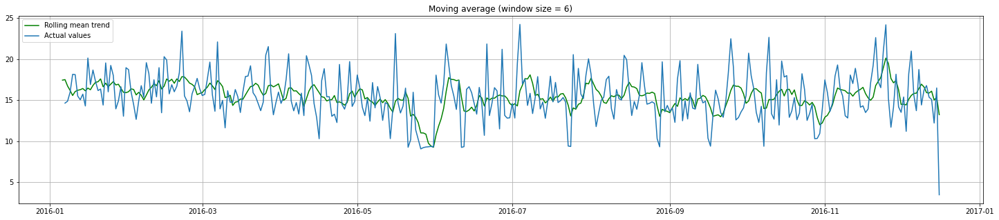

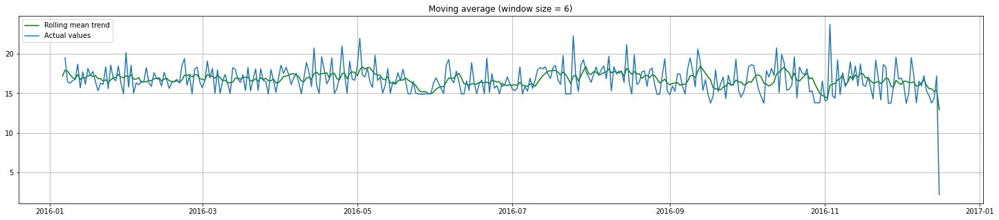

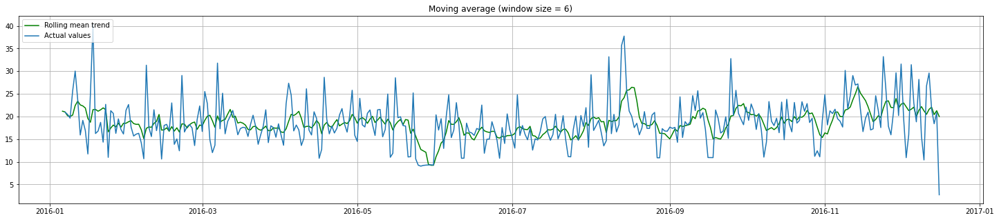

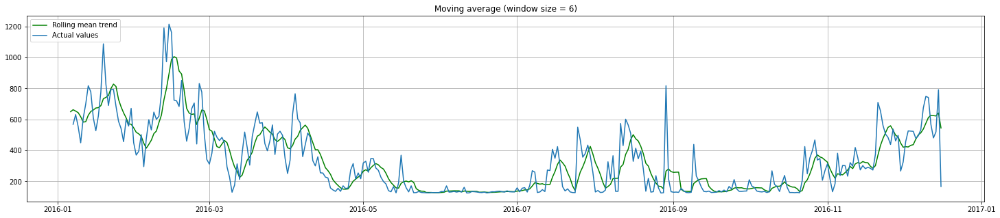

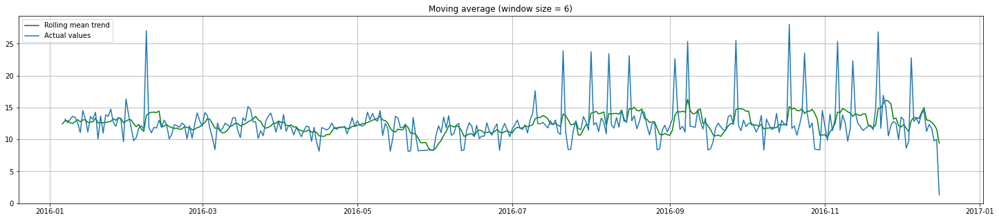

In [294]:
n_samples = 24*30 # 1 month
for i in energy_per_day2.columns:
  data = energy_per_day2[i]
  plotMovingAverage(data[:n_samples], window=6) # A window of 6 hours

## **House Overall**

In [ ]:

data = energy_per_day.filter(items=['House overall'])
plotMovingAverage(data[:n_samples], window=6) # A window of 6 hours
     

In [ ]:

plotMovingAverage(data[:n_samples], window=12) # A window of 12 hours

## **Part 7 - Time Series Forecasting using ARIMA model**

Autocorrelation for 'use' =  0.6121541316198315


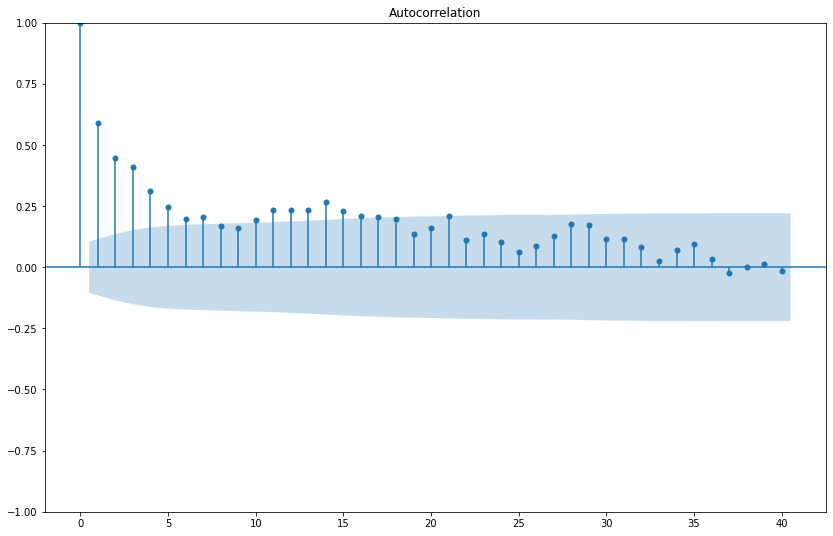

In [295]:

#Autocorrelation plot is used to find the AR parameter p of the ARIMA model
print("Autocorrelation for 'use' = ", energy_per_day2['House overall'].autocorr())
fig= plot_acf(energy_per_day2['House overall'], lags=40)
plt.show()

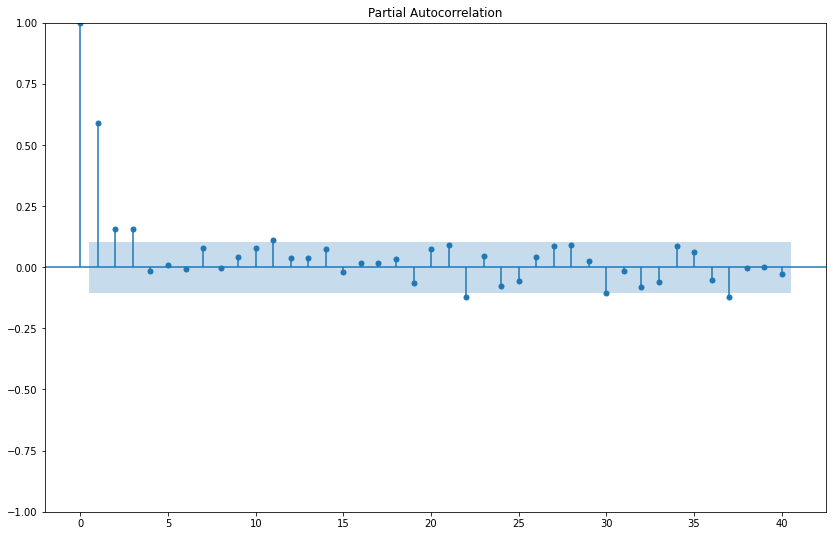

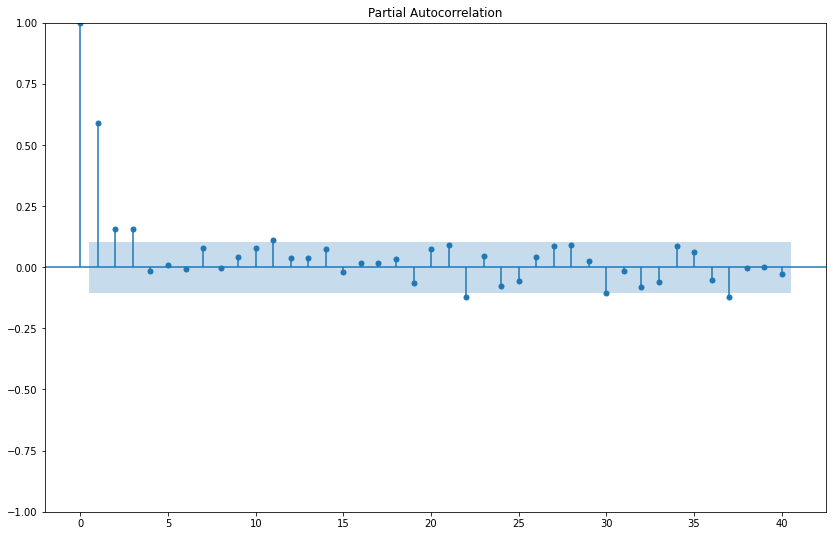

In [296]:
plot_pacf(energy_per_day2['House overall'], lags=40)

In [297]:

#We initially trained the model on a resampled dataset with 20,000 records but since it takes a
#lot of time in the order of several hours depending on the p,d,q combinations of ARIMA we have 
#resampled the data with just 2000 records for the convenience of reducing the time of execution 

#Randomly selects the number of records passes to the attribute n
home_arima_df= df1[0:2000]

Autocorrelation for {}=  0.6121541316198315


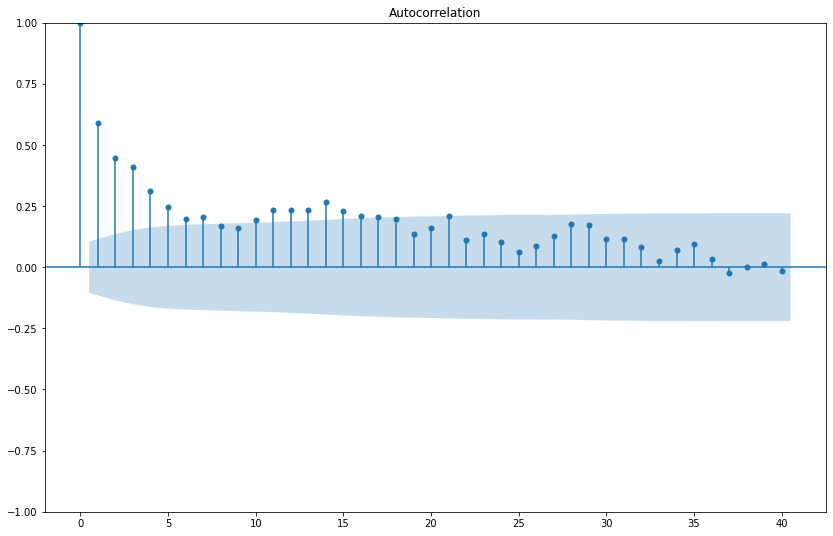

In [298]:
print("Autocorrelation for {}= ",energy_per_day2['House overall'].autocorr())
fig= plot_acf(energy_per_day2['House overall'], lags=40)
plt.show()

Autocorrelation for House overall=  0.7934855648573531


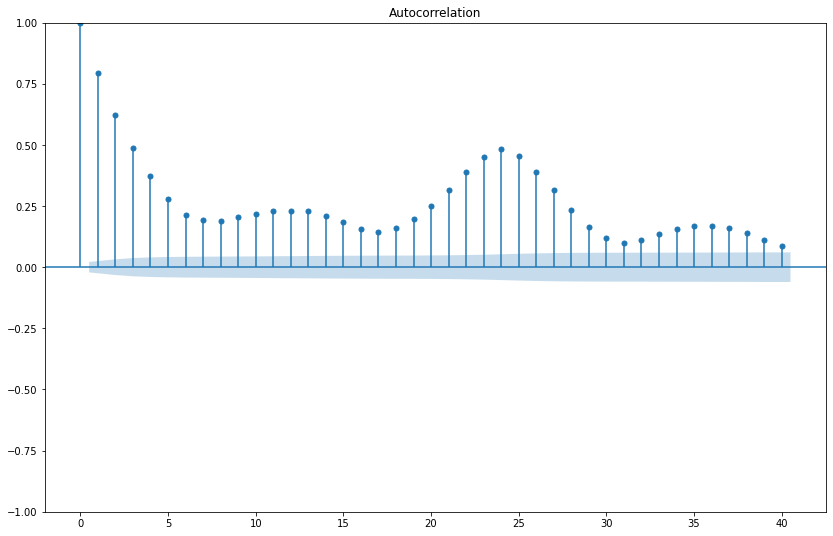

Autocorrelation for Dishwasher=  0.5940846456469164


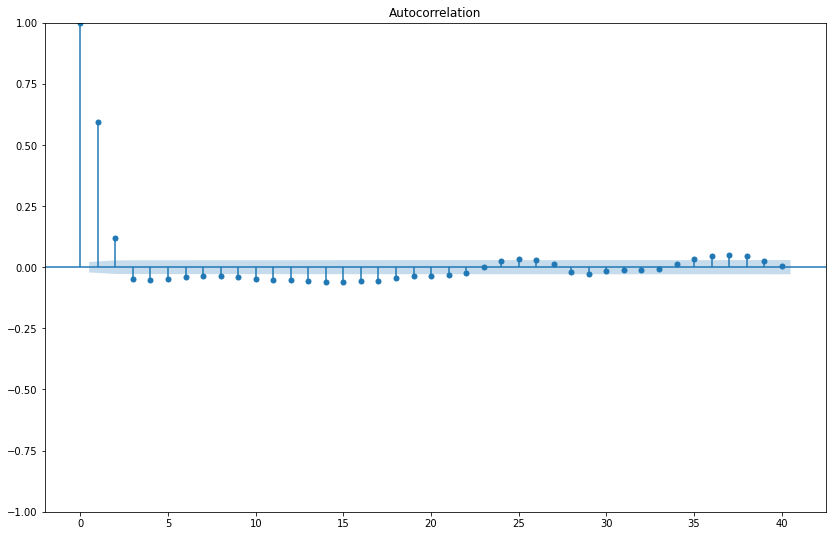

Autocorrelation for Home office=  0.655074727760621


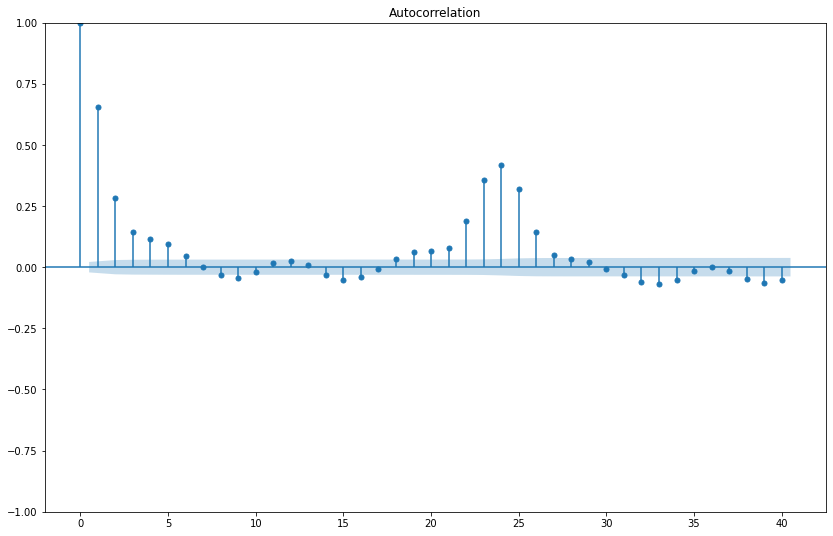

Autocorrelation for Fridge=  -0.14340932464837933


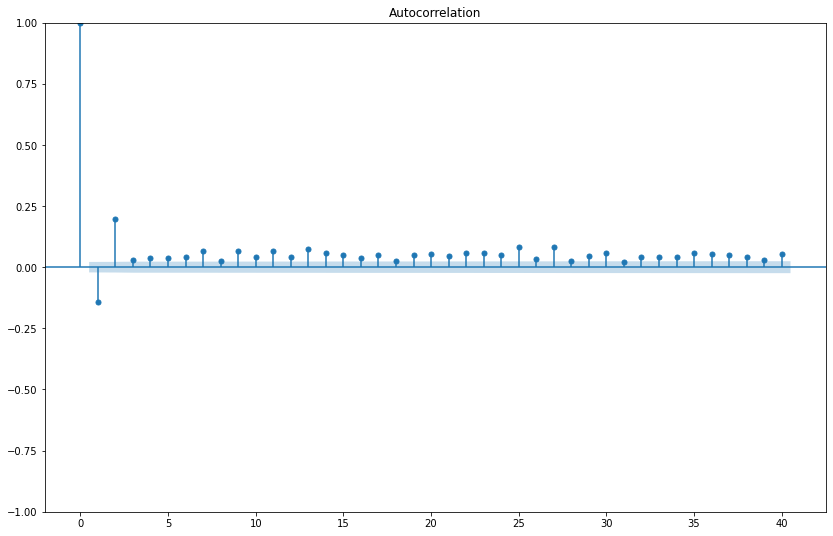

Autocorrelation for Wine cellar=  0.5540453152771538


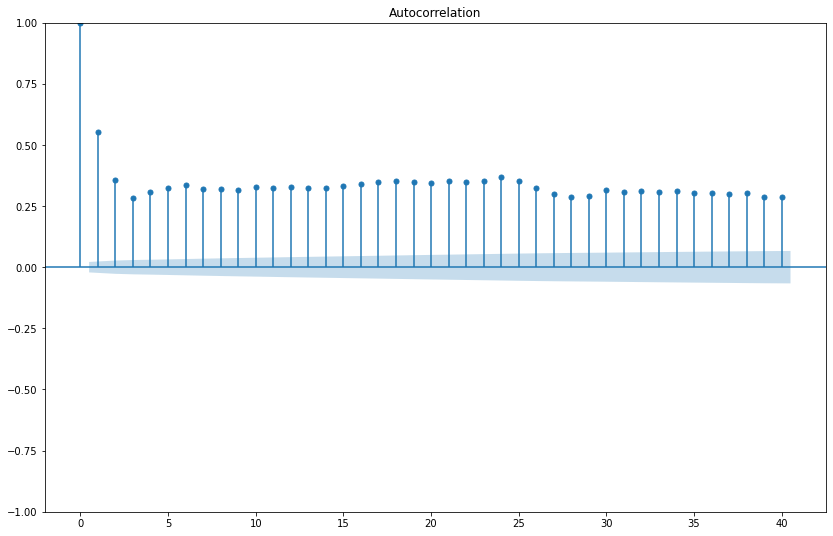

Autocorrelation for Garage door=  0.2398463136026695


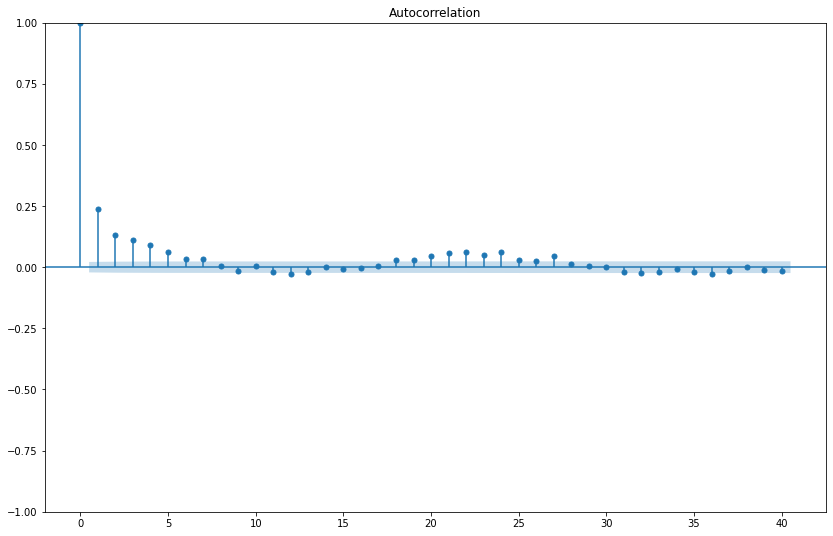

Autocorrelation for Barn=  0.6714379603547359


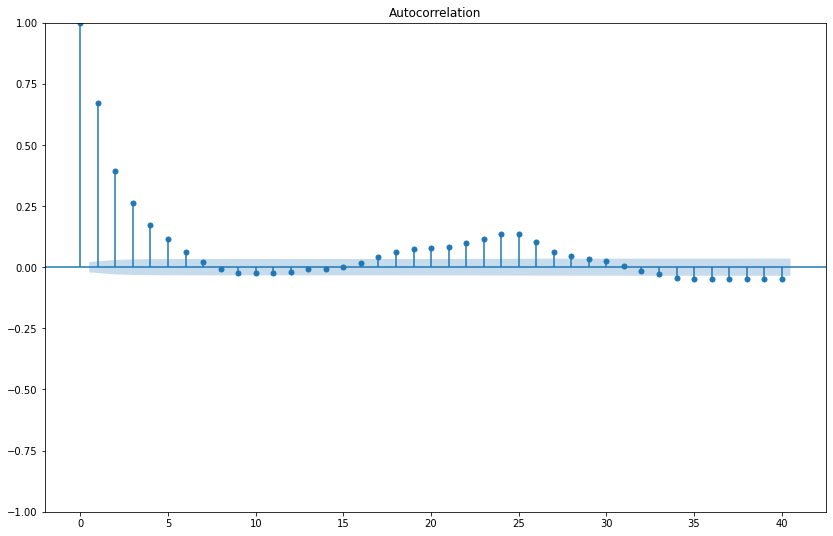

Autocorrelation for Well=  0.18057717517778954


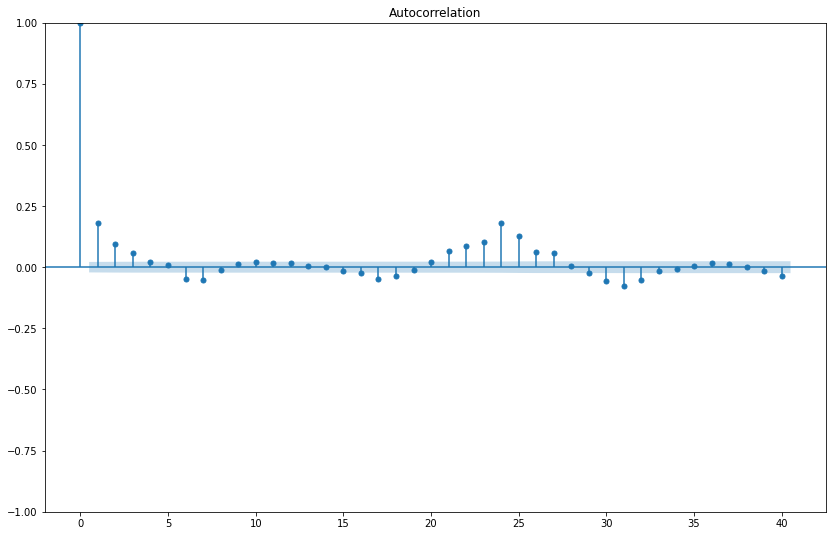

Autocorrelation for Microwave=  0.1109519502774009


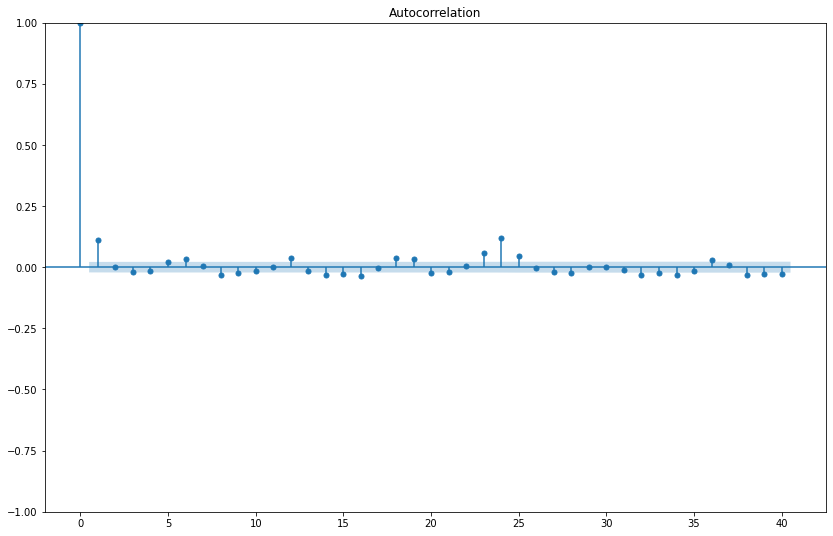

Autocorrelation for Living room=  0.4880134669707023


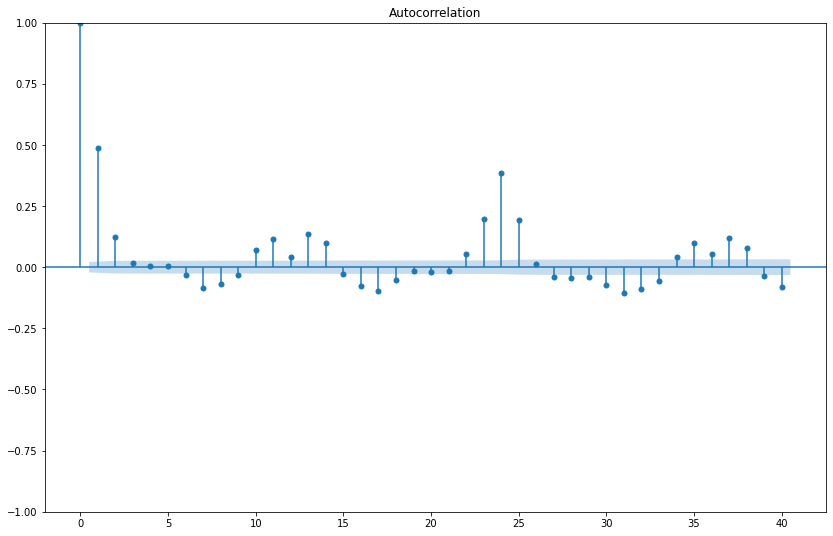

Autocorrelation for Solar=  0.888665749332324


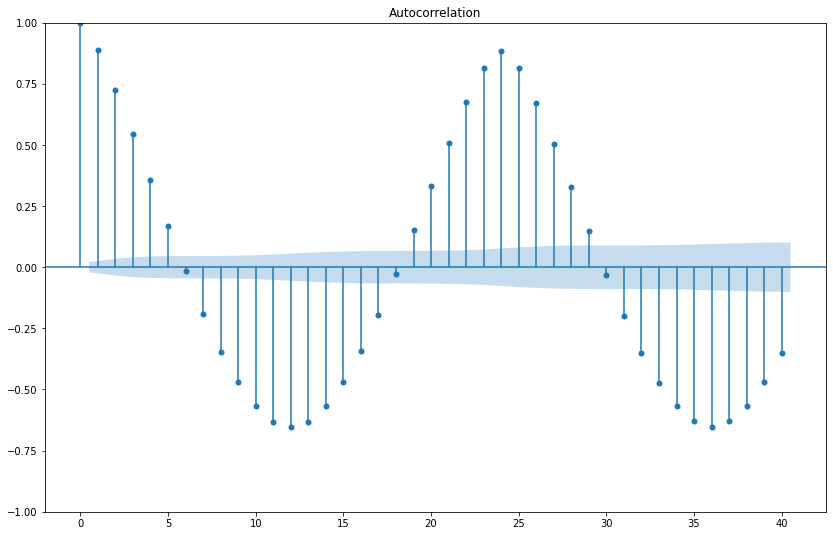

Autocorrelation for Furnace=  0.7848839683311482


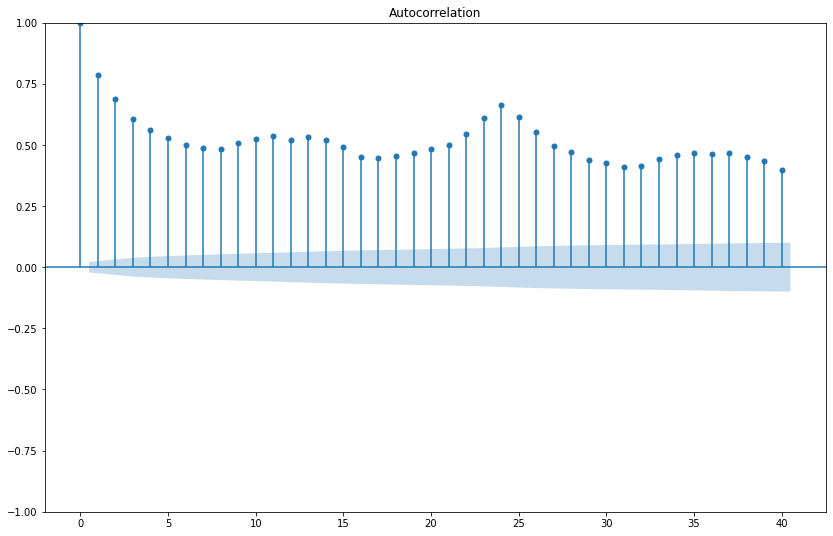

Autocorrelation for Kitchen=  0.18894085220585222


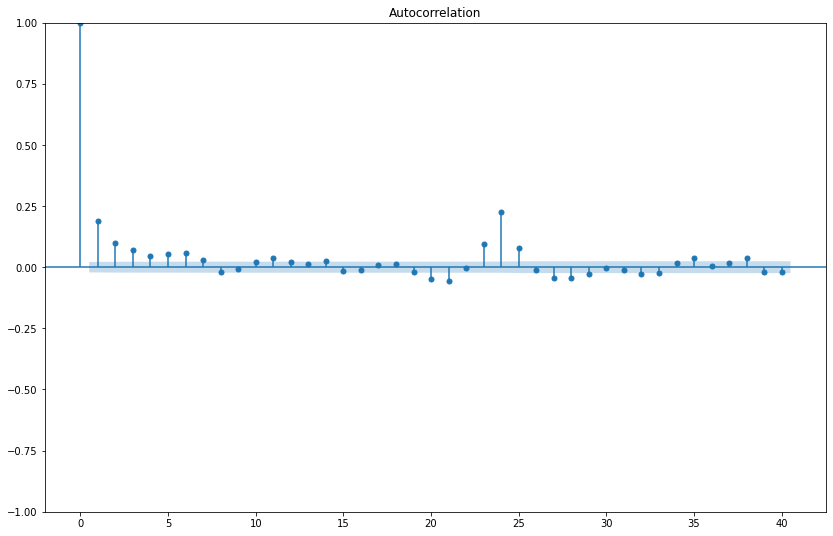

Autocorrelation for temperature=  0.9942025937175333


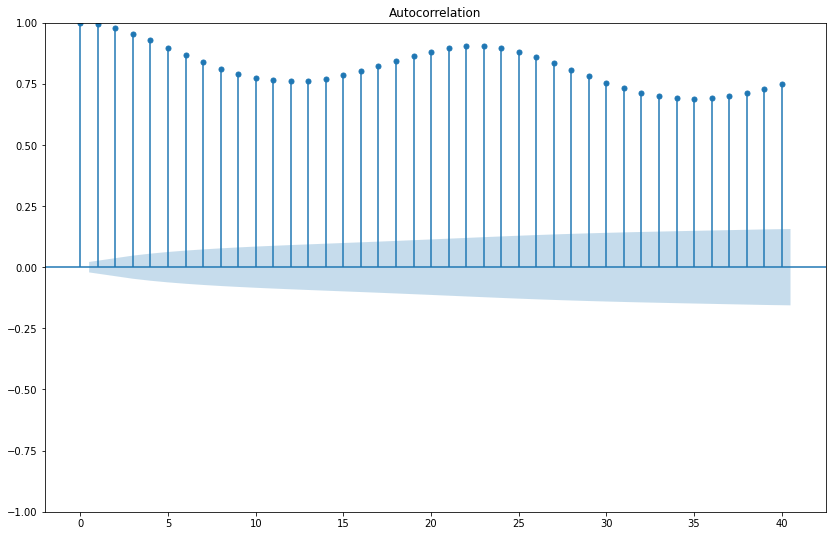

Autocorrelation for humidity=  0.9712519461313207


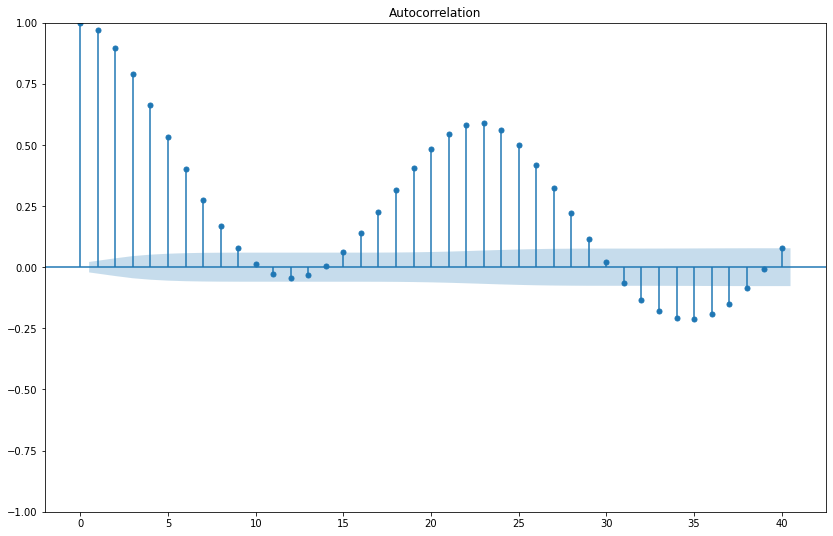

Autocorrelation for pressure=  0.9970334039507314


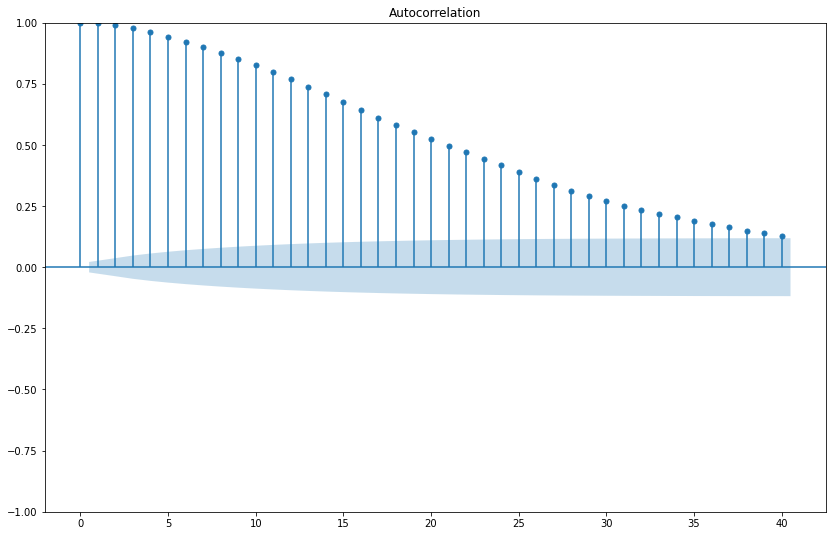

Autocorrelation for windSpeed=  0.9262153453865151


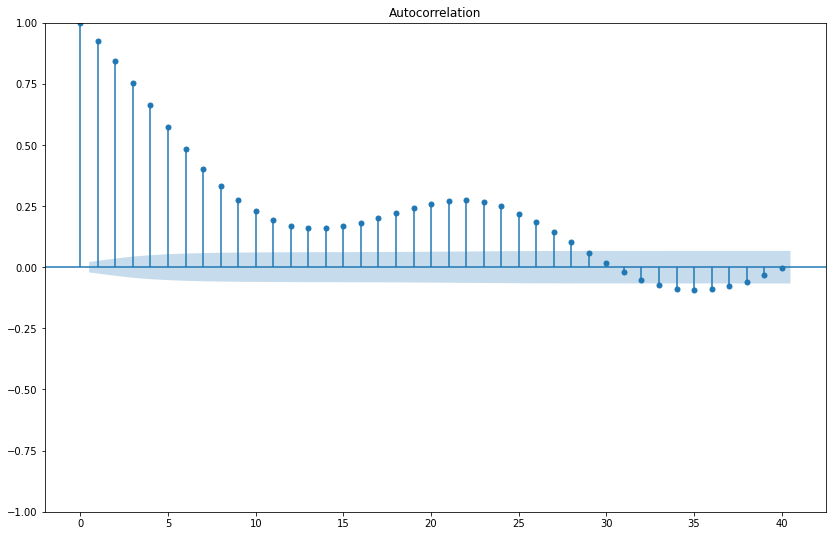

Autocorrelation for dewPoint=  0.997429850755743


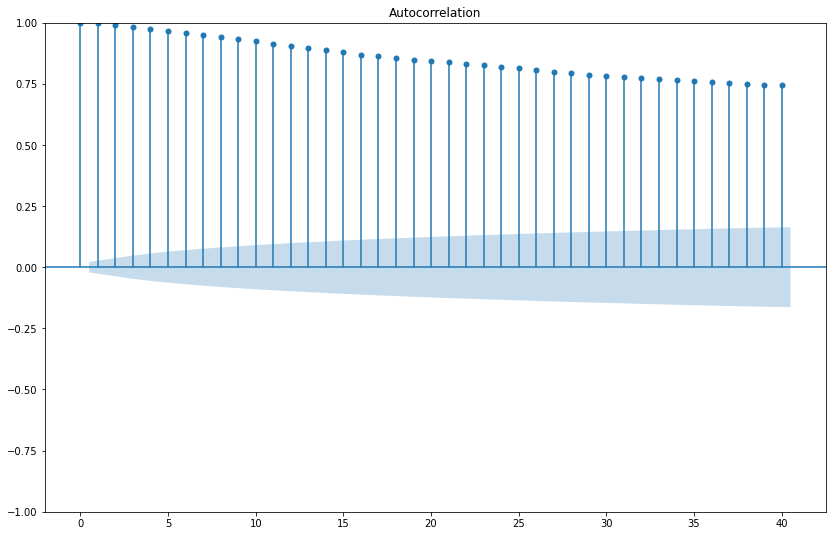

In [299]:

#Autocorrelation plot is used to find the AR parameter p of the ARIMA model

for i in df1.columns:
  print("Autocorrelation for {}= ".format(i),df1[i].autocorr())
  array = np.array(df1[i]).reshape(-1,1)
  fig= plot_acf(df1[i], lags=40)
  plt.show()

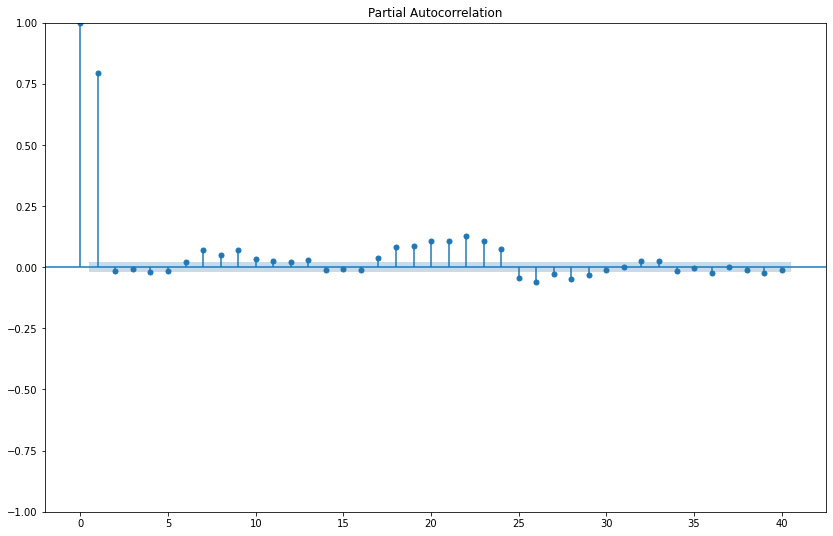

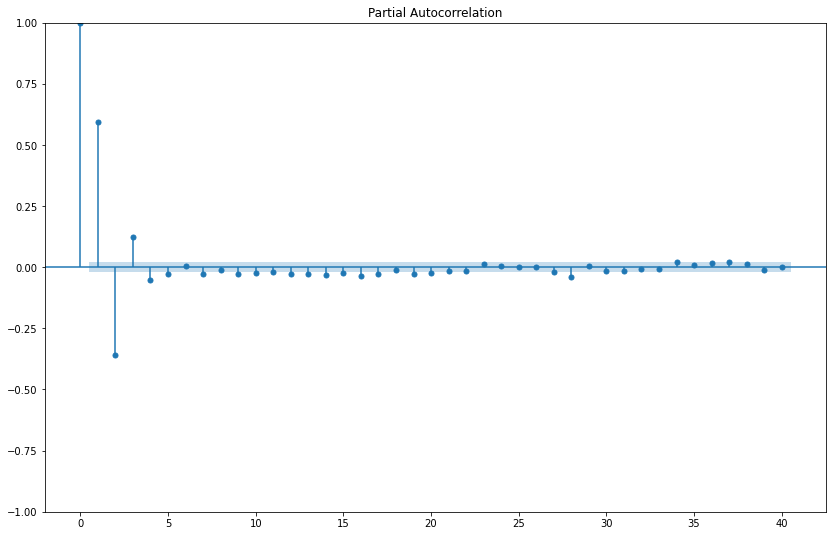

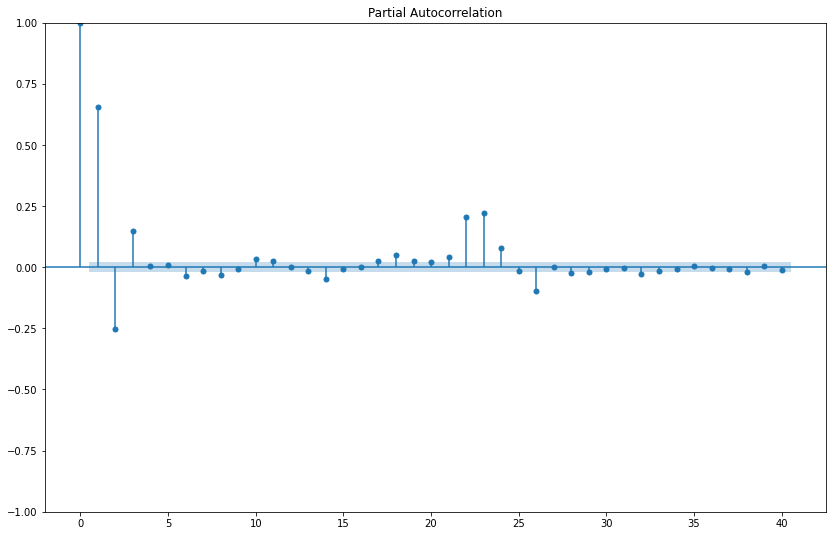

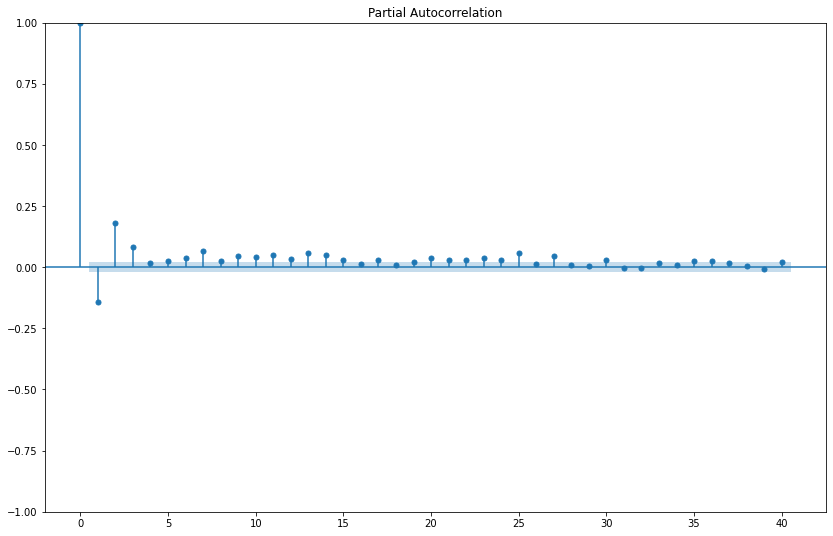

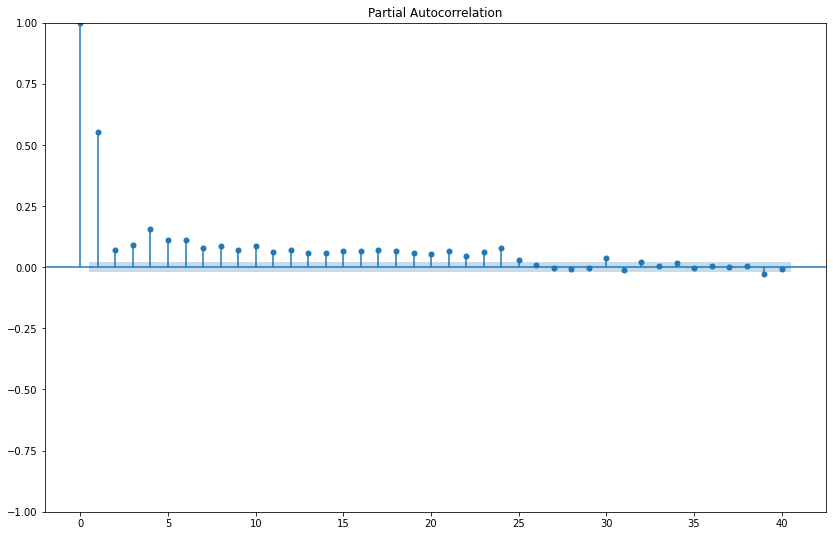

...

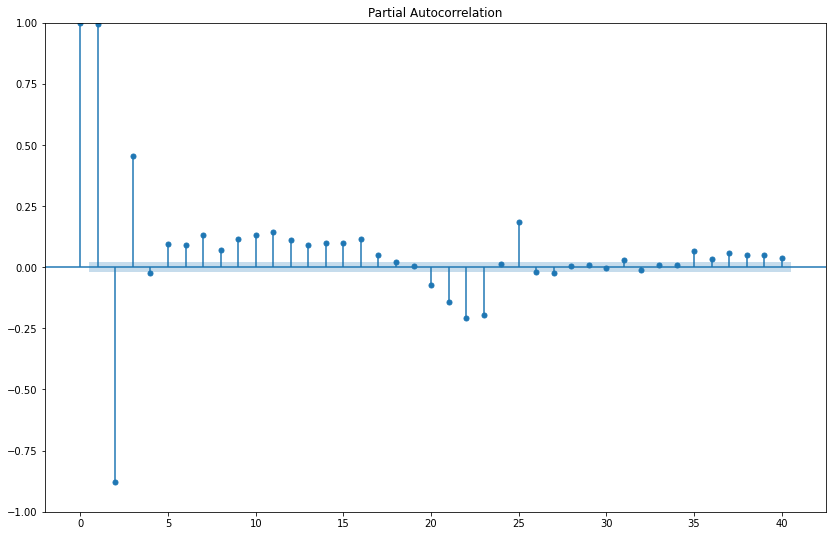

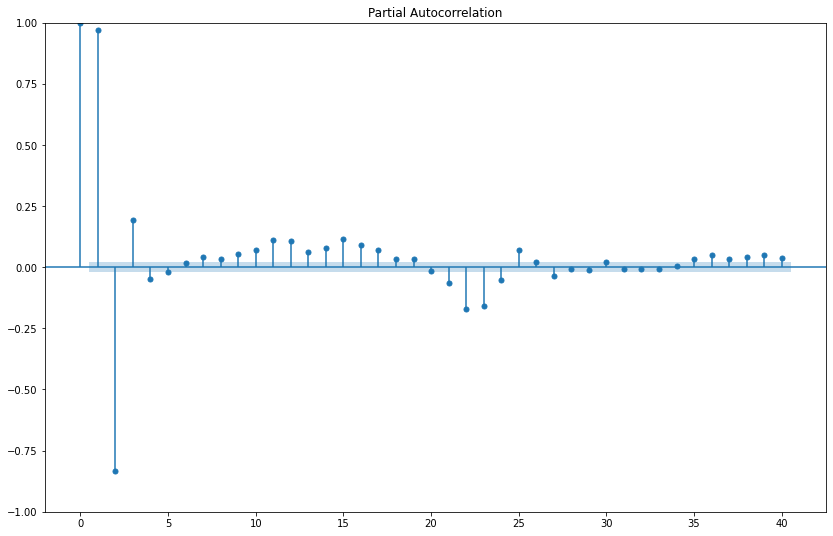

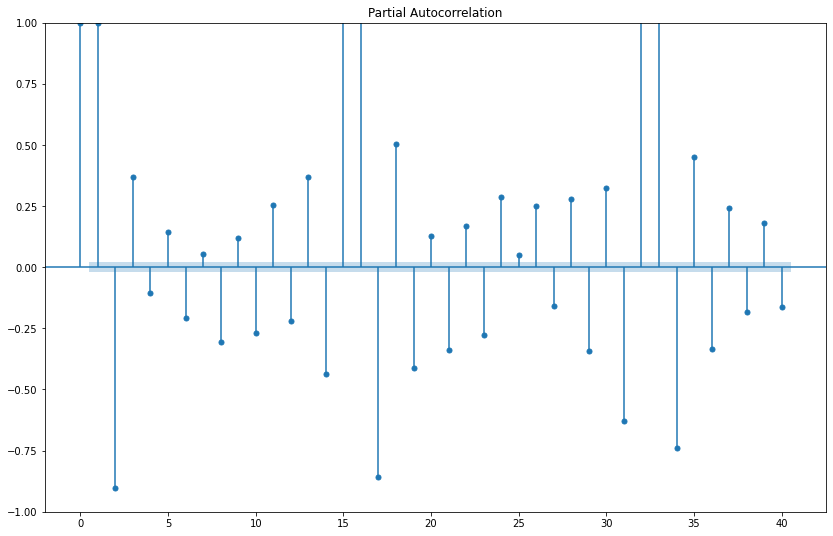

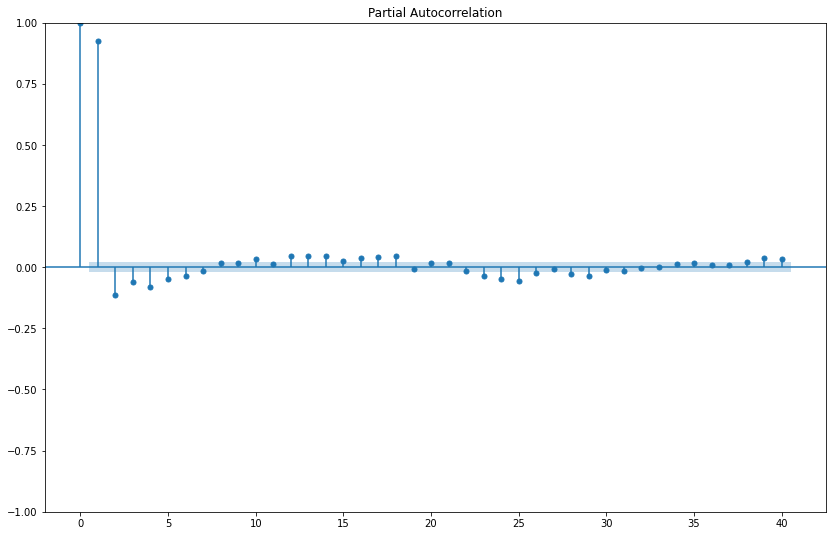

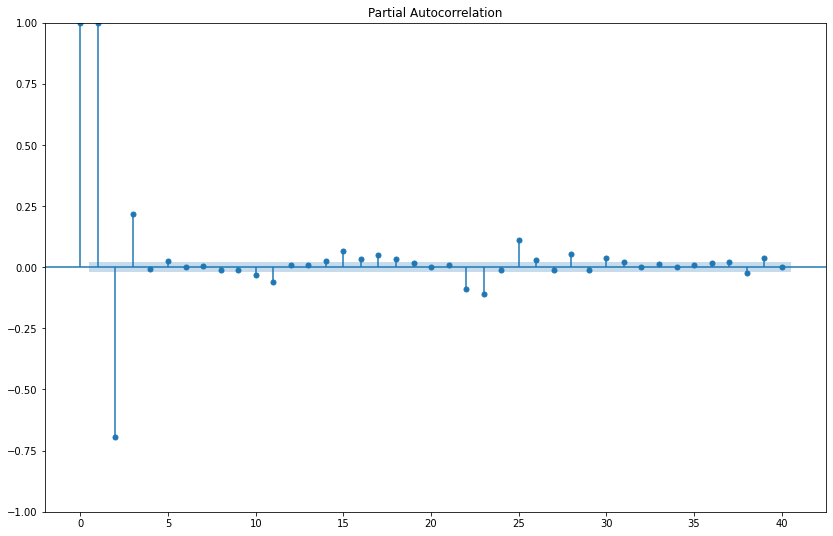

In [300]:
for i in df1.columns:
  plot_pacf(df1[i], lags=40)
  plt.show()

In [301]:
home_arima_df= df1[0:2000]

Autocorrelation for House overall=  0.7934855648573531


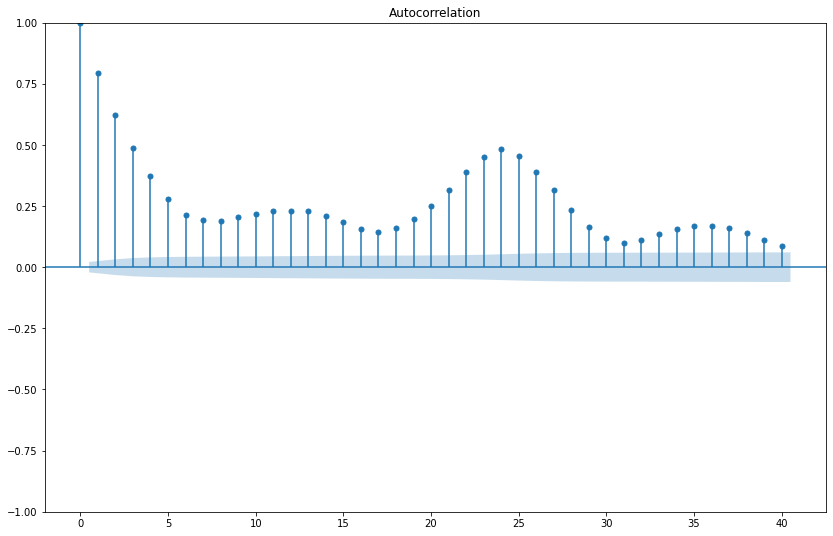

Autocorrelation for Dishwasher=  0.5940846456469164


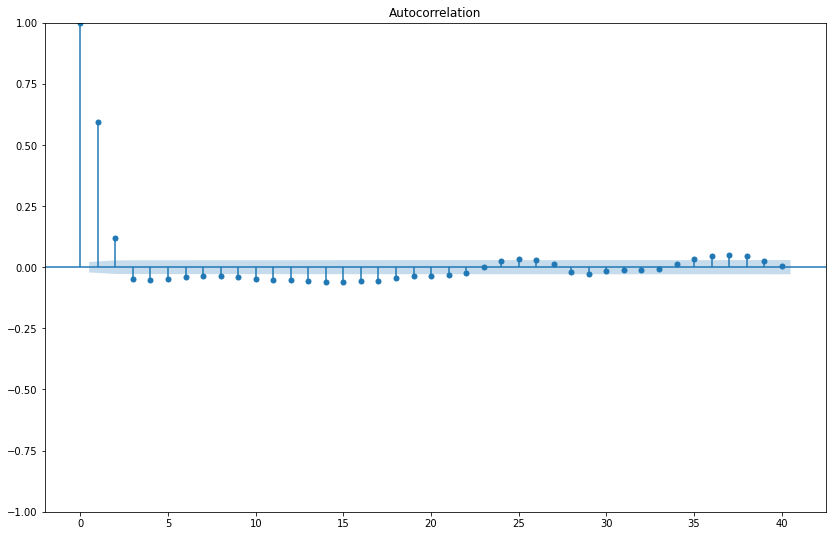

Autocorrelation for Home office=  0.655074727760621


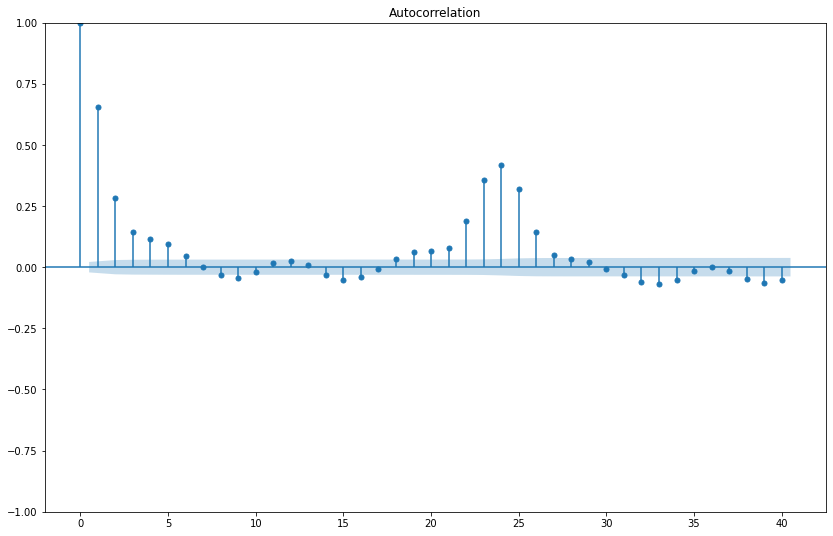

Autocorrelation for Fridge=  -0.14340932464837933


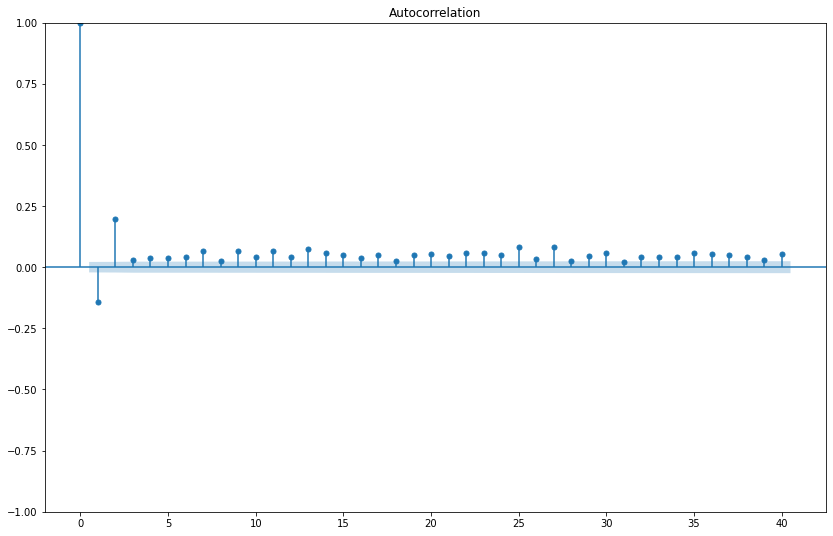

Autocorrelation for Wine cellar=  0.5540453152771538


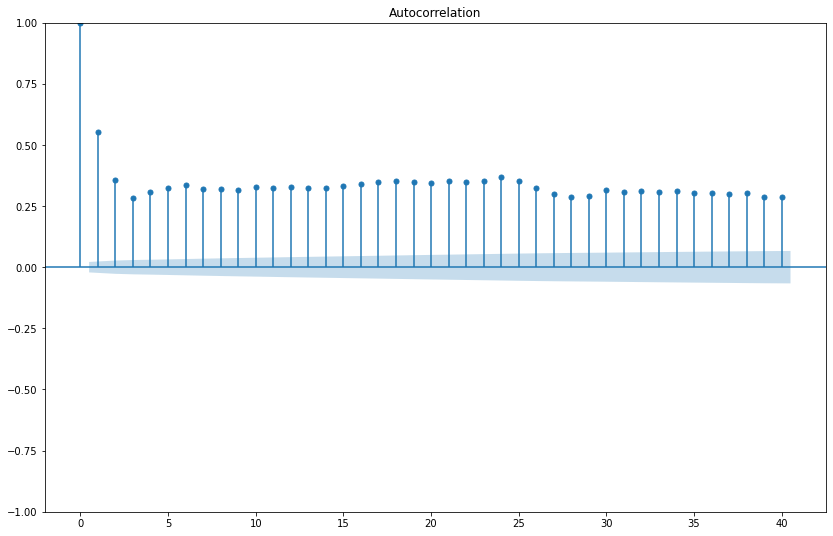

Autocorrelation for Garage door=  0.2398463136026695


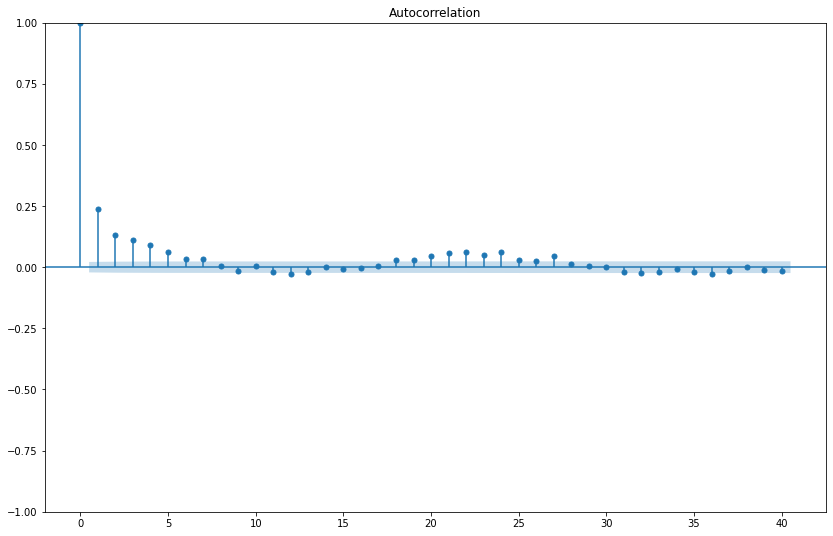

Autocorrelation for Barn=  0.6714379603547359


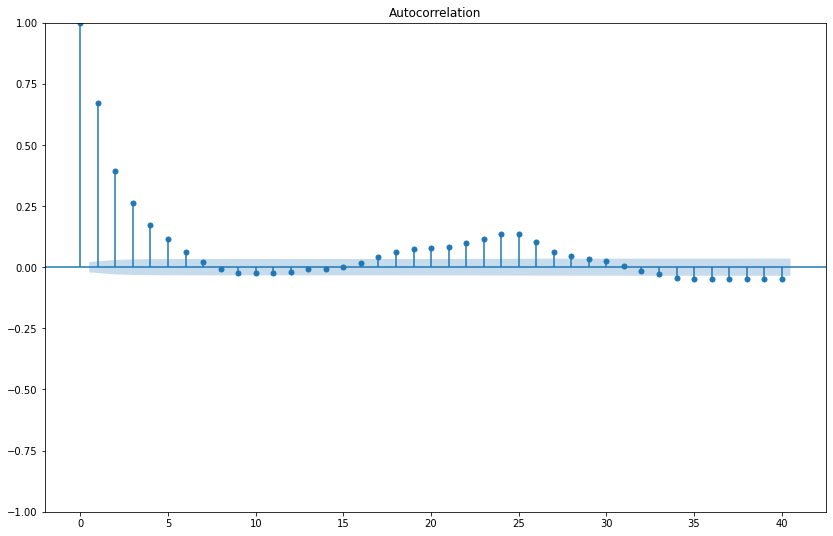

Autocorrelation for Well=  0.18057717517778954


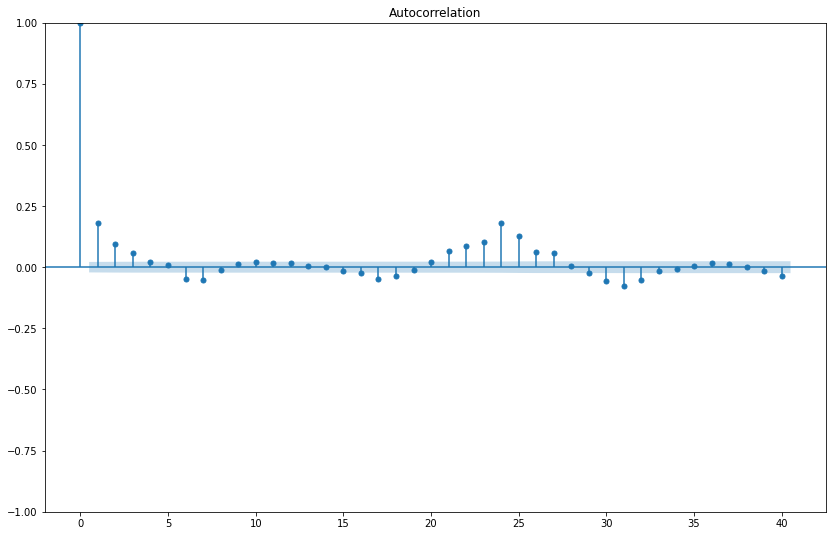

Autocorrelation for Microwave=  0.1109519502774009


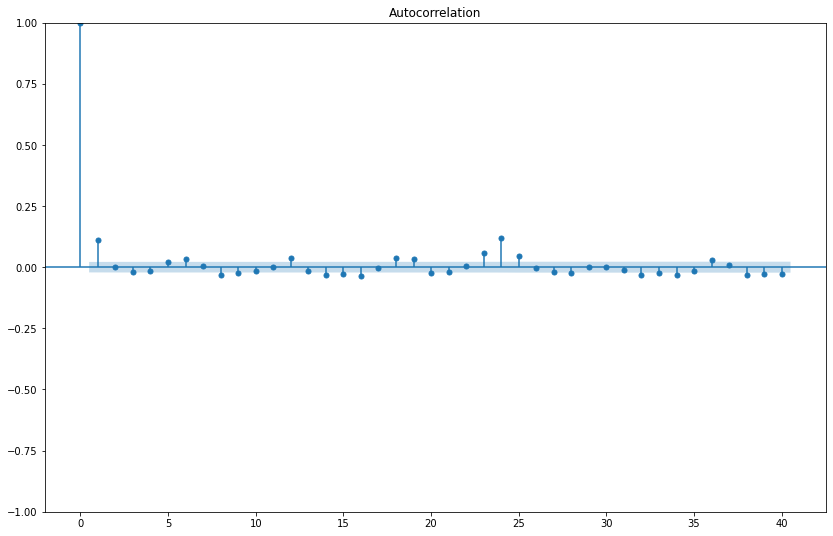

Autocorrelation for Living room=  0.4880134669707023


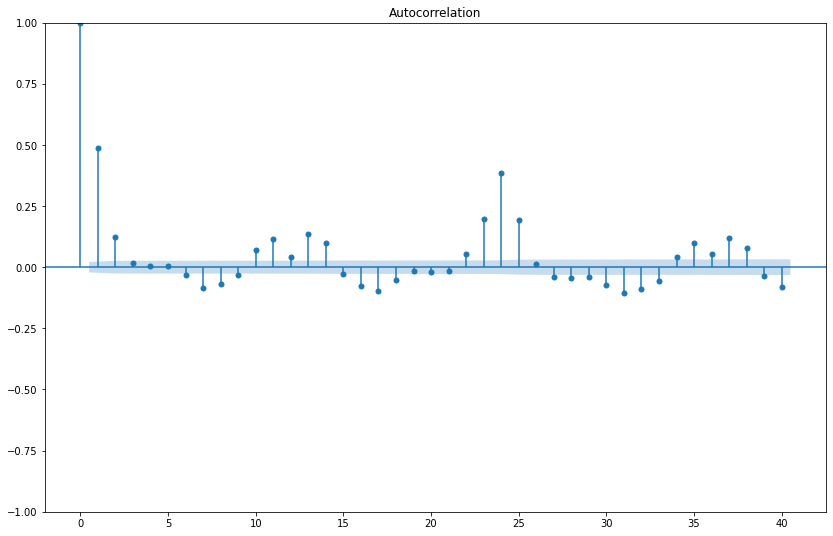

Autocorrelation for Solar=  0.888665749332324


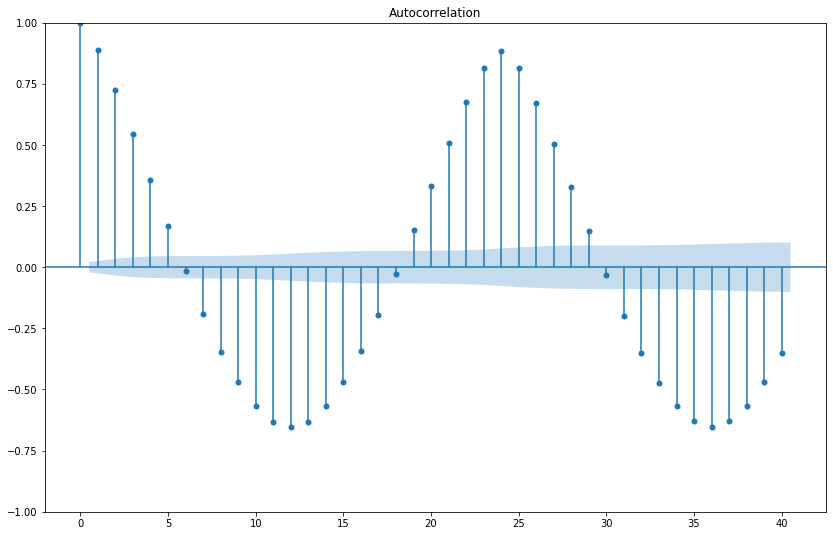

Autocorrelation for Furnace=  0.7848839683311482


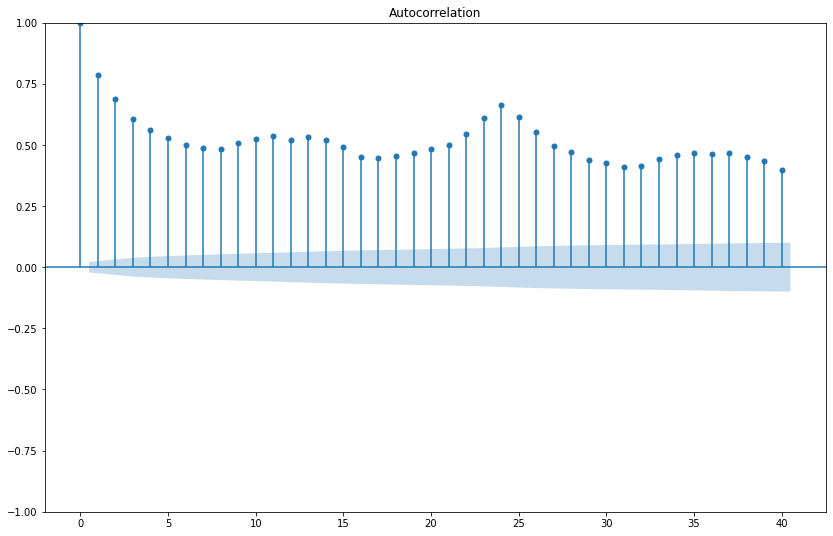

Autocorrelation for Kitchen=  0.18894085220585222


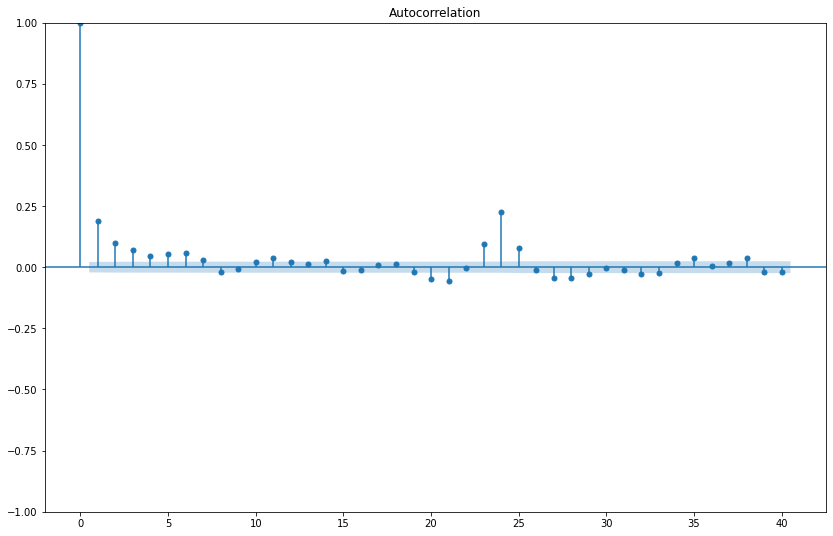

Autocorrelation for temperature=  0.9942025937175333


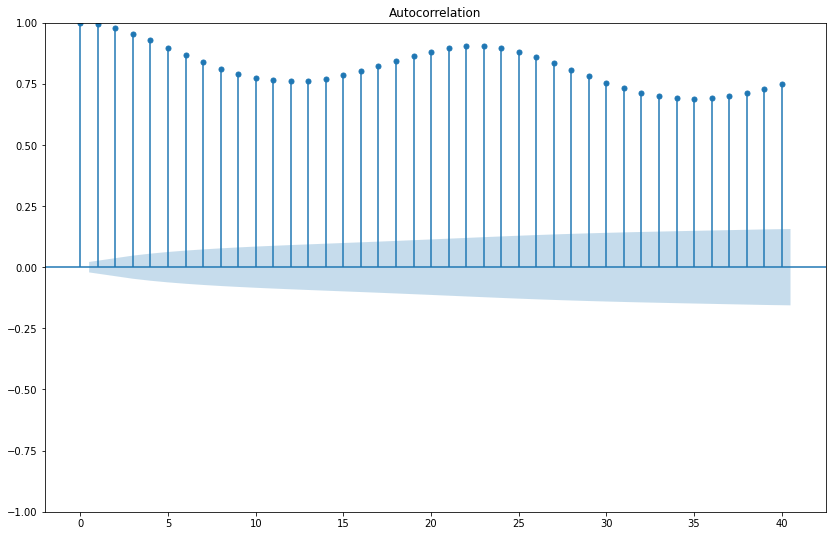

Autocorrelation for humidity=  0.9712519461313207


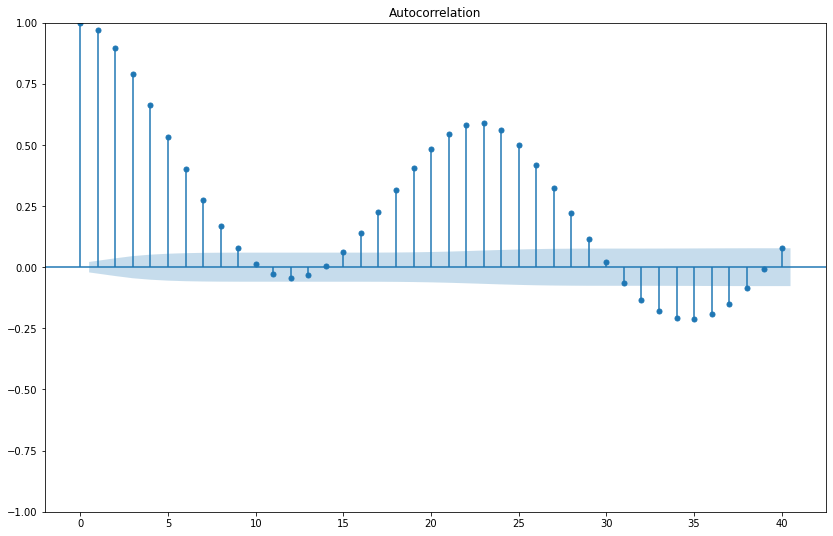

Autocorrelation for pressure=  0.9970334039507314


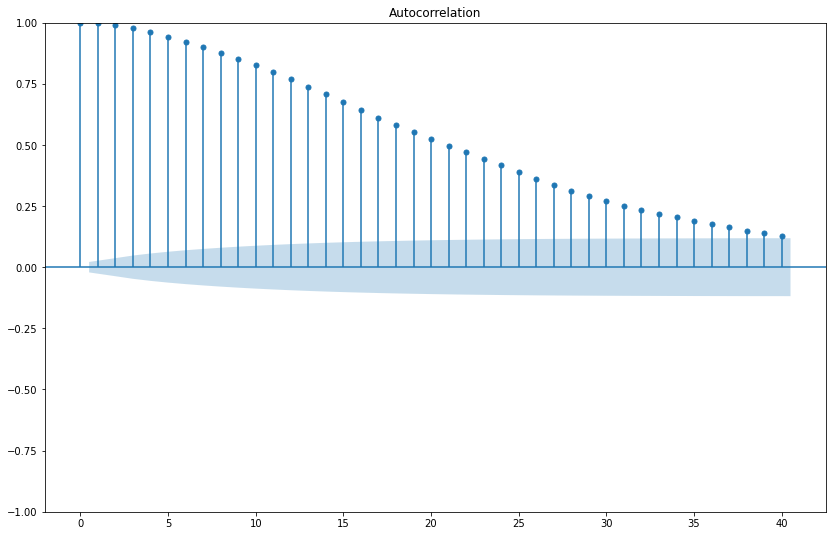

Autocorrelation for windSpeed=  0.9262153453865151


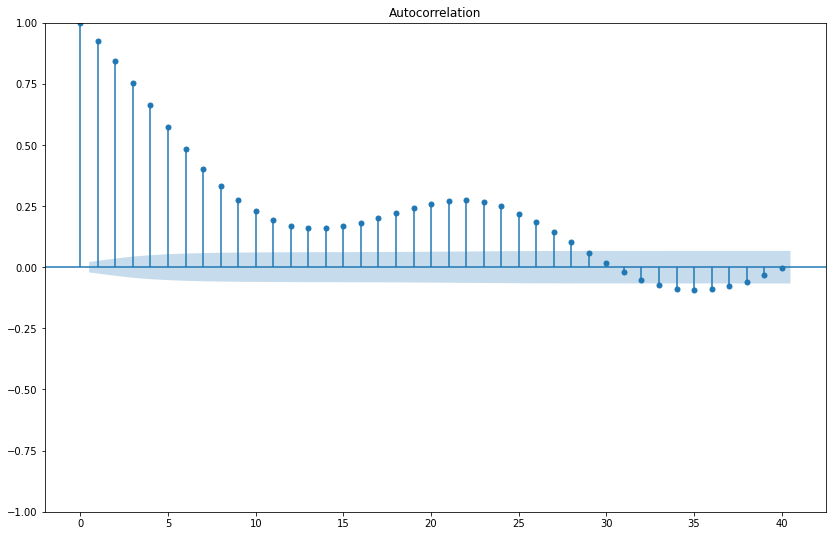

Autocorrelation for dewPoint=  0.997429850755743


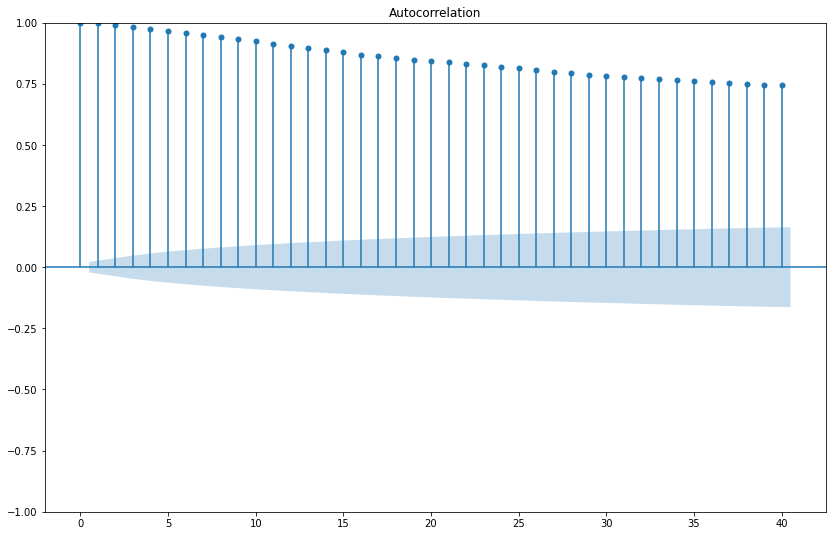

In [302]:
for i in df1.columns:
  print("Autocorrelation for {}= ".format(i),df1[i].autocorr())
  array = np.array(df1[i]).reshape(-1,1)
  fig= plot_acf(df1[i], lags=40)
  plt.show()

In [303]:
#Trained on the the parameter values p=5, d=1 and q=0
from statsmodels.tsa.arima_model import ARIMA
from sklearn.metrics import mean_squared_error
import time



In [305]:
for i in df1.columns:
  array = np.array(df1[i]).reshape(-1,1)
  size = int(len(array) * 0.70)
  train, test = array[0:size], array[size:len(array)]
  history = train
  predictions = list()
  start_time= time.time()
  for t in range(len(test)):
        
    model = ARIMA(history, order=(5,1,0))
    model_fit = model.fit()
    output = model_fit.forecast()
    yhat = output[0]
    predictions.append(yhat)
    obs = test[t]
    history.append(obs)
    print('predicted=%f, expected=%f' % (yhat, obs))

  error = mean_squared_error(test, predictions)
  end_time= time.time()
  time_taken= end_time-start_time
  print('Time taken to train the model in seconds= ',time_taken)
  print('Test MSE: %.3f' % error)
  # plot
  plt.plot(test)
  plt.plot(predictions, color='red')
  plt.show()

NotImplementedError: ignored

In [ ]:
history.dtypes

In [ ]:
home_arima_df=df1[0:50]

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
import time
for i in home_arima_df.columns:
    array= np.array( home_arima_df[i]).reshape(-1,1)
    size = int(len(array) * 0.70)
    train, test = array[0:size], array[size:len(array)]
    history = [x for x in train]
    predictions = list()
    start_time= time.time()
    for t in range(len(test)):
        model = ARIMA(history, order=(5,1,0))
        model_fit = model.fit()
        output = model_fit.forecast()
        yhat = output[0]
        predictions.append(yhat)
        obs = test[t]
        history.append(obs)
        print('predicted=%f, expected=%f' % (yhat, obs))
    error = mean_squared_error(test, predictions)
    end_time= time.time()
    time_taken= end_time-start_time
    print('Time taken to train the model in seconds= ',time_taken,'-{}'.format(i))
    print('Test MSE: %.3f' % error)
# plot
    plt.plot(test)
    plt.plot(predictions, color='red')
    plt.show()

predicted=3.915961, expected=4.192945
predicted=4.168311, expected=3.801046
predicted=3.841182, expected=2.626868
predicted=2.803073, expected=3.083622
predicted=2.998983, expected=2.990454
predicted=3.063916, expected=2.754014
predicted=3.016729, expected=3.474587
predicted=3.450643, expected=3.788510
predicted=3.663463, expected=3.019203
predicted=3.165306, expected=3.315192
predicted=3.201171, expected=4.603215
predicted=4.237725, expected=5.409763
predicted=5.273587, expected=5.346556
predicted=5.330849, expected=4.357864
predicted=4.258503, expected=4.121827
predicted=3.910367, expected=3.593066
predicted=3.640837, expected=3.451812
predicted=3.672156, expected=3.514256
predicted=3.707907, expected=3.651852
predicted=3.745749, expected=3.648386
predicted=3.735059, expected=3.755387
predicted=3.740503, expected=3.783761
predicted=3.744527, expected=4.230741
predicted=4.128205, expected=3.705302
predicted=3.760331, expected=3.639707
predicted=3.634106, expected=3.976257
predicted=3.

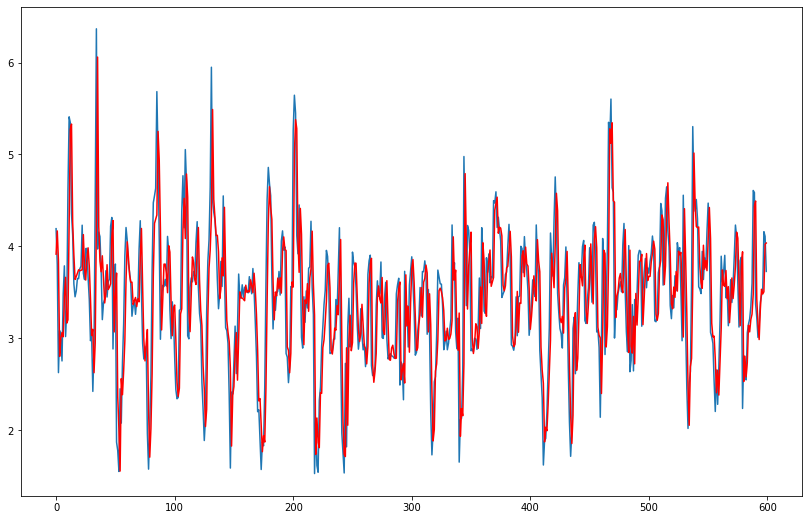

predicted=0.269161, expected=0.190533
predicted=0.146869, expected=0.181544
predicted=0.184287, expected=0.108687
predicted=0.119680, expected=0.221611
predicted=0.240029, expected=0.154442
predicted=0.134900, expected=0.135429
predicted=0.148228, expected=3.062703
predicted=3.078171, expected=3.348219
predicted=2.082982, expected=1.869992
predicted=1.060422, expected=0.208006
predicted=0.396218, expected=0.089516
predicted=0.586988, expected=0.097743
predicted=0.695485, expected=0.090205
predicted=0.607629, expected=0.109616
predicted=0.433715, expected=0.094742
predicted=0.108960, expected=0.061605
predicted=0.062701, expected=0.060102
predicted=0.076762, expected=0.080265
predicted=0.087272, expected=0.105790
predicted=0.104568, expected=0.104781
predicted=0.095278, expected=0.111877
predicted=0.103850, expected=0.114908
predicted=0.105116, expected=0.159175
predicted=0.151678, expected=0.128399
predicted=0.107923, expected=0.094783
predicted=0.095548, expected=0.097150
predicted=0.

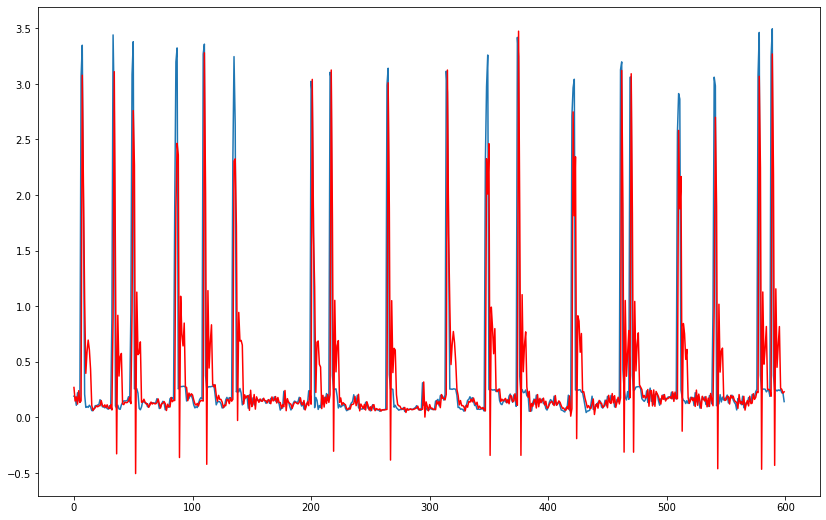

predicted=1.582841, expected=1.572885
predicted=1.579530, expected=1.572032
predicted=1.576626, expected=1.566530
predicted=1.569582, expected=1.573642
predicted=1.577459, expected=1.571724
predicted=1.569560, expected=1.572424
predicted=1.573127, expected=1.573568
predicted=1.573118, expected=1.574304
predicted=1.573508, expected=1.569464
predicted=1.568831, expected=1.578813
predicted=1.581042, expected=1.607555
predicted=1.605499, expected=1.609254
predicted=1.596742, expected=1.609120
predicted=1.604308, expected=3.366323
predicted=3.451111, expected=3.805844
predicted=3.091678, expected=1.608747
predicted=1.107284, expected=1.609322
predicted=2.280198, expected=1.606606
predicted=1.686737, expected=1.605688
predicted=1.836271, expected=1.604369
predicted=1.758186, expected=1.603839
predicted=1.604753, expected=1.601343
predicted=1.601891, expected=1.573033
predicted=1.572969, expected=1.567695
predicted=1.579765, expected=1.572991
predicted=1.579093, expected=1.570016
predicted=1.

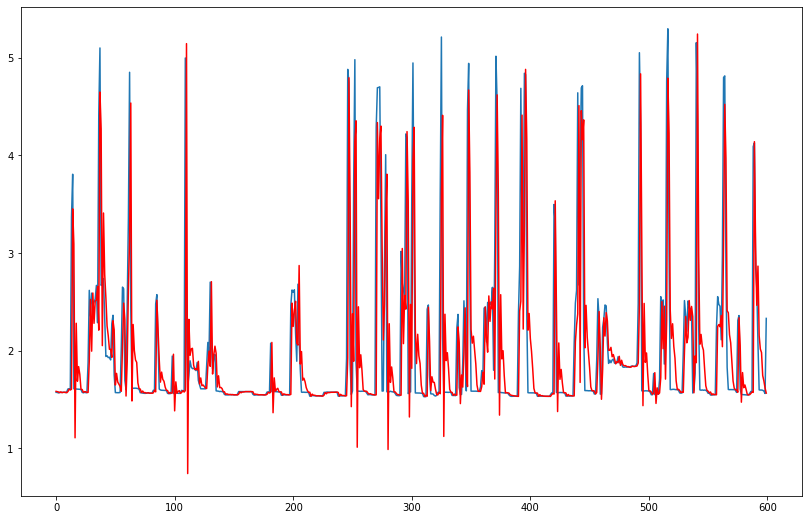

predicted=0.815998, expected=0.630572
predicted=0.804028, expected=0.835753
predicted=0.812267, expected=0.671753
predicted=0.857316, expected=0.692846
predicted=0.717991, expected=0.714216
predicted=0.706005, expected=0.710412
predicted=0.710986, expected=0.671347
predicted=0.721351, expected=0.713206
predicted=0.686927, expected=0.769993
predicted=0.699912, expected=0.838051
predicted=0.727922, expected=0.715961
predicted=0.770211, expected=0.632220
predicted=0.744204, expected=0.658687
predicted=0.705396, expected=0.646018
predicted=0.701510, expected=0.715751
predicted=0.681173, expected=0.648903
predicted=0.683685, expected=0.684089
predicted=0.660904, expected=0.666318
predicted=0.672068, expected=0.852647
predicted=0.667457, expected=0.821437
predicted=0.745455, expected=0.685893
predicted=0.769366, expected=0.688062
predicted=0.731813, expected=0.776047
predicted=0.722693, expected=0.928710
predicted=0.759302, expected=0.651224
predicted=0.824410, expected=0.650940
predicted=0.

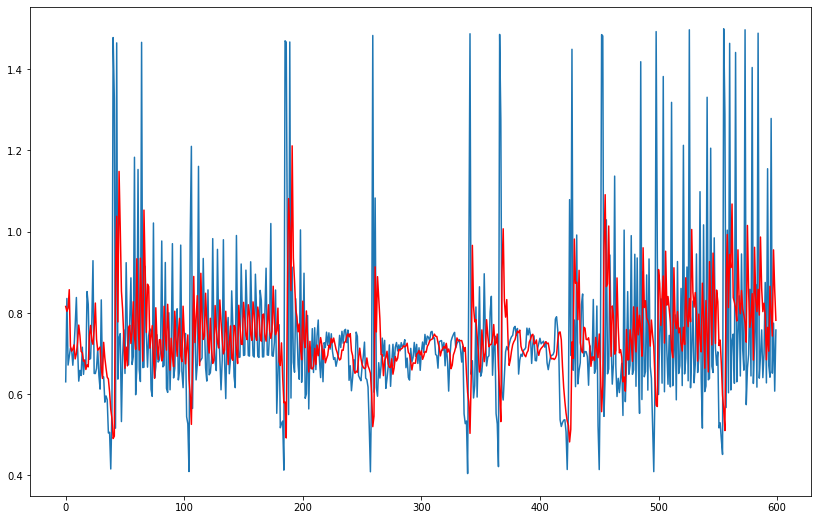

predicted=1.364600, expected=1.355142
predicted=1.346636, expected=1.365799
predicted=1.365356, expected=1.359137
predicted=1.353995, expected=1.171139
predicted=1.165443, expected=0.516506
predicted=0.586097, expected=0.742091
predicted=1.077299, expected=1.368205
predicted=1.439861, expected=1.373107
predicted=1.155758, expected=1.355385
predicted=1.299529, expected=1.351045
predicted=1.244571, expected=1.363468
predicted=1.270382, expected=0.611186
predicted=0.591310, expected=0.569688
predicted=0.907415, expected=1.351804
predicted=1.542118, expected=1.354337
predicted=1.100362, expected=1.351712
predicted=1.317734, expected=1.351526
predicted=1.259742, expected=1.350176
predicted=1.223280, expected=1.347858
predicted=1.348379, expected=1.348720
predicted=1.350507, expected=1.350878
predicted=1.351207, expected=1.350490
predicted=1.349841, expected=1.335827
predicted=1.335520, expected=0.972402
predicted=0.971052, expected=0.514342
predicted=0.670420, expected=0.894985
predicted=1.

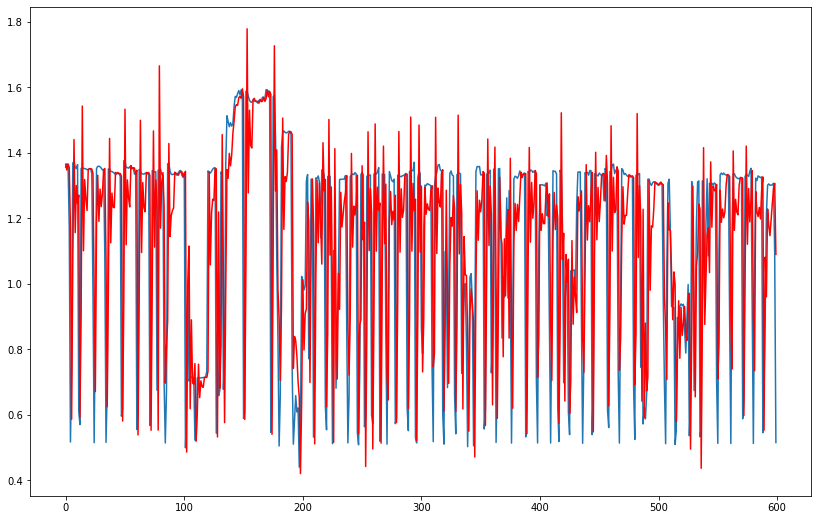

predicted=0.934683, expected=0.911472
predicted=0.942739, expected=0.909555
predicted=0.937251, expected=1.015454
predicted=0.959074, expected=0.907927
predicted=0.954081, expected=0.915573
predicted=0.927749, expected=1.023632
predicted=0.954712, expected=0.907266
predicted=0.936619, expected=0.901910
predicted=0.947405, expected=0.913420
predicted=0.926959, expected=0.914889
predicted=0.925319, expected=1.068685
predicted=0.970261, expected=0.905366
predicted=0.927253, expected=0.907098
predicted=0.935012, expected=0.910568
predicted=0.934293, expected=0.910669
predicted=0.930912, expected=0.910736
predicted=0.939130, expected=0.913214
predicted=0.909827, expected=0.910588
predicted=0.910278, expected=0.912180
predicted=0.911448, expected=0.911712
predicted=0.911482, expected=0.909784
predicted=0.911161, expected=0.909112
predicted=0.911049, expected=0.915891
predicted=0.911965, expected=0.910555
predicted=0.911280, expected=0.904362
predicted=0.909820, expected=0.905495
predicted=0.

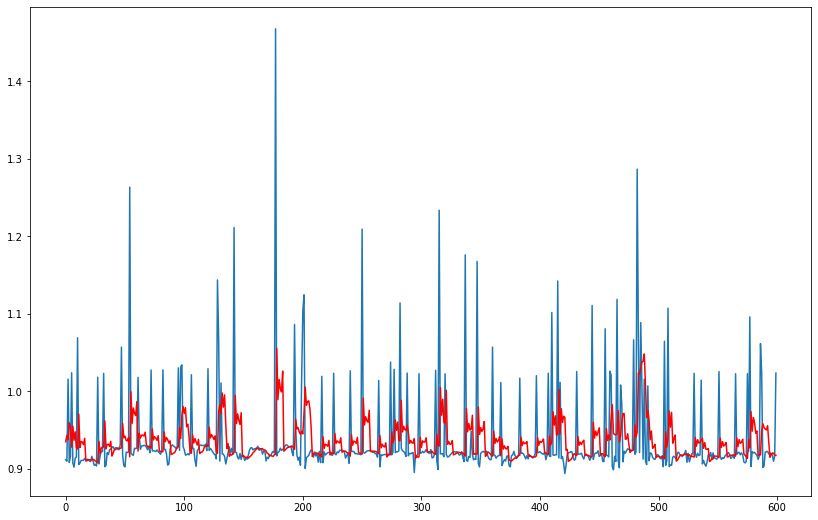

predicted=1.928198, expected=1.868467
predicted=1.905466, expected=1.853283
predicted=1.891019, expected=1.848767
predicted=1.868766, expected=1.847783
predicted=1.855091, expected=1.840800
predicted=1.844855, expected=1.846667
predicted=1.849023, expected=1.846150
predicted=1.846140, expected=1.832083
predicted=1.833407, expected=1.837250
predicted=1.839749, expected=1.902900
predicted=1.897567, expected=2.674367
predicted=2.592050, expected=2.277617
predicted=2.132549, expected=3.015667
predicted=2.928782, expected=2.299233
predicted=2.171553, expected=2.174467
predicted=2.248270, expected=2.137817
predicted=2.210378, expected=2.155600
predicted=2.214018, expected=1.978117
predicted=2.042231, expected=1.973133
predicted=2.020442, expected=1.989017
predicted=2.012415, expected=2.434517
predicted=2.408896, expected=2.277133
predicted=2.199020, expected=2.282517
predicted=2.256292, expected=1.871550
predicted=1.882729, expected=1.849833
predicted=1.936370, expected=1.857550
predicted=1.

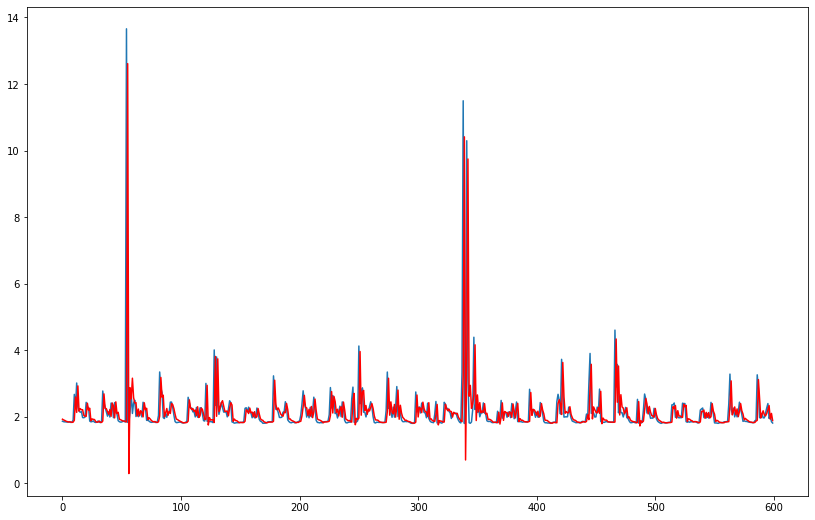

predicted=0.642534, expected=1.726527
predicted=0.920386, expected=1.443514
predicted=1.096808, expected=0.391414
predicted=1.023681, expected=0.385636
predicted=0.826083, expected=0.391015
predicted=0.683891, expected=0.392967
predicted=0.641264, expected=0.555104
predicted=0.522398, expected=1.287748
predicted=0.657308, expected=0.386865
predicted=0.630844, expected=1.731804
predicted=0.910314, expected=1.839872
predicted=1.198983, expected=0.404464
predicted=1.111436, expected=0.399826
predicted=0.890508, expected=1.450904
predicted=0.999470, expected=0.396744
predicted=0.945615, expected=0.386939
predicted=0.719982, expected=0.391378
predicted=0.514231, expected=0.391342
predicted=0.524175, expected=0.389226
predicted=0.484042, expected=0.387310
predicted=0.389750, expected=0.393865
predicted=0.390268, expected=0.393039
predicted=0.391376, expected=1.342994
predicted=0.633795, expected=0.392283
predicted=0.613903, expected=0.391015
predicted=0.568825, expected=1.801206
predicted=0.

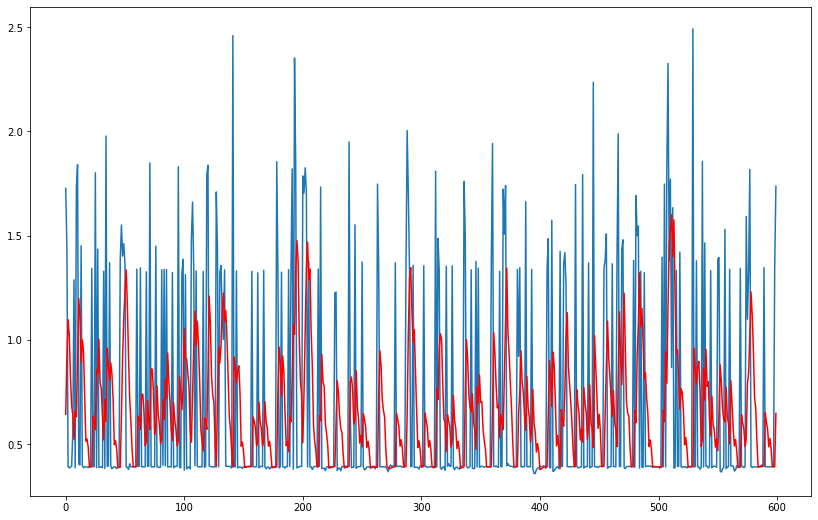

predicted=0.681537, expected=0.629638
predicted=0.672553, expected=1.268054
predicted=0.861894, expected=0.625278
predicted=0.769925, expected=0.622753
predicted=0.776050, expected=0.621504
predicted=0.736573, expected=1.782596
predicted=1.003475, expected=0.919617
predicted=0.976802, expected=0.621562
predicted=0.801380, expected=0.621820
predicted=0.868853, expected=0.628839
predicted=0.828497, expected=0.647141
predicted=0.874567, expected=0.646224
predicted=0.684892, expected=0.638346
predicted=0.633679, expected=0.628993
predicted=0.634329, expected=0.635910
predicted=0.637300, expected=0.626682
predicted=0.636465, expected=0.621777
predicted=0.631869, expected=0.621490
predicted=0.628685, expected=0.621360
predicted=0.625605, expected=0.627445
predicted=0.626262, expected=0.626314
predicted=0.624495, expected=0.627078
predicted=0.624328, expected=0.625633
predicted=0.624963, expected=0.626866
predicted=0.625724, expected=0.626625
predicted=0.626728, expected=0.627148
predicted=0.

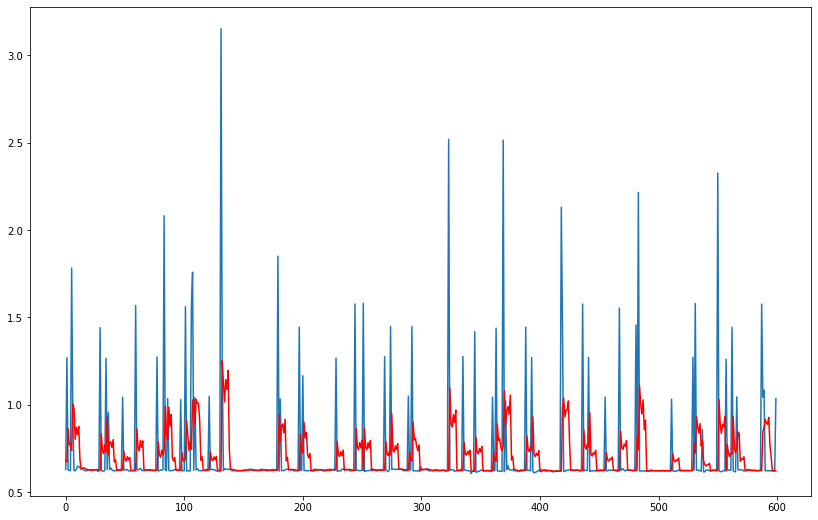

predicted=1.329420, expected=2.725322
predicted=2.033231, expected=2.714711
predicted=1.977282, expected=0.703172
predicted=0.680940, expected=0.435153
predicted=1.005314, expected=0.444177
predicted=0.980488, expected=0.445861
predicted=0.815968, expected=0.448527
predicted=0.671828, expected=0.447531
predicted=0.469655, expected=0.441771
predicted=0.441639, expected=0.914352
predicted=0.811893, expected=2.544214
predicted=2.005116, expected=2.720788
predicted=1.929956, expected=2.597580
predicted=2.059164, expected=0.471944
predicted=0.649411, expected=0.453876
predicted=1.132418, expected=0.438790
predicted=1.020514, expected=0.458468
predicted=0.791969, expected=0.458521
predicted=0.656380, expected=0.452334
predicted=0.452327, expected=0.453120
predicted=0.453807, expected=0.456743
predicted=0.455467, expected=0.455140
predicted=0.454798, expected=0.451599
predicted=0.452476, expected=0.447309
predicted=0.449411, expected=1.567651
predicted=1.327711, expected=2.003115
predicted=1.

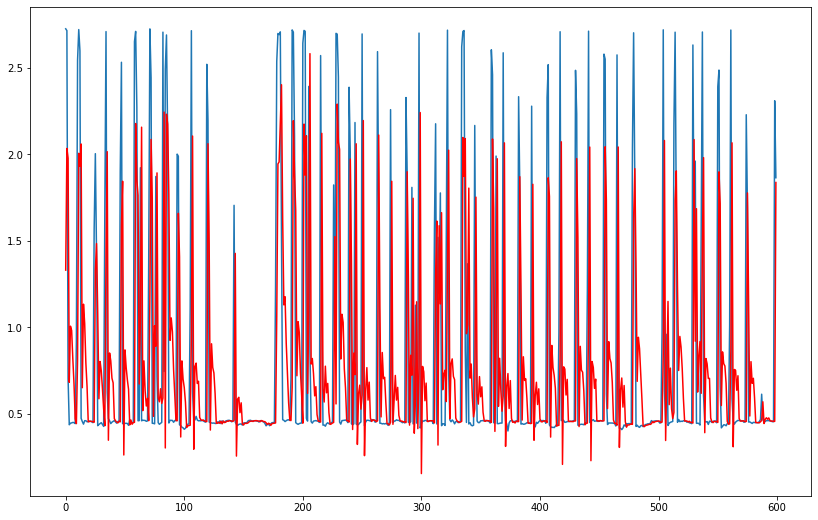

predicted=1.041769, expected=0.693291
predicted=0.597252, expected=0.434001
predicted=0.375718, expected=0.351848
predicted=0.339639, expected=0.391181
predicted=0.426997, expected=0.465259
predicted=0.499106, expected=0.371434
predicted=0.350675, expected=0.374744
predicted=0.385198, expected=0.477297
predicted=0.499435, expected=0.662173
predicted=0.705444, expected=1.229099
predicted=1.375785, expected=1.821442
predicted=1.949924, expected=1.814885
predicted=1.785705, expected=1.732001
predicted=1.711687, expected=1.687676
predicted=1.654606, expected=1.727921
predicted=1.724741, expected=1.727475
predicted=1.725228, expected=1.747213
predicted=1.756750, expected=1.752840
predicted=1.753367, expected=1.746127
predicted=1.743542, expected=1.692298
predicted=1.677880, expected=1.695362
predicted=1.698890, expected=1.699791
predicted=1.699178, expected=1.755470
predicted=1.771658, expected=0.934887
predicted=0.709878, expected=0.525406
predicted=0.468728, expected=0.507358
predicted=0.

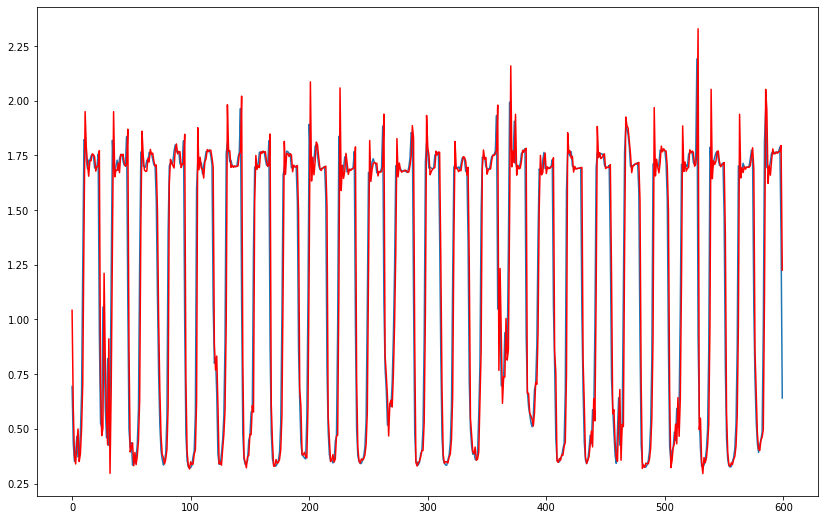

predicted=33.775988, expected=24.965217
predicted=29.193974, expected=18.963100
predicted=24.110411, expected=10.452267
predicted=18.343496, expected=25.819217
predicted=23.490583, expected=12.309317
predicted=19.126026, expected=11.398367
predicted=14.239328, expected=9.603600
predicted=12.192528, expected=7.862117
predicted=10.476587, expected=7.222333
predicted=10.047126, expected=10.342767
predicted=9.826521, expected=9.221283
predicted=9.512567, expected=18.617250
predicted=13.728696, expected=13.357917
predicted=12.950064, expected=16.067183
predicted=13.810544, expected=9.419167
predicted=11.648300, expected=9.410833
predicted=10.761064, expected=9.450483
predicted=11.135172, expected=11.722850
predicted=11.530504, expected=17.431983
predicted=14.534477, expected=18.084450
predicted=15.461106, expected=19.041050
predicted=16.497981, expected=21.469150
predicted=18.505455, expected=37.532617
predicted=27.792076, expected=21.753750
predicted=24.028176, expected=9.418633
predicted=

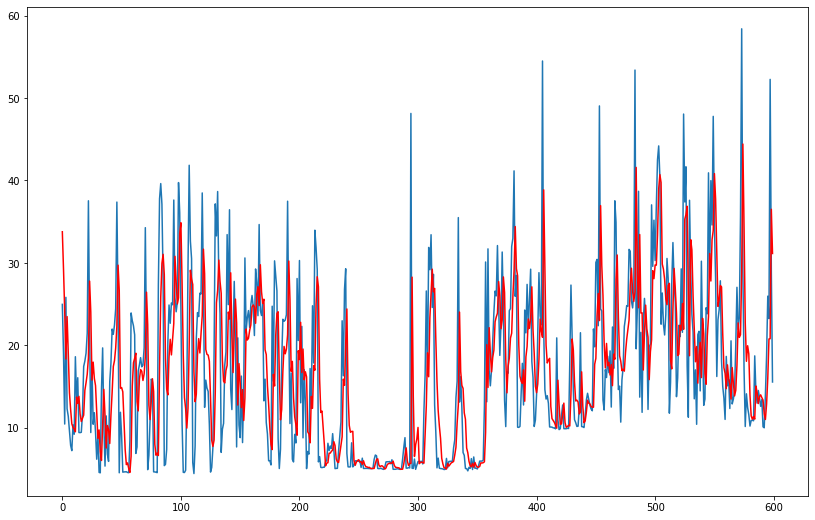

predicted=0.592944, expected=0.622925
predicted=0.548856, expected=1.386440
predicted=0.790423, expected=0.991794
predicted=0.828119, expected=0.369385
predicted=0.781949, expected=0.354591
predicted=0.830773, expected=1.357191
predicted=0.894020, expected=0.395116
predicted=0.783591, expected=0.411475
predicted=0.649123, expected=0.357830
predicted=0.518846, expected=0.347237
predicted=0.514789, expected=0.349525
predicted=0.557991, expected=0.331818
predicted=0.363845, expected=0.347697
predicted=0.359479, expected=1.848373
predicted=0.707892, expected=0.372334
predicted=0.540825, expected=0.333972
predicted=0.573500, expected=0.341569
predicted=0.566378, expected=0.338688
predicted=0.567199, expected=0.351155
predicted=0.634805, expected=0.351514
predicted=0.349447, expected=0.337910
predicted=0.341534, expected=0.336741
predicted=0.342441, expected=0.344403
predicted=0.343402, expected=0.357744
predicted=0.347809, expected=1.543208
predicted=0.632750, expected=0.340518
predicted=0.

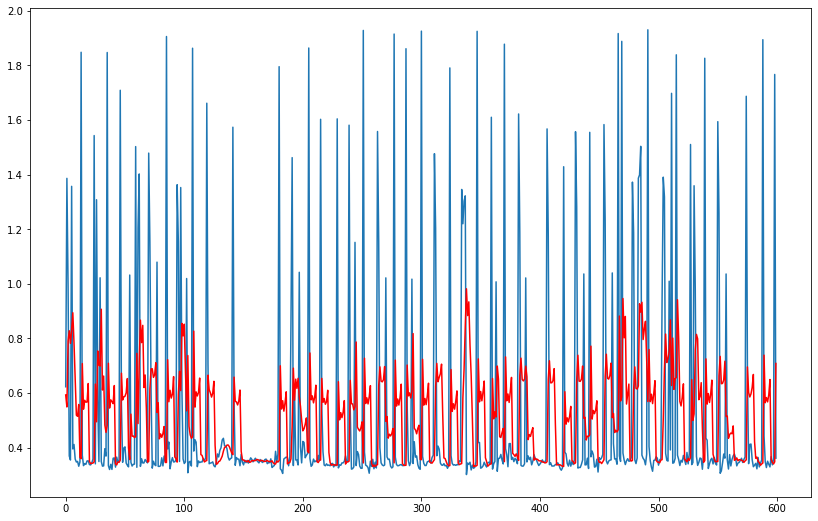

predicted=26.254321, expected=27.444000
predicted=29.516983, expected=28.893333
predicted=30.183614, expected=30.465000
predicted=31.889040, expected=32.674000
predicted=34.725270, expected=35.260667
predicted=37.327080, expected=37.349333
predicted=38.716989, expected=39.535000
predicted=41.196627, expected=41.480667
predicted=42.806878, expected=42.243000
predicted=42.259385, expected=40.238000
predicted=37.587932, expected=36.965667
predicted=33.842851, expected=35.620000
predicted=35.134319, expected=37.001000
predicted=38.927964, expected=38.358667
predicted=39.445901, expected=38.474333
predicted=38.332868, expected=37.678000
predicted=36.907796, expected=37.940000
predicted=38.465054, expected=38.515333
predicted=38.964103, expected=39.283000
predicted=39.888747, expected=40.358667
predicted=41.381411, expected=42.054000
predicted=43.584743, expected=42.683667
predicted=42.761870, expected=43.359333
predicted=43.860481, expected=42.882000
predicted=42.083225, expected=39.580667


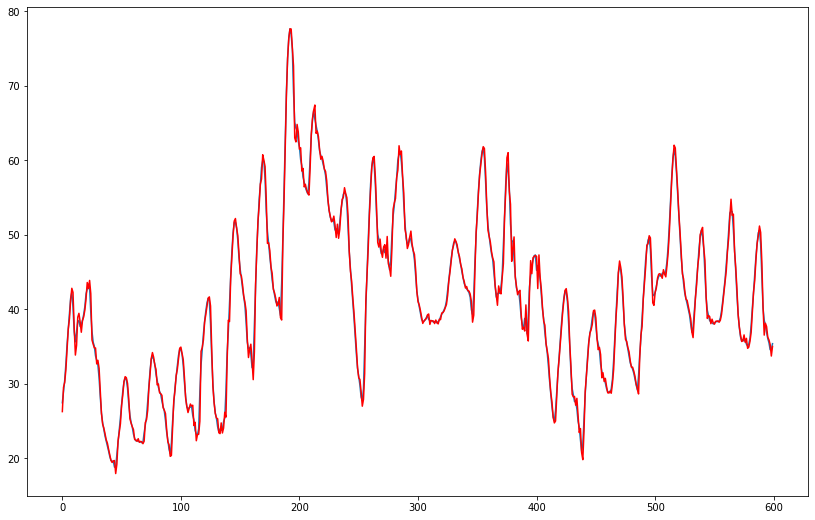

predicted=0.396148, expected=0.371000
predicted=0.340778, expected=0.343333
predicted=0.328618, expected=0.315333
predicted=0.296743, expected=0.282000
predicted=0.258609, expected=0.261333
predicted=0.252162, expected=0.231333
predicted=0.209778, expected=0.205000
predicted=0.189003, expected=0.200000
predicted=0.203876, expected=0.205667
predicted=0.213995, expected=0.246000
predicted=0.284821, expected=0.333333
predicted=0.408252, expected=0.396667
predicted=0.435217, expected=0.438000
predicted=0.459595, expected=0.508667
predicted=0.562524, expected=0.622000
predicted=0.708522, expected=0.778000
predicted=0.896481, expected=0.851667
predicted=0.879329, expected=0.877333
predicted=0.877040, expected=0.916000
predicted=0.940227, expected=0.920000
predicted=0.906588, expected=0.910333
predicted=0.896166, expected=0.919333
predicted=0.929015, expected=0.898000
predicted=0.873720, expected=0.860000
predicted=0.828616, expected=0.762000
predicted=0.677682, expected=0.696667
predicted=0.

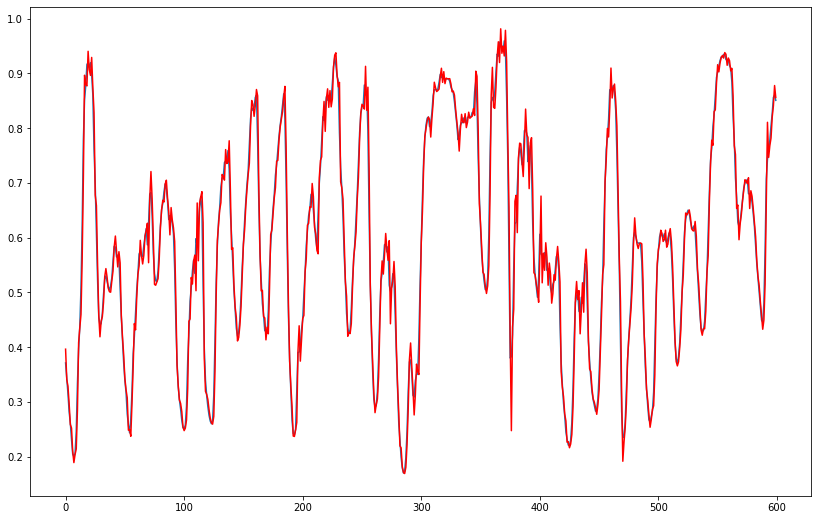

predicted=1021.089740, expected=1021.736000
predicted=1022.958034, expected=1022.600000
predicted=1023.204182, expected=1022.944667
predicted=1023.217700, expected=1022.300000
predicted=1021.430442, expected=1020.947333
predicted=1019.617487, expected=1019.830667
predicted=1018.887591, expected=1018.965000
predicted=1018.264601, expected=1018.072667
predicted=1017.361586, expected=1017.148000
predicted=1016.349512, expected=1016.182000
predicted=1015.312429, expected=1015.609333
predicted=1015.214636, expected=1014.690000
predicted=1013.780932, expected=1013.397000
predicted=1012.244904, expected=1012.115333
predicted=1010.955277, expected=1010.011333
predicted=1007.954897, expected=1007.702000
predicted=1005.714045, expected=1005.426667
predicted=1003.368846, expected=1003.049333
predicted=1000.991066, expected=1000.535000
predicted=998.329479, expected=998.012667
predicted=995.797610, expected=996.728667
predicted=995.921254, expected=996.090000
predicted=995.645417, expected=996.995

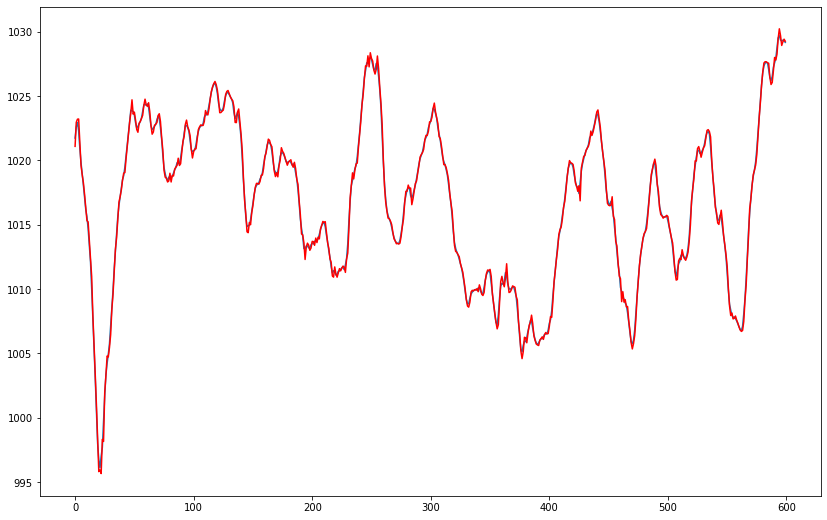

predicted=3.064205, expected=2.952118
predicted=2.934567, expected=2.768273
predicted=2.758878, expected=2.428580
predicted=2.401000, expected=1.839021
predicted=1.786715, expected=1.496106
predicted=1.458815, expected=2.118175
predicted=2.169844, expected=2.201136
predicted=2.218687, expected=2.134947
predicted=2.126835, expected=2.278889
predicted=2.309526, expected=2.392906
predicted=2.392803, expected=2.701913
predicted=2.723914, expected=2.891366
predicted=2.915008, expected=2.759710
predicted=2.746593, expected=2.820284
predicted=2.824610, expected=2.630969
predicted=2.615616, expected=2.349894
predicted=2.315693, expected=2.072438
predicted=2.051630, expected=1.824463
predicted=1.797658, expected=1.546286
predicted=1.520580, expected=1.600417
predicted=1.604214, expected=2.614065
predicted=2.707972, expected=1.981245
predicted=1.946062, expected=2.584183
predicted=2.609497, expected=2.687006
predicted=2.732885, expected=3.784970
predicted=3.815828, expected=4.346838
predicted=4.

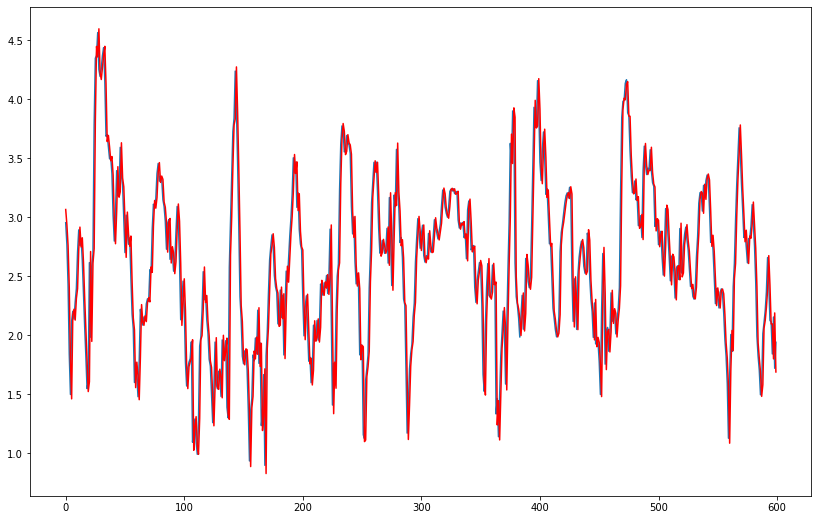

predicted=3854.808284, expected=391.434512
predicted=2855.857523, expected=284.418481
predicted=1379.629039, expected=181.477184
predicted=319.986594, expected=112.668969
predicted=124.600347, expected=228.118334
predicted=342.488147, expected=56.364058
predicted=-103.839791, expected=29.220782
predicted=49.874750, expected=150.864435
predicted=245.708124, expected=471.702224
predicted=698.984450, expected=2243.151845
predicted=3617.197484, expected=11846.261793
predicted=19236.054676, expected=32855.674990
predicted=48028.141760, expected=81418.723852
predicted=117070.663362, expected=220296.727315
predicted=323979.190437, expected=511774.521815
predicted=722768.377411, expected=952698.128842
predicted=1261378.222923, expected=1321462.960878
predicted=1554128.031559, expected=1549927.034988
predicted=1690634.199957, expected=1862638.775888
predicted=2088302.648950, expected=2123590.024920
predicted=2276926.896524, expected=2488902.030338
predicted=2743352.450249, expected=2694230.7453

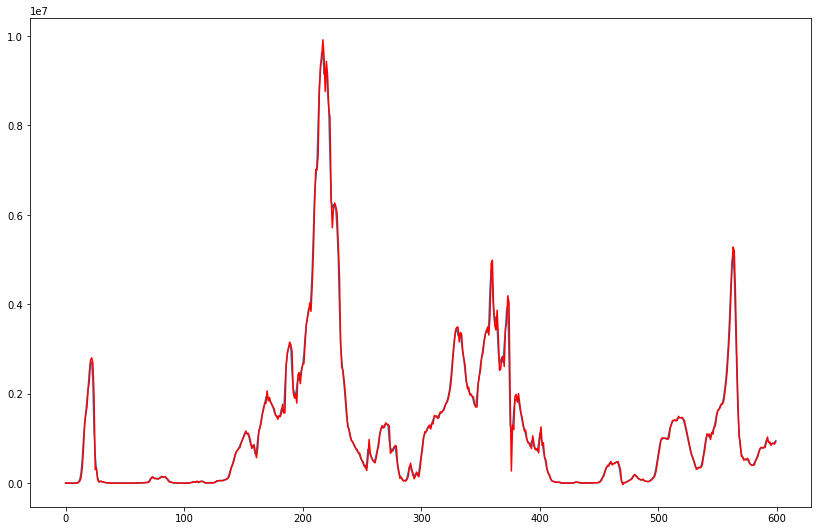

In [306]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
import time
for i in home_arima_df.columns:
    array= np.array( home_arima_df[i]).reshape(-1,1)
    size = int(len(array) * 0.70)
    train, test = array[0:size], array[size:len(array)]
    history = [x for x in train]
    predictions = list()
    start_time= time.time()
    for t in range(len(test)):
        model = ARIMA(history, order=(5,1,0))
        model_fit = model.fit()
        output = model_fit.forecast()
        yhat = output[0]
        predictions.append(yhat)
        obs = test[t]
        history.append(obs)
        print('predicted=%f, expected=%f' % (yhat, obs))
    error = mean_squared_error(test, predictions)
    end_time= time.time()
    time_taken= end_time-start_time
    print('Time taken to train the model in seconds= ',time_taken,'-{}'.format(i))
    print('Test MSE: %.3f' % error)
# plot
    plt.plot(test)
    plt.plot(predictions, color='red')
    plt.show()

# **ThymeBoost**

In [308]:
pip install ThymeBoost

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 KB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 33.1 MB/s eta 0:00:00


In [309]:

from ThymeBoost import ThymeBoost as tb
boosted_model = tb.ThymeBoost(approximate_splits=True,
                              n_split_proposals=25,
                              verbose=1,
                              cost_penalty=.001)


In [310]:
list = df1['House overall'].tolist()
output = boosted_model.fit(list,
                           trend_estimator='linear',
                           seasonal_estimator='fourier',
                           seasonal_period=25,
                           split_cost='mse',
                           global_cost='maicc',
                           fit_type='global')

********** Round 1 **********
Using Split: None
Fitting initial trend globally with trend model:
median()
seasonal model:
fourier(10, False)
cost: -2386.6966785611394
********** Round 2 **********
Using Split: None
Fitting global with trend model:
linear((1, None))
seasonal model:
fourier(10, False)
cost: -2452.235909131136
Boosting Terminated 
Using round 2


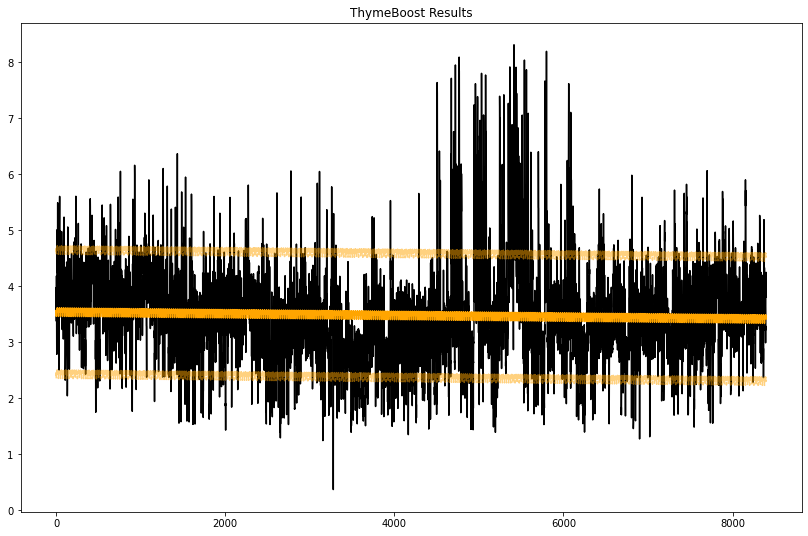

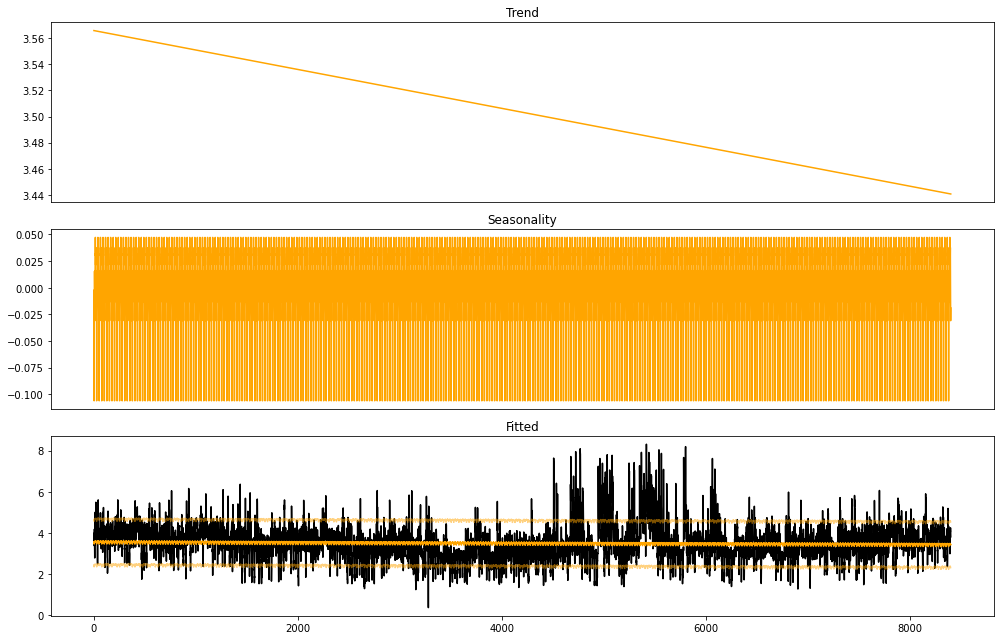

In [311]:
boosted_model.plot_results(output)
boosted_model.plot_components(output)

Detecting Outliers

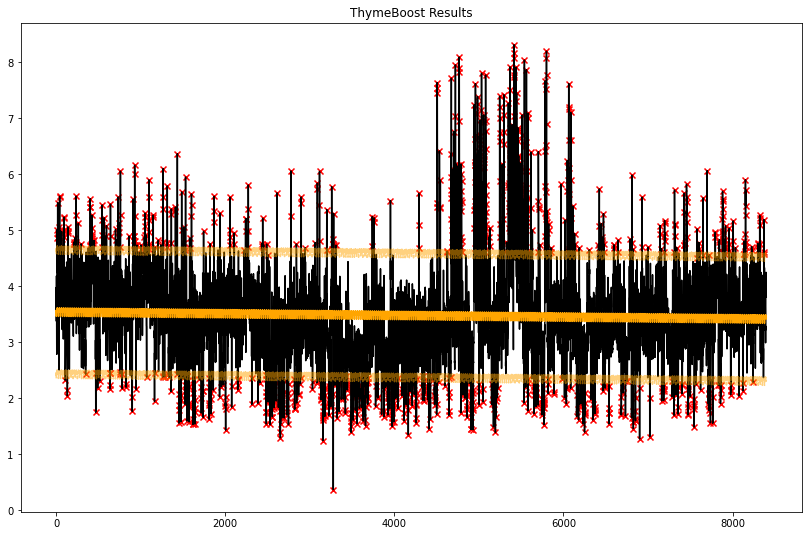

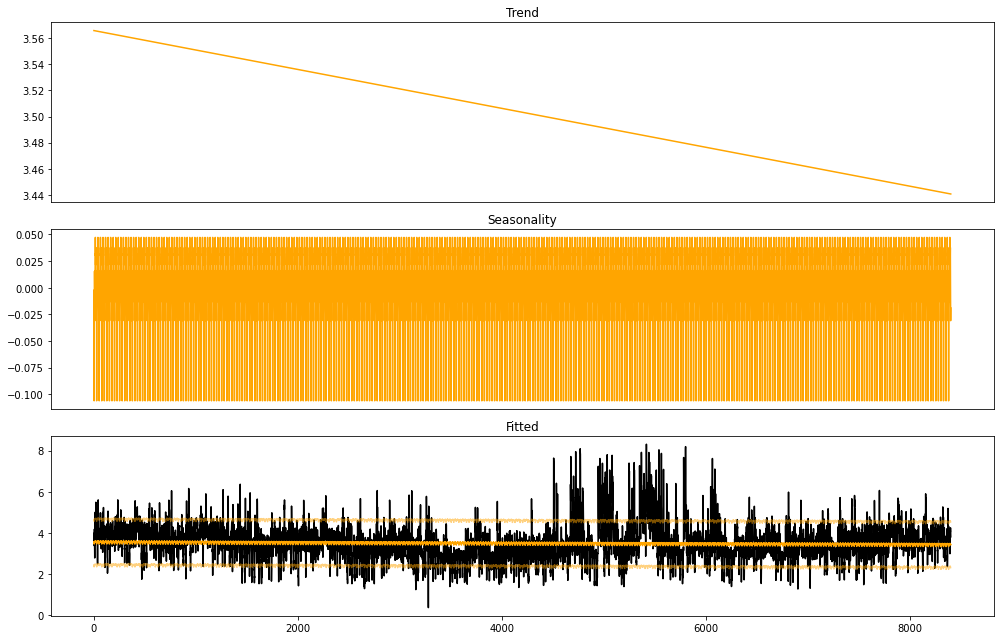

In [312]:
boosted_model = tb.ThymeBoost()
output = boosted_model.detect_outliers(list,
                                       trend_estimator='linear',
                                       seasonal_estimator='fourier',
                                       seasonal_period=25,
                                       global_cost='maicc',
                                       fit_type='global')
boosted_model.plot_results(output)
boosted_model.plot_components(output)



Handling Outliers Using the Outlier Column

In [313]:
weights = np.invert(output['outliers'].values) * 1

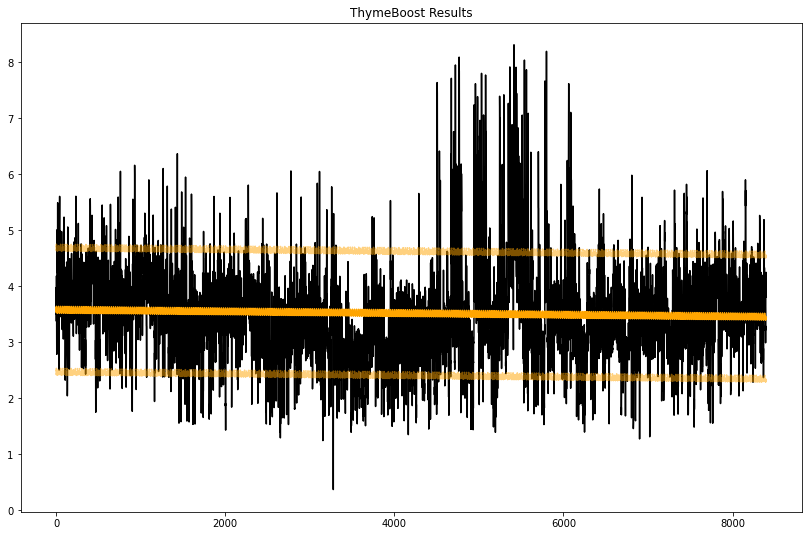

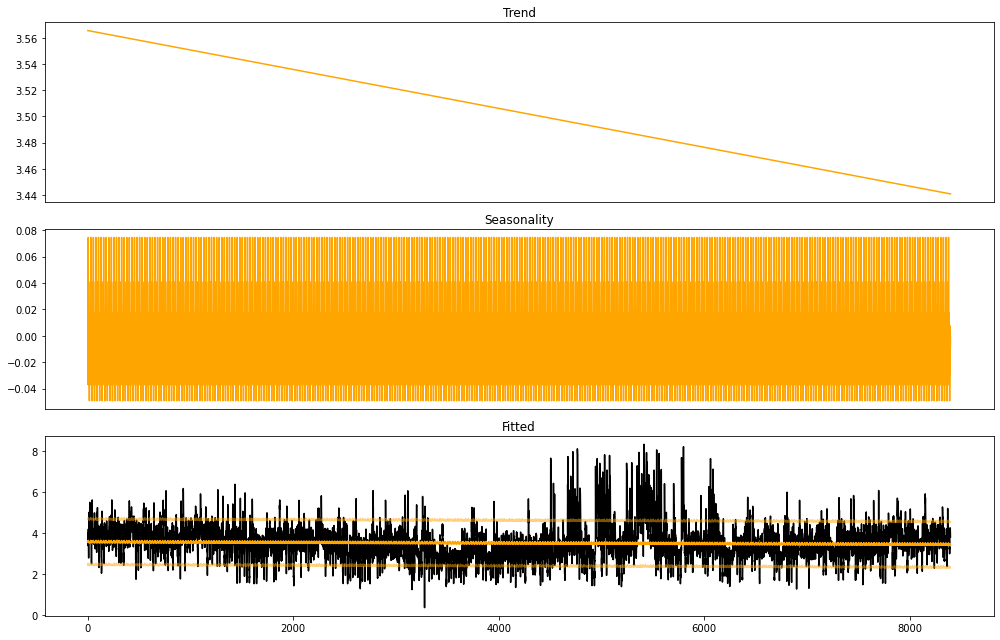

In [314]:
output = boosted_model.fit(list, trend_estimator='linear',
                           seasonal_estimator='fourier',
                           seasonal_period=25,
                           global_cost='maicc',
                           fit_type='global',
                           seasonality_weights=weights)
boosted_model.plot_results(output)
boosted_model.plot_components(output)

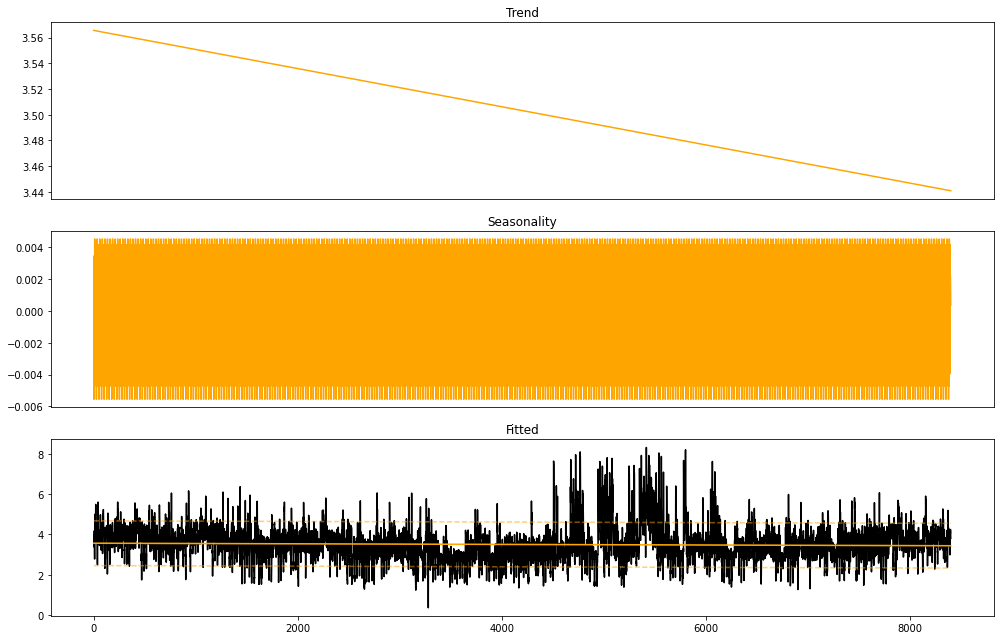

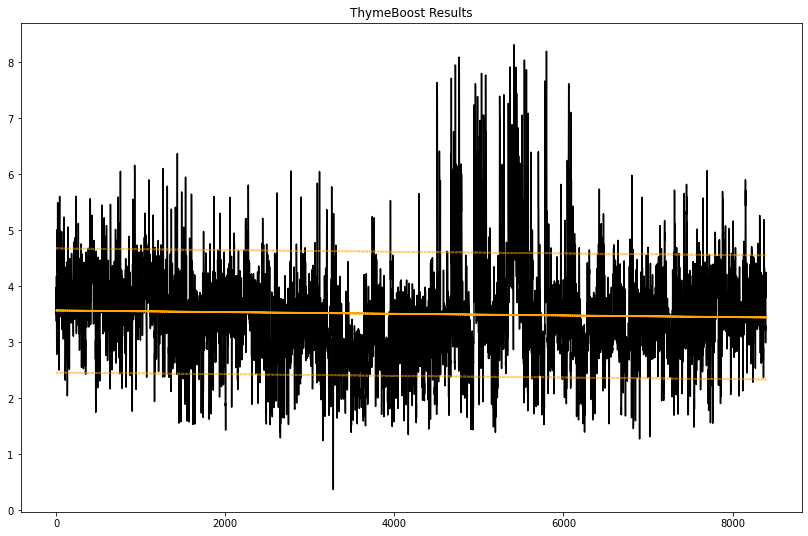

In [315]:
output = boosted_model.fit(list,
                           trend_estimator='linear',
                           seasonal_estimator='fourier',
                           seasonal_period=25,
                           global_cost='maicc',
                           fit_type='global',
                           seasonality_weights='regularize')
boosted_model.plot_components(output)
boosted_model.plot_results(output)

In [316]:
output

,y,yhat,yhat_upper,yhat_lower,seasonality,trend
0,3.971628,3.563793,4.673132,2.454454,-0.001840,3.565633
1,3.805026,3.560072,4.669411,2.450734,-0.005546,3.565618
2,3.500249,3.561220,4.670558,2.451881,-0.004384,3.565603
3,3.861975,3.566649,4.675988,2.457310,0.001061,3.565589
4,3.373443,3.569040,4.678379,2.459702,0.003466,3.565574
...,...,...,...,...,...,...
8394,4.037561,3.443148,4.552487,2.333809,0.002240,3.440908
8395,4.246850,3.442816,4.552154,2.333477,0.001922,3.440893
8396,4.228637,3.442343,4.551682,2.333005,0.001465,3.440879
8397,4.041678,3.441919,4.551258,2.332580,0.001055,3.440864


In [317]:
type(output)

pandas.core.frame.DataFrame

### **Exponential Smoothening**

In [318]:
from statsmodels.tsa.api import ExponentialSmoothing,SimpleExpSmoothing,Holt

In [319]:
from sklearn.model_selection import train_test_split

train,test = train_test_split(dataframe,test_size=0.2,random_state=42)

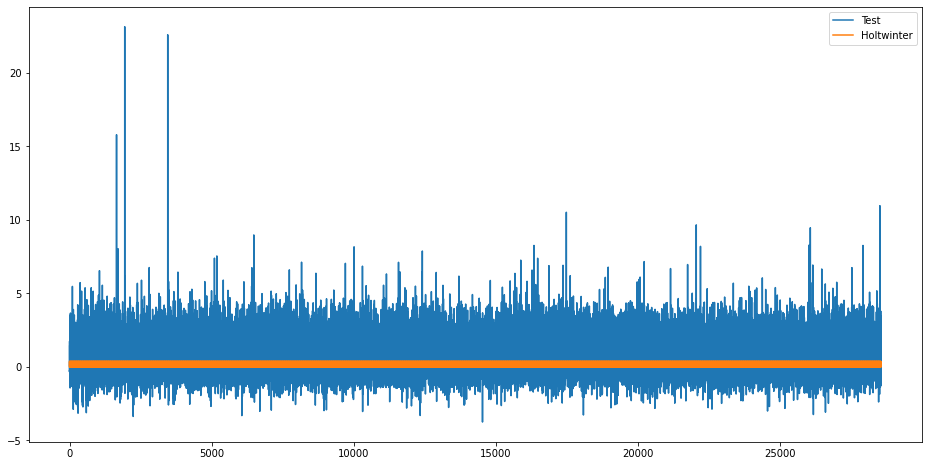

In [320]:

train=np.array(train).reshape(-1,1)
test=np.array(test).reshape(-1,1)

model = ExponentialSmoothing(train,seasonal='add',seasonal_periods=24)
model_fit = model.fit()

# make prediction

y = model_fit.forecast(len(test))
y_predicted=pd.DataFrame(y,columns=['Holtwinter'])

plt.figure(figsize=(16,8))
plt.plot(test, label='Test')
plt.plot(y_predicted, label='Holtwinter')
plt.legend(loc='best')
plt.show()


In [321]:
print('MSE is ', mean_squared_error(test,y_predicted ))
print('R Squared Value :',r2_score(test,y_predicted))

MSE is  1.6959941388792736
R Squared Value : -0.008964702102696842
